# Imports

In [1]:
!pip install irrCAC

In [2]:
import ast
import os
import itertools
import warnings
from collections import Counter
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from matplotlib.font_manager import FontProperties
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import (
    binomtest,
    sem,
    entropy,
    pearsonr,
    spearmanr,
    chi2_contingency,
    friedmanchisquare,
    wilcoxon,
    ttest_rel,
)
from scipy.interpolate import make_interp_spline
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import (
    pairwise_distances,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from irrCAC.datasets import table_cont3x3abstractors
from irrCAC.raw import CAC
from pandas.errors import SettingWithCopyWarning
sns.set_style("white")
warnings.filterwarnings("ignore", category=SettingWithCopyWarning)

In [3]:
pd.set_option("display.max_colwidth", None)

In [5]:
# Repository root
ROOT = Path.cwd().parent
HUMAN_DIR = ROOT / "human" / "data"

# Raw experiment data
RAW_MAIN = ROOT / "data" / "raw" / "main"
RAW_SENSITIVITY = ROOT / "data" / "raw" / "sensitivity"

# Processed analysis data
PROCESSED = ROOT / "data" / "processed"

# Analysis outputs
tables_dir = ROOT / "outputs" / "tables"
figure_output_path = ROOT / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figure_output_path.mkdir(parents=True, exist_ok=True)

# Load & Format Data

In [16]:
ACTION_CANONICAL_MAP = {
    # --- Do nothing ---
    "Do nothing": "Do nothing",

    # --- Gossip ---
    "Gossip": "Gossip",
    "Gossip about / discuss with / complain to others informally": "Gossip",

    # --- Inform authority ---
    "Inform authority": "Inform authority",
    "Inform the authorities, such as the police": "Inform authority",

    # --- Stay away ---
    "Stay away": "Stay away",
    "Stay away or keep a distance from the actor": "Stay away",

    # --- Support ---
    "Support": "Support",
    "Support the actor": "Support",

    # --- Verbal confrontation ---
    "Verbal confrontation": "Verbal confrontation",
    "Verbal reprimand / verbal confrontation": "Verbal confrontation",

    # --- Physical confrontation ---
    "Physical confrontation": "Physical confrontation",

    # --- Praise ---
    "Praise": "Praise",
    "Celebrate / praise": "Praise",
}

In [17]:
df_original = pd.read_csv(HUMAN_DIR / "stimuli.csv")
df_original.columns

Index(['situation-short-id', 'situation', 'rule-of-thumb (rot)',
       'rot-moral-foundations', 'rot-judgement', 'action', 'ID', 'MFT',
       'stimuli-male', 'norm-target in stimuli-male', 'male', 'stimuli-female',
       'norm-target in stimuli-female', 'gender', 'rot-agree', 'action-agree',
       'action-pressure', 'action-hypothetical'],
      dtype='object')

In [18]:
df_all = pd.read_csv(PROCESSED / "NormReact_analysis.csv.gz")
df_all = df_all.rename(columns={
    'stimuli_id': 'ID',
    'rater_type': 'label_type',
    'friends_reaction_would': 'friends_reaction',
    'acquaintances_reaction_would': 'acquaintances_reaction',
    'strangers_reaction_would': 'strangers_reaction',
    })
df_all

/tmp/ipykernel_936/4231337179.py:1: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  df_all = pd.read_csv(folder_path + 'NormReact_analysis.csv.gz')


,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,emotion,strength_value,moral_foundation,rot_agree,action_agree,human_id,gender,age,race,education
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Pride,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Shame,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
2,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Anger,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
3,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Embarrassment,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
4,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Anger,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247387,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,Anger,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
247388,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,Contempt,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
247389,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,Disgust,3,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
247390,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,Pride,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN


In [19]:
df_human = df_all.loc[df_all['label_type'] == 'human'].copy()
df_human.groupby(['ID', 'human_id'])['emotion_type'].count().mean()

32.024511681348145

In [20]:
# Check for any variation of "embarrasment" (misspelled) across all string columns
df_all.apply(lambda col: col.astype(str).str.contains('embarrasment', case=False).any())

,0
ID,False
stimuli,False
actor,False
actor_gender,False
label_type,False
actor_emotions,False
friends_emotions,False
friends_reaction,False
friends_reaction_should,False
acquaintances_emotions,False


In [21]:
df_all["rater_group"] = np.select(
    [
        df_all["label_type"] == "human",
        df_all["label_type"].isin(["gpt_5.2", "claude", "gemini"]),
        df_all["label_type"].isin(["gpt_oss", "llama", "gemma"]),
    ],
    [
        "human",
        "closed-source",
        "open-source",
    ],
    default="unknown"
)

In [22]:
df_human = df_all.loc[df_all['label_type'] == 'human'].copy()
df_human.groupby(['ID', 'human_id'])['emotion_type'].count().mean()

32.024511681348145

In [23]:
df_all

,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,strength_value,moral_foundation,rot_agree,action_agree,human_id,gender,age,race,education,rater_group
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
2,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
3,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
4,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247387,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN,open-source
247388,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN,open-source
247389,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,3,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN,open-source
247390,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,llama,Disgust,"Disgust, Contempt",Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Disgust,...,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN,open-source


In [24]:
df = df_all.copy()

# 1. Humans: one response per human_id × ID
df_human = df[df["label_type"] == "human"].drop_duplicates(["ID", "human_id", "actor_gender"])

# 2. LLMs: one response per model × ID
df_llm = df[df["label_type"] != "human"].drop_duplicates(["ID", "label_type", "actor_gender"])

# 3. Combine
df_clean = pd.concat([df_human, df_llm], ignore_index=True)

In [25]:
df_clean['label_type'].value_counts() # humans have 868

,count
label_type,
human,2613
gpt_5.2,853
gemma,853
claude,853
gemini,853
gpt_oss,853
llama,853


In [26]:
df_clean["rater_group"] = np.select(
    [
        df_clean["label_type"] == "human",
        df_clean["label_type"].isin(["gpt_5.2", "claude", "gemini"]),
        df_clean["label_type"].isin(["gpt_oss", "llama", "gemma"]),
    ],
    [
        "human",
        "closed-source",
        "open-source",
    ],
    default="unknown"
)

In [27]:
df_clean['rater_group'].value_counts()

,count
rater_group,
human,2613
closed-source,2559
open-source,2559


In [28]:
emotion_cols_self = ["actor_emotions"]
emotion_cols_other = [
    "friends_emotions",
    "acquaintances_emotions",
    "strangers_emotions"
]

major_emotions = [
    "Pride", "Shame", "Guilt", "Embarrassment",
    "Contempt", "Anger", "Disgust", "Compassion"
]
major_emotions_lower = {e.lower(): e for e in major_emotions}  # canonical casing


def split_emotions(x):
    if pd.isna(x):
        return []
    out = []
    for e in str(x).split(","):
        e = e.strip().lower()
        e = e.strip()
        if not e:
            continue
        if e in major_emotions_lower:
            out.append(major_emotions_lower[e])  # normalize casing
    return out


def split_emotions_dist(x):
    if pd.isna(x):
        return []
    out = []
    for e in str(x).split(","):
        # e = e.strip().lower()
        e = e.strip()
        if not e:
            continue
        # if e in major_emotions_lower:
        #     out.append(major_emotions_lower[e])  # normalize casing
        # out.append(major_emotions_lower[e])
        out.append(e)
    return out

df_emotions = df_clean.copy()

# --- Self: deduplicate (only one self target) ---
df_clean["self_emotion_list"] = (
    df_clean["actor_emotions"]
    .apply(split_emotions)
    .apply(lambda lst: sorted(set(lst)))
)

df_emotions["self_emotion_list"] = (
    df_emotions["actor_emotions"]
    .apply(split_emotions_dist)
    .apply(lambda lst: sorted(set(lst)))
)


# --- Other: keep friend / acquaintance / stranger separate ---
df_clean["other_emotion_list"] = df_clean.apply(
    lambda row: [
        split_emotions(row[col]) for col in emotion_cols_other
    ],
    axis=1
)

df_emotions["other_emotion_list"] = df_emotions.apply(
    lambda row: [
        split_emotions_dist(row[col]) for col in emotion_cols_other
    ],
    axis=1
)

## GPT-OSS (Temp=0)

In [29]:
df_ref = df_clean[df_clean['label_type'] == 'gpt_5.2']
df_ref

,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,rot_agree,action_agree,human_id,gender,age,race,education,rater_group,self_emotion_list,other_emotion_list
2613,1,William did not tell someone's girlfriend that he cheated on her.,William,male,gpt_5.2,"Guilt, Shame, Anxiety","Anger, Disgust, Contempt, Compassion, Disappointment",Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,"Anger, Disgust, Contempt, Compassion, Disapproval",...,4,4,NaN,NaN,NaN,NaN,NaN,closed-source,"[Guilt, Shame]","[[Anger, Disgust, Contempt, Compassion], [Anger, Disgust, Contempt, Compassion], [Disgust, Anger, Compassion]]"
2614,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,gpt_5.2,"Guilt, Compassion, Shame","Anger, Disgust, Compassion",Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,"Anger, Disgust, Compassion",...,4,4,NaN,NaN,NaN,NaN,NaN,closed-source,"[Compassion, Guilt, Shame]","[[Anger, Disgust, Compassion], [Anger, Disgust, Compassion], []]"
2615,2,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,John,male,gpt_5.2,"Contempt, Indifference","Anger, Compassion, Embarrassment",Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,"Compassion, Contempt",...,3,3,NaN,NaN,NaN,NaN,NaN,closed-source,[Contempt],"[[Anger, Compassion, Embarrassment], [Compassion, Contempt], [Compassion, Contempt]]"
2616,2,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary,female,gpt_5.2,"Guilt, Embarrassment","Anger, Embarrassment, Compassion",Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,"Contempt, Anger, Compassion",...,3,3,NaN,NaN,NaN,NaN,NaN,closed-source,"[Embarrassment, Guilt]","[[Anger, Embarrassment, Compassion], [Contempt, Anger, Compassion], [Contempt, Anger, Compassion]]"
2617,3,Barbara stayed up until 5 am because she assumed that her boyfriend was not trying to sleep.,Barbara,female,gpt_5.2,"Guilt, Embarrassment, Regret, Tiredness","Compassion, Embarrassment, Concern",Support the actor,Support the actor,NaN,...,3,2,NaN,NaN,NaN,NaN,NaN,closed-source,"[Embarrassment, Guilt]","[[Compassion, Embarrassment], [], []]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3461,449,Richard reads things in a British accent even though he's Canadian.,Richard,male,gpt_5.2,"Embarrassment, Pride, Amusement","Embarrassment, Amusement",Gossip about / discuss with / complain to others informally,Do nothing,"Contempt, Embarrassment, Amusement",...,2,2,NaN,NaN,NaN,NaN,NaN,closed-source,"[Embarrassment, Pride]","[[Embarrassment], [Contempt, Embarrassment], []]"
3462,449,Jennifer reads things in a British accent even though she's Canadian.,Jennifer,female,gpt_5.2,"Embarrassment, Pride",Embarrassment,Do nothing,Do nothing,Embarrassment,...,2,2,NaN,NaN,NaN,NaN,NaN,closed-source,"[Embarrassment, Pride]","[[Embarrassment], [Embarrassment], []]"
3463,450,Charles touched a passed-out girl inappropriately.,Charles,male,gpt_5.2,"Guilt, Shame","Contempt, Anger, Disgust, Shame","Inform the authorities, such as the police","Inform the authorities, such as the police","Contempt, Anger, Disgust",...,4,4,NaN,NaN,NaN,NaN,NaN,closed-source,"[Guilt, Shame]","[[Contempt, Anger, Disgust, Shame], [Contempt, Anger, Disgust], [Contempt, Anger, Disgust, Compassion]]"
3464,450,Elizabeth touched a passed-out guy inappropriately.,Elizabeth,female,gpt_5.2,"Guilt, Shame, Fear","Contempt, Anger, Disgust, Shame, Compassion","Inform the authorities, such as the police","Inform the authorities, such as the police","Contempt, Anger, Disgust, Compassion",...,4,4,NaN,NaN,NaN,NaN,NaN,closed-source,"[Guilt, Shame]","[[Contempt, Anger, Disgust, Shame, Compassion], [Contempt, Anger, Disgust, Compassion], [Anger, Di

In [30]:
gpt_oss = pd.read_csv(RAW_SENSITIVITY / "gpt_oss_responses_temp0.csv")
gpt_oss = gpt_oss.loc[~gpt_oss['acquaintances_emotions'].isna()]
gpt_oss

,ID,stimuli,actor,gender,actor_emotions,actor_emotion_strength,friends_emotions,friends_emotion_strength,friends_reaction,friends_reaction_should,acquaintances_emotions,acquaintances_emotion_strength,acquaintances_reaction,acquaintances_reaction_should,strangers_emotions,strangers_emotion_strength,strangers_reaction,strangers_reaction_should,norm_inappropriateness,norm_wrongness
0,1,William did not tell someone's girlfriend that he cheated on her.,William,male,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 3, 'Shame': 3}","{'emotions': ['Anger', 'Contempt', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 4, 'Contempt': 3, 'Disgust': 3}",4.0,4.0,"{'emotions': ['Anger', 'Contempt', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 3, 'Contempt': 2, 'Disgust': 2}",3.0,4.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,5.0,5.0
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 3, 'Shame': 2}","{'emotions': ['Anger', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 3, 'Disgust': 3}",4.0,4.0,"{'emotions': ['Anger', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 2, 'Disgust': 2}",3.0,4.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,4.0,4.0
2,2,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,John,male,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 2, 'Shame': 2}","{'emotions': ['Anger', 'Contempt'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 3, 'Contempt': 3}",4.0,4.0,"{'emotions': ['Anger', 'Contempt'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 2, 'Contempt': 2}",3.0,3.0,"{'emotions': ['Contempt', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 1, 'Disgust': 1}",1.0,1.0,4.0,4.0
3,2,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary,female,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,"{'emotions': ['Contempt', 'Anger', 'Disgust', 'Shame', 'Embarrassment', 'Guilt', 'Compassion'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 2, 'Anger': 3, 'Disgust': 3, 'Shame': 2, 'Embarrassment': 1, 'Guilt': 2, 'Compassion': 1}",4.0,4.0,"{'emotions': ['Contempt', 'Anger', 'Disgust', 'Shame', 'Embarrassment', 'Guilt', 'Compassion'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 1, 'Anger': 2, 'Disgust': 2, 'Shame': 1, 'Embarrassment': 1, 'Guilt': 1, 'Compassion': 1}",3.0,4.0,"{'emotions': ['Contempt', 'Anger', 'Disgust', 'Shame', 'Embarrassment', 'Guilt', 'Compassion'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 1, 'Anger': 1, 'Disgust': 1, 'Shame': 1, 'Embarrassment': 1, 'Guilt': 1, 'Compassion': 1}",1.0,1.0,4.0,4.0
4,3,Robert stayed up until 5 am because he assumed that his girlfriend was not trying to sleep.,Robert,male,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 3, 'Shame': 2}","{'emotions': ['Contempt', 'Embarrassment'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 3, 'Embarrassment': 2}",4.0,4.0,"{'emotions': ['Contempt'], 'other_emotions': [], 'no_emotion': False}",{'Contempt': 3},3.0,3.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
896,449,Richard reads things in a British accent even though he's Canadian.,Richard,male,"{'emotions': ['Pride'], 'other_emotions': [], 'no_emotion': False}",{'Pride': 3},"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,

In [31]:
merged = pd.merge(df_ref[['ID', 'actor_gender']], gpt_oss, left_on=['ID', 'actor_gender'], right_on=['ID', 'gender'], how='inner')
merged.drop('actor_gender', axis=1, inplace=True)
merged

,ID,stimuli,actor,gender,actor_emotions,actor_emotion_strength,friends_emotions,friends_emotion_strength,friends_reaction,friends_reaction_should,acquaintances_emotions,acquaintances_emotion_strength,acquaintances_reaction,acquaintances_reaction_should,strangers_emotions,strangers_emotion_strength,strangers_reaction,strangers_reaction_should,norm_inappropriateness,norm_wrongness
0,1,William did not tell someone's girlfriend that he cheated on her.,William,male,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 3, 'Shame': 3}","{'emotions': ['Anger', 'Contempt', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 4, 'Contempt': 3, 'Disgust': 3}",4.0,4.0,"{'emotions': ['Anger', 'Contempt', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 3, 'Contempt': 2, 'Disgust': 2}",3.0,4.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,5.0,5.0
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 3, 'Shame': 2}","{'emotions': ['Anger', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 3, 'Disgust': 3}",4.0,4.0,"{'emotions': ['Anger', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 2, 'Disgust': 2}",3.0,4.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,4.0,4.0
2,2,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,John,male,"{'emotions': ['Guilt', 'Shame'], 'other_emotions': [], 'no_emotion': False}","{'Guilt': 2, 'Shame': 2}","{'emotions': ['Anger', 'Contempt'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 3, 'Contempt': 3}",4.0,4.0,"{'emotions': ['Anger', 'Contempt'], 'other_emotions': [], 'no_emotion': False}","{'Anger': 2, 'Contempt': 2}",3.0,3.0,"{'emotions': ['Contempt', 'Disgust'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 1, 'Disgust': 1}",1.0,1.0,4.0,4.0
3,2,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary,female,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,"{'emotions': ['Contempt', 'Anger', 'Disgust', 'Shame', 'Embarrassment', 'Guilt', 'Compassion'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 2, 'Anger': 3, 'Disgust': 3, 'Shame': 2, 'Embarrassment': 1, 'Guilt': 2, 'Compassion': 1}",4.0,4.0,"{'emotions': ['Contempt', 'Anger', 'Disgust', 'Shame', 'Embarrassment', 'Guilt', 'Compassion'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 1, 'Anger': 2, 'Disgust': 2, 'Shame': 1, 'Embarrassment': 1, 'Guilt': 1, 'Compassion': 1}",3.0,4.0,"{'emotions': ['Contempt', 'Anger', 'Disgust', 'Shame', 'Embarrassment', 'Guilt', 'Compassion'], 'other_emotions': [], 'no_emotion': False}","{'Contempt': 1, 'Anger': 1, 'Disgust': 1, 'Shame': 1, 'Embarrassment': 1, 'Guilt': 1, 'Compassion': 1}",1.0,1.0,4.0,4.0
4,3,Barbara stayed up until 5 am because she assumed that her boyfriend was not trying to sleep.,Barbara,female,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
680,449,Richard reads things in a British accent even though he's Canadian.,Richard,male,"{'emotions': ['Pride'], 'other_emotions': [], 'no_emotion': False}",{'Pride': 3},"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,"{'emotions': [], 'other_emotions': [], 'no_emotion': True}",NaN,1.0,1.0,1.0,1.0
681,449,Jennifer reads things in a British accent even though she's Canadian.,Jennifer,female,"{'emotions

In [32]:
# merged.to_csv(RAW_SENSITIVITY / 'gpt_oss_responses_temp0_main.csv', index=False)

**~20% of the data is lost** with GPT-OSS (temperature=0)

In [33]:
1 - (len(merged) / len(df_ref))

0.1969519343493552

## Human Annotations Stats

In [34]:
df_human = df_all.loc[df_all['rater_group'] == 'human'].copy()
df_human

,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,strength_value,moral_foundation,rot_agree,action_agree,human_id,gender,age,race,education,rater_group
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
2,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
3,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
4,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83611,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,0,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human
83612,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,0,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human
83613,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,1,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human
83614,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,0,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human


In [35]:
# Unique participants
participants = df_human.drop_duplicates(subset='human_id')

print(f"N = {len(participants)}")
print(f"\nGender:\n{participants['gender'].value_counts()}")
print(f"\nAge: M = {participants['age'].mean():.1f}, SD = {participants['age'].std():.1f}")
print(f"\nRace:\n{participants['race'].value_counts()}")
print(f"Race missing: {participants['race'].isna().sum()}")

N = 871

Gender:
gender
Female               463
Male                 397
Non-binary             7
Prefer not to say      4
Name: count, dtype: int64

Age: M = 45.3, SD = 13.6

Race:
race
White or Caucasian           604
Black or African American    104
Asian                         73
Hispanic/latinx               56
Mixed                         28
Others                         5
Name: count, dtype: int64
Race missing: 1


In [36]:
id_counts = (
    df_human.groupby(['ID'])['human_id']
    .nunique()
    .reset_index(name='n_ids')
)
id_counts

,ID,n_ids
0,1,5
1,2,6
2,3,2
3,4,3
4,5,4
...,...,...
445,447,7
446,448,11
447,449,3
448,450,5


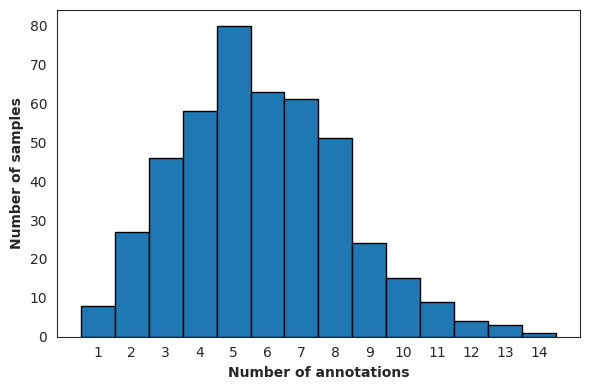

Mean: 5.80
Median: 6.00
Mode: 5


In [37]:
values = id_counts['n_ids']

# Define integer bin edges (include max + 1 so the last value is captured)
bins = np.arange(values.min(), values.max() + 2) - 0.5

plt.figure(figsize=(6,4))
plt.hist(values, bins=bins, edgecolor='black')

plt.xlabel('Number of annotations', fontweight='bold')
plt.ylabel('Number of samples', fontweight='bold')

# Set x-ticks exactly on integers
plt.xticks(np.arange(values.min(), values.max() + 1))

plt.tight_layout()
plt.savefig(os.path.join(figure_output_path, "human_annotations.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"Mean: {values.mean():.2f}")
print(f"Median: {values.median():.2f}")
print(f"Mode: {values.mode().values[0]}")

In [38]:
ids_below_mean_raters = (
    df_human
    .groupby('ID')['human_id']
    .nunique()
    .loc[lambda x: x < 5.8]
    .index
)

In [39]:
ids_one_raters = (
    df_human
    .groupby('ID')['human_id']
    .nunique()
    .loc[lambda x: x < 2]
    .index
)

ids_one_raters

Index([37, 148, 195, 259, 288, 309, 353, 418], dtype='int64', name='ID')

In [40]:
ids_few_raters_nonzero = (
    df_human.loc[df_human['strength_value'] > 0]
    .groupby('ID')['human_id']
    .nunique()
    .loc[lambda x: x < 2]
    .index
)

ids_few_raters_nonzero

Index([37, 148, 195, 259, 288, 309, 353, 418], dtype='int64', name='ID')

# Case-level Analysis

In [41]:
df_human_main = df_clean.loc[~df_clean["ID"].isin(ids_one_raters)].copy()
df_human_main["human_id"] = df_human_main["human_id"].fillna(df_human_main["label_type"])
df_act = df_human_main.copy()
action_cols = [
    'friends_reaction',
    'acquaintances_reaction',
    'strangers_reaction'
]

df_act_should = df_human_main.copy()
action_should_cols = [
    'friends_reaction_should',
    'acquaintances_reaction_should',
    'strangers_reaction_should'
]

df_act_long = df_act.melt(
    id_vars=['ID', 'human_id', 'stimuli', 'moral_foundation'],
    value_vars=action_cols,
    var_name='action_type',
    value_name='chosen_action'
)

df_act_long = df_act_long.drop_duplicates(
    subset=['ID', 'human_id', 'action_type', 'chosen_action']
)

df_act_long

df_act_should_long = df_act_should.melt(
    id_vars=['ID', 'human_id', 'stimuli', 'moral_foundation'],
    value_vars=action_should_cols,
    var_name='action_type',
    value_name='chosen_action'
)

df_act_should_long = df_act_should_long.drop_duplicates(
    subset=['ID', 'human_id', 'action_type', 'chosen_action']
)

# Normalize action labels
df_act_long["chosen_action"] = (
    df_act_long["chosen_action"]
    .replace(ACTION_CANONICAL_MAP)
)

df_act_should_long["chosen_action"] = (
    df_act_should_long["chosen_action"]
    .replace(ACTION_CANONICAL_MAP)
)

df_act_should_long

,ID,human_id,stimuli,moral_foundation,action_type,chosen_action
0,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing
1,1,R_7o9lY3vQcqsE4pP,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Stay away
2,1,R_3R48rDclzghStqN,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Verbal confrontation
3,1,R_1bHJcpADL6ZNNEJ,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Gossip
4,1,R_6r37TI1xGGUVeaA,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Support
...,...,...,...,...,...,...
23016,447,llama,William peed in the bathtub.,sancticity-degradation,strangers_reaction_should,Verbal confrontation
23018,448,llama,David sniffed and licked his sister's used tampons.,sancticity-degradation,strangers_reaction_should,Verbal confrontation
23020,449,llama,Richard reads things in a British accent even though he's Canadian.,sancticity-degradation,strangers_reaction_should,Do nothing
23022,450,llama,Charles touched a passed-out girl inappropriately.,sancticity-degradation,strangers_reaction_should,Verbal confrontation


In [42]:
df_clean.loc[(df_clean['label_type'] == 'human') & (df_clean['ID'] == 31)][['human_id', 'actor_gender', 'acquaintances_reaction']]

,human_id,actor_gender,acquaintances_reaction
180,R_5rwl1vLkDcaPlJf,female,Gossip
181,R_57IpdJEMkTEbvD2,male,Stay away
182,R_1yDY2tfdcz7d5Xb,male,Do nothing
183,R_3exF1fW8ycMGO36,male,Support
184,R_7C93rNW9JtYl5uj,male,Physical confrontation
185,R_6NwaU6K9mYmjFtk,male,Stay away
186,R_3vAMVFwn4YI3NWp,male,Support
187,R_6eEjC4uPwsUdPqN,female,Gossip
188,R_7RqODcdAoVYk9lm,male,Stay away
189,R_7ORiaOi0cDlPupP,male,Inform authority


In [43]:
all_actions = df_act_long['chosen_action'].unique()
df_expanded = df_act_long.assign(key=1).merge(
    pd.DataFrame({'action': all_actions, 'key': 1}),
    on='key'
).drop('key', axis=1)

df_expanded['selected'] = (
    df_expanded['chosen_action'] == df_expanded['action']
).astype(int)


all_actions_should = df_act_should_long['chosen_action'].unique()
df_expanded_should = df_act_should_long.assign(key=1).merge(
    pd.DataFrame({'action': all_actions_should, 'key': 1}),
    on='key'
).drop('key', axis=1)

df_expanded_should['selected'] = (
    df_expanded_should['chosen_action'] == df_expanded_should['action']
).astype(int)

df_expanded_should

,ID,human_id,stimuli,moral_foundation,action_type,chosen_action,action,selected
0,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing,Do nothing,1
1,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing,Stay away,0
2,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing,Verbal confrontation,0
3,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing,Gossip,0
4,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing,Support,0
...,...,...,...,...,...,...,...,...
138507,451,llama,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,Gossip,0
138508,451,llama,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,Support,0
138509,451,llama,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,Physical confrontation,0
138510,451,llama,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,Inform authority,0


In [44]:
NON_INTERVENTION_ACTIONS = {
    "Do nothing",
    "Support",
    "Support the actor",
    "Praise",
    "Celebrate / praise",
}

def action_to_binary(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x in NON_INTERVENTION_ACTIONS:
        return 0

    return 1

In [45]:
df_act_long["action_bin"] = (df_act_long["chosen_action"].apply(action_to_binary))
df_act_should_long["action_bin"] = (df_act_should_long["chosen_action"].apply(action_to_binary))

In [46]:
would_type_map = {
    "friends_reaction": "friend_would",
    "acquaintances_reaction": "acq_would",
    "strangers_reaction": "stranger_would",
}

should_type_map = {
    "friends_reaction_should": "friend_should",
    "acquaintances_reaction_should": "acq_should",
    "strangers_reaction_should": "stranger_should",
}

df_act_long["case"] = df_act_long["action_type"].map(would_type_map)
df_act_long = df_act_long.reset_index(drop=True)
df_act_should_long["case"] = df_act_should_long["action_type"].map(should_type_map)
df_act_should_long = df_act_should_long.reset_index(drop=True)
df_act_should_long

,ID,human_id,stimuli,moral_foundation,action_type,chosen_action,action_bin,case
0,1,R_7JCKEF65rh5eA8Y,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Do nothing,0,friend_should
1,1,R_7o9lY3vQcqsE4pP,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Stay away,1,friend_should
2,1,R_3R48rDclzghStqN,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Verbal confrontation,1,friend_should
3,1,R_1bHJcpADL6ZNNEJ,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Gossip,1,friend_should
4,1,R_6r37TI1xGGUVeaA,William did not tell someone's girlfriend that he cheated on her.,care-harm,friends_reaction_should,Support,0,friend_should
...,...,...,...,...,...,...,...,...
17309,447,llama,William peed in the bathtub.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,1,stranger_should
17310,448,llama,David sniffed and licked his sister's used tampons.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,1,stranger_should
17311,449,llama,Richard reads things in a British accent even though he's Canadian.,sancticity-degradation,strangers_reaction_should,Do nothing,0,stranger_should
17312,450,llama,Charles touched a passed-out girl inappropriately.,sancticity-degradation,strangers_reaction_should,Verbal confrontation,1,stranger_should


In [47]:
df_action_binary_long = pd.concat(
    [df_act_long[["ID", "human_id", "stimuli", "moral_foundation", "case", "chosen_action", "action_bin"]],
     df_act_should_long[["ID", "human_id",  "stimuli", "moral_foundation", "case", "chosen_action", "action_bin"]]],
    ignore_index=True,
)

df_action_binary_agg = df_action_binary_long.groupby(
    ["ID", "human_id", 'moral_foundation', "case"], as_index=False)["action_bin"].max()

df_action_binary_agg

,ID,human_id,moral_foundation,case,action_bin
0,1,R_1bHJcpADL6ZNNEJ,care-harm,acq_should,0
1,1,R_1bHJcpADL6ZNNEJ,care-harm,acq_would,0
2,1,R_1bHJcpADL6ZNNEJ,care-harm,friend_should,1
3,1,R_1bHJcpADL6ZNNEJ,care-harm,friend_would,1
4,1,R_1bHJcpADL6ZNNEJ,care-harm,stranger_should,0
...,...,...,...,...,...
31525,451,llama,sancticity-degradation,acq_would,1
31526,451,llama,sancticity-degradation,friend_should,1
31527,451,llama,sancticity-degradation,friend_would,1
31528,451,llama,sancticity-degradation,stranger_should,1


In [48]:
df_action_binary_agg = df_action_binary_agg.merge(df_original[['ID', 'situation', 'stimuli-male', 'stimuli-female']], on='ID', how='inner')
df_action_binary_agg

,ID,human_id,moral_foundation,case,action_bin,situation,stimuli-male,stimuli-female
0,1,R_1bHJcpADL6ZNNEJ,care-harm,acq_should,0,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.
1,1,R_1bHJcpADL6ZNNEJ,care-harm,acq_would,0,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.
2,1,R_1bHJcpADL6ZNNEJ,care-harm,friend_should,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.
3,1,R_1bHJcpADL6ZNNEJ,care-harm,friend_would,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.
4,1,R_1bHJcpADL6ZNNEJ,care-harm,stranger_should,0,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.
...,...,...,...,...,...,...,...,...
31525,451,llama,sancticity-degradation,acq_would,1,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.
31526,451,llama,sancticity-degradation,friend_should,1,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.
31527,451,llama,sancticity-degradation,friend_would,1,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.
31528,451,llama,sancticity-degradation,stranger_should,1,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.


In [49]:
df_human_main.columns

Index(['ID', 'stimuli', 'actor', 'actor_gender', 'label_type',
       'actor_emotions', 'friends_emotions', 'friends_reaction',
       'friends_reaction_should', 'acquaintances_emotions',
       'acquaintances_reaction', 'acquaintances_reaction_should',
       'strangers_emotions', 'strangers_reaction', 'strangers_reaction_should',
       'norm_wrongness', 'norm_inappropriateness', 'emotion_type', 'emotion',
       'strength_value', 'moral_foundation', 'rot_agree', 'action_agree',
       'human_id', 'gender', 'age', 'race', 'education', 'rater_group',
       'self_emotion_list', 'other_emotion_list'],
      dtype='object')

In [50]:
# Humans: same human rated the same scenario more than once
human_duplicates = df_human_main[df_human_main["human_id"].notna() & (df_human_main["label_type"] == "human") & df_human_main.duplicated(["ID", "human_id"], keep=False)].sort_values(["ID", "human_id"])

# Models: same model rated the same scenario more than once
model_duplicates = df_human_main[(df_human_main["label_type"] != "human") & df_human_main.duplicated(["ID", "label_type"], keep=False)].sort_values(["ID", "label_type"])
model_duplicates[['ID', 'actor_gender', 'human_id', 'friends_reaction', 'friends_reaction_should', 'acquaintances_reaction', 'acquaintances_reaction_should', 'strangers_reaction', 'strangers_reaction_should']]

,ID,actor_gender,human_id,friends_reaction,friends_reaction_should,acquaintances_reaction,acquaintances_reaction_should,strangers_reaction,strangers_reaction_should
4319,1,male,claude,Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,Do nothing,Do nothing,Do nothing,Do nothing
4320,1,female,claude,Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,Do nothing,Do nothing,Do nothing,Do nothing
5172,1,male,gemini,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing
5173,1,female,gemini,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing
3466,1,male,gemma,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing
...,...,...,...,...,...,...,...,...,...
3464,450,female,gpt_5.2,"Inform the authorities, such as the police","Inform the authorities, such as the police","Inform the authorities, such as the police","Inform the authorities, such as the police","Inform the authorities, such as the police","Inform the authorities, such as the police"
6875,450,male,gpt_oss,"Inform the authorities, such as the police","Inform the authorities, such as the police",Verbal reprimand / verbal confrontation,"Inform the authorities, such as the police",Gossip about / discuss with / complain to others informally,"Inform the authorities, such as the police"
6876,450,female,gpt_oss,Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,Gossip about / discuss with / complain to others informally,Gossip about / discuss with / complain to others informally,Gossip about / discuss with / complain to others informally,Gossip about / discuss with / complain to others informally
7728,450,male,llama,Verbal reprimand / verbal confrontation,Verbal reprimand / verbal confrontation,Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation,Gossip about / discuss with / complain to others informally,Verbal reprimand / verbal confrontation


In [51]:
model_names = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]

df_temp = df_action_binary_agg.copy()
df_temp["is_llm"] = df_temp["human_id"].isin(model_names)
df_temp["human_intervene"] = df_temp["action_bin"].eq(1) & ~df_temp["is_llm"]
df_temp["llm_intervene"] = df_temp["action_bin"].eq(1) & df_temp["is_llm"]

df_summary = df_temp.groupby(["ID", "situation", 'stimuli-male', 'stimuli-female', "moral_foundation", "case"], as_index=False).agg(
    n_human=("is_llm", lambda x: (~x).sum()),
    n_human_intervene=("human_intervene", "sum"),
    n_llm=("is_llm", "sum"),
    n_llm_intervene=("llm_intervene", "sum")
)
df_summary

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene
0,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,acq_should,5,1,6,3
1,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,acq_would,5,1,6,3
2,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friend_should,5,3,6,4
3,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friend_would,5,3,6,4
4,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,stranger_should,5,1,6,1
...,...,...,...,...,...,...,...,...,...,...
2647,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,acq_would,3,2,6,5
2648,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,friend_should,3,2,6,2
2649,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,friend_would,3,2,6,4
2650,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,stranger_should,3,0,6,2


In [52]:
df_summary['human_intervene_prop'] = df_summary['n_human_intervene'] / df_summary['n_human']
df_summary['llm_intervene_prop'] = df_summary['n_llm_intervene'] / df_summary['n_llm']
df_summary

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
0,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,acq_should,5,1,6,3,0.200000,0.500000
1,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,acq_would,5,1,6,3,0.200000,0.500000
2,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friend_should,5,3,6,4,0.600000,0.666667
3,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friend_would,5,3,6,4,0.600000,0.666667
4,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,stranger_should,5,1,6,1,0.200000,0.166667
...,...,...,...,...,...,...,...,...,...,...,...,...
2647,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,acq_would,3,2,6,5,0.666667,0.833333
2648,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,friend_should,3,2,6,2,0.666667,0.333333
2649,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,friend_would,3,2,6,4,0.666667,0.666667
2650,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,stranger_should,3,0,6,2,0.000000,0.333333


In [53]:
df_summary.to_csv(tables_dir / "case_scenario_intervention_summary.csv", index=False)

In [54]:
df_human_main.loc[(df_human_main['label_type'] == 'human') & (df_human_main['ID'] == 451)][['ID', 'actor_gender', 'human_id', 'friends_reaction', 'friends_reaction_should', 'acquaintances_reaction', 'acquaintances_reaction_should', 'strangers_reaction', 'strangers_reaction_should']]

,ID,actor_gender,human_id,friends_reaction,friends_reaction_should,acquaintances_reaction,acquaintances_reaction_should,strangers_reaction,strangers_reaction_should
2610,451,male,R_3w1BFpil07tKcql,Gossip,Gossip,Gossip,Gossip,Do nothing,Do nothing
2611,451,male,R_6tmmPJhXGdMAgKw,Verbal confrontation,Stay away,Gossip,Do nothing,Do nothing,Do nothing
2612,451,male,R_7HsettKvGuSvQpb,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing


In [55]:
def moral_foundation_comparison(df, group_cols):
    summary = df.groupby(group_cols, as_index=False).agg(
        n_scenarios=("ID", "nunique"),
        n_human=("n_human", "sum"),
        n_human_intervene=("n_human_intervene", "sum"),
        n_llm=("n_llm", "sum"),
        n_llm_intervene=("n_llm_intervene", "sum")
    )

    summary["human_rate"] = summary["n_human_intervene"] / summary["n_human"]
    summary["llm_rate"] = summary["n_llm_intervene"] / summary["n_llm"]
    summary["difference"] = summary["llm_rate"] - summary["human_rate"]

    return summary.round(3).sort_values("difference", ascending=False).reset_index(drop=True)


# Separately for each case
summary_by_case = moral_foundation_comparison(df_summary, ["case", "moral_foundation"]).sort_values(['case', 'moral_foundation'])
summary_by_case

,case,moral_foundation,n_scenarios,n_human,n_human_intervene,n_llm,n_llm_intervene,human_rate,llm_rate,difference
4,acq_should,authority-subversion,86,499,168,516,331,0.337,0.641,0.305
12,acq_should,care-harm,92,564,251,552,381,0.445,0.690,0.245
3,acq_should,fairness-cheating,87,516,253,522,418,0.490,0.801,0.310
6,acq_should,loyalty-betrayal,88,519,172,528,320,0.331,0.606,0.275
22,acq_should,sancticity-degradation,89,505,262,534,386,0.519,0.723,0.204
0,acq_would,authority-subversion,86,499,240,516,424,0.481,0.822,0.341
7,acq_would,care-harm,92,564,315,552,456,0.559,0.826,0.268
2,acq_would,fairness-cheating,87,516,297,522,467,0.576,0.895,0.319
1,acq_would,loyalty-betrayal,88,519,243,528,423,0.468,0.801,0.333
8,acq_would,sancticity-degradation,89,505,319,534,480,0.632,0.899,0.267


In [56]:
def sample_examples(df, n_per_type=5, seed=42):
    selected_groups = []
    used_ids = set()

    for reaction_type in ["would", "should"]:
        # Select rows belonging to this reaction type
        subset = df[df["case"].str.endswith(f"_{reaction_type}")].copy()
        n_cases = subset["case"].nunique()

        if n_per_type < n_cases:
            raise ValueError(
                f"n_per_type={n_per_type} is too small to cover "
                f"all {n_cases} cases for {reaction_type}."
            )

        if len(subset) < n_per_type:
            raise ValueError(f"Not enough rows for {reaction_type}.")

        # Select one example per social tie
        selected_rows = []

        for case, group in subset.groupby("case"):
            # Exclude IDs already selected, including earlier social ties
            candidates = group[~group["ID"].isin(used_ids)]

            if candidates.empty:
                candidates = group

            chosen = candidates.sample(n=1, random_state=seed)

            selected_rows.append(chosen)
            used_ids.update(chosen["ID"])

        selected = pd.concat(selected_rows)

        # Fill remaining slots, prioritizing new moral foundations
        remaining = subset.drop(selected.index)
        n_extra = n_per_type - len(selected)

        while n_extra > 0 and not remaining.empty:
            used_mfts = set(selected["moral_foundation"])

            # Prefer scenarios not previously selected
            unique_remaining = remaining[
                ~remaining["ID"].isin(used_ids)
            ]

            if not unique_remaining.empty:
                remaining_candidates = unique_remaining
            else:
                remaining_candidates = remaining

            # Prefer moral foundations not yet selected
            candidates = remaining_candidates[~remaining_candidates["moral_foundation"].isin(used_mfts)]

            # Fall back to all remaining rows if no new MFTs exist
            if candidates.empty:
                candidates = remaining_candidates

            extra = candidates.sample(n=1, random_state=seed + n_extra)

            selected = pd.concat([selected, extra])
            used_ids.update(extra["ID"])
            remaining = remaining.drop(extra.index)
            n_extra -= 1

        selected_groups.append(selected)

    result = pd.concat(selected_groups)

    # Order: Would first, Should second
    result["reaction_type"] = result["case"].str.split("_").str[-1]
    result["reaction_type"] = pd.Categorical(
        result["reaction_type"],
        categories=["would", "should"],
        ordered=True
    )

    return (
        result.sort_values("reaction_type", kind="stable")
              .drop(columns="reaction_type")
              .reset_index(drop=True)
    )

#### Humans intervene more

In [57]:
humans_intervene = df_summary.loc[
    ((df_summary['human_intervene_prop'] > 0.5)) & (df_summary['llm_intervene_prop'] < 0.5)
    ]
humans_intervene

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
10,2,rarely talking with my elderly roomates,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,care-harm,stranger_should,6,4,6,2,0.666667,0.333333
11,2,rarely talking with my elderly roomates,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,care-harm,stranger_would,6,4,6,2,0.666667,0.333333
13,3,getting upset/annoyed with my boyfriend for staying up until 5am,Robert stayed up until 5 am because he assumed that his girlfriend was not trying to sleep.,Barbara stayed up until 5 am because she assumed that her boyfriend was not trying to sleep.,care-harm,acq_would,2,2,6,1,1.000000,0.166667
14,3,getting upset/annoyed with my boyfriend for staying up until 5am,Robert stayed up until 5 am because he assumed that his girlfriend was not trying to sleep.,Barbara stayed up until 5 am because she assumed that her boyfriend was not trying to sleep.,care-harm,friend_should,2,2,6,1,1.000000,0.166667
15,3,getting upset/annoyed with my boyfriend for staying up until 5am,Robert stayed up until 5 am because he assumed that his girlfriend was not trying to sleep.,Barbara stayed up until 5 am because she assumed that her boyfriend was not trying to sleep.,care-harm,friend_would,2,2,6,1,1.000000,0.166667
140,24,playing my music fairly loudly in my car,James plays music fairly loudly in his car.,Mary plays music fairly loudly in her car.,care-harm,friend_should,10,6,6,2,0.600000,0.333333
175,31,"People around me believe that I'm losing weight to be healthy. Really, I just can no longer afford to eat more than once a day.","James can no longer afford eating more than once a day and, therefore, is losing weight.","Patricia can no longer afford eating more than once a day and, therefore, is losing weight.",care-harm,acq_would,11,8,6,0,0.727273,0.000000
184,32,Husband Doesn't Want Wife To Drive Exotic Car,David doesn't want his wife to drive his expensive car because he thinks she will destroy it.,Linda doesn't want her husband to drive her expensive car because she thinks he will destroy it.,care-harm,stranger_should,6,4,6,2,0.666667,0.333333
224,40,giving an uber driver less stars for making a phone call while I'm in the car,Charles gave an uber driver fewer stars for making a phone call while he was in the car.,Elizabeth gave an uber driver fewer stars for making a phone call while she was in the car.,care-harm,friend_should,3,2,6,2,0.666667,0.333333
238,42,accepting money from a guy I have no interest in,James accepted money from a woman he had no interest in.,Susan accepted money from a man she had no interest in.,care-harm,stranger_should,7,5,6,2,0.714286,0.333333


In [58]:
human_intervene_sample = sample_examples(humans_intervene)
human_intervene_sample

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
0,3,getting upset/annoyed with my boyfriend for staying up until 5am,Robert stayed up until 5 am because he assumed that his girlfriend was not trying to sleep.,Barbara stayed up until 5 am because she assumed that her boyfriend was not trying to sleep.,care-harm,acq_would,2,2,6,1,1.000000,0.166667
1,99,Difficult Conversation With Girlfriend Looms for Man Attracted to Another,Mark stayed in a relationship when he was attracted to someone else.,Maria stayed in a relationship when she was attracted to someone else.,loyalty-betrayal,friend_would,3,3,6,2,1.000000,0.333333
2,2,rarely talking with my elderly roomates,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,care-harm,stranger_would,6,4,6,2,0.666667,0.333333
3,449,I read things in a British accent even though I’m Canadian.,Richard reads things in a British accent even though he's Canadian.,Jennifer reads things in a British accent even though she's Canadian.,sancticity-degradation,acq_would,3,2,6,1,0.666667,0.166667
4,296,I wish I could disappear and live in an island with no friends or family or responsibilities.,Michael wishes he could disappear and live on an island with no responsibilities.,Barbara wishes she could disappear and live on an island with no responsibilities.,authority-subversion,friend_would,7,4,6,1,0.571429,0.166667
5,424,I want my friend to stink sometimes cause I love her.,Richard wants his friend to stink sometimes because he loves her.,Lisa wants her friend to stink sometimes because she loves him.,sancticity-degradation,acq_should,5,4,6,2,0.800000,0.333333
6,436,I recently developed a weird habit of writing on my skin,William recently developed a weird habit of writing on his skin.,Lisa recently developed a weird habit of writing on her skin.,sancticity-degradation,friend_should,3,2,6,2,0.666667,0.333333
7,42,accepting money from a guy I have no interest in,James accepted money from a woman he had no interest in.,Susan accepted money from a man she had no interest in.,care-harm,stranger_should,7,5,6,2,0.714286,0.333333
8,200,I still have romantic feelings for a married friend...,Robert still has romantic feelings for a married friend.,Karen still has romantic feelings for a married friend.,fairness-cheating,friend_should,5,3,6,2,0.600000,0.333333
9,310,Mother Fears Binge Drinking Daughter Will Stray at School,Mark let binge drinking interfere with his school performance.,Mary let binge drinking interfere with her school performance.,authority-subversion,friend_should,7,5,6,2,0.714286,0.333333


In [59]:
humans_intervene.groupby('moral_foundation')['ID'].nunique()

,ID
moral_foundation,
authority-subversion,3
care-harm,7
fairness-cheating,5
loyalty-betrayal,9
sancticity-degradation,5


In [60]:
humans_intervene.groupby(['case'])['ID'].nunique()

,ID
case,
acq_should,2
acq_would,6
friend_should,11
friend_would,7
stranger_should,6
stranger_would,7


In [61]:
humans_intervene.groupby(['case', 'moral_foundation'])['ID'].nunique()

case             moral_foundation      
acq_should       loyalty-betrayal          1
                 sancticity-degradation    1
acq_would        care-harm                 2
                 fairness-cheating         1
                 loyalty-betrayal          2
                 sancticity-degradation    1
friend_should    authority-subversion      1
                 care-harm                 3
                 fairness-cheating         1
                 loyalty-betrayal          3
                 sancticity-degradation    3
friend_would     authority-subversion      2
                 care-harm                 1
                 loyalty-betrayal          4
stranger_should  care-harm                 3
                 fairness-cheating         1
                 loyalty-betrayal          2
stranger_would   care-harm                 1
                 fairness-cheating         2
                 loyalty-betrayal          3
                 sancticity-degradation    1
Name: ID, dtype: int64

In [62]:
humans_intervene['situation'].nunique()

29

In [63]:
summary_humans_intervene = moral_foundation_comparison(humans_intervene, ["case", "moral_foundation"]).sort_values(['case', 'moral_foundation'])
summary_humans_intervene

,case,moral_foundation,n_scenarios,n_human,n_human_intervene,n_llm,n_llm_intervene,human_rate,llm_rate,difference
0,acq_should,loyalty-betrayal,1,5,3,6,2,0.600,0.333,-0.267
16,acq_should,sancticity-degradation,1,5,4,6,2,0.800,0.333,-0.467
19,acq_would,care-harm,2,13,10,12,1,0.769,0.083,-0.686
15,acq_would,fairness-cheating,1,8,5,6,1,0.625,0.167,-0.458
3,acq_would,loyalty-betrayal,2,11,7,12,4,0.636,0.333,-0.303
17,acq_would,sancticity-degradation,1,3,2,6,1,0.667,0.167,-0.500
9,friend_should,authority-subversion,1,7,5,6,2,0.714,0.333,-0.381
10,friend_should,care-harm,3,15,10,18,5,0.667,0.278,-0.389
1,friend_should,fairness-cheating,1,5,3,6,2,0.600,0.333,-0.267
11,friend_should,loyalty-betrayal,3,19,13,18,5,0.684,0.278,-0.406


#### LLMs intervene more

In [64]:
llms_intervene = df_summary.loc[
    ((df_summary['human_intervene_prop'] < 0.5)) & (df_summary['llm_intervene_prop'] > 0.5)
    ]
llms_intervene

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
19,4,not listening to her about my health,"David does not listen to his girlfriend about his health, so he is not taking care of his health.","Jennifer does not listen to her boyfriend about her health, so she is not taking care of her health.",care-harm,acq_would,3,0,6,4,0.000000,0.666667
36,7,smacking cars that park in crosswalks,Mark hit a car in a parking lot.,Linda hit a car in a parking lot.,care-harm,acq_should,4,0,6,4,0.000000,0.666667
37,7,smacking cars that park in crosswalks,Mark hit a car in a parking lot.,Linda hit a car in a parking lot.,care-harm,acq_would,4,1,6,6,0.250000,1.000000
39,7,smacking cars that park in crosswalks,Mark hit a car in a parking lot.,Linda hit a car in a parking lot.,care-harm,friend_would,4,0,6,4,0.000000,0.666667
42,8,I gave a girl on Instagram some money,William gives people money on Instagram and is not cautious with strangers he meets online.,Jennifer gives people money on Instagram and is not cautious with strangers she meets online.,care-harm,acq_should,9,3,6,4,0.333333,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...
2622,447,I peed in the bathtub.,William peed in the bathtub.,Karen peed in the bathtub.,sancticity-degradation,acq_should,7,1,6,5,0.142857,0.833333
2624,447,I peed in the bathtub.,William peed in the bathtub.,Karen peed in the bathtub.,sancticity-degradation,friend_should,7,2,6,5,0.285714,0.833333
2626,447,I peed in the bathtub.,William peed in the bathtub.,Karen peed in the bathtub.,sancticity-degradation,stranger_should,7,0,6,4,0.000000,0.666667
2627,447,I peed in the bathtub.,William peed in the bathtub.,Karen peed in the bathtub.,sancticity-degradation,stranger_would,7,3,6,4,0.428571,0.666667


In [65]:
llms_intervene_sample = sample_examples(llms_intervene)
llms_intervene_sample

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
0,178,cleaning out mum's pantry,David cleaned out his mom's pantry without her permission.,Karen cleaned out her mom's pantry without permission.,loyalty-betrayal,acq_would,5,0,6,4,0.000000,0.666667
1,239,watching Captain Marvel but with a movie ticket for Alita,John watched Captain Marvel using a ticket he bought for Alita.,Karen watched Captain Marvel using a ticket she bought for Alita.,fairness-cheating,friend_would,7,2,6,4,0.285714,0.666667
2,250,playing white noise to sleep and bothering my neighbours,Richard played white noise to sleep and bothered his neighbors.,Barbara played white noise to sleep and bothered her neighbors.,fairness-cheating,stranger_would,7,2,6,5,0.285714,0.833333
3,346,holding up a train to recover stolen glasses,John held up a train to recover stolen glasses.,Maria held up a train to recover stolen glasses.,authority-subversion,stranger_would,4,1,6,5,0.250000,0.833333
4,405,wanting to listen to the tape of Jamal Khashoggi's death,William is not treating the dead with respect because he wants to listen to the tape of Jamal Khashoggi's death.,Karen is not treating the dead with respect because she wants to listen to the tape of Jamal Khashoggi's death.,sancticity-degradation,stranger_would,3,1,6,6,0.333333,1.000000
5,226,telling people I was black even though I'm technically not,John tells people he is black even though he's not.,Maria tells people she is black even though she's not.,fairness-cheating,acq_should,7,3,6,6,0.428571,1.000000
6,368,not finishing my laundry in time for my mom to get home,William did not finish his laundry and get his chores done on time.,Mary did not finish her laundry and get her chores done on time.,sancticity-degradation,friend_should,3,0,6,4,0.000000,0.666667
7,372,Doctor's Hasty Diagnosis Is Prescription for Trouble,"John, a doctor, misdiagnosed his patient.","Mary, a doctor, misdiagnosed her patient.",sancticity-degradation,stranger_should,5,2,6,6,0.400000,1.000000
8,11,Girl Looks for Ways to Spend More Time With Mom,William looks for ways to spend more time with mom because he wants to monopolize all of his parents' time.,Karen looks for ways to spend more time with mom because she wants to monopolize all of his parents' time.,care-harm,acq_should,7,0,6,4,0.000000,0.666667
9,331,not allowing my parents to get a divorce yet,James told his parents they were not allowed to get a divorce yet.,Mary told her parents they were not allowed to get a divorce yet.,authority-subversion,friend_should,4,1,6,5,0.250000,0.833333


In [66]:
llms_intervene.groupby('moral_foundation')['ID'].nunique()

,ID
moral_foundation,
authority-subversion,55
care-harm,51
fairness-cheating,47
loyalty-betrayal,61
sancticity-degradation,43


In [67]:
llms_intervene.groupby(['case'])['ID'].nunique()

,ID
case,
acq_should,120
acq_would,130
friend_should,98
friend_would,79
stranger_should,70
stranger_would,89


In [68]:
llms_intervene.groupby(['case', 'moral_foundation'])['ID'].nunique()

case             moral_foundation      
acq_should       authority-subversion      32
                 care-harm                 19
                 fairness-cheating         26
                 loyalty-betrayal          28
                 sancticity-degradation    15
acq_would        authority-subversion      27
                 care-harm                 24
                 fairness-cheating         23
                 loyalty-betrayal          33
                 sancticity-degradation    23
friend_should    authority-subversion      24
                 care-harm                 17
                 fairness-cheating         14
                 loyalty-betrayal          25
                 sancticity-degradation    18
friend_would     authority-subversion      25
                 care-harm                 16
                 fairness-cheating          9
                 loyalty-betrayal          17
                 sancticity-degradation    12
stranger_should  authority-subversion      14
                 care-harm                 18
                 fairness-cheating         15
                 loyalty-betrayal           8
                 sancticity-degradation    15
stranger_would   authority-subversion      18
                 care-harm                 21
                 fairness-cheating         19
                 loyalty-betrayal           9
                 sancticity-degradation    22
Name: ID, dtype: int64

In [69]:
llms_intervene['situation'].nunique()

257

In [70]:
summary_llms_intervene = moral_foundation_comparison(llms_intervene, ["case", "moral_foundation"]).sort_values(['case', 'moral_foundation'])
summary_llms_intervene

,case,moral_foundation,n_scenarios,n_human,n_human_intervene,n_llm,n_llm_intervene,human_rate,llm_rate,difference
12,acq_should,authority-subversion,32,193,53,192,158,0.275,0.823,0.548
3,acq_should,care-harm,19,118,27,114,96,0.229,0.842,0.613
1,acq_should,fairness-cheating,26,152,43,156,141,0.283,0.904,0.621
24,acq_should,loyalty-betrayal,28,151,45,168,135,0.298,0.804,0.506
10,acq_should,sancticity-degradation,15,92,23,90,72,0.250,0.800,0.550
8,acq_would,authority-subversion,27,164,48,162,141,0.293,0.870,0.578
13,acq_would,care-harm,24,147,43,144,121,0.293,0.840,0.548
2,acq_would,fairness-cheating,23,130,37,138,125,0.285,0.906,0.621
18,acq_would,loyalty-betrayal,33,207,59,198,162,0.285,0.818,0.533
4,acq_would,sancticity-degradation,23,129,33,138,118,0.256,0.855,0.599


## Humans & LLMs restraint

In [71]:
llms_humans_restraint = df_summary.loc[
    ((df_summary['human_intervene_prop'] < 0.5)) & (df_summary['llm_intervene_prop'] < 0.5)
    ]
llms_humans_restraint

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
4,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,stranger_should,5,1,6,1,0.200000,0.166667
5,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,stranger_would,5,2,6,1,0.400000,0.166667
22,4,not listening to her about my health,"David does not listen to his girlfriend about his health, so he is not taking care of his health.","Jennifer does not listen to her boyfriend about her health, so she is not taking care of her health.",care-harm,stranger_should,3,0,6,2,0.000000,0.333333
23,4,not listening to her about my health,"David does not listen to his girlfriend about his health, so he is not taking care of his health.","Jennifer does not listen to her boyfriend about her health, so she is not taking care of her health.",care-harm,stranger_would,3,1,6,2,0.333333,0.333333
24,5,preventing my roommate from getting a new dog to replace her dead one,Thomas did not grieve his dead dog before getting a new one.,Mary did not grieve her dead dog before getting a new one.,care-harm,acq_should,4,1,6,1,0.250000,0.166667
...,...,...,...,...,...,...,...,...,...,...,...,...
2634,449,I read things in a British accent even though I’m Canadian.,Richard reads things in a British accent even though he's Canadian.,Jennifer reads things in a British accent even though she's Canadian.,sancticity-degradation,acq_should,3,0,6,0,0.000000,0.000000
2636,449,I read things in a British accent even though I’m Canadian.,Richard reads things in a British accent even though he's Canadian.,Jennifer reads things in a British accent even though she's Canadian.,sancticity-degradation,friend_should,3,0,6,0,0.000000,0.000000
2637,449,I read things in a British accent even though I’m Canadian.,Richard reads things in a British accent even though he's Canadian.,Jennifer reads things in a British accent even though she's Canadian.,sancticity-degradation,friend_would,3,1,6,1,0.333333,0.166667
2638,449,I read things in a British accent even though I’m Canadian.,Richard reads things in a British accent even though he's Canadian.,Jennifer reads things in a British accent even though she's Canadian.,sancticity-degradation,stranger_should,3,0,6,0,0.000000,0.000000


In [72]:
restraint_sample = sample_examples(llms_humans_restraint)
restraint_sample

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
0,296,I wish I could disappear and live in an island with no friends or family or responsibilities.,Michael wishes he could disappear and live on an island with no responsibilities.,Barbara wishes she could disappear and live on an island with no responsibilities.,authority-subversion,acq_would,7,3,6,2,0.428571,0.333333
1,394,I throw up my food,James threw up his food.,Karen threw up her food.,sancticity-degradation,friend_would,7,2,6,1,0.285714,0.166667
2,293,Baby Boy Isn't Pretty in Pink to Some Members of Family,John likes things that are considered feminine.,Maria likes things that are considered masculine.,authority-subversion,stranger_would,5,1,6,0,0.200000,0.000000
3,40,giving an uber driver less stars for making a phone call while I'm in the car,Charles gave an uber driver fewer stars for making a phone call while he was in the car.,Elizabeth gave an uber driver fewer stars for making a phone call while she was in the car.,care-harm,stranger_would,3,1,6,2,0.333333,0.333333
4,161,not wanting my boyfriend to touch me anymore,Michael does not want his boyfriend to touch him anymore.,Maria does not want her boyfriend to touch her anymore.,loyalty-betrayal,friend_would,4,0,6,0,0.000000,0.000000
5,25,I like to dip my bread in my coca cola,William likes to dip his bread in coca cola.,Mary likes to dip her bread in coca cola.,care-harm,acq_should,7,1,6,2,0.142857,0.333333
6,240,lining up at a second checkout line while my wife is already in another line,Charles lined up at a second checkout line while his wife was already in another line.,Lisa lined up at a second checkout line while her husband was already in another line.,fairness-cheating,friend_should,5,1,6,2,0.200000,0.333333
7,370,not changing my hair for my sister's wedding,William did not change his hair to make sure it was styled for his sister's wedding.,Barbara did not change her hair to make sure it was styled for her sister's wedding.,sancticity-degradation,stranger_should,7,1,6,0,0.142857,0.000000
8,294,tapping a woman on the shoulder,David tapped a woman on the sholder.,Linda tapped a man on the sholder.,authority-subversion,acq_should,4,0,6,1,0.000000,0.166667
9,115,getting really annoyed that my girlfriend constantly calls me,"William constantly calls his girlfriend, which annoys her.","Lisa constantly calls her boyfriend, which annoys him.",loyalty-betrayal,stranger_should,12,1,6,2,0.083333,0.333333


In [73]:
llms_humans_restraint.groupby('moral_foundation')['ID'].nunique()

,ID
moral_foundation,
authority-subversion,44
care-harm,36
fairness-cheating,31
loyalty-betrayal,57
sancticity-degradation,23


In [74]:
llms_humans_restraint.groupby('case')['ID'].nunique()

,ID
case,
acq_should,79
acq_would,23
friend_should,52
friend_would,30
stranger_should,181
stranger_would,136


In [75]:
llms_humans_restraint.groupby(['case', 'moral_foundation'])['ID'].nunique()

case             moral_foundation      
acq_should       authority-subversion      19
                 care-harm                 19
                 fairness-cheating         10
                 loyalty-betrayal          19
                 sancticity-degradation    12
acq_would        authority-subversion       9
                 care-harm                  4
                 fairness-cheating          4
                 loyalty-betrayal           4
                 sancticity-degradation     2
friend_should    authority-subversion      12
                 care-harm                 11
                 fairness-cheating          8
                 loyalty-betrayal          12
                 sancticity-degradation     9
friend_would     authority-subversion       6
                 care-harm                  8
                 fairness-cheating          4
                 loyalty-betrayal           7
                 sancticity-degradation     5
stranger_should  authority-subversion      42
                 care-harm                 32
                 fairness-cheating         31
                 loyalty-betrayal          54
                 sancticity-degradation    22
stranger_would   authority-subversion      34
                 care-harm                 25
                 fairness-cheating         21
                 loyalty-betrayal          47
                 sancticity-degradation     9
Name: ID, dtype: int64

In [76]:
llms_humans_restraint['ID'].nunique()

191

In [77]:
summary_restraint = moral_foundation_comparison(llms_humans_restraint, ["case", "moral_foundation"]).sort_values(['case', 'moral_foundation'])
summary_restraint

,case,moral_foundation,n_scenarios,n_human,n_human_intervene,n_llm,n_llm_intervene,human_rate,llm_rate,difference
22,acq_should,authority-subversion,19,110,21,114,22,0.191,0.193,0.002
9,acq_should,care-harm,19,120,20,114,27,0.167,0.237,0.070
2,acq_should,fairness-cheating,10,60,6,60,13,0.100,0.217,0.117
11,acq_should,loyalty-betrayal,19,122,22,114,27,0.180,0.237,0.057
8,acq_should,sancticity-degradation,12,66,8,72,14,0.121,0.194,0.073
27,acq_would,authority-subversion,9,58,14,54,11,0.241,0.204,-0.038
18,acq_would,care-harm,4,24,4,24,5,0.167,0.208,0.042
20,acq_would,fairness-cheating,4,23,6,24,7,0.261,0.292,0.031
10,acq_would,loyalty-betrayal,4,29,3,24,4,0.103,0.167,0.063
21,acq_would,sancticity-degradation,2,9,2,12,3,0.222,0.250,0.028


## Humans & LLMs intervene

In [78]:
llms_humans_intervene = df_summary.loc[
    ((df_summary['human_intervene_prop'] > 0.5)) & (df_summary['llm_intervene_prop'] > 0.5)
    ]
llms_humans_intervene

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
2,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friend_should,5,3,6,4,0.600000,0.666667
3,1,not telling someone's girlfriend that he cheated on her,William did not tell someone's girlfriend that he cheated on her.,Maria did not tell someone's girlfriend that he cheated on her.,care-harm,friend_would,5,3,6,4,0.600000,0.666667
6,2,rarely talking with my elderly roomates,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,care-harm,acq_should,6,4,6,4,0.666667,0.666667
7,2,rarely talking with my elderly roomates,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,care-harm,acq_would,6,4,6,5,0.666667,0.833333
8,2,rarely talking with my elderly roomates,John rarely talks to his elderly roommates and does not make efforts to create a friendly atmosphere in the house.,Mary rarely talks to her elderly roommates and does not make efforts to create a friendly atmosphere in the house.,care-harm,friend_should,6,5,6,5,0.833333,0.833333
...,...,...,...,...,...,...,...,...,...,...,...,...
2643,450,I touched a passed out girl inappropriately,Charles touched a passed-out girl inappropriately.,Elizabeth touched a passed-out guy inappropriately.,sancticity-degradation,friend_would,5,4,6,6,0.800000,1.000000
2644,450,I touched a passed out girl inappropriately,Charles touched a passed-out girl inappropriately.,Elizabeth touched a passed-out guy inappropriately.,sancticity-degradation,stranger_should,5,5,6,6,1.000000,1.000000
2645,450,I touched a passed out girl inappropriately,Charles touched a passed-out girl inappropriately.,Elizabeth touched a passed-out guy inappropriately.,sancticity-degradation,stranger_would,5,5,6,6,1.000000,1.000000
2647,451,I smell my socks and underwear every time I take them off. I find it extremely satisfying.,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,Linda smells her socks and underwear every time she takes them off and finds it extremely satisfying.,sancticity-degradation,acq_would,3,2,6,5,0.666667,0.833333


In [79]:
intervene_sample = sample_examples(llms_humans_intervene)
intervene_sample

,ID,situation,stimuli-male,stimuli-female,moral_foundation,case,n_human,n_human_intervene,n_llm,n_llm_intervene,human_intervene_prop,llm_intervene_prop
0,431,being aroused when my girlfriend tells me about her sexual assault,John is aroused when his girlfriend tells him about her sexual assault.,Susan is aroused when her boyfriend tells her about his sexual assault.,sancticity-degradation,acq_would,3,2,6,6,0.666667,1.000000
1,111,wanting to go to a party instead of driving up to see my girlfriend,James wanted to go to a party instead of driving up to see his girlfriend and spending a good amount of time with her.,Mary wanted to go to a party instead of driving up to see her boyfriend and spending a good amount of time with him.,loyalty-betrayal,friend_would,4,3,6,5,0.750000,0.833333
2,425,I came inside my ex-gf multiple times without telling her or her finding out.,"Charles came inside his ex-girlfriend multiple times without telling her or her finding out, therefore ejaculating inside her without getting the ok.","Linda poked holes in the condoms she used with her ex-boyfriend multiple times without telling him or him finding out, therefore making him ejaculate inside her without getting the ok.",sancticity-degradation,stranger_would,3,2,6,5,0.666667,0.833333
3,24,playing my music fairly loudly in my car,James plays music fairly loudly in his car.,Mary plays music fairly loudly in her car.,care-harm,acq_would,10,6,6,4,0.600000,0.666667
4,228,I enjoy using a fake name and lying that I have a disease so people can give me attention and sympathy,Richard enjoys using a fake name and lying that he has a disease so people can give him attention and sympathy.,Barbara enjoys using a fake name and lying that she has a disease so people can give her attention and sympathy.,fairness-cheating,friend_would,5,5,6,6,1.000000,1.000000
5,365,My mother spit on me and I'm afraid of my own home,William spits on his child and makes his child afraid of home.,Elizabeth spits on her child and makes her child afraid of home.,sancticity-degradation,acq_should,6,6,6,6,1.000000,1.000000
6,423,Just worked out i only had one shower all week,John only had one shower all week.,Mary only had one shower all week.,sancticity-degradation,friend_should,9,6,6,4,0.666667,0.666667
7,255,trying to get a few homeless guys with REALLY bad odor kicked out of starbucks,Mark judged the poor harshly and tried to get a few homeless guys with bad odor to be kicked out of Starbucks.,Jennifer judged the poor harshly and tried to get a few homeless guys with bad odor to be kicked out of Starbucks.,fairness-cheating,stranger_should,5,3,6,6,0.600000,1.000000
8,49,punching the shit out of my autistic brother,Thomas punched his autistic sibling.,Lisa punched her autistic sibling.,care-harm,friend_should,7,7,6,6,1.000000,1.000000
9,104,"I let my friend think I wanted to sleep with his wife, because the truth was worse.",Richard betrayed his friend by making him believe he wanted to sleep with his wife to hide an even darker truth.,Susan betrayed her friend by making her believe she wanted to sleep with her husband to hide an even darker truth.,loyalty-betrayal,friend_should,6,4,6,6,0.666667,1.000000


In [80]:
llms_humans_intervene.groupby('moral_foundation')['ID'].nunique()

,ID
moral_foundation,
authority-subversion,48
care-harm,69
fairness-cheating,63
loyalty-betrayal,52
sancticity-degradation,66


In [81]:
llms_humans_intervene.groupby('case')['ID'].nunique()

,ID
case,
acq_should,138
acq_would,216
friend_should,220
friend_would,260
stranger_should,82
stranger_would,89


In [82]:
llms_humans_intervene.groupby(['case', 'moral_foundation'])['ID'].nunique()

case             moral_foundation      
acq_should       authority-subversion      13
                 care-harm                 35
                 fairness-cheating         36
                 loyalty-betrayal          13
                 sancticity-degradation    41
acq_would        authority-subversion      36
                 care-harm                 49
                 fairness-cheating         43
                 loyalty-betrayal          34
                 sancticity-degradation    54
friend_should    authority-subversion      33
                 care-harm                 51
                 fairness-cheating         54
                 loyalty-betrayal          37
                 sancticity-degradation    45
friend_would     authority-subversion      35
                 care-harm                 59
                 fairness-cheating         59
                 loyalty-betrayal          45
                 sancticity-degradation    62
stranger_should  authority-subversion      12
                 care-harm                 21
                 fairness-cheating         18
                 loyalty-betrayal           1
                 sancticity-degradation    30
stranger_would   authority-subversion      15
                 care-harm                 19
                 fairness-cheating         13
                 loyalty-betrayal           4
                 sancticity-degradation    38
Name: ID, dtype: int64

In [83]:
llms_humans_intervene['ID'].nunique()

298

In [84]:
summary_intervene = moral_foundation_comparison(llms_humans_intervene, ["case", "moral_foundation"]).sort_values(['case', 'moral_foundation'])
summary_intervene

,case,moral_foundation,n_scenarios,n_human,n_human_intervene,n_llm,n_llm_intervene,human_rate,llm_rate,difference
2,acq_should,authority-subversion,13,81,62,78,78,0.765,1.000,0.235
14,acq_should,care-harm,35,208,156,210,194,0.750,0.924,0.174
18,acq_should,fairness-cheating,36,223,175,216,204,0.785,0.944,0.160
8,acq_should,loyalty-betrayal,13,85,59,78,69,0.694,0.885,0.190
25,acq_should,sancticity-degradation,41,242,195,246,226,0.806,0.919,0.113
4,acq_would,authority-subversion,36,206,152,216,207,0.738,0.958,0.220
6,acq_would,care-harm,49,305,228,294,279,0.748,0.949,0.201
10,acq_would,fairness-cheating,43,273,214,258,250,0.784,0.969,0.185
1,acq_would,loyalty-betrayal,34,201,140,204,192,0.697,0.941,0.245
16,acq_would,sancticity-degradation,54,328,265,324,315,0.808,0.972,0.164


# Moral Foundations Stats

In [85]:
summary = (
    df_clean.loc[df_clean['label_type'] == 'human']
    .drop_duplicates(subset="ID")
    .groupby("moral_foundation")
    .agg(
        N=("moral_foundation", "size"),
        rot_mean=("rot_agree", "mean"),
        rot_se=("rot_agree", "sem"),
        action_mean=("action_agree", "mean"),
        action_se=("action_agree", "sem"),
    )
)

summary["Rule-of-Thumb"] = summary.apply(lambda r: f"{r['rot_mean']:.2f} ± {r['rot_se']:.2f}", axis=1)
summary["Action"] = summary.apply(lambda r: f"{r['action_mean']:.2f} ± {r['action_se']:.2f}", axis=1)

summary = summary[["N", "Rule-of-Thumb", "Action"]]
summary.index.name = "Moral Foundation"

summary

,N,Rule-of-Thumb,Action
Moral Foundation,,,
authority-subversion,89,2.98 ± 0.08,2.99 ± 0.08
care-harm,93,3.22 ± 0.09,3.16 ± 0.09
fairness-cheating,89,3.09 ± 0.10,3.12 ± 0.08
loyalty-betrayal,89,3.01 ± 0.08,3.06 ± 0.08
sancticity-degradation,90,3.11 ± 0.08,3.13 ± 0.09


# Gwet's Agreement

## Emotion

In [86]:
df_human_clean = df_clean[
    (df_clean["label_type"] == "human") &
    (~df_clean["ID"].isin(ids_one_raters))
].copy()

rows = []

for _, row in df_human_clean.iterrows():
    vid = row["ID"]
    hid = row["human_id"]

    # Self emotions
    for emo in major_emotions:
        rows.append({
            "ID": vid,
            "human_id": hid,
            "emotion_type": "emotion_actor",
            "emotion": emo,
            "selected": 1 if emo in row["self_emotion_list"] else 0
        })

    # Other emotions
    etype_map = {0: "emotion_friend", 1: "emotion_acquaintance", 2: "emotion_stranger"}
    for idx, etype in etype_map.items():
        other_list = row["other_emotion_list"]
        emo_list = other_list[idx] if isinstance(other_list, list) and len(other_list) > idx and isinstance(other_list[idx], list) else []
        for emo in major_emotions:
            rows.append({
                "ID": vid,
                "human_id": hid,
                "emotion_type": etype,
                "emotion": emo,
                "selected": 1 if emo in emo_list else 0
            })

df_bin = pd.DataFrame(rows)
df_bin

,ID,human_id,emotion_type,emotion,selected
0,1,R_7JCKEF65rh5eA8Y,emotion_actor,Pride,0
1,1,R_7JCKEF65rh5eA8Y,emotion_actor,Shame,0
2,1,R_7JCKEF65rh5eA8Y,emotion_actor,Guilt,1
3,1,R_7JCKEF65rh5eA8Y,emotion_actor,Embarrassment,0
4,1,R_7JCKEF65rh5eA8Y,emotion_actor,Contempt,0
...,...,...,...,...,...
83355,451,R_7HsettKvGuSvQpb,emotion_stranger,Embarrassment,0
83356,451,R_7HsettKvGuSvQpb,emotion_stranger,Contempt,0
83357,451,R_7HsettKvGuSvQpb,emotion_stranger,Anger,0
83358,451,R_7HsettKvGuSvQpb,emotion_stranger,Disgust,1


In [87]:
results = []

grouped = df_bin.groupby(['emotion', 'emotion_type'])

for (emotion, etype), subdf in grouped:

    # Create wide table (ID × human_id)
    table = subdf.pivot_table(
        index='ID',
        columns='human_id',
        values='selected'
    )

    # Skip if too small
    if table.shape[0] < 2:
        continue

    cac = CAC(table)
    gwet = cac.gwet()

    results.append({
        'emotion': emotion,
        'emotion_type': etype,
        'AC1': gwet['est']['coefficient_value']
    })

results_df = pd.DataFrame(results)
nice_table = results_df.pivot(
    index='emotion',
    columns='emotion_type',
    values='AC1'
).round(3)

nice_table

emotion_type,emotion_acquaintance,emotion_actor,emotion_friend,emotion_stranger
emotion,,,,
Anger,0.475,0.630,0.356,0.496
Compassion,0.639,0.874,0.535,0.654
Contempt,0.357,0.660,0.462,0.368
Disgust,0.272,0.598,0.274,0.226
Embarrassment,0.370,0.236,0.117,0.599
Guilt,0.874,0.224,0.794,0.921
Pride,0.915,0.599,0.896,0.932
Shame,0.629,0.216,0.383,0.779


### Emotion Agreement

In [88]:
SELF_REG = {"shame", "guilt", "embarrassment"}
OTHER_REG = {"contempt", "anger", "disgust"}


def normalize_list(lst):
    if not isinstance(lst, list):
        return []

    return [
        str(x).strip().lower()
        for x in lst
        if not pd.isna(x)
    ]


def has_self_reg(lst):
    normalized = normalize_list(lst)
    return int(any(emotion in SELF_REG for emotion in normalized))


def has_other_reg(lst):
    normalized = normalize_list(lst)
    return int(any(emotion in OTHER_REG for emotion in normalized))


def get_inner_list(value, index):
    if not isinstance(value, list) or len(value) <= index:
        return []

    inner = value[index]
    return inner if isinstance(inner, list) else []

In [89]:
label_cols = {
      "actor": "actor_label",
      "friend": "friend_label",
      "acq": "acq_label",
      "stranger": "stranger_label",
  }

def transform_df(df, ids=ids_one_raters):
  df_labels = df.loc[
      ~df["ID"].isin(ids)
  ].copy()

  df_labels["actor_label"] = (
      df_labels["self_emotion_list"]
      .apply(has_self_reg)
  )

  df_labels["friend_label"] = (
      df_labels["other_emotion_list"]
      .apply(lambda x: has_other_reg(get_inner_list(x, 0)))
  )

  df_labels["acq_label"] = (
      df_labels["other_emotion_list"]
      .apply(lambda x: has_other_reg(get_inner_list(x, 1)))
  )

  df_labels["stranger_label"] = (
      df_labels["other_emotion_list"]
      .apply(lambda x: has_other_reg(get_inner_list(x, 2)))
  )

  df_human_labels = (
      df_labels.loc[df_labels["rater_group"] == "human"]
      .groupby(["human_id", "ID"], as_index=False)[
          list(label_cols.values())
      ]
      .max()
  )

  return df_human_labels

In [90]:
def binary_agreement(df_human_labels):
  agreement_rows = []

  for category, column in label_cols.items():

      category_agreement = (
          df_human_labels
          .groupby("ID")[column]
          .agg(n_raters="count", positive_count="sum", positive_rate="mean")
          .reset_index()
      )

      category_agreement["modal_agreement"] = category_agreement[
          "positive_rate"
      ].apply(
          lambda p: max(p, 1 - p)
      )

      # Range: 0 to 0.5
      category_agreement["disagreement"] = np.minimum(
          category_agreement["positive_rate"],
          1 - category_agreement["positive_rate"],
      )

      # Rescaled: 0 = unanimous, 1 = maximally split
      category_agreement["disagreement_scaled"] = (
          2 * category_agreement["disagreement"]
      )

      category_agreement["category"] = category
      agreement_rows.append(category_agreement)

  binary_agreement_df = pd.concat(
      agreement_rows,
      ignore_index=True
  )
  return binary_agreement_df

In [91]:
def top_bottom_25_agreement(binary_agreement_df):
  quartile_frames = []

  for category, group in binary_agreement_df.groupby(
      "category",
      sort=False
  ):
      group = (
          group
          .dropna(subset=["disagreement_scaled"])
          .sort_values(
              ["disagreement_scaled", "ID"],
              ascending=[False, True]
          )
          .reset_index(drop=True)
      )

      k = len(group) // 4

      if k == 0:
          continue

      bottom = group.head(k).copy()
      bottom["agreement_group"] = "bottom_25_high_disagreement"

      top = group.tail(k).copy()
      top["agreement_group"] = "top_25_high_agreement"

      quartile_frames.extend([bottom, top])

  binary_top_bottom = pd.concat(
      quartile_frames,
      ignore_index=True
  )
  return binary_top_bottom

In [92]:
df_human_labels = transform_df(df_clean)
df_human_labels

,human_id,ID,actor_label,friend_label,acq_label,stranger_label
0,R_10Di6TavSFMxCXz,16,0,1,1,1
1,R_10Di6TavSFMxCXz,70,0,1,1,1
2,R_10Di6TavSFMxCXz,445,1,1,1,1
3,R_10OR34OER42bmTL,104,1,1,1,1
4,R_10OR34OER42bmTL,191,0,0,0,0
...,...,...,...,...,...,...
2598,R_87Kuek6F0bz3dtv,293,1,1,1,1
2599,R_87Kuek6F0bz3dtv,384,1,1,1,1
2600,R_8luZ5uUIFweX8Ri,25,0,1,1,1
2601,R_8luZ5uUIFweX8Ri,252,1,1,1,1


In [93]:
df_clean.loc[(df_clean['ID'] == 70) & (df_clean['label_type'] == 'human')][['ID', 'human_id', 'actor_emotions', 'friends_emotions', 'acquaintances_emotions', 'strangers_emotions']]

,ID,human_id,actor_emotions,friends_emotions,acquaintances_emotions,strangers_emotions
406,70,R_6rJyqoIe3IZpNoG,Anger,Embarrassment,Embarrassment,Anger
407,70,R_3pJMcXt1Hg5oGEV,Guilt,"Shame, Guilt","Contempt, Anger",Embarrassment
408,70,R_1is7Qv5lHScFo9c,Pride,Disgust,Embarrassment,Disgust
409,70,R_7R3ETwvHLOHt4L6,"Shame, Guilt, Embarrassment","Anger, Disgust",Anger,Anger
410,70,R_10Di6TavSFMxCXz,Pride,"Contempt, Anger, Disgust, Embarrassment","Contempt, Anger, Disgust, Embarrassment","Contempt, Anger, Disgust"
411,70,R_34f4FHXfsNOivBL,Pride,"Shame, Guilt, Contempt, Anger, Disgust, Embarrassment",Contempt,Disgust
412,70,R_5qdQRfDF5eJYgYc,"Shame, Guilt","Shame, Guilt",Anger,Anger
413,70,R_5QK6LrG6xLeaZKD,Anger,Contempt,Disgust,Anger
414,70,R_7iey1vPxKnddlko,"Shame, Guilt",Anger,"Anger, Disgust",Disgust


In [94]:
df_human_labels_mean = transform_df(df_clean, ids=ids_below_mean_raters)
df_human_labels_mean

,human_id,ID,actor_label,friend_label,acq_label,stranger_label
0,R_10Di6TavSFMxCXz,70,0,1,1,1
1,R_10Di6TavSFMxCXz,445,1,1,1,1
2,R_10OR34OER42bmTL,104,1,1,1,1
3,R_10OR34OER42bmTL,191,0,0,0,0
4,R_10OR34OER42bmTL,233,0,0,0,1
...,...,...,...,...,...,...
1774,R_87Kuek6F0bz3dtv,6,0,1,1,1
1775,R_87Kuek6F0bz3dtv,384,1,1,1,1
1776,R_8luZ5uUIFweX8Ri,25,0,1,1,1
1777,R_8luZ5uUIFweX8Ri,252,1,1,1,1


In [95]:
binary_top_bottom = top_bottom_25_agreement(binary_agreement(df_human_labels))
binary_top_bottom_mean = top_bottom_25_agreement(binary_agreement(df_human_labels_mean))

In [96]:
binary_top_bottom.groupby(['category', 'agreement_group'])['ID'].nunique()

category  agreement_group            
acq       bottom_25_high_disagreement    110
          top_25_high_agreement          110
actor     bottom_25_high_disagreement    110
          top_25_high_agreement          110
friend    bottom_25_high_disagreement    110
          top_25_high_agreement          110
stranger  bottom_25_high_disagreement    110
          top_25_high_agreement          110
Name: ID, dtype: int64

In [97]:
binary_top_bottom_mean.groupby(['category', 'agreement_group'])['ID'].nunique()

category  agreement_group            
acq       bottom_25_high_disagreement    57
          top_25_high_agreement          57
actor     bottom_25_high_disagreement    57
          top_25_high_agreement          57
friend    bottom_25_high_disagreement    57
          top_25_high_agreement          57
stranger  bottom_25_high_disagreement    57
          top_25_high_agreement          57
Name: ID, dtype: int64

In [98]:
emotion_agree = {}
emotion_disagree = {}
emotion_agree_mean = {}
emotion_disagree_mean = {}
for i in binary_top_bottom['category'].unique():
  emotion_agree[i] = binary_top_bottom.loc[(binary_top_bottom['category'] == i) & (binary_top_bottom['agreement_group'] == 'top_25_high_agreement')]['ID'].unique()
  emotion_disagree[i] = binary_top_bottom.loc[(binary_top_bottom['category'] == i) & (binary_top_bottom['agreement_group'] == 'bottom_25_high_disagreement')]['ID'].unique()
  emotion_agree_mean[i] = binary_top_bottom_mean.loc[(binary_top_bottom_mean['category'] == i) & (binary_top_bottom_mean['agreement_group'] == 'top_25_high_agreement')]['ID'].unique()
  emotion_disagree_mean[i] = binary_top_bottom_mean.loc[(binary_top_bottom_mean['category'] == i) & (binary_top_bottom_mean['agreement_group'] == 'bottom_25_high_disagreement')]['ID'].unique()

In [99]:
emotion_agree['actor']

array([ 52,  56,  65,  73,  75,  77,  82,  87,  89,  92,  98, 103, 106,
       109, 111, 114, 116, 121, 122, 125, 127, 138, 142, 147, 151, 153,
       158, 160, 166, 168, 169, 181, 182, 189, 194, 199, 200, 206, 209,
       214, 218, 220, 222, 224, 227, 230, 231, 232, 234, 235, 238, 240,
       247, 252, 263, 266, 269, 270, 272, 274, 275, 280, 284, 285, 292,
       300, 301, 302, 304, 306, 310, 313, 315, 319, 322, 337, 339, 343,
       348, 358, 359, 361, 363, 366, 367, 368, 373, 375, 380, 383, 389,
       397, 398, 400, 406, 408, 409, 414, 417, 421, 422, 425, 426, 428,
       432, 433, 436, 439, 450, 451])

#### Moral Foundations

In [100]:
df_original.columns

Index(['situation-short-id', 'situation', 'rule-of-thumb (rot)',
       'rot-moral-foundations', 'rot-judgement', 'action', 'ID', 'MFT',
       'stimuli-male', 'norm-target in stimuli-male', 'male', 'stimuli-female',
       'norm-target in stimuli-female', 'gender', 'rot-agree', 'action-agree',
       'action-pressure', 'action-hypothetical'],
      dtype='object')

In [101]:
groups = {
    'Disagree': emotion_disagree,
    'Agree': emotion_agree
}

results = {}

for tie in emotion_agree:
    for name, d in groups.items():
        counts = (
            df_original.loc[
                df_original['ID'].isin(d[tie]), 'MFT'
            ]
            .value_counts()
        )

        results[(tie, name)] = counts

# Combine into one table
emotion_mft_summary = pd.DataFrame(results).fillna(0).astype(int)
emotion_mft_summary = emotion_mft_summary.sort_index()
emotion_mft_summary


actor         friend            acq       stranger  \
                       Disagree Agree Disagree Agree Disagree Agree Disagree   
MFT                                                                            
authority-subversion         23    23       23    18       28    19       27   
care-harm                    24    10       31    13       22    21       22   
fairness-cheating            26    26       19    20       22    17       19   
loyalty-betrayal             19    23       28    21       31    11       32   
sancticity-degradation       18    28        9    38        7    42       10   

                              
                       Agree  
MFT                           
authority-subversion      16  
care-harm                 20  
fairness-cheating         21  
loyalty-betrayal          17  
sancticity-degradation    36

### Gwet's AC2

In [102]:
df_human_main = df_all.loc[(df_all['rater_group'] == 'human') & (df_all['strength_value'] > 0) & (~df_all['ID'].isin(ids_few_raters_nonzero))].reset_index(drop=True).copy()
df = df_human_main.copy()
df_bin = (
    df.groupby(['ID', 'emotion_type', 'emotion', 'human_id'], as_index=False)
      .agg(strength_value=('strength_value', 'max'))  # if selected at least once → 1
)
df_bin

,ID,emotion_type,emotion,human_id,strength_value
0,1,emotion_acquaintance,Compassion,R_6r37TI1xGGUVeaA,3
1,1,emotion_acquaintance,Compassion,R_7JCKEF65rh5eA8Y,2
2,1,emotion_acquaintance,Contempt,R_3R48rDclzghStqN,3
3,1,emotion_acquaintance,Embarrassment,R_7o9lY3vQcqsE4pP,3
4,1,emotion_acquaintance,Guilt,R_1bHJcpADL6ZNNEJ,2
...,...,...,...,...,...
19015,451,emotion_friend,Embarrassment,R_3w1BFpil07tKcql,3
19016,451,emotion_stranger,Disgust,R_3w1BFpil07tKcql,4
19017,451,emotion_stranger,Disgust,R_6tmmPJhXGdMAgKw,3
19018,451,emotion_stranger,Disgust,R_7HsettKvGuSvQpb,1


In [103]:
df_bin['strength_value'].unique()

array([3, 2, 4, 1])

In [104]:
results = []

# ordinal categories present in your scale
cats = [1, 2, 3, 4]
k = len(cats)

# quadratic agreement weights
# 1 = perfect agreement, smaller values = larger disagreement
weights = np.zeros((k, k))
for i in range(k):
    for j in range(k):
        weights[i, j] = 1 - ((i - j) / (k - 1))**2

grouped = df_bin.groupby(['emotion', 'emotion_type'])

for (emotion, etype), subdf in grouped:

    # print(emotion, ",", etype, ":", subdf['strength_value'].mean())

    table = subdf.pivot_table(
        index='ID',
        columns='human_id',
        values='strength_value'
    )

    if table.shape[0] < 2:
        continue

    cac = CAC(table, weights=weights)
    gwet = cac.gwet()

    results.append({
        'emotion': emotion,
        'emotion_type': etype,
        'AC2': gwet['est']['coefficient_value']
    })

results_df = pd.DataFrame(results)

nice_table = results_df.pivot(
    index='emotion',
    columns='emotion_type',
    values='AC2'
).round(3)

nice_table

emotion_type,emotion_acquaintance,emotion_actor,emotion_friend,emotion_stranger
emotion,,,,
Anger,0.302,0.435,0.295,0.219
Compassion,0.530,0.531,0.423,0.665
Contempt,0.335,0.395,0.343,0.302
Disgust,0.250,0.235,0.302,0.248
Embarrassment,0.307,0.306,0.283,0.259
Guilt,0.302,0.321,0.255,0.193
Pride,0.082,0.303,0.330,0.089
Shame,0.253,0.284,0.265,0.231


## Action

In [105]:
df_clean.columns

Index(['ID', 'stimuli', 'actor', 'actor_gender', 'label_type',
       'actor_emotions', 'friends_emotions', 'friends_reaction',
       'friends_reaction_should', 'acquaintances_emotions',
       'acquaintances_reaction', 'acquaintances_reaction_should',
       'strangers_emotions', 'strangers_reaction', 'strangers_reaction_should',
       'norm_wrongness', 'norm_inappropriateness', 'emotion_type', 'emotion',
       'strength_value', 'moral_foundation', 'rot_agree', 'action_agree',
       'human_id', 'gender', 'age', 'race', 'education', 'rater_group',
       'self_emotion_list', 'other_emotion_list'],
      dtype='object')

In [106]:
df_human_main = df_clean.loc[(df_clean['rater_group'] == 'human') & (~df_clean['ID'].isin(ids_one_raters))].copy()
df_act = df_human_main.copy()
action_cols = [
    'friends_reaction',
    'acquaintances_reaction',
    'strangers_reaction'
]

df_act_should = df_human_main.copy()
action_should_cols = [
    'friends_reaction_should',
    'acquaintances_reaction_should',
    'strangers_reaction_should'
]

df_act_long = df_act.melt(
    id_vars=['ID', 'human_id'],
    value_vars=action_cols,
    var_name='action_type',
    value_name='chosen_action'
)

df_act_long = df_act_long.drop_duplicates(
    subset=['ID', 'human_id', 'action_type', 'chosen_action']
)

df_act_should_long = df_act_should.melt(
    id_vars=['ID', 'human_id'],
    value_vars=action_should_cols,
    var_name='action_type',
    value_name='chosen_action'
)

df_act_should_long = df_act_should_long.drop_duplicates(
    subset=['ID', 'human_id', 'action_type', 'chosen_action']
)

In [107]:
all_actions = df_act_long['chosen_action'].unique()
df_expanded = df_act_long.assign(key=1).merge(
    pd.DataFrame({'action': all_actions, 'key': 1}),
    on='key'
).drop('key', axis=1)

df_expanded['selected'] = (
    df_expanded['chosen_action'] == df_expanded['action']
).astype(int)


all_actions_should = df_act_should_long['chosen_action'].unique()
df_expanded_should = df_act_should_long.assign(key=1).merge(
    pd.DataFrame({'action': all_actions_should, 'key': 1}),
    on='key'
).drop('key', axis=1)

df_expanded_should['selected'] = (
    df_expanded_should['chosen_action'] == df_expanded_should['action']
).astype(int)

In [108]:
df_actions = df_expanded[df_expanded['selected'] == 1].copy()
df_actions

,ID,human_id,action_type,chosen_action,action,selected
0,1,R_7JCKEF65rh5eA8Y,friends_reaction,Support,Support,1
9,1,R_7o9lY3vQcqsE4pP,friends_reaction,Stay away,Stay away,1
18,1,R_3R48rDclzghStqN,friends_reaction,Verbal confrontation,Verbal confrontation,1
26,1,R_1bHJcpADL6ZNNEJ,friends_reaction,Verbal confrontation,Verbal confrontation,1
32,1,R_6r37TI1xGGUVeaA,friends_reaction,Support,Support,1
...,...,...,...,...,...,...
62447,450,R_67HHFRthSdcJqqB,strangers_reaction,Inform authority,Inform authority,1
62455,450,R_5zRYJCZE3hbKrOP,strangers_reaction,Inform authority,Inform authority,1
62461,451,R_3w1BFpil07tKcql,strangers_reaction,Do nothing,Do nothing,1
62469,451,R_6tmmPJhXGdMAgKw,strangers_reaction,Do nothing,Do nothing,1


In [109]:
df_actions = df_expanded.copy()
results = []
grouped = df_actions.groupby(['action', 'action_type'])

for (action, atype), subdf in grouped:

    # Pivot: ID × human_id (binary selected)
    table = subdf.pivot_table(
        index='ID',
        columns='human_id',
        values='selected',
        aggfunc='max'
    )

    # Keep items with at least 2 raters
    table = table.dropna(thresh=2)

    if table.shape[0] < 2 or table.shape[1] < 2:
        continue

    cac = CAC(table)
    gwet = cac.gwet()

    results.append({
        'action': action,
        'action_type': atype,
        'AC1': gwet['est']['coefficient_value'],
        'n_items': table.shape[0],
        'n_raters': table.shape[1]
    })

results_df = pd.DataFrame(results)
nice_table = results_df.pivot(
    index='action',
    columns='action_type',
    values='AC1'
).round(3)

nice_table

action_type,acquaintances_reaction,friends_reaction,strangers_reaction
action,,,
Do nothing,0.188,0.514,0.156
Gossip,0.414,0.536,0.793
Inform authority,0.953,0.963,0.943
Physical confrontation,0.973,0.948,0.974
Praise,0.978,0.968,0.988
Stay away,0.701,0.871,0.640
Support,0.872,0.766,0.952
Verbal confrontation,0.777,0.260,0.861


In [110]:
df_actions = df_expanded_should.copy()
results = []
grouped = df_actions.groupby(['action', 'action_type'])

for (action, atype), subdf in grouped:

    # Pivot: ID × human_id (binary selected)
    table = subdf.pivot_table(
        index='ID',
        columns='human_id',
        values='selected',
        aggfunc='max'
    )

    # Keep items with at least 2 raters
    table = table.dropna(thresh=2)

    if table.shape[0] < 2 or table.shape[1] < 2:
        continue

    cac = CAC(table)
    gwet = cac.gwet()

    results.append({
        'action': action,
        'action_type': atype,
        'AC1': gwet['est']['coefficient_value'],
        'n_items': table.shape[0],
        'n_raters': table.shape[1]
    })

results_df = pd.DataFrame(results)
nice_table = results_df.pivot(
    index='action',
    columns='action_type',
    values='AC1'
).round(3)

nice_table

action_type,acquaintances_reaction_should,friends_reaction_should,strangers_reaction_should
action,,,
Do nothing,0.151,0.389,0.276
Gossip,0.901,0.922,0.940
Inform authority,0.930,0.942,0.930
Physical confrontation,0.968,0.944,0.986
Praise,0.985,0.970,0.983
Stay away,0.718,0.877,0.686
Support,0.824,0.705,0.933
Verbal confrontation,0.630,0.205,0.823


### Action Agreement

In [111]:
NON_INTERVENTION_ACTIONS = {
    "Do nothing",
    "Support",
    "Support the actor",
    "Praise",
    "Celebrate / praise",
}

def action_to_binary(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x in NON_INTERVENTION_ACTIONS:
        return 0

    return 1

In [112]:
df_act_long["action_bin"] = (df_act_long["chosen_action"].apply(action_to_binary))
df_act_should_long["action_bin"] = (df_act_should_long["chosen_action"].apply(action_to_binary))

In [113]:
would_type_map = {
    "friends_reaction": "friend_would",
    "acquaintances_reaction": "acq_would",
    "strangers_reaction": "stranger_would",
}

should_type_map = {
    "friends_reaction_should": "friend_should",
    "acquaintances_reaction_should": "acq_should",
    "strangers_reaction_should": "stranger_should",
}

df_act_long["case"] = df_act_long["action_type"].map(would_type_map)
df_act_should_long["case"] = df_act_should_long["action_type"].map(should_type_map)

In [114]:
df_action_binary_long = pd.concat(
    [df_act_long[["ID", "human_id", "case", "chosen_action", "action_bin"]],
     df_act_should_long[["ID", "human_id", "case", "chosen_action", "action_bin"]]],
    ignore_index=True,
)

df_action_binary_agg = df_action_binary_long.groupby(
    ["ID", "human_id", "case"], as_index=False)["action_bin"].max()

In [115]:
def top_bottom_25_agreement_actions(df, n_raters=2):
    action_disagreement = df.groupby(["ID", "case"])["action_bin"].agg(
        n_raters="count", n_intervene="sum", p_intervene="mean").reset_index()

    action_disagreement["agreement"] = np.maximum(
        action_disagreement["p_intervene"],
        1 - action_disagreement["p_intervene"])
    # Range: 0 to 0.5
    action_disagreement["disagreement"] = np.minimum(
        action_disagreement["p_intervene"],
        1 - action_disagreement["p_intervene"])
    # Rescaled: 0 = unanimous, 1 = maximally split
    action_disagreement["disagreement_scaled"] = 2 * action_disagreement["disagreement"]

    action_disagreement = action_disagreement[
        action_disagreement["n_raters"] >= n_raters].copy()
    quartile_rows = []

    for case_name, group in action_disagreement.groupby("case"):
        group = group.sort_values(
            ["disagreement_scaled", "ID"]).reset_index(drop=True)
        k = max(1, int(np.floor(len(group) * 0.25)))

        bottom = group.head(k).copy()
        bottom["agreement_group"] = "top_25_high_agreement"

        top = group.tail(k).copy()
        top["agreement_group"] = "bottom_25_high_disagreement"

        quartile_rows.extend([bottom, top])

    action_disagreement_quartiles = pd.concat(quartile_rows, ignore_index=True)
    return action_disagreement_quartiles

In [116]:
action_disagreement_quartiles = top_bottom_25_agreement_actions(df_action_binary_long)
action_disagreement_quartiles_mean = top_bottom_25_agreement_actions(df_action_binary_long, n_raters=6)

In [117]:
action_disagreement_quartiles.groupby(['case', 'agreement_group'])['ID'].nunique()

case             agreement_group            
acq_should       bottom_25_high_disagreement    110
                 top_25_high_agreement          110
acq_would        bottom_25_high_disagreement    110
                 top_25_high_agreement          110
friend_should    bottom_25_high_disagreement    110
                 top_25_high_agreement          110
friend_would     bottom_25_high_disagreement    110
                 top_25_high_agreement          110
stranger_should  bottom_25_high_disagreement    110
                 top_25_high_agreement          110
stranger_would   bottom_25_high_disagreement    110
                 top_25_high_agreement          110
Name: ID, dtype: int64

In [118]:
action_disagreement_quartiles_mean.groupby(['case', 'agreement_group'])['ID'].nunique()

case             agreement_group            
acq_should       bottom_25_high_disagreement    57
                 top_25_high_agreement          57
acq_would        bottom_25_high_disagreement    57
                 top_25_high_agreement          57
friend_should    bottom_25_high_disagreement    57
                 top_25_high_agreement          57
friend_would     bottom_25_high_disagreement    57
                 top_25_high_agreement          57
stranger_should  bottom_25_high_disagreement    57
                 top_25_high_agreement          57
stranger_would   bottom_25_high_disagreement    57
                 top_25_high_agreement          57
Name: ID, dtype: int64

In [119]:
action_disagreement_quartiles_mean

,ID,case,n_raters,n_intervene,p_intervene,agreement,disagreement,disagreement_scaled,agreement_group
0,11,acq_should,7,0,0.0,1.0,0.0,0.0,top_25_high_agreement
1,27,acq_should,7,0,0.0,1.0,0.0,0.0,top_25_high_agreement
2,29,acq_should,7,0,0.0,1.0,0.0,0.0,top_25_high_agreement
3,49,acq_should,7,7,1.0,1.0,0.0,0.0,top_25_high_agreement
4,76,acq_should,8,0,0.0,1.0,0.0,0.0,top_25_high_agreement
...,...,...,...,...,...,...,...,...,...
679,390,stranger_would,6,3,0.5,0.5,0.5,1.0,bottom_25_high_disagreement
680,404,stranger_would,8,4,0.5,0.5,0.5,1.0,bottom_25_high_disagreement
681,420,stranger_would,8,4,0.5,0.5,0.5,1.0,bottom_25_high_disagreement
682,426,stranger_would,8,4,0.5,0.5,0.5,1.0,bottom_25_high_disagreement


In [120]:
action_agree = {}
action_disagree = {}
action_agree_mean = {}
action_disagree_mean = {}
for i in action_disagreement_quartiles['case'].unique():
  action_agree[i] = action_disagreement_quartiles.loc[(action_disagreement_quartiles['case'] == i) & (action_disagreement_quartiles['agreement_group'] == 'top_25_high_agreement')]['ID'].unique()
  action_disagree[i] = action_disagreement_quartiles.loc[(action_disagreement_quartiles['case'] == i) & (action_disagreement_quartiles['agreement_group'] == 'bottom_25_high_disagreement')]['ID'].unique()
  action_agree_mean[i] = action_disagreement_quartiles_mean.loc[(action_disagreement_quartiles_mean['case'] == i) & (action_disagreement_quartiles_mean['agreement_group'] == 'top_25_high_agreement')]['ID'].unique()
  action_disagree_mean[i] = action_disagreement_quartiles_mean.loc[(action_disagreement_quartiles_mean['case'] == i) & (action_disagreement_quartiles_mean['agreement_group'] == 'bottom_25_high_disagreement')]['ID'].unique()

In [121]:
action_disagree['acq_would']

array([236, 240, 244, 253, 278, 284, 289, 293, 312, 317, 318, 323, 334,
       340, 342, 347, 372, 379, 440, 444, 152,  21,  79, 100, 150, 207,
       211, 223, 235, 279, 283, 296, 336, 375, 394,  15,  25,  93, 105,
       137, 156, 169, 181, 192, 260, 261, 290, 308, 360, 398, 447,   8,
        64,  91,  92, 246, 277, 298,  97, 116,   5,  14,  18,  19,  20,
        55,  56,  69,  83, 106, 111, 112, 127, 131, 135, 138, 141, 165,
       175, 180, 189, 194, 215, 222, 225, 231, 232, 237, 238, 242, 254,
       264, 271, 272, 287, 297, 305, 315, 322, 332, 343, 352, 359, 367,
       373, 383, 408, 413, 415, 416])

#### Moral Foundations

In [122]:
groups = {
    'Disagree': action_disagree,
    'Agree': action_agree
}

results = {}

for tie in action_agree:
    for name, d in groups.items():
        counts = (
            df_original.loc[
                df_original['ID'].isin(d[tie]), 'MFT'
            ]
            .value_counts()
        )

        results[(tie, name)] = counts

# Combine into one table
action_mft_summary = pd.DataFrame(results).fillna(0).astype(int)
action_mft_summary = action_mft_summary.sort_index()
action_mft_summary


acq_should       acq_would       friend_should        \
                         Disagree Agree  Disagree Agree      Disagree Agree   
MFT                                                                           
authority-subversion           25    25        30    23            28    16   
care-harm                      22    19        18    23            23    22   
fairness-cheating              24    21        26    21            22    25   
loyalty-betrayal               24    17        21    15            22    21   
sancticity-degradation         15    28        15    28            15    26   

                       friend_would       stranger_should        \
                           Disagree Agree        Disagree Agree   
MFT                                                               
authority-subversion             30    19              16    30   
care-harm                        15    22              21    14   
fairness-cheating                27    20              30    22   
loyalty-betrayal                 25    19              14    30   
sancticity-degradation           13    30              29    14   

                       stranger_would        
                             Disagree Agree  
MFT                                          
authority-subversion               21    22  
care-harm                          20    18  
fairness-cheating                  25    20  
loyalty-betrayal                   15    30  
sancticity-degradation             29    20

# Emotion Distribution

**Mean number of emotions selected by different raters when only considering the 8 MAJOR emotions**

In [123]:
df_emo = df_clean.copy()
df_emo["human_id"] = df_emo["human_id"].fillna(df_emo["label_type"])

all_means = []

# Actor (self) emotions
self_counts = (
    df_emo
    .groupby(["ID", "label_type", "human_id", "actor_gender"])["self_emotion_list"]
    .first()
    .apply(lambda x: len(x) if isinstance(x, list) else 0)
    .reset_index(name="n_emotions")
)

means = (
    self_counts.loc[self_counts["n_emotions"] > 0]
    .groupby("label_type")["n_emotions"]
    .agg(["mean", "std", "count"])
    .round(2)
    .assign(emotion_type="Actor")
    .reset_index()
)
all_means.append(means)

# Other emotions: 0=Friend, 1=Acquaintance, 2=Stranger
other_map = {0: "Friend", 1: "Acquaintance", 2: "Stranger"}

for idx, name in other_map.items():
    other_counts = (
        df_emo
        .groupby(["ID", "label_type", "human_id", "actor_gender"])["other_emotion_list"]
        .first()
        .apply(lambda x: len(x[idx]) if isinstance(x, list) and len(x) > idx and isinstance(x[idx], list) else 0)
        .reset_index(name="n_emotions")
    )
    means = (
        other_counts.loc[other_counts["n_emotions"] > 0]
        .groupby("label_type")["n_emotions"]
        .agg(["mean", "std", "count"])
        .round(2)
        .assign(emotion_type=name)
        .reset_index()
    )
    all_means.append(means)

emotion_summary = pd.concat(all_means, ignore_index=True)
emotion_summary.pivot(index="label_type", columns="emotion_type", values="mean")

emotion_type,Acquaintance,Actor,Friend,Stranger
label_type,,,,
claude,1.83,1.77,2.23,1.85
gemini,2.04,1.78,2.24,1.84
gemma,1.69,2.15,2.04,1.62
gpt_5.2,2.53,2.25,2.84,2.41
gpt_oss,2.08,2.08,2.31,1.94
human,1.69,2.10,2.06,1.50
llama,1.74,1.95,2.62,1.39


**Mean number of emotions selected by different raters when considering ALL emotions, including the others suggested by LLMs**

In [124]:
df_emo = df_emotions.copy()
df_emo["human_id"] = df_emo["human_id"].fillna(df_emo["label_type"])

all_means = []

# Actor (self) emotions
self_counts = (
    df_emo
    .groupby(["ID", "label_type", "human_id", "actor_gender"])["self_emotion_list"]
    .first()
    .apply(lambda x: len(x) if isinstance(x, list) else 0)
    .reset_index(name="n_emotions")
)

means = (
    self_counts.loc[self_counts["n_emotions"] > 0]
    .groupby("label_type")["n_emotions"]
    .agg(["mean", "std", "count"])
    .round(2)
    .assign(emotion_type="Actor")
    .reset_index()
)
all_means.append(means)

# Other emotions: 0=Friend, 1=Acquaintance, 2=Stranger
other_map = {0: "Friend", 1: "Acquaintance", 2: "Stranger"}

for idx, name in other_map.items():
    other_counts = (
        df_emo
        .groupby(["ID", "label_type", "human_id", "actor_gender"])["other_emotion_list"]
        .first()
        .apply(lambda x: len(x[idx]) if isinstance(x, list) and len(x) > idx and isinstance(x[idx], list) else 0)
        .reset_index(name="n_emotions")
    )
    means = (
        other_counts.loc[other_counts["n_emotions"] > 0]
        .groupby("label_type")["n_emotions"]
        .agg(["mean", "std", "count"])
        .round(2)
        .assign(emotion_type=name)
        .reset_index()
    )
    all_means.append(means)

emotion_summary = pd.concat(all_means, ignore_index=True)
emotion_summary.pivot(index="label_type", columns="emotion_type", values="mean")

emotion_type,Acquaintance,Actor,Friend,Stranger
label_type,,,,
claude,2.37,2.31,3.36,2.19
gemini,2.25,2.29,2.73,1.97
gemma,1.69,2.15,2.04,1.61
gpt_5.2,2.82,2.79,3.27,2.56
gpt_oss,2.09,2.10,2.32,1.94
human,1.69,2.10,2.06,1.50
llama,1.74,1.95,2.63,1.39


In [125]:
def count_emotions(emotion_lists):
    """
    emotion_lists: iterable of lists of emotions
    returns: dict emotion -> count
    """
    counts = {e: 0 for e in emotions}
    for lst in emotion_lists:
        if not isinstance(lst, list):
            continue
        for e in lst:
            if e in counts:
                counts[e] += 1
    return counts

def get_observer_emotions(df, idx):
    return df["other_emotion_list"].apply(
        lambda x: x[idx] if isinstance(x, list) and len(x) > idx else []
    )

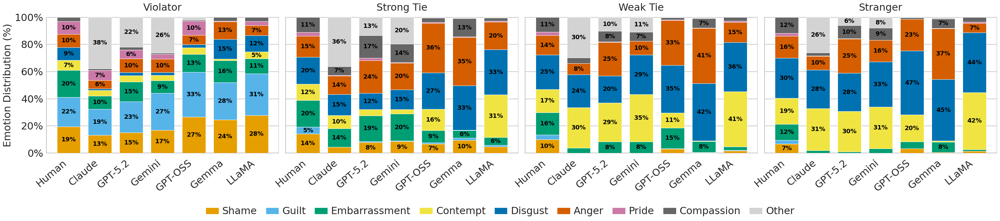

In [126]:
# --------------------------------------------------
# Font sizes
# --------------------------------------------------
fontsize = 23
YLABEL_FONTSIZE = fontsize
TICK_FONTSIZE = fontsize
TITLE_FONTSIZE = fontsize
LEGEND_TITLE_FONTSIZE = fontsize
LEGEND_LABEL_FONTSIZE = fontsize

# ----------------------------
# Major emotion order
# ----------------------------
emotions = [
    "Shame", "Guilt", "Embarrassment", "Contempt",
    "Disgust", "Anger", "Pride", "Compassion"
]

# major_emotions = [
#     "Shame", "Guilt", "Embarrassment", "Contempt",
#     "Disgust", "Anger", "Pride", "Compassion"
# ]

plot_emotions = emotions + ["Other"]

# ----------------------------
# Colors
# ----------------------------
colors = {
    "Shame": "#E69F00",
    "Guilt": "#56B4E9",
    "Embarrassment": "#009E73",
    "Contempt": "#F0E442",
    "Disgust": "#0072B2",
    "Anger": "#D55E00",
    "Pride": "#CC79A7",
    "Compassion": "#666666",
    "Other": "#D3D3D3"
}

# ----------------------------
# Model dictionary
# ----------------------------
models = {
    "gemini": df_emotions[df_emotions["label_type"] == "gemini"],
    "gpt_5.2": df_emotions[df_emotions["label_type"] == "gpt_5.2"],
    "claude": df_emotions[df_emotions["label_type"] == "claude"],
    "gpt_oss": df_emotions[df_emotions["label_type"] == "gpt_oss"],
    "gemma": df_emotions[df_emotions["label_type"] == "gemma"],
    "llama": df_emotions[df_emotions["label_type"] == "llama"],
    "human": df_emotions[df_emotions["label_type"] == "human"],
}

# ----------------------------
# Define which models get "Other"
# ----------------------------
all_models = {"gemini", "gpt_5.2", "claude", "gpt_oss", "llama", "gemma"}

pretty_names = {
    "gemini": "Gemini",
    "gpt_5.2": "GPT-5.2",
    "claude": "Claude",
    "gpt_oss": "GPT-OSS",
    "gemma": "Gemma",
    "llama": "LLaMA",
    "human": "Human"
}

# ----------------------------
# Totals
# ----------------------------
totals = {}

for name, df in models.items():
    totals[name] = {
        "self": df["self_emotion_list"].apply(len).sum(),
        "friend": df["other_emotion_list"].apply(lambda x: len(x[0]) if isinstance(x, list) else 0).sum(),
        "acquaintance": df["other_emotion_list"].apply(lambda x: len(x[1]) if isinstance(x, list) else 0).sum(),
        "stranger": df["other_emotion_list"].apply(lambda x: len(x[2]) if isinstance(x, list) else 0).sum(),
    }

# ----------------------------
# Counts of the 8 major emotions only
# count_emotions(...) should return counts for these major emotions
# ----------------------------
counts = {}

for name, df in models.items():
    counts[name] = {
        "self": count_emotions(df["self_emotion_list"]),
        "friend": count_emotions(get_observer_emotions(df, 0)),
        "acquaintance": count_emotions(get_observer_emotions(df, 1)),
        "stranger": count_emotions(get_observer_emotions(df, 2)),
    }

# ----------------------------
# Convert counts -> proportions
# ----------------------------
def to_proportions(counts_dict, total, include_other=False):
    # major emotions
    props = {
        emo: counts_dict.get(emo, 0) / total if total > 0 else 0
        for emo in emotions
    }

    # "Other" only for selected models, computed from actual counts
    if include_other:
        counted_major = sum(counts_dict.get(emo, 0) for emo in emotions)
        other_count = max(0, total - counted_major)
        props["Other"] = other_count / total if total > 0 else 0
    else:
        props["Other"] = 0

    return props

# ----------------------------
# Build DataFrame for one model
# ----------------------------
def build_df(model_name):
    include_other = model_name in all_models

    data = {
        "Violator": to_proportions(
            counts[model_name]["self"],
            totals[model_name]["self"],
            include_other=include_other
        ),
        "Strong Tie": to_proportions(
            counts[model_name]["friend"],
            totals[model_name]["friend"],
            include_other=include_other
        ),
        "Weak Tie": to_proportions(
            counts[model_name]["acquaintance"],
            totals[model_name]["acquaintance"],
            include_other=include_other
        ),
        "Stranger": to_proportions(
            counts[model_name]["stranger"],
            totals[model_name]["stranger"],
            include_other=include_other
        ),
    }

    df_plot = pd.DataFrame(data)
    df_plot = df_plot.reindex(plot_emotions).fillna(0)
    return df_plot

# ----------------------------
# Build plot DataFrames
# ----------------------------
model_order = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]

plot_dfs = {m: build_df(m) for m in model_order}
panels = [(pretty_names[m], plot_dfs[m]) for m in model_order]

# ----------------------------
# Plot settings — 1×4 layout
# ----------------------------
categories = ["Violator", "Strong Tie", "Weak Tie", "Stranger"]
model_order = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]
x = np.arange(len(model_order))
bar_width = 0.75

fig, axes = plt.subplots(1, 4, figsize=(32, 7), sharey=True)

for ax, category in zip(axes, categories):
    bottoms = np.zeros(len(model_order))

    for emo in plot_emotions:
        vals = np.array([plot_dfs[m].loc[emo, category] for m in model_order])
        ax.bar(
            x, vals, bottom=bottoms, width=bar_width,
            color=colors[emo], edgecolor="white",
            linewidth=0.8, label=emo, zorder=3,
        )

        for i, (v, b) in enumerate(zip(vals, bottoms)):
            if v >= 0.05:
                ax.text(
                    x[i], b + v / 2, f"{v * 100:.0f}%",
                    ha="center", va="center", fontsize=14,
                    fontweight="bold", color="black", zorder=4,
                )

        bottoms += vals

    ax.set_title(category, fontsize=TITLE_FONTSIZE, pad=15)
    if ax == axes[0]:
        ax.set_ylabel("Emotion Distribution (%)", fontsize=YLABEL_FONTSIZE)

    ax.set_xticks(x)
    ax.set_xticklabels(
        [pretty_names[m] for m in model_order],
        rotation=40, ha="right", fontsize=TICK_FONTSIZE,
    )
    ax.tick_params(axis="x", pad=8)

    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)

    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

    ax.spines["left"].set_visible(True)
    ax.spines["left"].set_color("#bfbfbf")
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_color("#bfbfbf")
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["top"].set_visible(True)
    ax.spines["top"].set_color("#cfcfcf")
    ax.spines["top"].set_linewidth(1.2)
    ax.spines["right"].set_visible(True)
    ax.spines["right"].set_color("#cfcfcf")
    ax.spines["right"].set_linewidth(1.2)

# Legend at top, horizontal
handles, labels = axes[0].get_legend_handles_labels()
legend = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.0),
    ncol=len(plot_emotions), frameon=False,
    handlelength=3, handleheight=2,
    # handletextpad=0.5, columnspacing=1.0,
)
# Vertically align color boxes with text
for handle in legend.legend_handles:
    handle.set_y(handle.get_y() + 4)

legend.get_title().set_fontsize(LEGEND_TITLE_FONTSIZE)
for text in legend.get_texts():
    text.set_fontsize(LEGEND_LABEL_FONTSIZE)

fig.tight_layout(rect=[0, 0.02, 1, 0.93])
plt.subplots_adjust(wspace=0.03)
fig.savefig(os.path.join(figure_output_path, "emotion_dist.png"), dpi=300, bbox_inches="tight")
plt.show()

## Table

In [127]:
# Build the table for each model
def build_emotion_table(df_model, emotions, model_name):
    """
    Returns a DataFrame with rows = emotions,
    columns = Men, Women, Strong Tie, Weak Tie, Stranger
    Values = "XX.X% (count)"
    """
    # Split by gender for self (violator)
    df_male = df_model[df_model["actor_gender"] == "male"]
    df_female = df_model[df_model["actor_gender"] == "female"]

    # Count emotions
    def count_and_proportion(emotion_series, total_label="total"):
        all_emotions = [e for sublist in emotion_series for e in sublist]
        total = len(all_emotions)
        counts = pd.Series(all_emotions).value_counts()
        return counts, total

    results = {}

    # --- Violator by gender ---
    male_counts, male_total = count_and_proportion(df_male["self_emotion_list"])
    female_counts, female_total = count_and_proportion(df_female["self_emotion_list"])

    # --- Observers (all genders combined) ---
    friend_emotions = get_observer_emotions(df_model, 0)
    acq_emotions = get_observer_emotions(df_model, 1)
    stranger_emotions = get_observer_emotions(df_model, 2)

    friend_all = [e for sublist in friend_emotions for e in sublist]
    acq_all = [e for sublist in acq_emotions for e in sublist]
    stranger_all = [e for sublist in stranger_emotions for e in sublist]

    friend_counts = pd.Series(friend_all).value_counts()
    acq_counts = pd.Series(acq_all).value_counts()
    stranger_counts = pd.Series(stranger_all).value_counts()

    friend_total = len(friend_all)
    acq_total = len(acq_all)
    stranger_total = len(stranger_all)

    rows = []
    for emo in emotions:
        mc = male_counts.get(emo, 0)
        fc = female_counts.get(emo, 0)
        frc = friend_counts.get(emo, 0)
        ac = acq_counts.get(emo, 0)
        sc = stranger_counts.get(emo, 0)

        rows.append({
            "Emotion": emo,
            "Men": f"{mc/male_total*100:.1f}% ({mc})" if male_total > 0 else "0.0% (0)",
            "Women": f"{fc/female_total*100:.1f}% ({fc})" if female_total > 0 else "0.0% (0)",
            "Strong Tie": f"{frc/friend_total*100:.1f}% ({frc})" if friend_total > 0 else "0.0% (0)",
            "Weak Tie": f"{ac/acq_total*100:.1f}% ({ac})" if acq_total > 0 else "0.0% (0)",
            "Stranger": f"{sc/stranger_total*100:.1f}% ({sc})" if stranger_total > 0 else "0.0% (0)",
        })

    return pd.DataFrame(rows).set_index("Emotion")


# Generate tables for all models
emotions = [
    "Shame", "Guilt", "Embarrassment", "Contempt",
    "Disgust", "Anger", "Pride", "Compassion"
]

model_names = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]

for model_name in model_names:
    df_model = df_emotions[df_emotions["label_type"] == model_name]
    table = build_emotion_table(df_model, emotions, model_name)

    print(f"\n{'='*80}")
    print(f"  {pretty_names[model_name]}")
    print(f"{'='*80}")
    display(table)


  Human


,Men,Women,Strong Tie,Weak Tie,Stranger
Emotion,,,,,
Shame,20.1% (549),18.9% (520),14.1% (757),9.9% (432),6.8% (265)
Guilt,21.8% (597),21.6% (594),5.0% (269),3.6% (159),2.6% (100)
Embarrassment,20.0% (547),19.6% (539),19.7% (1062),16.3% (716),11.9% (465)
Contempt,6.8% (185),8.2% (226),11.9% (640),17.1% (750),19.0% (740)
Disgust,9.6% (263),9.3% (255),19.9% (1070),25.3% (1111),29.7% (1156)
Anger,9.3% (256),10.0% (276),15.4% (827),14.2% (624),16.1% (627)
Pride,9.7% (265),9.4% (259),2.8% (149),2.6% (113),2.2% (86)
Compassion,2.8% (76),3.2% (87),11.2% (604),10.9% (479),11.8% (458)



  Claude


,Men,Women,Strong Tie,Weak Tie,Stranger
Emotion,,,,,
Shame,13.4% (119),12.7% (121),4.4% (122),0.0% (0),0.0% (0)
Guilt,19.7% (175),19.0% (181),0.0% (1),0.0% (0),0.0% (0)
Embarrassment,9.2% (82),9.8% (93),13.6% (379),3.7% (68),1.9% (25)
Contempt,3.7% (33),4.6% (44),9.7% (270),29.8% (545),30.9% (404)
Disgust,0.9% (8),1.3% (12),15.4% (427),24.2% (443),28.4% (372)
Anger,6.5% (58),6.2% (59),13.6% (377),8.2% (150),10.1% (132)
Pride,7.7% (68),6.8% (65),0.5% (14),0.1% (2),0.2% (2)
Compassion,0.9% (8),1.6% (15),6.6% (183),4.2% (76),2.4% (32)



  GPT-5.2


,Men,Women,Strong Tie,Weak Tie,Stranger
Emotion,,,,,
Shame,15.7% (175),14.3% (165),7.9% (216),0.0% (0),0.0% (0)
Guilt,22.4% (249),23.2% (268),0.7% (20),0.0% (0),0.0% (0)
Embarrassment,13.4% (149),15.8% (183),18.9% (519),8.3% (187),1.0% (16)
Contempt,5.0% (56),4.3% (50),4.5% (122),28.7% (648),29.7% (493)
Disgust,2.2% (25),2.2% (25),12.1% (332),19.9% (449),28.2% (467)
Anger,10.2% (113),10.1% (117),24.0% (657),24.7% (557),25.2% (418)
Pride,7.2% (80),5.8% (67),1.9% (53),0.3% (6),0.1% (2)
Compassion,2.0% (22),2.3% (27),16.6% (455),7.9% (178),9.8% (163)


... (4 outputs left out)


  Gemma


,Men,Women,Strong Tie,Weak Tie,Stranger
Emotion,,,,,
Shame,24.6% (225),24.3% (223),9.5% (166),0.4% (5),0.4% (5)
Guilt,27.1% (248),28.1% (258),1.5% (26),0.1% (2),0.1% (2)
Embarrassment,14.7% (135),17.6% (162),5.7% (99),8.1% (114),7.7% (103)
Contempt,1.2% (11),0.9% (8),0.2% (3),0.5% (7),0.7% (10)
Disgust,14.8% (136),14.4% (132),32.7% (571),42.2% (596),45.4% (610)
Anger,14.6% (134),11.3% (104),35.5% (619),40.5% (572),37.4% (502)
Pride,0.4% (4),0.5% (5),0.5% (8),0.2% (3),0.2% (3)
Compassion,2.5% (23),2.9% (27),13.4% (234),6.9% (97),7.0% (94)



  LLaMA


,Men,Women,Strong Tie,Weak Tie,Stranger
Emotion,,,,,
Shame,29.3% (237),26.3% (209),4.5% (99),1.7% (25),1.4% (16)
Guilt,31.9% (258),29.4% (234),1.2% (26),0.3% (4),0.1% (1)
Embarrassment,9.9% (80),12.2% (97),5.9% (128),2.6% (37),1.1% (13)
Contempt,5.1% (41),5.2% (41),31.2% (681),40.7% (586),42.0% (480)
Disgust,11.6% (94),12.2% (97),33.3% (725),36.1% (520),44.0% (503)
Anger,6.7% (54),8.2% (65),20.3% (443),14.7% (212),7.0% (80)
Pride,3.1% (25),3.1% (25),0.6% (14),0.9% (13),1.0% (11)
Compassion,2.3% (19),3.5% (28),2.5% (55),2.9% (42),3.5% (40)


## Other Emotions

In [128]:
# Collect all unique "other" emotions per model and social distance
for name in ["claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]:
    df_model = models[name]

    print(f"\n{'='*60}")
    print(f"  {pretty_names[name]}")
    print(f"{'='*60}")

    for dist_name, dist_key in [("Violator", "self"), ("Strong Tie", "friend"),
                                 ("Weak Tie", "acquaintance"), ("Stranger", "stranger")]:
        if dist_key == "self":
            all_emos = [e for sublist in df_model["self_emotion_list"] for e in sublist]
        else:
            idx = {"friend": 0, "acquaintance": 1, "stranger": 2}[dist_key]
            observer_emos = get_observer_emotions(df_model, idx)
            all_emos = [e for sublist in observer_emos for e in sublist]

        # Filter to non-major emotions
        other_emos = [e for e in all_emos if e not in emotions]

        if other_emos:
            other_counts = pd.Series(other_emos).value_counts()
            total = len(all_emos)
            print(f"\n  {dist_name} (total={total}, other={len(other_emos)}, {len(other_emos)/total*100:.1f}%):")
            for emo, count in other_counts.items():
                print(f"    {emo}: {count} ({count/total*100:.1f}%)")
        else:
            print(f"\n  {dist_name}: no 'Other' emotions")


  Claude

  Violator (total=1838, other=697, 37.9%):
    Frustration: 80 (4.4%)
    Indifference: 60 (3.3%)
    Satisfaction: 59 (3.2%)
    Relief: 45 (2.4%)
    Amusement: 29 (1.6%)
    Anxiety: 28 (1.5%)
    Excitement: 27 (1.5%)
    Sadness: 27 (1.5%)
    Insecurity: 21 (1.1%)
    Righteousness: 17 (0.9%)
    Entitlement: 15 (0.8%)
    Regret: 14 (0.8%)
    Determination: 14 (0.8%)
    Hurt: 13 (0.7%)
    Fear: 12 (0.7%)
    Jealousy: 12 (0.7%)
    Curiosity: 12 (0.7%)
    Conflict: 11 (0.6%)
    Concern: 11 (0.6%)
    Contentment: 11 (0.6%)
    Defensiveness: 10 (0.5%)
    Justified: 9 (0.5%)
    Conviction: 9 (0.5%)
    Resentment: 8 (0.4%)
    Vindication: 7 (0.4%)
    Disappointment: 7 (0.4%)
    Enjoyment: 7 (0.4%)
    Nervousness: 7 (0.4%)
    Despair: 6 (0.3%)
    Happiness: 5 (0.3%)
    Annoyance: 5 (0.3%)
    Stress: 4 (0.2%)
    Loneliness: 4 (0.2%)
    Confusion: 4 (0.2%)
    Longing: 4 (0.2%)
    Self-loathing: 4 (0.2%)
    Hopelessness: 4 (0.2%)
    Irritation: 3 (0.2%

# Action Distribution

In [129]:
ACTION_ORDER = [
    "Do nothing",
    "Stay away",
    "Gossip",
    "Verbal confrontation",
    "Physical confrontation",
    "Inform authority",
    "Support",
    "Praise",
]

ACTION_COLORS = {
    "Do nothing": "#7f7f7f",
    "Stay away": "#e69f00",
    "Gossip": "#56b4e9",
    "Verbal confrontation": "#009e73",
    "Physical confrontation": "#f0e442",
    "Inform authority": "#0072b2",
    "Support": "#d55e00",
    "Praise": "#cc79a7",
}

## Would

In [130]:
DISTANCE_COLS = {
    "friends_reaction": "Strong tie",
    "acquaintances_reaction": "Weak tie",
    "strangers_reaction": "Stranger",
}

df_long = (
    df_clean[["ID", "label_type", *DISTANCE_COLS.keys()]]
    .melt(
        id_vars=["ID", "label_type"],
        value_vars=DISTANCE_COLS.keys(),
        var_name="distance_raw",
        value_name="action_raw",
    )
    .dropna(subset=["action_raw"])
)

df_long["distance"] = df_long["distance_raw"].map(DISTANCE_COLS)
df_long["action"] = df_long["action_raw"].map(ACTION_CANONICAL_MAP)
df_long = df_long.dropna(subset=["action"])

counts = (
    df_long
    .groupby(["label_type", "distance", "action"])
    .size()
    .reset_index(name="count")
)

# Pad with 0s for all combinations
all_actions = [
    "Do nothing", "Stay away", "Gossip", "Verbal confrontation",
    "Physical confrontation", "Inform authority", "Support", "Praise",
]
all_distances = list(DISTANCE_COLS.values())
all_label_types = df_long["label_type"].unique()

full_idx = pd.MultiIndex.from_product(
    [all_label_types, all_distances, all_actions],
    names=["label_type", "distance", "action"],
)

counts = (
    counts
    .set_index(["label_type", "distance", "action"])
    .reindex(full_idx, fill_value=0)
    .reset_index()
)

counts["percent"] = (
    counts
    .groupby(["label_type", "distance"])["count"]
    .transform(lambda x: x / x.sum() * 100 if x.sum() > 0 else 0)
)

counts

,label_type,distance,action,count,percent
0,human,Strong tie,Do nothing,580,22.196709
1,human,Strong tie,Stay away,162,6.199770
2,human,Strong tie,Gossip,519,19.862227
3,human,Strong tie,Verbal confrontation,848,32.453119
4,human,Strong tie,Physical confrontation,70,2.678913
...,...,...,...,...,...
163,llama,Stranger,Verbal confrontation,0,0.000000
164,llama,Stranger,Physical confrontation,0,0.000000
165,llama,Stranger,Inform authority,4,0.468933
166,llama,Stranger,Support,49,5.744431


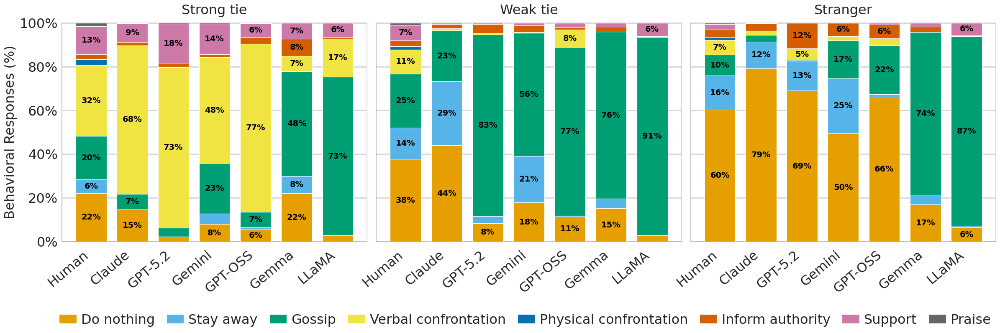

In [131]:
# ----------------------------
# Plot settings — 1×3 layout
# ----------------------------
distances = ["Strong tie", "Weak tie", "Stranger"]
model_order = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]
all_actions = [
    "Do nothing", "Stay away", "Gossip", "Verbal confrontation",
    "Physical confrontation", "Inform authority", "Support", "Praise",
]

pretty_names = {
    "gemini": "Gemini",
    "gpt_5.2": "GPT-5.2",
    "claude": "Claude",
    "gpt_oss": "GPT-OSS",
    "gemma": "Gemma",
    "llama": "LLaMA",
    "human": "Human",
}

action_colors = {
    "Do nothing": "#E69F00",
    "Stay away": "#56B4E9",
    "Gossip": "#009E73",
    "Verbal confrontation": "#F0E442",
    "Physical confrontation": "#0072B2",
    "Inform authority": "#D55E00",
    "Support": "#CC79A7",
    "Praise": "#666666",
}

x = np.arange(len(model_order))
bar_width = 0.75

fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharey=True)

for ax, dist in zip(axes, distances):
    bottoms = np.zeros(len(model_order))

    for action in all_actions:
        vals = []
        for m in model_order:
            row = counts[
                (counts["label_type"] == m)
                & (counts["distance"] == dist)
                & (counts["action"] == action)
            ]
            vals.append(row["percent"].values[0] / 100 if len(row) > 0 else 0)
        vals = np.array(vals)

        ax.bar(
            x, vals, bottom=bottoms, width=bar_width,
            color=action_colors[action], edgecolor="white",
            linewidth=0.8, label=action, zorder=3,
        )

        # Annotate percentages >= 5%
        for i, (v, b) in enumerate(zip(vals, bottoms)):
            if v >= 0.05:
                ax.text(
                    x[i], b + v / 2, f"{v * 100:.0f}%",
                    ha="center", va="center", fontsize=14,
                    fontweight="bold", color="black", zorder=4,
                )

        bottoms += vals

    ax.set_title(dist, fontsize=TITLE_FONTSIZE, pad=15)
    if ax == axes[0]:
      ax.set_ylabel("Behavioral Responses (%)", fontsize=YLABEL_FONTSIZE)

    ax.set_xticks(x)
    ax.set_xticklabels(
        [pretty_names[m] for m in model_order],
        rotation=40, ha="right", fontsize=TICK_FONTSIZE,
    )
    ax.tick_params(axis="x", pad=8)

    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)

    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

    ax.spines["left"].set_visible(True)
    ax.spines["left"].set_color("#bfbfbf")
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_color("#bfbfbf")
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["top"].set_visible(True)
    ax.spines["top"].set_color("#cfcfcf")
    ax.spines["top"].set_linewidth(1.2)
    ax.spines["right"].set_visible(True)
    ax.spines["right"].set_color("#cfcfcf")
    ax.spines["right"].set_linewidth(1.2)

# Legend
handles, labels = axes[0].get_legend_handles_labels()
legend = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.525, 0.0),
    ncol=len(all_actions), frameon=False,
    handlelength=3, handleheight=2,
    # handletextpad=0.5, columnspacing=1.0,
)
# Vertically align color boxes with text
for handle in legend.legend_handles:
    handle.set_y(handle.get_y() + 5)

legend.get_title().set_fontsize(LEGEND_TITLE_FONTSIZE)
for text in legend.get_texts():
    text.set_fontsize(LEGEND_LABEL_FONTSIZE)

fig.tight_layout(rect=[0, 0.02, 1, 0.93])
plt.subplots_adjust(wspace=0.03)
fig.savefig(os.path.join(figure_output_path, "action_would_dist.png"), dpi=300, bbox_inches="tight")
plt.show()

### Table

In [132]:
model_names = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]

all_actions = [
    "Do nothing", "Stay away", "Gossip", "Verbal confrontation",
    "Physical confrontation", "Inform authority", "Support", "Praise",
]
all_distances = ["Strong tie", "Weak tie", "Stranger"]

for model_name in model_names:
    df_model = counts[counts["label_type"] == model_name]

    rows = []
    for action in all_actions:
        row = {"Reaction type": action}

        overall_count = 0
        overall_total = 0

        for dist in all_distances:
            r = df_model[(df_model["action"] == action) & (df_model["distance"] == dist)]
            c = r["count"].values[0] if len(r) > 0 else 0
            p = r["percent"].values[0] if len(r) > 0 else 0.0
            row[dist] = f"{c:,} ({p:.1f}%)"

            overall_count += c
            dist_total = df_model[df_model["distance"] == dist]["count"].sum()
            overall_total += dist_total

        overall_pct = overall_count / overall_total * 100 if overall_total > 0 else 0
        row["Overall"] = f"{overall_count:,} ({overall_pct:.1f}%)"

        rows.append(row)

    table = pd.DataFrame(rows).set_index("Reaction type")

    print(f"\n{'='*80}")
    print(f"  {pretty_names[model_name]}")
    print(f"{'='*80}")
    display(table)


  Human


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,580 (22.2%),986 (37.7%),"1,576 (60.3%)","3,142 (40.1%)"
Stay away,162 (6.2%),374 (14.3%),407 (15.6%),943 (12.0%)
Gossip,519 (19.9%),646 (24.7%),251 (9.6%),"1,416 (18.1%)"
Verbal confrontation,848 (32.5%),287 (11.0%),175 (6.7%),"1,310 (16.7%)"
Physical confrontation,70 (2.7%),38 (1.5%),35 (1.3%),143 (1.8%)
Inform authority,58 (2.2%),73 (2.8%),86 (3.3%),217 (2.8%)
Support,334 (12.8%),182 (7.0%),65 (2.5%),581 (7.4%)
Praise,42 (1.6%),27 (1.0%),18 (0.7%),87 (1.1%)



  Claude


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,125 (14.7%),376 (44.1%),675 (79.1%),"1,176 (46.0%)"
Stay away,1 (0.1%),249 (29.2%),105 (12.3%),355 (13.9%)
Gossip,60 (7.0%),198 (23.2%),25 (2.9%),283 (11.1%)
Verbal confrontation,579 (67.9%),9 (1.1%),17 (2.0%),605 (23.6%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,13 (1.5%),16 (1.9%),29 (3.4%),58 (2.3%)
Support,73 (8.6%),5 (0.6%),2 (0.2%),80 (3.1%)
Praise,2 (0.2%),0 (0.0%),0 (0.0%),2 (0.1%)



  GPT-5.2


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,20 (2.3%),72 (8.4%),589 (69.1%),681 (26.6%)
Stay away,0 (0.0%),28 (3.3%),115 (13.5%),143 (5.6%)
Gossip,34 (4.0%),707 (82.9%),4 (0.5%),745 (29.1%)
Verbal confrontation,626 (73.4%),7 (0.8%),45 (5.3%),678 (26.5%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,17 (2.0%),34 (4.0%),100 (11.7%),151 (5.9%)
Support,152 (17.8%),5 (0.6%),0 (0.0%),157 (6.1%)
Praise,4 (0.5%),0 (0.0%),0 (0.0%),4 (0.2%)


... (4 outputs left out)


  Gemma


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,188 (22.0%),130 (15.2%),145 (17.0%),463 (18.1%)
Stay away,67 (7.9%),37 (4.3%),37 (4.3%),141 (5.5%)
Gossip,409 (47.9%),651 (76.3%),635 (74.4%),"1,695 (66.2%)"
Verbal confrontation,60 (7.0%),0 (0.0%),0 (0.0%),60 (2.3%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,66 (7.7%),20 (2.3%),21 (2.5%),107 (4.2%)
Support,63 (7.4%),15 (1.8%),15 (1.8%),93 (3.6%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)



  LLaMA


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,24 (2.8%),24 (2.8%),55 (6.4%),103 (4.0%)
Stay away,0 (0.0%),0 (0.0%),7 (0.8%),7 (0.3%)
Gossip,619 (72.6%),773 (90.6%),738 (86.5%),"2,130 (83.2%)"
Verbal confrontation,148 (17.4%),0 (0.0%),0 (0.0%),148 (5.8%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,7 (0.8%),4 (0.5%),4 (0.5%),15 (0.6%)
Support,55 (6.4%),52 (6.1%),49 (5.7%),156 (6.1%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


## Should

In [133]:
DISTANCE_COLS = {
    "friends_reaction_should": "Strong tie",
    "acquaintances_reaction_should": "Weak tie",
    "strangers_reaction_should": "Stranger",
}

df_long = (
    df_clean[["ID", "label_type", *DISTANCE_COLS.keys()]]
    .melt(
        id_vars=["ID", "label_type"],
        value_vars=DISTANCE_COLS.keys(),
        var_name="distance_raw",
        value_name="action_raw",
    )
    .dropna(subset=["action_raw"])
)

df_long["distance"] = df_long["distance_raw"].map(DISTANCE_COLS)
df_long["action"] = df_long["action_raw"].map(ACTION_CANONICAL_MAP)
df_long = df_long.dropna(subset=["action"])

counts = (
    df_long
    .groupby(["label_type", "distance", "action"])
    .size()
    .reset_index(name="count")
)

# Pad with 0s for all combinations
all_actions = [
    "Do nothing", "Stay away", "Gossip", "Verbal confrontation",
    "Physical confrontation", "Inform authority", "Support", "Praise",
]
all_distances = list(DISTANCE_COLS.values())
all_label_types = df_long["label_type"].unique()

full_idx = pd.MultiIndex.from_product(
    [all_label_types, all_distances, all_actions],
    names=["label_type", "distance", "action"],
)

counts = (
    counts
    .set_index(["label_type", "distance", "action"])
    .reindex(full_idx, fill_value=0)
    .reset_index()
)

counts["percent"] = (
    counts
    .groupby(["label_type", "distance"])["count"]
    .transform(lambda x: x / x.sum() * 100 if x.sum() > 0 else 0)
)

counts

,label_type,distance,action,count,percent
0,human,Strong tie,Do nothing,734,28.090318
1,human,Strong tie,Stay away,154,5.893609
2,human,Strong tie,Gossip,100,3.827019
3,human,Strong tie,Verbal confrontation,1016,38.882511
4,human,Strong tie,Physical confrontation,74,2.831994
...,...,...,...,...,...
163,llama,Stranger,Verbal confrontation,716,83.939039
164,llama,Stranger,Physical confrontation,0,0.000000
165,llama,Stranger,Inform authority,7,0.820633
166,llama,Stranger,Support,50,5.861665


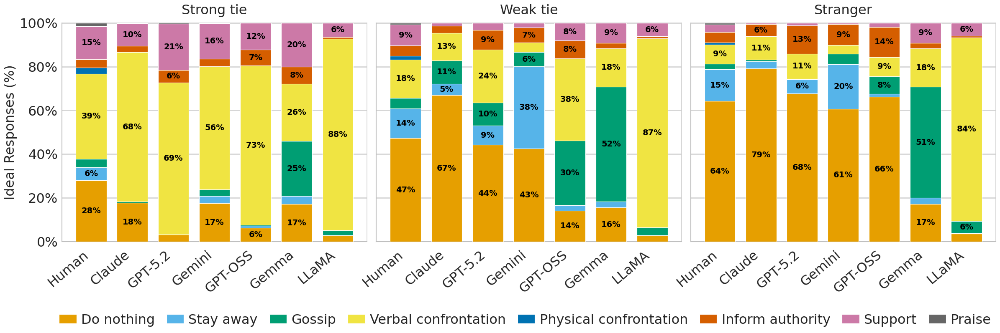

In [134]:
# ----------------------------
# Plot settings — 1×3 layout
# ----------------------------
distances = ["Strong tie", "Weak tie", "Stranger"]
model_order = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]
all_actions = [
    "Do nothing", "Stay away", "Gossip", "Verbal confrontation",
    "Physical confrontation", "Inform authority", "Support", "Praise",
]

pretty_names = {
    "gemini": "Gemini",
    "gpt_5.2": "GPT-5.2",
    "claude": "Claude",
    "gpt_oss": "GPT-OSS",
    "gemma": "Gemma",
    "llama": "LLaMA",
    "human": "Human",
}

action_colors = {
    "Do nothing": "#E69F00",
    "Stay away": "#56B4E9",
    "Gossip": "#009E73",
    "Verbal confrontation": "#F0E442",
    "Physical confrontation": "#0072B2",
    "Inform authority": "#D55E00",
    "Support": "#CC79A7",
    "Praise": "#666666",
}

x = np.arange(len(model_order))
bar_width = 0.75

fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharey=True)

for ax, dist in zip(axes, distances):
    bottoms = np.zeros(len(model_order))

    for action in all_actions:
        vals = []
        for m in model_order:
            row = counts[
                (counts["label_type"] == m)
                & (counts["distance"] == dist)
                & (counts["action"] == action)
            ]
            vals.append(row["percent"].values[0] / 100 if len(row) > 0 else 0)
        vals = np.array(vals)

        ax.bar(
            x, vals, bottom=bottoms, width=bar_width,
            color=action_colors[action], edgecolor="white",
            linewidth=0.8, label=action, zorder=3,
        )

        # Annotate percentages >= 5%
        for i, (v, b) in enumerate(zip(vals, bottoms)):
            if v >= 0.05:
                ax.text(
                    x[i], b + v / 2, f"{v * 100:.0f}%",
                    ha="center", va="center", fontsize=14,
                    fontweight="bold", color="black", zorder=4,
                )

        bottoms += vals

    ax.set_title(dist, fontsize=TITLE_FONTSIZE, pad=15)
    if ax == axes[0]:
      ax.set_ylabel("Ideal Responses (%)", fontsize=YLABEL_FONTSIZE)

    ax.set_xticks(x)
    ax.set_xticklabels(
        [pretty_names[m] for m in model_order],
        rotation=40, ha="right", fontsize=TICK_FONTSIZE,
    )
    ax.tick_params(axis="x", pad=8)

    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)

    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

    ax.spines["left"].set_visible(True)
    ax.spines["left"].set_color("#bfbfbf")
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_color("#bfbfbf")
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["top"].set_visible(True)
    ax.spines["top"].set_color("#cfcfcf")
    ax.spines["top"].set_linewidth(1.2)
    ax.spines["right"].set_visible(True)
    ax.spines["right"].set_color("#cfcfcf")
    ax.spines["right"].set_linewidth(1.2)

# Legend
handles, labels = axes[0].get_legend_handles_labels()
legend = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.525, 0.0),
    ncol=len(all_actions), frameon=False,
    handlelength=3, handleheight=2,
    # handletextpad=0.5, columnspacing=1.0,
)
# Vertically align color boxes with text
for handle in legend.legend_handles:
    handle.set_y(handle.get_y() + 5)

legend.get_title().set_fontsize(LEGEND_TITLE_FONTSIZE)
for text in legend.get_texts():
    text.set_fontsize(LEGEND_LABEL_FONTSIZE)

fig.tight_layout(rect=[0, 0.02, 1, 0.93])
plt.subplots_adjust(wspace=0.03)
fig.savefig(os.path.join(figure_output_path, "action_should_dist.png"), dpi=300, bbox_inches="tight")
plt.show()

### Table

In [135]:
model_names = ["human", "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]

all_actions = [
    "Do nothing", "Stay away", "Gossip", "Verbal confrontation",
    "Physical confrontation", "Inform authority", "Support", "Praise",
]
all_distances = ["Strong tie", "Weak tie", "Stranger"]

for model_name in model_names:
    df_model = counts[counts["label_type"] == model_name]

    rows = []
    for action in all_actions:
        row = {"Reaction type": action}

        overall_count = 0
        overall_total = 0

        for dist in all_distances:
            r = df_model[(df_model["action"] == action) & (df_model["distance"] == dist)]
            c = r["count"].values[0] if len(r) > 0 else 0
            p = r["percent"].values[0] if len(r) > 0 else 0.0
            row[dist] = f"{c:,} ({p:.1f}%)"

            overall_count += c
            dist_total = df_model[df_model["distance"] == dist]["count"].sum()
            overall_total += dist_total

        overall_pct = overall_count / overall_total * 100 if overall_total > 0 else 0
        row["Overall"] = f"{overall_count:,} ({overall_pct:.1f}%)"

        rows.append(row)

    table = pd.DataFrame(rows).set_index("Reaction type")

    print(f"\n{'='*80}")
    print(f"  {pretty_names[model_name]}")
    print(f"{'='*80}")
    display(table)


  Human


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,734 (28.1%),"1,236 (47.3%)","1,678 (64.2%)","3,648 (46.5%)"
Stay away,154 (5.9%),355 (13.6%),379 (14.5%),888 (11.3%)
Gossip,100 (3.8%),125 (4.8%),68 (2.6%),293 (3.7%)
Verbal confrontation,"1,016 (38.9%)",459 (17.6%),228 (8.7%),"1,703 (21.7%)"
Physical confrontation,74 (2.8%),45 (1.7%),23 (0.9%),142 (1.8%)
Inform authority,101 (3.9%),123 (4.7%),125 (4.8%),349 (4.5%)
Support,394 (15.1%),247 (9.5%),93 (3.6%),734 (9.4%)
Praise,40 (1.5%),23 (0.9%),19 (0.7%),82 (1.0%)



  Claude


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,151 (17.7%),571 (66.9%),675 (79.1%),"1,397 (54.6%)"
Stay away,0 (0.0%),44 (5.2%),28 (3.3%),72 (2.8%)
Gossip,5 (0.6%),92 (10.8%),7 (0.8%),104 (4.1%)
Verbal confrontation,583 (68.3%),107 (12.5%),90 (10.6%),780 (30.5%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,24 (2.8%),27 (3.2%),47 (5.5%),98 (3.8%)
Support,88 (10.3%),12 (1.4%),6 (0.7%),106 (4.1%)
Praise,2 (0.2%),0 (0.0%),0 (0.0%),2 (0.1%)



  GPT-5.2


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,28 (3.3%),377 (44.2%),578 (67.8%),983 (38.4%)
Stay away,0 (0.0%),76 (8.9%),55 (6.4%),131 (5.1%)
Gossip,0 (0.0%),89 (10.4%),2 (0.2%),91 (3.6%)
Verbal confrontation,592 (69.4%),206 (24.2%),98 (11.5%),896 (35.0%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,49 (5.7%),77 (9.0%),110 (12.9%),236 (9.2%)
Support,181 (21.2%),27 (3.2%),10 (1.2%),218 (8.5%)
Praise,3 (0.4%),1 (0.1%),0 (0.0%),4 (0.2%)


... (4 outputs left out)


  Gemma


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,146 (17.1%),133 (15.6%),147 (17.2%),426 (16.6%)
Stay away,31 (3.6%),24 (2.8%),24 (2.8%),79 (3.1%)
Gossip,215 (25.2%),447 (52.4%),432 (50.6%),"1,094 (42.8%)"
Verbal confrontation,223 (26.1%),150 (17.6%),150 (17.6%),523 (20.4%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,67 (7.9%),21 (2.5%),22 (2.6%),110 (4.3%)
Support,171 (20.0%),78 (9.1%),78 (9.1%),327 (12.8%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)



  LLaMA


,Strong tie,Weak tie,Stranger,Overall
Reaction type,,,,
Do nothing,24 (2.8%),24 (2.8%),31 (3.6%),79 (3.1%)
Stay away,0 (0.0%),0 (0.0%),1 (0.1%),1 (0.0%)
Gossip,20 (2.3%),31 (3.6%),48 (5.6%),99 (3.9%)
Verbal confrontation,747 (87.6%),738 (86.5%),716 (83.9%),"2,201 (86.0%)"
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,7 (0.8%),7 (0.8%),7 (0.8%),21 (0.8%)
Support,55 (6.4%),53 (6.2%),50 (5.9%),158 (6.2%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


# Co-occuring Emotions

In [136]:
df_human = df_all[(df_all["rater_group"] == "human")].reset_index(drop=True).copy()
df_human

,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,strength_value,moral_foundation,rot_agree,action_agree,human_id,gender,age,race,education,rater_group
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
2,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
3,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
4,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree",human
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83611,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,0,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human
83612,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,0,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human
83613,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,1,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human
83614,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,human,"Shame, Embarrassment",Disgust,Do nothing,Do nothing,Disgust,...,0,sancticity-degradation,2,2,R_7HsettKvGuSvQpb,Female,65.0,White or Caucasian,High school diploma or GED,human


In [137]:
EMOTIONS = major_emotions

# Union logic: emotion is "selected" if ANY observer type has strength > 0
def union_agg(x):
    """Take mean of non-zero values; if all zero, return 0."""
    non_zero = x[x > 0]
    # If selected by multiple observers with different strengths, take MEAN of non-zero values
    # If all observers have strength 0 for that emotion → 0
    return non_zero.mean() if len(non_zero) > 0 else 0.0

# SELF vector: emotion_type == 'emotion_actor'
df_self = df_human[df_human['emotion_type'] == 'emotion_actor'].copy()

human_self_X = (
    df_self.pivot_table(
        index=['ID', 'human_id'],
        columns='emotion',
        values='strength_value',
        aggfunc=union_agg,  # only one row per (ID, human_id, emotion) for actor
        fill_value=0
    )
    .reindex(columns=EMOTIONS, fill_value=0)
)

# OTHER vectors: emotion_type != 'emotion_actor'
df_other = df_human[df_human['emotion_type'] != 'emotion_actor'].copy()

df_other_stage1 = (
    df_other.groupby(['ID', 'human_id', 'emotion', 'emotion_type'])['strength_value']
    .agg(union_agg)
    .reset_index()
)

# Aggregate across observer types per (ID, emotion)
human_other_X = (
    df_other_stage1.pivot_table(
        index=['ID', 'human_id'],
        columns='emotion',
        values='strength_value',
        aggfunc=union_agg,  # union across friend/acquaintance/stranger
        fill_value=0
    )
    .reindex(columns=EMOTIONS, fill_value=0)
)

print("human_self_X shape:", human_self_X.shape)   # (n_pairs, 8)
print("human_other_X shape:", human_other_X.shape)  # (n_pairs, 8)

human_self_X shape: (2611, 8)
human_other_X shape: (2611, 8)


In [138]:
llm_self_vectors = {}
llm_other_vectors = {}

for label in ["gpt_5.2", "claude", "gemini", "gpt_oss", "llama", "gemma"]:
    df_sub = df_all[df_all["label_type"] == label].copy()

    # SELF: emotion_actor
    df_self = df_sub[df_sub['emotion_type'] == 'emotion_actor']
    llm_self_X = (
            df_self.pivot_table(
                index='ID',
                columns='emotion',
                values='strength_value',
                aggfunc=union_agg,  # mean of non-zero values, 0 if all zero
                fill_value=0
            )
            .reindex(columns=EMOTIONS, fill_value=0)
        )

    # OTHER: union across friend/acquaintance/stranger
    df_other = df_sub[df_sub['emotion_type'] != 'emotion_actor']

    df_other_stage1 = (
        df_other.groupby(['ID', 'emotion', 'emotion_type'])['strength_value']
        .agg(union_agg)
        .reset_index()
    )

    # Aggregate across observer types per (ID, emotion)
    llm_other_X = (
        df_other_stage1.pivot_table(
            index='ID',
            columns='emotion',
            values='strength_value',
            aggfunc=union_agg,  # union across friend/acquaintance/stranger
            fill_value=0
        )
        .reindex(columns=EMOTIONS, fill_value=0)
    )

    llm_self_vectors[label] = llm_self_X
    llm_other_vectors[label] = llm_other_X

    print(f"{label} — self: {llm_self_X.shape}, other: {llm_other_X.shape}")

gpt_5.2 — self: (450, 8), other: (450, 8)
claude — self: (450, 8), other: (450, 8)
gemini — self: (450, 8), other: (450, 8)
gpt_oss — self: (450, 8), other: (450, 8)
llama — self: (450, 8), other: (450, 8)
gemma — self: (450, 8), other: (450, 8)


In [139]:
def corr_with_pvalues(X, emotions, method='spearmanr'):
    """
    Compute pairwise correlation with p-values for continuous intensity vectors.
    method: 'pearson' or 'spearman'
    """
    n = len(emotions)
    corr = np.zeros((n, n))
    pvals = np.ones((n, n))

    corr_func = pearsonr if method == 'pearson' else spearmanr

    for i in range(n):
        for j in range(n):
            x = X[:, i]
            y = X[:, j]

            # handle constant vectors
            if np.std(x) == 0 or np.std(y) == 0:
                corr[i, j] = np.nan
                pvals[i, j] = np.nan
                continue

            r, p = corr_func(x, y)
            corr[i, j] = r
            pvals[i, j] = p

    return (
        pd.DataFrame(corr, index=emotions, columns=emotions),
        pd.DataFrame(pvals, index=emotions, columns=emotions)
    )

# Compute correlations
corr_human_self, _ = corr_with_pvalues(human_self_X.values, EMOTIONS)
corr_human_other, _ = corr_with_pvalues(human_other_X.values, EMOTIONS)

corr_llm_self = {}
corr_llm_other = {}
for label in ["gpt_5.2", "claude", "gemini", "gpt_oss", "llama", "gemma"]:
    corr_llm_self[label], _ = corr_with_pvalues(llm_self_vectors[label].values, EMOTIONS)
    corr_llm_other[label], _ = corr_with_pvalues(llm_other_vectors[label].values, EMOTIONS)

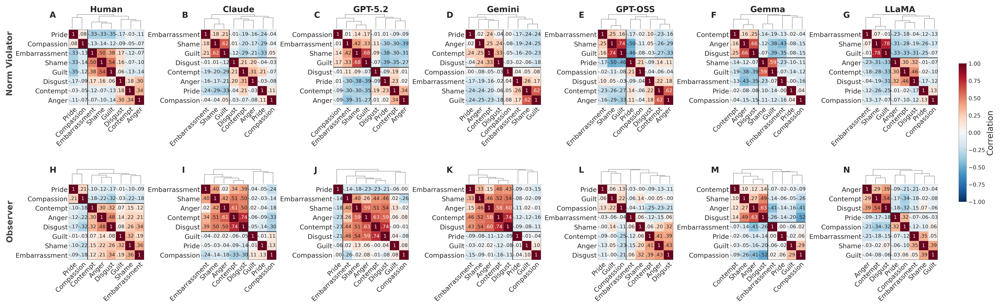

In [140]:
# Settings
plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.sans-serif":    ["Helvetica", "Arial", "DejaVu Sans"],
    "axes.linewidth":     0.6,
    "figure.dpi":         150,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.3,
    "pdf.fonttype":       42,
    "ps.fonttype":        42,
})

def reorder_matrix(mat, order):
    return mat.loc[order, order]

row_names = ["Human", "Claude", "GPT-5.2", "Gemini", "GPT-OSS",  "Gemma", "LLaMA"]
row_keys  = [None, "claude", "gpt_5.2", "gemini", "gpt_oss", "gemma", "llama"]

raw_grid = []  # list of (title, mat) in row-major order for 2×7
for name, key in zip(row_names, row_keys):
    if key is None:
        raw_grid.append(("Norm Violator", corr_human_self))
    else:
        raw_grid.append(("Norm Violator", corr_llm_self[key]))

for name, key in zip(row_names, row_keys):
    if key is None:
        raw_grid.append(("Observer", corr_human_other))
    else:
        raw_grid.append(("Observer", corr_llm_other[key]))

# Global color limits
all_vals = np.concatenate([mat.values.flatten() for _, mat in raw_grid])
vmax = np.nanmax(np.abs(all_vals))
vmin = -vmax

cmap = plt.cm.RdBu_r

PANEL_LABELS = [chr(ord('A') + i) for i in range(14)]

def draw_panel(fig, gs_slot, title, panel_label, mat_orig,
               cmap, vmin, vmax, k_clusters=2, draw_boxes=True):

    n = len(mat_orig)

    dist = 1 - mat_orig.fillna(0)
    dist = (dist + dist.T) / 2
    np.fill_diagonal(dist.values, 0)

    Z = linkage(squareform(dist.values, checks=False), method="average")

    dend_info = dendrogram(Z, labels=mat_orig.index.tolist(), no_plot=True)
    leaf_order = dend_info["ivl"]

    mat = reorder_matrix(mat_orig, leaf_order)

    clusters = fcluster(Z, k_clusters, criterion='maxclust')
    cluster_series = pd.Series(clusters, index=mat_orig.index).loc[leaf_order]
    boundaries = np.where(cluster_series.values[:-1] != cluster_series.values[1:])[0]

    inner = gs_slot.subgridspec(2, 1, height_ratios=[1, 5], hspace=0.02)
    ax_dend = fig.add_subplot(inner[0])
    ax_heat = fig.add_subplot(inner[1])

    plot_data = mat.values.astype(float)

    ax_heat.imshow(
        plot_data, cmap=cmap, vmin=vmin, vmax=vmax,
        aspect="equal", origin="upper", interpolation="nearest",
    )

    for i in range(n + 1):
        ax_heat.axhline(i - 0.5, color="#E0E0E0", linewidth=0.4)
        ax_heat.axvline(i - 0.5, color="#E0E0E0", linewidth=0.4)

    for b in boundaries:
        ax_heat.axhline(b + 0.5, color="#333333", linewidth=2.5)
        ax_heat.axvline(b + 0.5, color="#333333", linewidth=2.5)

    if draw_boxes:
        start = 0
        for b in list(boundaries) + [n - 1]:
            end = b
            ax_heat.add_patch(
                plt.Rectangle(
                    (start - 0.5, start - 0.5),
                    end - start + 1, end - start + 1,
                    fill=False, edgecolor="black", linewidth=1.5
                )
            )
            start = end + 1

    for i in range(n):
        for j in range(n):
            val = mat.iloc[i, j]
            if round(val * 100) == 100:
                txt = "1"
            elif round(val * 100) == -100:
                txt = "-1"
            elif val >= 0:
                txt = f".{int(round(val * 100)):02d}"
            else:
                txt = f"-.{int(round(abs(val) * 100)):02d}"
            text_color = "white" if abs(val) > 0.55 * vmax else "#222222"
            ax_heat.text(j, i, txt, ha="center", va="center",
                         fontsize=18, color=text_color)

    ax_heat.set_xticks(range(n))
    ax_heat.set_xticklabels(leaf_order, fontsize=24,
                            rotation=45, ha="right", rotation_mode="anchor")
    ax_heat.set_yticks(range(n))
    ax_heat.set_yticklabels(leaf_order, fontsize=24)
    ax_heat.tick_params(length=0)
    ax_heat.set_xlim(-0.5, n - 0.5)
    ax_heat.set_ylim(n - 0.5, -0.5)

    for spine in ax_heat.spines.values():
        spine.set_linewidth(0.6)
        spine.set_color("#999999")

    dendrogram(
        Z, labels=mat_orig.index.tolist(), ax=ax_dend,
        color_threshold=0, above_threshold_color="#888888",
        leaf_font_size=0,
    )

    for coll in ax_dend.collections:
        for path in coll.get_paths():
            path.vertices[:, 0] = (path.vertices[:, 0] - 5) / 10.0

    ax_dend.set_xlim(-1.5, n + 0.5)
    ax_dend.set_xticks([])
    ax_dend.set_yticks([])

    for spine in ax_dend.spines.values():
        spine.set_visible(False)

    ax_dend.set_title(title, fontsize=30, fontweight="bold", pad=6)
    ax_dend.text(-0.08, 1.15, panel_label,
                 transform=ax_dend.transAxes,
                 fontsize=30, fontweight="bold", va="top")

    return ax_heat

# Figure: 2 rows × 7 cols
fig = plt.figure(figsize=(49, 14))
outer = gridspec.GridSpec(
    2, 7, figure=fig,
    hspace=0.7, wspace=0.35,
    left=0.04, right=0.96,
    top=0.93, bottom=0.04,
)

for idx in range(14):
    row, col = divmod(idx, 7)
    # Column titles (source names) only on first row
    title = row_names[col] if row == 0 else ""
    _, mat_orig = raw_grid[idx]

    draw_panel(
        fig, outer[row, col], title, PANEL_LABELS[idx],
        mat_orig, cmap, vmin, vmax,
        k_clusters=2, draw_boxes=True
    )

# Row labels (perspective) on the left
perspective_labels = ["Norm Violator", "Observer"]
for i, label in enumerate(perspective_labels):
    y = 1 - (i + 0.5) / 2
    y -= i * 0.07  # slight adjustment
    fig.text(-0.009, y, label, fontsize=30, fontweight="bold",
             rotation=90, ha="center", va="center", color="#444444")

# Colorbar
cbar_ax = fig.add_axes([0.97, 0.25, 0.008, 0.50])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.ax.tick_params(labelsize=20)
cbar.outline.set_linewidth(0.6)
cbar.set_label("Correlation", fontsize=30)
fig.savefig(os.path.join(figure_output_path, "emotion_corr_llm.png"), dpi=300, bbox_inches="tight")
plt.show()

# Emotion Intensity Distribution

In [141]:
df_all_human = df_all.loc[df_all['rater_group'] == 'human']
df_llms = {}

for label in ["gpt_5.2", "claude", "gemini", "gpt_oss", "llama", "gemma"]:
    df_llms[label] = df_all[df_all["label_type"] == label].copy()

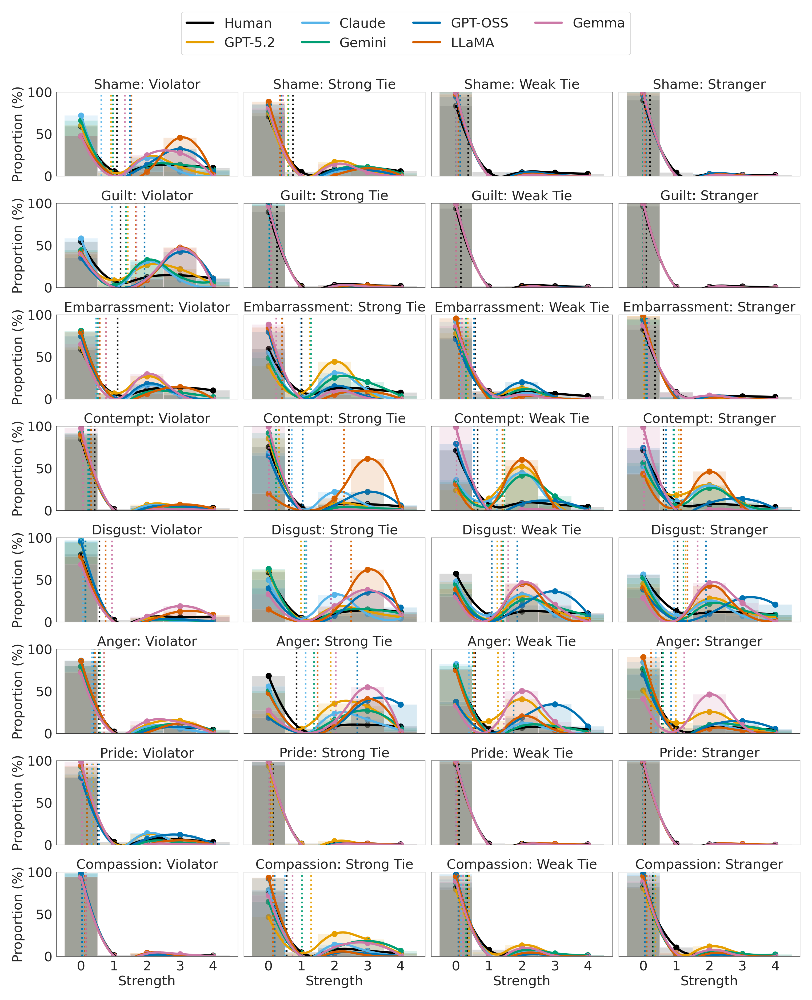

In [142]:
# -----------------------------
# Style
# -----------------------------
FONT_SIZE = 24
LINE_WIDTH = 4
MARKER_SIZE = 10
SMOOTH_POINTS = 200

FIG_WIDTH = 20
FIG_HEIGHT = 24

# -----------------------------
ordered_emotions = [
    "Shame", "Guilt", "Embarrassment",
    "Contempt", "Disgust", "Anger", "Pride", "Compassion"
]

emotion_columns = [
    ("emotion_actor", "Violator"),
    ("emotion_friend", "Strong Tie"),
    ("emotion_acquaintance", "Weak Tie"),
    ("emotion_stranger", "Stranger")
]

# -----------------------------
fig, axes = plt.subplots(
    nrows=len(ordered_emotions),
    ncols=len(emotion_columns),
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    sharey=True
)

# -----------------------------
datasets = {
    "Human": df_all_human,
    "GPT-5.2": df_llms["gpt_5.2"],
    "Claude": df_llms["claude"],
    "Gemini": df_llms["gemini"],
    "GPT-OSS": df_llms["gpt_oss"],
    "LLaMA": df_llms["llama"],
    "Gemma": df_llms["gemma"],
}

colors = {
    "Human": "#000000",
    "GPT-5.2": "#E69F00",
    "Claude": "#56B4E9",
    "Gemini": "#009E73",
    "GPT-OSS": "#0072B2",
    "LLaMA": "#D55E00",
    "Gemma": "#CC79A7",
}

bins = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
centers = np.array([0, 1, 2, 3, 4])

# -----------------------------
for row, emotion in enumerate(ordered_emotions):

    for col, (emotion_type, label_name) in enumerate(emotion_columns):

        ax = axes[row, col]

        for label, df in datasets.items():

            subset = df.loc[
                (df["emotion"] == emotion) &
                (df["emotion_type"] == emotion_type),
                "strength_value"
            ]

            if len(subset) == 0:
                continue

            # -----------------------------
            weights = np.ones_like(subset) * (100.0 / len(subset))

            ax.hist(
                subset,
                bins=bins,
                weights=weights,
                color=colors[label],
                alpha=0.15,
                edgecolor=None
            )

            # -----------------------------
            counts, _ = np.histogram(subset, bins=bins)
            proportions = counts / counts.sum() * 100

            x_new = np.linspace(centers.min(), centers.max(), SMOOTH_POINTS)
            spline = make_interp_spline(centers, proportions, k=2)
            y_smooth = spline(x_new)

            ax.plot(
                x_new,
                y_smooth,
                color=colors[label],
                linewidth=LINE_WIDTH,
                label=label if (row == 0 and col == 0) else None
            )

            ax.scatter(
                centers,
                proportions,
                color=colors[label],
                s=MARKER_SIZE**2
            )

            # -----------------------------
            mean_val = subset.mean()

            ax.axvline(
                x=mean_val,
                color=colors[label],
                linestyle=":",
                linewidth=3,
                alpha=0.9
            )

        # -----------------------------
        ax.set_title(f"{emotion}: {label_name}", fontsize=FONT_SIZE)

        if col == 0:
            ax.set_ylabel("Proportion (%)", fontsize=FONT_SIZE)

        if row == len(ordered_emotions) - 1:
            ax.set_xlabel("Strength", fontsize=FONT_SIZE)

        ax.set_xticks([0, 1, 2, 3, 4])
        ax.set_ylim(0, 100)
        ax.tick_params(axis='both', labelsize=FONT_SIZE)

# -----------------------------
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    fontsize=FONT_SIZE,
    bbox_to_anchor=(0.5, 1.03)
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(os.path.join(figure_output_path, "emotion_intensity_llm.png"), dpi=300, bbox_inches="tight")
plt.show()

In [143]:
# -----------------------------
datasets = {
    "Human": df_all_human,
    "GPT-5.2": df_llms["gpt_5.2"],
    "Claude": df_llms["claude"],
    "Gemini": df_llms["gemini"],
    "GPT-OSS": df_llms["gpt_oss"],
    "LLaMA": df_llms["llama"],
    "Gemma": df_llms["gemma"],
}

ordered_emotions = [
    "Shame", "Guilt", "Embarrassment",
    "Contempt", "Disgust", "Anger",
    "Pride", "Compassion"
]

emotion_types = ["emotion_actor", "emotion_friend", "emotion_acquaintance", "emotion_stranger"]

bins_no_zero = [0.5, 1.5, 2.5, 3.5, 4.5]

# -----------------------------
rows = []

for emotion in ordered_emotions:
    for emotion_type in emotion_types:
        row = {"Emotion": emotion, "Level": emotion_type}

        for label, df in datasets.items():
            subset = df.loc[
                (df["emotion"] == emotion) &
                (df["emotion_type"] == emotion_type),
                "strength_value"
            ]

            subset_nz = subset[subset > 0]
            if len(subset_nz) > 0:
                counts_nz, _ = np.histogram(subset_nz, bins=bins_no_zero)
                probs_nz = counts_nz / counts_nz.sum()
                H = entropy(probs_nz, base=2)
            else:
                H = np.nan

            row[label] = round(H, 3)

        rows.append(row)

df_entropy = pd.DataFrame(rows)

# Clean up level names
level_map = {
    "emotion_actor": "Violator",
    "emotion_friend": "Strong Tie",
    "emotion_acquaintance": "Weak Tie",
    "emotion_stranger": "Stranger"
}
df_entropy["Level"] = df_entropy["Level"].map(level_map)
df_entropy

,Emotion,Level,Human,GPT-5.2,Claude,Gemini,GPT-OSS,LLaMA,Gemma
0,Shame,Violator,1.947,1.472,0.959,1.573,1.330,0.639,1.019
1,Shame,Strong Tie,1.953,1.082,1.262,1.438,1.303,0.903,0.964
2,Shame,Weak Tie,1.967,NaN,NaN,NaN,1.177,1.535,0.000
3,Shame,Stranger,1.875,NaN,NaN,NaN,1.225,1.406,0.000
4,Guilt,Violator,1.963,1.689,1.035,1.533,1.337,0.770,0.889
5,Guilt,Strong Tie,1.960,1.279,0.000,0.544,1.273,0.773,0.961
6,Guilt,Weak Tie,1.955,NaN,NaN,NaN,0.918,0.000,0.000
7,Guilt,Stranger,1.955,NaN,NaN,NaN,0.000,0.000,0.000
8,Embarrassment,Violator,1.952,1.186,0.865,1.555,1.150,0.989,0.622
9,Embarrassment,Strong Tie,1.971,1.116,1.130,1.469,1.091,1.110,0.783


## Temperature Experiment

In [ ]:
df_temp = pd.read_csv(PROCESSED / 'NormReact_temperature.csv.gz')
df_temp = df_temp.rename(columns={
    'stimuli_id': 'ID',
    'rater_type': 'label_type',
    'friends_reaction_would': 'friends_reaction',
    'acquaintances_reaction_would': 'acquaintances_reaction',
    'strangers_reaction_would': 'strangers_reaction',
    })
df_human_temp = df_temp.loc[df_temp['label_type'] == 'human']
df_claude = {}

for label in ["claude_0", "claude_05", "claude_1"]:
    df_claude[label] = df_temp[df_temp["label_type"] == label].copy()

In [145]:
datasets = {
    "Human": df_human_temp,
    "Temp = 0": df_claude["claude_0"],
    "Temp = 0.5": df_claude["claude_05"],
    "Temp = 1": df_claude["claude_1"]
}

ordered_emotions = [
    "Shame", "Guilt", "Embarrassment",
    "Contempt", "Disgust", "Anger",
    "Pride", "Compassion"
]

emotion_types = ["emotion_actor", "emotion_friend", "emotion_acquaintance", "emotion_stranger"]

bins_no_zero = [0.5, 1.5, 2.5, 3.5, 4.5]

# -----------------------------
rows = []

for emotion in ordered_emotions:
    for emotion_type in emotion_types:
        row = {"Emotion": emotion, "Level": emotion_type}

        for label, df in datasets.items():
            subset = df.loc[
                (df["emotion"] == emotion) &
                (df["emotion_type"] == emotion_type),
                "strength_value"
            ]

            subset_nz = subset[subset > 0]
            if len(subset_nz) > 0:
                counts_nz, _ = np.histogram(subset_nz, bins=bins_no_zero)
                probs_nz = counts_nz / counts_nz.sum()
                H = entropy(probs_nz, base=2)
            else:
                H = np.nan

            row[label] = round(H, 3)

        rows.append(row)

df_entropy = pd.DataFrame(rows)

# Clean up level names
level_map = {
    "emotion_actor": "Violator",
    "emotion_friend": "Strong Tie",
    "emotion_acquaintance": "Weak Tie",
    "emotion_stranger": "Stranger"
}
df_entropy["Level"] = df_entropy["Level"].map(level_map)
df_entropy

,Emotion,Level,Human,Temp = 0,Temp = 0.5,Temp = 1
0,Shame,Violator,1.947,0.959,1.023,1.022
1,Shame,Strong Tie,1.953,1.262,1.228,1.230
2,Shame,Weak Tie,1.967,NaN,NaN,0.000
3,Shame,Stranger,1.875,NaN,NaN,NaN
4,Guilt,Violator,1.963,1.035,1.021,1.082
5,Guilt,Strong Tie,1.960,0.000,NaN,0.000
6,Guilt,Weak Tie,1.955,NaN,NaN,NaN
7,Guilt,Stranger,1.955,NaN,NaN,NaN
8,Embarrassment,Violator,1.952,0.865,0.893,0.875
9,Embarrassment,Strong Tie,1.971,1.130,1.126,1.161


In [146]:
# Keep only emotion-role pairs with valid entropy for all temperatures
mask = df_entropy[["Human", "Temp = 0", "Temp = 0.5", "Temp = 1"]].notna().all(axis=1)

# Compute absolute distance from human entropy for each temperature
for temp_col in ["Temp = 0", "Temp = 0.5", "Temp = 1"]:
    df_entropy[f"dist_{temp_col}"] = (df_entropy[temp_col] - df_entropy["Human"]).abs()

# Summary: mean distance from human entropy per temperature
print("Mean |H_model - H_human| by temperature:")
for temp_col in ["Temp = 0", "Temp = 0.5", "Temp = 1"]:
    mean_dist = df_entropy.loc[mask, f"dist_{temp_col}"].mean()
    se_dist = df_entropy.loc[mask, f"dist_{temp_col}"].sem()
    print(f"  {temp_col}: {mean_dist:.4f} ± {se_dist:.4f}")

h = df_entropy.loc[mask, "Human"]
m0 = df_entropy.loc[mask, "Temp = 0"]
m05 = df_entropy.loc[mask, "Temp = 0.5"]
m1 = df_entropy.loc[mask, "Temp = 1"]

stat0, p0 = wilcoxon(h, m0, alternative="greater")
stat05, p05 = wilcoxon(h, m05, alternative="greater")
stat1, p1 = wilcoxon(h, m1, alternative="greater")

print(f"\nHuman > Temp=0:   stat={stat0:.2f}, p={p0:.6f}")
print(f"Human > Temp=0.5: stat={stat05:.2f}, p={p05:.6f}")
print(f"Human > Temp=1:   stat={stat1:.2f}, p={p1:.6f}")
print(f"\nN pairs: {mask.sum()}")
print(f"Mean entropy — Human: {h.mean():.3f}, T=0: {m0.mean():.3f}, T=0.5: {m05.mean():.3f}, T=1: {m1.mean():.3f}")

Mean |H_model - H_human| by temperature:
  Temp = 0: 0.8777 ± 0.0736
  Temp = 0.5: 0.8781 ± 0.0704
  Temp = 1: 0.8655 ± 0.0734

Human > Temp=0:   stat=378.00, p=0.000000
Human > Temp=0.5: stat=378.00, p=0.000000
Human > Temp=1:   stat=378.00, p=0.000000

N pairs: 27
Mean entropy — Human: 1.911, T=0: 1.033, T=0.5: 1.032, T=1: 1.045


In [147]:
mask = df_entropy[["dist_Temp = 0", "dist_Temp = 0.5", "dist_Temp = 1"]].notna().all(axis=1)

d0 = df_entropy.loc[mask, "dist_Temp = 0"]
d05 = df_entropy.loc[mask, "dist_Temp = 0.5"]
d1 = df_entropy.loc[mask, "dist_Temp = 1"]

stat, p_val = wilcoxon(d0, d1, alternative="greater")
print(f"Wilcoxon (dist_T0 > dist_T1): stat={stat:.2f}, p={p_val:.4f}")

stat2, p_val2 = wilcoxon(d0, d05, alternative="greater")
print(f"Wilcoxon (dist_T0 > dist_T0.5): stat={stat2:.2f}, p={p_val2:.4f}")

stat3, p_val3 = wilcoxon(d05, d1, alternative="greater")
print(f"Wilcoxon (dist_T0.5 > dist_T1): stat={stat3:.2f}, p={p_val3:.4f}")

Wilcoxon (dist_T0 > dist_T1): stat=170.00, p=0.4200
Wilcoxon (dist_T0 > dist_T0.5): stat=135.50, p=0.7663
Wilcoxon (dist_T0.5 > dist_T1): stat=214.00, p=0.0829


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)


# Wrongness-Inappropriateness

In [148]:
df_clean.columns

Index(['ID', 'stimuli', 'actor', 'actor_gender', 'label_type',
       'actor_emotions', 'friends_emotions', 'friends_reaction',
       'friends_reaction_should', 'acquaintances_emotions',
       'acquaintances_reaction', 'acquaintances_reaction_should',
       'strangers_emotions', 'strangers_reaction', 'strangers_reaction_should',
       'norm_wrongness', 'norm_inappropriateness', 'emotion_type', 'emotion',
       'strength_value', 'moral_foundation', 'rot_agree', 'action_agree',
       'human_id', 'gender', 'age', 'race', 'education', 'rater_group',
       'self_emotion_list', 'other_emotion_list'],
      dtype='object')

In [149]:
wrong = df_clean.groupby(['ID', 'rater_group'])['norm_wrongness'].mean().unstack()
inappr = df_clean.groupby(['ID', 'rater_group'])['norm_inappropriateness'].mean().unstack()

wrong['diff_human_closed'] = wrong['human'] - wrong['closed-source']
wrong['diff_human_open'] = wrong['human'] - wrong['open-source']
inappr['diff_human_closed'] = inappr['human'] - inappr['closed-source']
inappr['diff_human_open'] = inappr['human'] - inappr['open-source']

df_diff = wrong[['diff_human_closed', 'diff_human_open']].merge(
    inappr[['diff_human_closed', 'diff_human_open']],
    left_index=True,
    right_index=True,
    suffixes=('_wrong', '_inappr')
).reset_index()
df_diff

rater_group,ID,diff_human_closed_wrong,diff_human_open_wrong,diff_human_closed_inappr,diff_human_open_inappr
0,1,-0.666667,-0.666667,-0.466667,-0.466667
1,2,2.166667,1.166667,1.166667,0.500000
2,3,2.000000,1.000000,1.666667,1.000000
3,4,0.333333,-0.333333,0.333333,-0.666667
4,5,0.500000,0.166667,0.583333,0.416667
...,...,...,...,...,...
445,447,0.880952,-0.452381,-0.119048,-0.619048
446,448,0.060606,-0.106061,-0.090909,0.075758
447,449,0.666667,0.333333,0.833333,0.666667
448,450,-0.200000,-0.033333,-0.400000,-0.233333


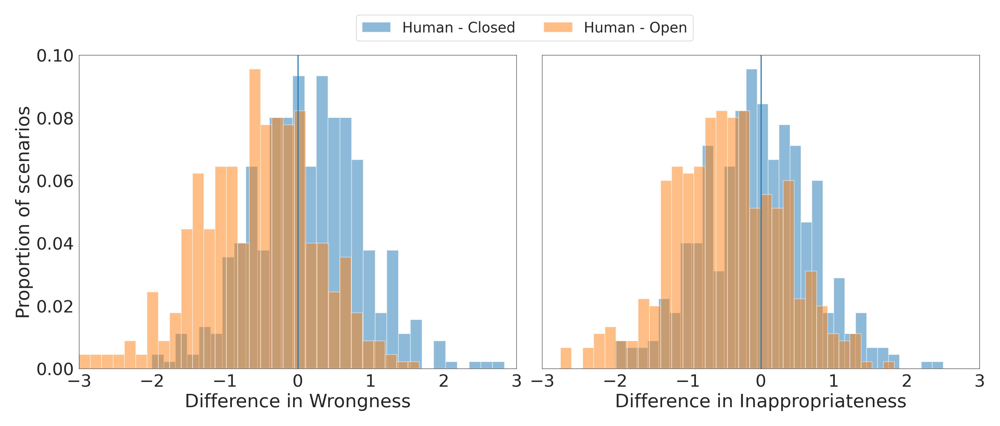

In [150]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)

# ---------- Weights (for proportions) ----------
n = len(df_diff)

weights_closed_wrong = np.ones(len(df_diff['diff_human_closed_wrong'])) / n
weights_open_wrong   = np.ones(len(df_diff['diff_human_open_wrong'])) / n

weights_closed_inappr = np.ones(len(df_diff['diff_human_closed_inappr'])) / n
weights_open_inappr   = np.ones(len(df_diff['diff_human_open_inappr'])) / n

# ---------- Plot 1: Wrongness ----------
h1 = axes[0].hist(
    df_diff['diff_human_closed_wrong'],
    bins=30,
    alpha=0.5,
    weights=weights_closed_wrong,
    label='Human - Closed'
)

h2 = axes[0].hist(
    df_diff['diff_human_open_wrong'],
    bins=30,
    alpha=0.5,
    weights=weights_open_wrong,
    label='Human - Open'
)

axes[0].axvline(0)

axes[0].set_xlim(-3, 3)
axes[0].set_ylim(0, 0.15)

axes[0].set_xticks(np.arange(-3, 4, 1))
axes[0].set_yticks(np.arange(0, 0.151, 0.02))

axes[0].set_xlabel("Difference in Wrongness", fontsize=26)
axes[0].set_ylabel("Proportion of scenarios", fontsize=26)
axes[0].tick_params(axis='both', labelsize=24)

# ---------- Plot 2: Inappropriateness ----------
axes[1].hist(
    df_diff['diff_human_closed_inappr'],
    bins=30,
    alpha=0.5,
    weights=weights_closed_inappr
)

axes[1].hist(
    df_diff['diff_human_open_inappr'],
    bins=30,
    alpha=0.5,
    weights=weights_open_inappr
)

axes[1].axvline(0)

axes[1].set_xlim(-3, 3)
axes[1].set_ylim(0, 0.1)

axes[1].set_xticks(np.arange(-3, 4, 1))
axes[1].set_yticks(np.arange(0, 0.101, 0.02))

axes[1].set_xlabel("Difference in Inappropriateness", fontsize=26)
axes[1].tick_params(axis='both', labelsize=24)

# ---------- Shared legend ----------
legend_x = 0.63  # adjust this to move left/right
legend_y = 1.00 # adjust up/down

fig.legend(
    handles=[h1[2][0], h2[2][0]],
    labels=['Human - Closed', 'Human - Open'],
    loc='upper center',
    bbox_to_anchor=(legend_x, legend_y),
    ncol=2,
    fontsize=20
)

plt.tight_layout(rect=[0, 0, 1.2, 0.92])
fig.savefig(os.path.join(figure_output_path, "wrongness_inappropriateness.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# LLM Benchmarking

In [151]:
df_benchmark = df_clean.loc[(~df_clean['ID'].isin(ids_one_raters))].copy()

In [152]:
(df_benchmark.groupby('ID')['actor_gender'].nunique() == 2).sum()

403

In [153]:
df_benchmark_gender = df_benchmark.copy()

# Preserve original ID
df_benchmark_gender = df_benchmark_gender.rename(columns={"ID": "main_ID"})

# Assign unique ID per main_ID x actor_gender
df_benchmark_gender["ID"] = (
    df_benchmark_gender
    .groupby(["main_ID", "actor_gender"], sort=True)
    .ngroup()
)
df_benchmark_gender['ID'].nunique()

845

In [154]:
df_benchmark[["ID", "actor_gender"]].drop_duplicates().shape[0]

845

## Emotion

In [155]:
SELF_REG = {"shame", "guilt", "embarrassment"}
OTHER_REG = {"contempt", "anger", "disgust"}

def normalize_list(lst):
    if not isinstance(lst, list):
        return []
    out = []
    for x in lst:
        if pd.isna(x):
            continue
        out.append(str(x).strip().lower())
    return out

def has_self_reg(lst):
    lst = normalize_list(lst)
    return int(any(e in SELF_REG for e in lst))

def has_other_reg(lst):
    lst = normalize_list(lst)
    return int(any(e in OTHER_REG for e in lst))

def get_inner_list(x, idx):
    if not isinstance(x, list) or len(x) <= idx:
        return []
    inner = x[idx]
    if not isinstance(inner, list):
        return []
    return inner

def binary_emotions(df):
  # Actor: check self_emotion_list for self-focused emotions
  df["actor_label"] = df["self_emotion_list"].apply(has_self_reg)

  # Friend / acquaintance / stranger: check corresponding inner list for other-focused emotions
  df["friend_label"] = df["other_emotion_list"].apply(
      lambda x: has_other_reg(get_inner_list(x, 0))
  )

  df["acq_label"] = df["other_emotion_list"].apply(
      lambda x: has_other_reg(get_inner_list(x, 1))
  )

  df["stranger_label"] = df["other_emotion_list"].apply(
      lambda x: has_other_reg(get_inner_list(x, 2))
  )
  return df

### True Consensus

#### LLM Evaluation

In [156]:
label_cols = {
    "actor": "actor_label",
    "friend": "friend_label",
    "acq": "acq_label",
    "stranger": "stranger_label",
}

def human_consensus_emotion(df):
  df_human_only = df.loc[df["rater_group"] == "human"].copy()

  IDs = sorted(df_human_only["ID"].astype(int).unique())

  # Aggregate to one row per (human_id, ID)
  df_agg = (
      df_human_only
      .groupby(["human_id", "ID"])[list(label_cols.values())]
      .max()  # "yes" if they said yes for either gender version
      .reset_index()
  )

  consensus_results = {}

  for name, col in label_cols.items():
      # Count how many annotators selected this emotion (label=1) per ID
      label_counts = df_agg.groupby("ID")[col].sum().reindex(IDs, fill_value=0)

      # Count total annotators per ID
      n_annotators = df_agg.groupby("ID")[col].count().reindex(IDs, fill_value=0)

      # Consensus = majority voted "selected" (more than half)
      consensus_results[name] = (label_counts > n_annotators / 2).astype(int)

  actor_consensus = consensus_results["actor"]
  friend_consensus = consensus_results["friend"]
  acq_consensus = consensus_results["acq"]
  stranger_consensus = consensus_results["stranger"]

  actor_X = actor_consensus.values
  friend_X = friend_consensus.values
  acq_X = acq_consensus.values
  stranger_X = stranger_consensus.values

  # --------------------------------
  # Outputs for comparison to LLMs
  # --------------------------------
  human_self_X = actor_consensus.values

  human_other_X = np.column_stack([
      friend_consensus.values,
      acq_consensus.values,
      stranger_consensus.values,
  ])

  human_consensus_df = pd.DataFrame({
      "ID": IDs,
      "actor_selfreg_consensus": actor_consensus.values,
      "friend_otherreg_consensus": friend_consensus.values,
      "acq_otherreg_consensus": acq_consensus.values,
      "stranger_otherreg_consensus": stranger_consensus.values,
  })
  return df_agg, human_consensus_df

In [157]:
def llm_aggregate(df):
  llm_df = df[df["rater_group"] != "human"].copy()

  llm_agg = (
      llm_df
      .groupby(["label_type", "ID"])[
          ["actor_label", "friend_label", "acq_label", "stranger_label"]
      ]
      .max()   # union
      .reset_index()
  )

  return llm_agg

In [158]:
def merged_human_llm(df):
  df_agg, human_consensus_df = human_consensus_emotion(df)
  llm_agg = llm_aggregate(df)
  human_consensus_df = human_consensus_df.rename(columns={
      "actor_selfreg_consensus": "actor_label",
      "friend_otherreg_consensus": "friend_label",
      "acq_otherreg_consensus": "acq_label",
      "stranger_otherreg_consensus": "stranger_label"
  })

  merged = llm_agg.merge(
      human_consensus_df,
      on="ID",
      suffixes=("_llm", "_human")
  )
  return df_agg, merged

In [159]:
def compute_metrics(y_true, y_pred):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }


def bootstrap_ci_with_significance(
    y_true_dict, y_pred_dict, cluster_ids,
    n_boot=2000, ci=95, seed=42
):
    rng = np.random.RandomState(seed)
    models = list(y_true_dict.keys())
    metrics = ["precision", "recall", "f1", "accuracy"]

    cluster_ids = np.asarray(cluster_ids)
    n = len(cluster_ids)

    for model in models:
        assert len(y_true_dict[model]) == n
        assert len(y_pred_dict[model]) == n

    # Each underlying scenario is one bootstrap cluster.
    # Both gender versions belong to the same cluster.
    _, cluster_codes = np.unique(
        cluster_ids, return_inverse=True
    )
    n_clusters = cluster_codes.max() + 1

    # Shared cluster resamples across all LLMs
    sampled = rng.randint(
        0, n_clusters,
        size=(n_boot, n_clusters)
    )

    # Number of times each cluster was selected
    cluster_weights = np.zeros(
        (n_boot, n_clusters), dtype=int
    )
    for b in range(n_boot):
        cluster_weights[b] = np.bincount(
            sampled[b], minlength=n_clusters
        )

    distributions = {}
    observed = {}

    for model in models:
        yt = np.asarray(y_true_dict[model])
        yp = np.asarray(y_pred_dict[model])

        # Confusion-matrix counts for each gendered version
        row_counts = np.column_stack([
            (yt == 1) & (yp == 1),  # TP
            (yt == 0) & (yp == 1),  # FP
            (yt == 1) & (yp == 0),  # FN
            (yt == 0) & (yp == 0),  # TN
        ]).astype(float)

        # Aggregate both versions within underlying scenarios
        cluster_counts = np.zeros((n_clusters, 4))
        np.add.at(cluster_counts, cluster_codes, row_counts)

        # Bootstrap confusion matrices, shared cluster draws
        boot = cluster_weights @ cluster_counts
        tp, fp, fn, tn = boot.T

        precision = np.divide(
            tp, tp + fp,
            out=np.zeros_like(tp),
            where=(tp + fp) > 0
        )
        recall = np.divide(
            tp, tp + fn,
            out=np.zeros_like(tp),
            where=(tp + fn) > 0
        )
        f1 = np.divide(
            2 * tp, 2 * tp + fp + fn,
            out=np.zeros_like(tp),
            where=(2 * tp + fp + fn) > 0
        )
        accuracy = (tp + tn) / (tp + fp + fn + tn)

        distributions[model] = dict(
            precision=precision,
            recall=recall,
            f1=f1,
            accuracy=accuracy
        )

        # Original point estimates
        tp0, fp0, fn0, tn0 = cluster_counts.sum(axis=0)

        observed[model] = {
            "precision": tp0 / (tp0 + fp0) if tp0 + fp0 else 0,
            "recall": tp0 / (tp0 + fn0) if tp0 + fn0 else 0,
            "f1": (
                2 * tp0 / (2 * tp0 + fp0 + fn0)
                if 2 * tp0 + fp0 + fn0 else 0
            ),
            "accuracy": (
                (tp0 + tn0) / (tp0 + fp0 + fn0 + tn0)
            )
        }

    alpha = (100 - ci) / 2
    results = {model: {} for model in models}

    for metric in metrics:
        raw_p = []

        for model in models:
            dist = distributions[model][metric]
            others = [m for m in models if m != model]

            other_dist = np.mean(
                [distributions[m][metric] for m in others],
                axis=0
            )
            diff_dist = dist - other_dist

            obs_diff = (
                observed[model][metric]
                - np.mean([
                    observed[m][metric] for m in others
                ])
            )

            # Approximate two-sided null-centered bootstrap test
            null_dist = diff_dist - obs_diff
            p = (
                np.sum(np.abs(null_dist) >= abs(obs_diff)) + 1
            ) / (n_boot + 1)

            raw_p.append(p)

            results[model][f"{metric}_ci_lo"] = np.percentile(
                dist, alpha
            )
            results[model][f"{metric}_ci_hi"] = np.percentile(
                dist, 100 - alpha
            )
            results[model][f"{metric}_p_raw"] = p

        adjusted = multipletests(
            raw_p, alpha=0.05, method="holm"
        )[1]

        for model, p_adj in zip(models, adjusted):
            results[model][f"{metric}_p"] = p_adj

    return results

# Bootstrap CI only (no significance)
def bootstrap_ci_only(y_true, y_pred, n_boot=2000, ci=95, seed=42):
    rng = np.random.RandomState(seed)
    yt_vals = y_true.values if hasattr(y_true, 'values') else np.array(y_true)
    yp_vals = y_pred.values if hasattr(y_pred, 'values') else np.array(y_pred)
    n = len(yt_vals)

    idx_matrix = rng.choice(n, size=(n_boot, n), replace=True)
    yt = yt_vals[idx_matrix]
    yp = yp_vals[idx_matrix]

    accuracy = (yt == yp).mean(axis=1)

    tp = ((yp == 1) & (yt == 1)).sum(axis=1).astype(float)
    fp = ((yp == 1) & (yt != 1)).sum(axis=1).astype(float)
    fn = ((yp != 1) & (yt == 1)).sum(axis=1).astype(float)

    prec_denom = tp + fp
    rec_denom = tp + fn
    prec = np.divide(tp, prec_denom, out=np.zeros_like(tp), where=prec_denom > 0)
    rec = np.divide(tp, rec_denom, out=np.zeros_like(tp), where=rec_denom > 0)
    f1_denom = prec + rec
    f1 = np.divide(2 * prec * rec, f1_denom, out=np.zeros_like(prec), where=f1_denom > 0)

    lower = (100 - ci) / 2
    upper = 100 - lower

    result = {}
    for metric_name, dist in [("precision", prec), ("recall", rec), ("f1", f1), ("accuracy", accuracy)]:
        result[f"{metric_name}_ci_lo"] = np.percentile(dist, lower)
        result[f"{metric_name}_ci_hi"] = np.percentile(dist, upper)
        result[f"{metric_name}_p"] = np.nan
    return result

def bootstrap_ci_human_clustered(y_true, y_pred, scenario_ids, n_boot=2000, ci=95, seed=42):
    rng = np.random.RandomState(seed)

    data = pd.DataFrame({
        "ID": np.asarray(scenario_ids),
        "tp": ((np.asarray(y_true) == 1) & (np.asarray(y_pred) == 1)).astype(int),
        "fp": ((np.asarray(y_true) == 0) & (np.asarray(y_pred) == 1)).astype(int),
        "fn": ((np.asarray(y_true) == 1) & (np.asarray(y_pred) == 0)).astype(int),
        "tn": ((np.asarray(y_true) == 0) & (np.asarray(y_pred) == 0)).astype(int),
    })

    # Aggregate confusion-matrix counts by scenario
    counts = data.groupby("ID")[["tp", "fp", "fn", "tn"]].sum().to_numpy()

    n_scenarios = len(counts)

    # Bootstrap scenarios with replacement
    idx = rng.randint(0, n_scenarios, size=(n_boot, n_scenarios))

    # Sum confusion-matrix counts across sampled scenarios
    boot = counts[idx].sum(axis=1)

    tp, fp, fn, tn = boot.T.astype(float)

    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    f1 = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros_like(tp), where=(2 * tp + fp + fn) > 0)
    accuracy = (tp + tn) / (tp + fp + fn + tn)

    lower = (100 - ci) / 2
    upper = 100 - lower

    result = {}

    for metric, values in {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy,
    }.items():
        result[f"{metric}_ci_lo"] = np.percentile(values, lower)
        result[f"{metric}_ci_hi"] = np.percentile(values, upper)
        result[f"{metric}_p"] = np.nan

    return result

def human_full_consensus(df_agg, col):
    label_counts = df_agg.groupby("ID")[col].sum()
    n_raters = df_agg.groupby("ID")[col].count()
    consensus = (label_counts > n_raters / 2).astype(int)

    human_df = df_agg[["ID", col]].copy()
    human_df["consensus"] = human_df["ID"].map(consensus)

    y_true = pd.Series(human_df["consensus"].values)
    y_pred = pd.Series(human_df[col].values)
    scenario_ids = human_df["ID"].values

    return y_true, y_pred, scenario_ids

def llm_eval(df_agg, merged, categories=["actor", "friend", "acq", "stranger"], leave_one_out=True, bootstrap_sample=False):
    human_annotators = df_agg["human_id"].unique()
    human_results = []

    for cat in categories:
        col = label_cols[cat]

        if leave_one_out:
            all_preds = []
            all_truths = []
            all_ids = []

            for annotator in human_annotators:
                ann_df = df_agg[df_agg["human_id"] == annotator].set_index("ID")[col]
                others_df = df_agg[df_agg["human_id"] != annotator]

                label_counts = others_df.groupby("ID")[col].sum()
                n_others = others_df.groupby("ID")[col].count()
                loo_consensus = (label_counts > n_others / 2).astype(int)

                shared_ids = sorted(set(ann_df.index) & set(loo_consensus.index))

                all_preds.append(ann_df.loc[shared_ids].values)
                all_truths.append(loo_consensus.loc[shared_ids].values)
                all_ids.append(np.array(shared_ids))

            y_pred_human = pd.Series(np.concatenate(all_preds))
            y_true_human = pd.Series(np.concatenate(all_truths))
            scenario_ids = np.concatenate(all_ids)

        else:
            y_true_human, y_pred_human, scenario_ids = human_full_consensus(df_agg, col)

        metrics = compute_metrics(y_true_human, y_pred_human)

        if "main_ID" in df_agg.columns:
            id_to_main = (
                df_agg[["ID", "main_ID"]]
                .drop_duplicates()
                .set_index("ID")["main_ID"]
            )
            bootstrap_ids = id_to_main.loc[scenario_ids].to_numpy()
        else:
            bootstrap_ids = scenario_ids

        if bootstrap_sample:
            boot_ci = bootstrap_ci_only(y_true_human, y_pred_human)
        else:
            boot_ci = bootstrap_ci_human_clustered(y_true_human, y_pred_human, bootstrap_ids)

        human_results.append({
            "label_type": "human",
            "category": cat,
            **metrics,
            **boot_ci,
        })

    human_baseline_df = pd.DataFrame(human_results)

    # Full results pipeline
    model_order = merged["label_type"].unique()
    results = []

    for cat in categories:
        y_true_dict = {}
        y_pred_dict = {}

        common_ids = np.sort(merged["ID"].unique())

        reference = (
            merged[merged["label_type"] == model_order[0]]
            .set_index("ID")
            .loc[common_ids]
        )

        cluster_ids = (
            reference["main_ID"].to_numpy()
            if "main_ID" in merged.columns
            else common_ids
        )

        for label_type in model_order:
            df_sub = (
                merged[merged["label_type"] == label_type]
                .set_index("ID")
                .loc[common_ids]
            )

            assert df_sub.index.is_unique
            assert np.array_equal(
                df_sub[f"{cat}_label_human"].to_numpy(),
                reference[f"{cat}_label_human"].to_numpy()
            )

            if "main_ID" in merged.columns:
                assert np.array_equal(
                    df_sub["main_ID"].to_numpy(),
                    cluster_ids
                )

            y_true_dict[label_type] = df_sub[f"{cat}_label_human"].reset_index(drop=True)
            y_pred_dict[label_type] = df_sub[f"{cat}_label_llm"].reset_index(drop=True)

        boot_results = bootstrap_ci_with_significance(y_true_dict, y_pred_dict, cluster_ids=cluster_ids)
        for label_type in model_order:
            df_sub = merged[merged["label_type"] == label_type]
            y_true = df_sub[f"{cat}_label_human"]
            y_pred = df_sub[f"{cat}_label_llm"]
            metrics = compute_metrics(y_true, y_pred)

            results.append({
                "label_type": label_type,
                "category": cat,
                **metrics,
                **boot_results[label_type],
            })

    results_df = pd.DataFrame(results)
    results_df = pd.concat([results_df, human_baseline_df], ignore_index=True)
    return results_df

def sig_stars(p):
    if np.isnan(p): return ""
    # if p < 0.001: return "***"
    # if p < 0.01: return "**"
    if p < 0.05: return "*"
    return ""

In [160]:
df = binary_emotions(df_benchmark)
df_agg, merged = merged_human_llm(df)
results_df = llm_eval(df_agg, merged, leave_one_out=True, bootstrap_sample=False)
results_df

,label_type,category,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,claude,actor,0.878788,0.717314,0.789883,0.755656,0.831897,0.919292,0.000500,0.002999,...,0.000500,0.002999,0.747322,0.828573,0.392304,0.784608,0.712670,0.794118,0.185407,0.407796
1,gemini,actor,0.800000,0.862191,0.829932,0.773756,0.754206,0.843155,0.005997,0.017991,...,0.291854,0.291854,0.795052,0.860977,0.003498,0.020990,0.733032,0.812217,0.002499,0.014993
2,gemma,actor,0.715877,0.908127,0.800623,0.710407,0.667582,0.763085,0.000500,0.002999,...,0.000500,0.002999,0.766296,0.833596,0.858571,0.858571,0.667421,0.753394,0.142429,0.407796
3,gpt_5.2,actor,0.762763,0.897527,0.824675,0.755656,0.716417,0.807927,0.579210,0.579210,...,0.000500,0.002999,0.790452,0.856688,0.015492,0.077461,0.712670,0.794118,0.082459,0.329835
4,gpt_oss,actor,0.703081,0.886926,0.784375,0.687783,0.654588,0.751397,0.000500,0.002999,...,0.012494,0.037481,0.747934,0.818324,0.091954,0.367816,0.642534,0.730769,0.003498,0.017491
5,llama,actor,0.749196,0.823322,0.784512,0.710407,0.698356,0.796979,0.117941,0.235882,...,0.109445,0.218891,0.745222,0.820604,0.113943,0.367816,0.667364,0.753394,0.135932,0.407796
6,claude,friend,0.721003,0.867925,0.787671,0.719457,0.670640,0.768987,0.000500,0.002999,...,0.001000,0.003998,0.749103,0.822559,0.340830,1.000000,0.676471,0.760181,0.018991,0.056972
7,gemini,friend,0.740864,0.841509,0.787986,0.728507,0.689766,0.787305,0.000500,0.002999,...,0.000500,0.002999,0.749989,0.822111,0.385807,1.000000,0.687783,0.767025,0.006497,0.025987
8,gemma,friend,0.680672,0.916981,0.781350,0.692308,0.632470,0.727273,0.708146,0.708146,...,0.824088,0.824088,0.744106,0.815504,0.666167,1.000000,0.651584,0.735294,0.513243,0.857571
9,gpt_5.2,friend,0.657143,0.954717,0.778462,0.674208,0.609037,0.704666,0.005997,0.011994,...,0.002999,0.005997,0.742676,0.813711,0.879060,1.000000,0.631222,0.719457,0.428786,0.857571


In [161]:
tie_counts = {}

for name, col in label_cols.items():
    counts = df_agg.groupby("ID")[col].agg(["sum", "count"])
    counts = counts[counts["count"] > 0]

    ties = counts["sum"] * 2 == counts["count"]

    tie_counts[name] = {
        "n_scenarios": len(counts),
        "n_ties": ties.sum(),
        "pct_ties": ties.mean() * 100,
    }

pd.DataFrame(tie_counts).T

,n_scenarios,n_ties,pct_ties
actor,442.0,52.0,11.764706
friend,442.0,38.0,8.597285
acq,442.0,44.0,9.954751
stranger,442.0,44.0,9.954751


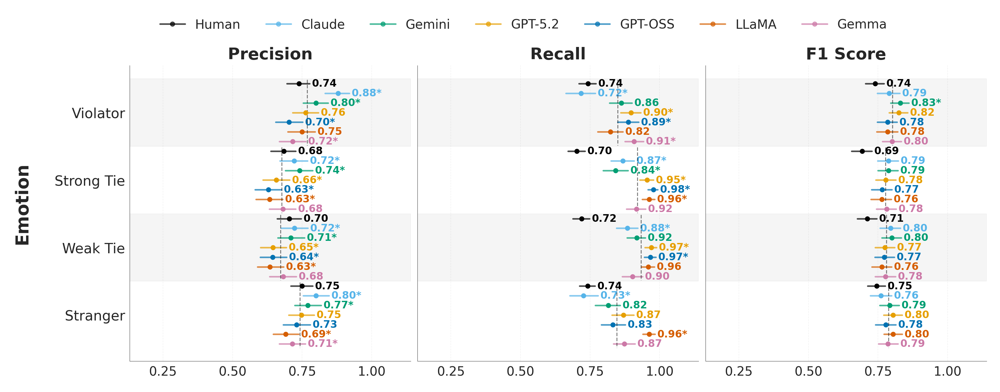

In [162]:
def plot_emotion_results(results_df, name="model_em_eval.png"):
    FONT_SIZE = 24
    FIG_WIDTH = 22
    FIG_HEIGHT = 8

    metrics = ["precision", "recall", "f1"]
    metric_titles = ["Precision", "Recall", "F1 Score"]

    categories = ["actor", "friend", "acq", "stranger"]
    cat_labels = ["Violator", "Strong Tie", "Weak Tie", "Stranger"]

    model_order = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]

    colors = {
        "claude": "#56B4E9",
        "gemini": "#009E73",
        "gpt_5.2": "#E69F00",
        "gpt_oss": "#0072B2",
        "llama": "#D55E00",
        "gemma": "#CC79A7",
        "human": "#000000",
    }

    all_order = ["human", "claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
    all_labels = ["Human", "Claude", "Gemini", "GPT-5.2", "GPT-OSS", "LLaMA", "Gemma"]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(FIG_WIDTH, FIG_HEIGHT),
        sharey=True
    )

    n_all = len(all_order)
    n_cats = len(categories)

    for ax_idx, (metric, title) in enumerate(zip(metrics, metric_titles)):
        ax = axes[ax_idx]

        for cat_idx, (cat, cat_label) in enumerate(zip(categories, cat_labels)):

            if cat_idx % 2 == 0:
                ax.axhspan(
                    cat_idx * n_all - 0.5,
                    cat_idx * n_all + n_all - 0.5,
                    color="grey",
                    alpha=0.08
                )

            for model_idx, (model, model_label) in enumerate(zip(all_order, all_labels)):
                row = results_df[
                    (results_df["label_type"] == model) &
                    (results_df["category"] == cat)
                ]

                val = row[metric].values[0]
                lo = row[f"{metric}_ci_lo"].values[0]
                hi = row[f"{metric}_ci_hi"].values[0]

                y_pos = cat_idx * n_all + model_idx

                ax.plot(
                    [lo, hi], [y_pos, y_pos],
                    color=colors[model],
                    linewidth=2.5,
                    alpha=0.7,
                    solid_capstyle="round"
                )

                ax.plot(
                    val, y_pos, "o",
                    color=colors[model],
                    markersize=7,
                    zorder=5
                )

                stars = sig_stars(row[f"{metric}_p"].values[0])
                label_text = f"{val:.2f}{stars}"

                ax.text(
                    hi + 0.008,
                    y_pos,
                    label_text,
                    va="center",
                    ha="left",
                    fontsize=FONT_SIZE - 8,
                    color=colors[model],
                    fontweight="bold"
                )

            # LLM average dashed line (excluding human)
            cat_vals = []

            for model in model_order:
                row = results_df[
                    (results_df["label_type"] == model) &
                    (results_df["category"] == cat)
                ]
                cat_vals.append(row[metric].values[0])

            avg_val = np.mean(cat_vals)

            y_top = cat_idx * n_all - 0.4
            y_bot = cat_idx * n_all + n_all - 0.6

            ax.plot(
                [avg_val, avg_val],
                [y_top, y_bot],
                color="black",
                linewidth=1.5,
                linestyle="--",
                alpha=0.5,
                zorder=4
            )

        ytick_positions = [
            cat_idx * n_all + (n_all - 1) / 2
            for cat_idx in range(n_cats)
        ]

        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(cat_labels, fontsize=FONT_SIZE - 2)
        ax.invert_yaxis()

        ax.set_xlim(0.13, 1.14)
        ax.set_xticks(np.arange(0.25, 1.01, 0.25))
        ax.set_title(
            title,
            fontsize=FONT_SIZE + 2,
            fontweight="bold",
            pad=10
        )

        ax.tick_params(axis="x", labelsize=FONT_SIZE - 4)
        ax.grid(axis="x", alpha=0.25, linestyle="--", linewidth=0.8)
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.5)
        ax.spines["bottom"].set_linewidth(0.5)

    legend_handles = [
        Line2D(
            [0], [0],
            color=colors[model],
            marker="o",
            markersize=7,
            linewidth=2.5,
            alpha=0.7,
            label=model_label
        )
        for model, model_label in zip(all_order, all_labels)
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.53, 1.04),
        ncol=n_all,
        fontsize=FONT_SIZE - 4,
        frameon=False
    )

    fig.supylabel(
        "Emotion",
        fontsize=FONT_SIZE + 4,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0.03, 0, 1, 0.95])
    fig.savefig(os.path.join(figure_output_path, name), dpi=300, bbox_inches="tight")
    plt.show()

    return fig, axes

fig, axes = plot_emotion_results(results_df)

##### Stratified Gender Analysis

In [163]:
df_gender = binary_emotions(df_benchmark_gender)
df_agg_gender, merged_gender = merged_human_llm(df_gender)

# Restore underlying scenario IDs
id_map = df_benchmark_gender[["ID", "main_ID"]].drop_duplicates()

if "main_ID" not in df_agg_gender.columns:
    df_agg_gender = df_agg_gender.merge(
        id_map, on="ID", how="left", validate="many_to_one"
    )

if "main_ID" not in merged_gender.columns:
    merged_gender = merged_gender.merge(
        id_map, on="ID", how="left", validate="many_to_one"
    )

# Verify clustering information is present
assert df_agg_gender["main_ID"].notna().all()
assert merged_gender["main_ID"].notna().all()

# Run evaluation
results_df_gender = llm_eval(
    df_agg_gender,
    merged_gender,
    leave_one_out=True,
    bootstrap_sample=False
)

results_df_gender

,label_type,category,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,claude,actor,0.816667,0.650854,0.724393,0.691124,0.777250,0.854653,0.000500,0.002999,...,0.000500,0.002999,0.683401,0.760236,0.001999,0.009995,0.655210,0.724587,0.533733,0.710645
1,gemini,actor,0.767956,0.791271,0.779439,0.720710,0.729406,0.804225,0.014493,0.043478,...,0.914043,0.914043,0.747471,0.807144,0.091454,0.365817,0.689046,0.750916,0.026487,0.132434
2,gemma,actor,0.696375,0.874763,0.775442,0.684024,0.656150,0.734820,0.000500,0.002999,...,0.000500,0.002999,0.743943,0.804260,0.275362,0.826087,0.648869,0.717870,0.236882,0.710645
3,gpt_5.2,actor,0.756345,0.848197,0.799642,0.734911,0.719323,0.792554,0.241879,0.448776,...,0.000500,0.002999,0.769520,0.826690,0.000500,0.002999,0.701416,0.766392,0.001000,0.005997
4,gpt_oss,actor,0.709302,0.810247,0.756422,0.674556,0.668929,0.748290,0.000500,0.002999,...,0.229885,0.689655,0.724262,0.786210,0.326837,0.826087,0.640183,0.707492,0.040480,0.161919
5,llama,actor,0.734403,0.781784,0.757353,0.687574,0.692720,0.774023,0.224388,0.448776,...,0.446277,0.892554,0.723050,0.788301,0.368316,0.826087,0.652692,0.720579,0.308846,0.710645
6,claude,friend,0.655652,0.834071,0.734177,0.676923,0.613557,0.696184,0.000500,0.002999,...,0.000500,0.002999,0.699183,0.766513,0.165917,0.829585,0.641418,0.710024,0.000500,0.002999
7,gemini,friend,0.683908,0.789823,0.733060,0.692308,0.640740,0.725382,0.000500,0.002999,...,0.000500,0.002999,0.697421,0.765703,0.262869,1.000000,0.660735,0.725239,0.000500,0.002999
8,gemma,friend,0.611621,0.884956,0.723327,0.637870,0.570547,0.652046,0.820590,0.820590,...,0.916542,0.916542,0.688679,0.755358,0.860070,1.000000,0.602355,0.673759,0.685657,0.685657
9,gpt_5.2,friend,0.589413,0.911504,0.715899,0.613018,0.547055,0.628411,0.000500,0.002999,...,0.009995,0.019990,0.681413,0.747196,0.313843,1.000000,0.575676,0.649112,0.024988,0.049975


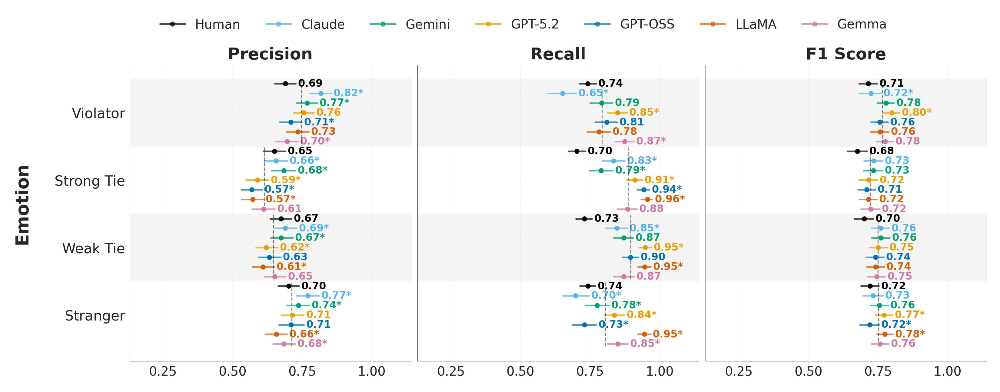

In [164]:
fig, axes = plot_emotion_results(results_df_gender, name="model_em_eval_gender.png")

#### Individual Emotions

In [165]:
df = df_benchmark.copy()

In [166]:
df_human_test = df[df["label_type"] == "human"].copy()

# Find annotators who rated both gender versions of the same ID
both_gender_pairs = (
    df_human_test.groupby(["ID", "human_id"])["actor_gender"]
    .nunique()
    .loc[lambda x: x == 2]
    .reset_index()[["ID", "human_id"]])
both_gender_pairs

,ID,human_id
0,62,R_5wv2geDL1QVEMb4
1,344,R_6wM2jVhAQwm3Eus


In [167]:
df.loc[(df['ID'] == 344) & (df['human_id'] == 'R_6wM2jVhAQwm3Eus')][['friends_reaction', 'friends_reaction_should', 'acquaintances_reaction', 'acquaintances_reaction_should', 'strangers_reaction', 'strangers_reaction_should']]

,friends_reaction,friends_reaction_should,acquaintances_reaction,acquaintances_reaction_should,strangers_reaction,strangers_reaction_should
2007,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing
2014,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing,Do nothing


In [168]:
df.loc[(df['ID'] == 62) & (df['human_id'] == 'R_5wv2geDL1QVEMb4')][['friends_reaction', 'friends_reaction_should', 'acquaintances_reaction', 'acquaintances_reaction_should', 'strangers_reaction', 'strangers_reaction_should']]

,friends_reaction,friends_reaction_should,acquaintances_reaction,acquaintances_reaction_should,strangers_reaction,strangers_reaction_should
361,Verbal confrontation,Verbal confrontation,Stay away,Verbal confrontation,Do nothing,Do nothing
363,Verbal confrontation,Verbal confrontation,Verbal confrontation,Verbal confrontation,Do nothing,Verbal confrontation


In [169]:
df.loc[(df['ID'] == 62) & (df['human_id'] == 'R_5wv2geDL1QVEMb4')][['actor_emotions', 'friends_emotions', 'acquaintances_emotions', 'strangers_emotions']]

,actor_emotions,friends_emotions,acquaintances_emotions,strangers_emotions
361,"Shame, Guilt, Embarrassment","Contempt, Anger, Disgust","Anger, Disgust","Anger, Disgust"
363,"Shame, Guilt, Embarrassment","Contempt, Anger, Disgust","Anger, Disgust","Anger, Disgust"


In [170]:
df.loc[(df['ID'] == 344) & (df['human_id'] == 'R_6wM2jVhAQwm3Eus')][['actor_emotions', 'friends_emotions', 'acquaintances_emotions', 'strangers_emotions']]

,actor_emotions,friends_emotions,acquaintances_emotions,strangers_emotions
2007,Pride,Compassion,Compassion,Compassion
2014,Pride,Compassion,Compassion,Compassion


In [171]:
emotion_names = [
    "Shame",
    "Guilt",
    "Embarrassment",
    "Contempt",
    "Disgust",
    "Anger",
    "Pride",
    "Compassion",
]

IDs = sorted(df["ID"].astype(int).unique())

# Explode and deduplicate per (human_id, ID, emotion)
human_self_long = (
    df.loc[df["label_type"] == "human", ["ID", "human_id", "self_emotion_list"]]
    .explode("self_emotion_list")
    .rename(columns={"self_emotion_list": "emotion"})
)

human_self_long = human_self_long.dropna(subset=["emotion"])
human_self_long = human_self_long.drop_duplicates(subset=["ID", "human_id", "emotion"])

# Count distinct annotators per emotion per ID
human_self_counts = (
    human_self_long
    .groupby(["ID", "emotion"])["human_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=IDs, columns=emotion_names, fill_value=0)
)

# Count unique annotators per ID (also deduplicated across gender)
n_annotators_per_id = (
    df.loc[df["label_type"] == "human"]
    .drop_duplicates(subset=["ID", "human_id"])
    .groupby("ID")["human_id"]
    .nunique()
    .reindex(IDs, fill_value=0)
)

# Consensus
human_self_X = (
    human_self_counts.gt(n_annotators_per_id / 2, axis=0)
    .astype(int)
    .values
)
human_self_X

array([[0, 1, 0, ..., 0, 0, 0],
       [1, 1, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 1, 0],
       [1, 1, 1, ..., 0, 0, 0],
       [1, 0, 1, ..., 0, 0, 0]])

In [172]:
tie_map = {
    0: "friend",
    1: "acquaintance",
    2: "stranger"
}

def expand_other(row):
    rows = []
    for tie_idx, emotions in enumerate(row["other_emotion_list"]):
        if isinstance(emotions, list):
            for emo in emotions:
                rows.append({
                    "ID": row["ID"],
                    "human_id": row["human_id"],
                    "tie_type": tie_map.get(tie_idx),
                    "emotion": emo
                })
    return rows

human_df = df.loc[df["label_type"] == "human"].copy()
human_other_long = pd.DataFrame(
    [
        item
        for _, row in human_df.iterrows()
        for item in expand_other(row)
    ]
)

# Clean and dedup per (human_id, ID, tie_type, emotion)
human_other_long = human_other_long.dropna(subset=["emotion"])
human_other_long = human_other_long.drop_duplicates(
    subset=["ID", "human_id", "tie_type", "emotion"]
)

# Count distinct annotators per (ID, tie_type, emotion)
human_other_counts = (
    human_other_long
    .groupby(["ID", "tie_type", "emotion"])["human_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=emotion_names, fill_value=0)
)

# Count unique annotators per (ID, tie_type) — deduplicated across gender
n_annotators_per_id_tie = (
    human_df
    .drop_duplicates(subset=["ID", "human_id"])
    .assign(tie_types=lambda x: [list(tie_map.values())] * len(x))
    .explode("tie_types")
    .rename(columns={"tie_types": "tie_type"})
    .groupby(["ID", "tie_type"])["human_id"]
    .nunique()
)

# Align annotator counts to the same index as human_other_counts
n_aligned = n_annotators_per_id_tie.reindex(human_other_counts.index, fill_value=0)

# Apply majority consensus
human_other_binary = (
    human_other_counts.gt(n_aligned / 2, axis=0)
    .astype(int)
    .reset_index()
)

def build_matrix(df, tie):
    return (
        df[df["tie_type"] == tie]
        .set_index("ID")[emotion_names]
        .reindex(index=IDs, fill_value=0)
        .values
    )

human_friend_X = build_matrix(human_other_binary, "friend")
human_acquaintance_X = build_matrix(human_other_binary, "acquaintance")
human_stranger_X = build_matrix(human_other_binary, "stranger")
human_other_binary

emotion,ID,tie_type,Shame,Guilt,Embarrassment,Contempt,Disgust,Anger,Pride,Compassion
0,1,acquaintance,0,0,0,0,0,0,0,0
1,1,friend,0,0,0,0,0,0,0,0
2,1,stranger,0,0,0,0,0,0,0,0
3,2,acquaintance,0,0,0,0,1,0,0,0
4,2,friend,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1321,450,friend,1,0,1,1,1,1,0,0
1322,450,stranger,0,0,0,1,1,1,0,0
1323,451,acquaintance,0,0,0,0,1,0,0,0
1324,451,friend,0,0,0,0,1,0,0,0


In [173]:
# LLMs — union across gender variants
llm_labels = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
llm_self_X = {}

for label in llm_labels:
    llm_sub = df.loc[df["label_type"] == label, ["ID", "self_emotion_list"]]

    llm_long = (
        llm_sub
        .explode("self_emotion_list")
        .rename(columns={"self_emotion_list": "emotion"})
    )
    llm_long = llm_long.dropna(subset=["emotion"])
    llm_long = llm_long.drop_duplicates(subset=["ID", "emotion"])

    # If any row for this ID has the emotion, it's present (union)
    llm_presence = (
        llm_long
        .groupby(["ID", "emotion"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=IDs, columns=emotion_names, fill_value=0)
        .gt(0)
        .astype(int)
        .values
    )

    llm_self_X[label] = llm_presence

In [174]:
tie_map = {
    0: "friend",
    1: "acquaintance",
    2: "stranger"
}

def expand_other_llm(row):
    rows = []
    for tie_idx, emotions in enumerate(row["other_emotion_list"]):
        if isinstance(emotions, list):
            for emo in emotions:
                rows.append({
                    "ID": row["ID"],
                    "tie_type": tie_map.get(tie_idx),
                    "emotion": emo
                })
    return rows

llm_labels = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]

llm_friend_X = {}
llm_acquaintance_X = {}
llm_stranger_X = {}

for label in llm_labels:
    llm_sub = df.loc[df["label_type"] == label].copy()

    llm_other_long = pd.DataFrame(
        [
            item
            for _, row in llm_sub.iterrows()
            for item in expand_other_llm(row)
        ]
    )

    llm_other_long = llm_other_long.dropna(subset=["emotion"])
    llm_other_long = llm_other_long.drop_duplicates(subset=["ID", "tie_type", "emotion"])

    llm_other_binary = (
        llm_other_long
        .groupby(["ID", "tie_type", "emotion"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=emotion_names, fill_value=0)
        .gt(0)
        .astype(int)
        .reset_index()
    )

    def build_matrix(df_bin, tie):
        return (
            df_bin[df_bin["tie_type"] == tie]
            .set_index("ID")[emotion_names]
            .reindex(index=IDs, fill_value=0)
            .values
        )

    llm_friend_X[label] = build_matrix(llm_other_binary, "friend")
    llm_acquaintance_X[label] = build_matrix(llm_other_binary, "acquaintance")
    llm_stranger_X[label] = build_matrix(llm_other_binary, "stranger")

In [175]:
# Map category to human and LLM matrices
human_matrices = {
    "self": human_self_X,
    "friend": human_friend_X,
    "acquaintance": human_acquaintance_X,
    "stranger": human_stranger_X,
}

llm_matrices = {
    "self": llm_self_X,
    "friend": llm_friend_X,
    "acquaintance": llm_acquaintance_X,
    "stranger": llm_stranger_X,
}

results = []

for cat in ["self", "friend", "acquaintance", "stranger"]:
    h_matrix = human_matrices[cat]

    for emo_idx, emo_name in enumerate(emotion_names):
        # Collect all models' y_true and y_pred for this category + emotion
        y_true_dict = {}
        y_pred_dict = {}
        metrics_dict = {}

        for label in llm_labels:
            l_matrix = llm_matrices[cat][label]

            y_true = pd.Series(h_matrix[:, emo_idx])
            y_pred = pd.Series(l_matrix[:, emo_idx])

            y_true_dict[label] = y_true
            y_pred_dict[label] = y_pred
            metrics_dict[label] = compute_metrics(y_true.values, y_pred.values)

        # Bootstrap with significance for all models together
        boot_results = bootstrap_ci_with_significance(y_true_dict, y_pred_dict, np.arange(h_matrix.shape[0]))

        for label in llm_labels:
            results.append({
                "category": cat,
                "label_type": label,
                "emotion": emo_name,
                **metrics_dict[label],
                **boot_results[label],
            })

results_emotion_df = pd.DataFrame(results)
results_emotion_df

,category,label_type,emotion,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,self,claude,Shame,0.577778,0.577778,0.577778,0.742081,0.496123,0.656500,0.000500,...,0.000500,0.002999,0.505747,0.645614,0.678661,0.678661,0.699095,0.780543,0.000500,0.002999
1,self,gemini,Shame,0.564706,0.711111,0.629508,0.744344,0.490316,0.640741,0.000500,...,0.518741,0.821589,0.563564,0.692772,0.002499,0.009995,0.703620,0.782862,0.000500,0.002999
2,self,gpt_5.2,Shame,0.537313,0.800000,0.642857,0.728507,0.469692,0.605581,0.000500,...,0.003498,0.013993,0.579795,0.702100,0.000500,0.002999,0.685520,0.769231,0.000500,0.002999
3,self,gpt_oss,Shame,0.402135,0.837037,0.543269,0.570136,0.343643,0.463164,0.000500,...,0.000500,0.002999,0.480188,0.600917,0.155422,0.310845,0.520362,0.615385,0.000500,0.002999
4,self,llama,Shame,0.410359,0.762963,0.533679,0.592760,0.348361,0.474715,0.000500,...,0.273863,0.821589,0.470580,0.594206,0.067966,0.203898,0.545192,0.638009,0.002499,0.002999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,stranger,gemini,Compassion,0.142857,0.294118,0.192308,0.809955,0.065574,0.229514,0.056972,...,0.350325,1.000000,0.093447,0.294118,0.781109,1.000000,0.771437,0.846154,0.004498,0.008996
188,stranger,gpt_5.2,Compassion,0.093458,0.294118,0.141844,0.726244,0.042735,0.150943,0.001499,...,0.346827,1.000000,0.067103,0.219183,0.078961,0.473763,0.683258,0.767025,0.000500,0.002999
189,stranger,gpt_oss,Compassion,0.363636,0.117647,0.177778,0.916290,0.000000,0.666667,0.215892,...,0.002499,0.014993,0.000000,0.333333,0.587706,1.000000,0.889140,0.941176,0.000500,0.002999
190,stranger,llama,Compassion,0.259259,0.205882,0.229508,0.893665,0.100000,0.440000,0.615692,...,0.499250,1.000000,0.084478,0.366667,0.598201,1.000000,0.864253,0.923077,0.000500,0.002999


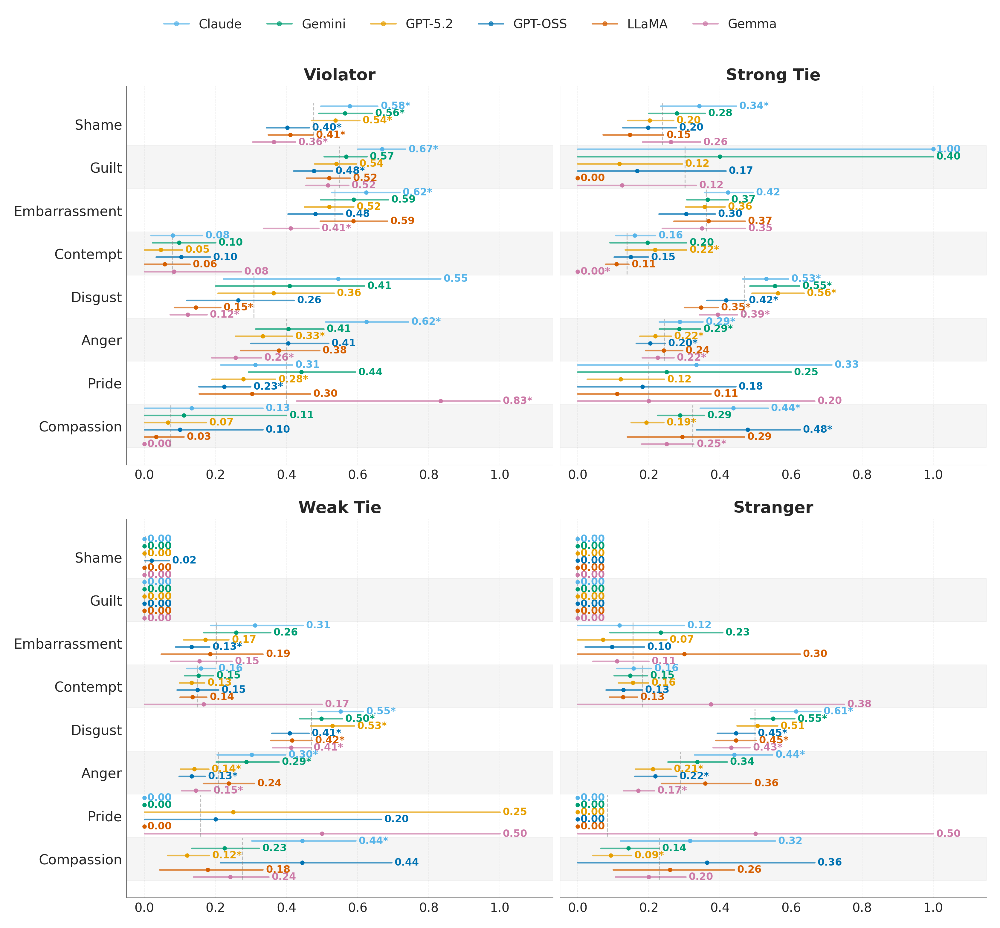

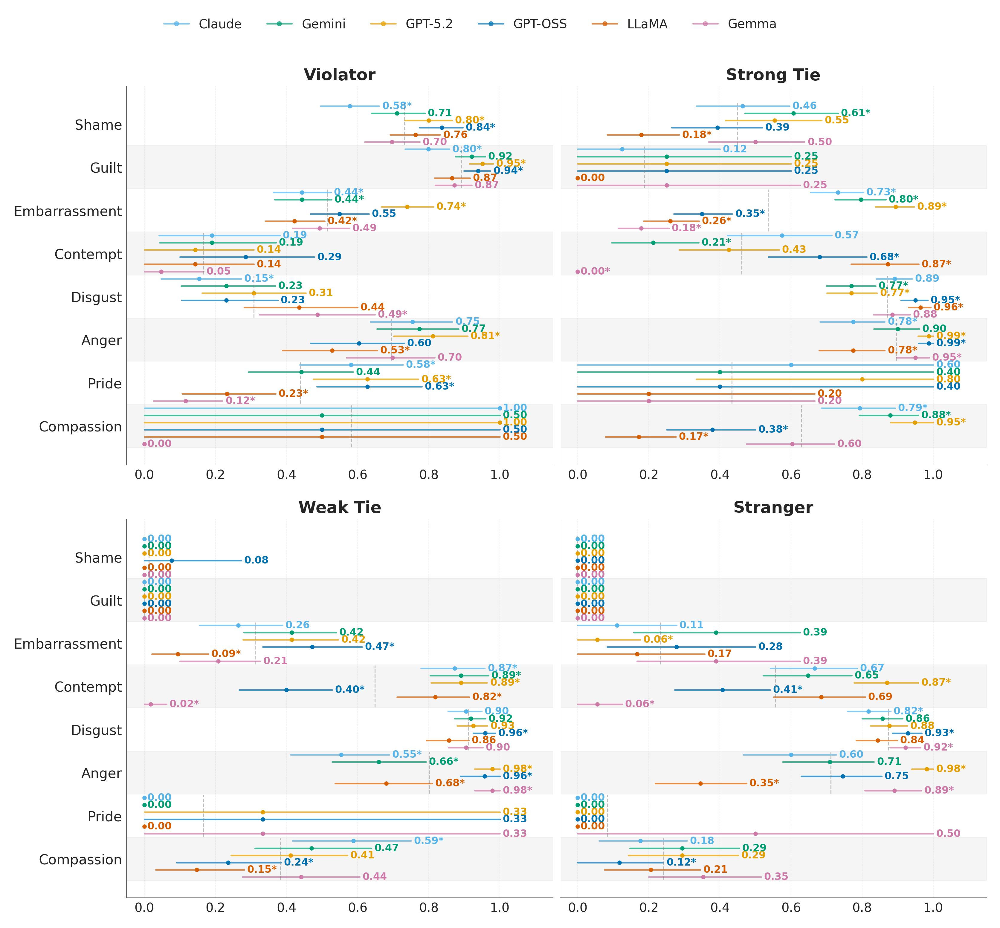

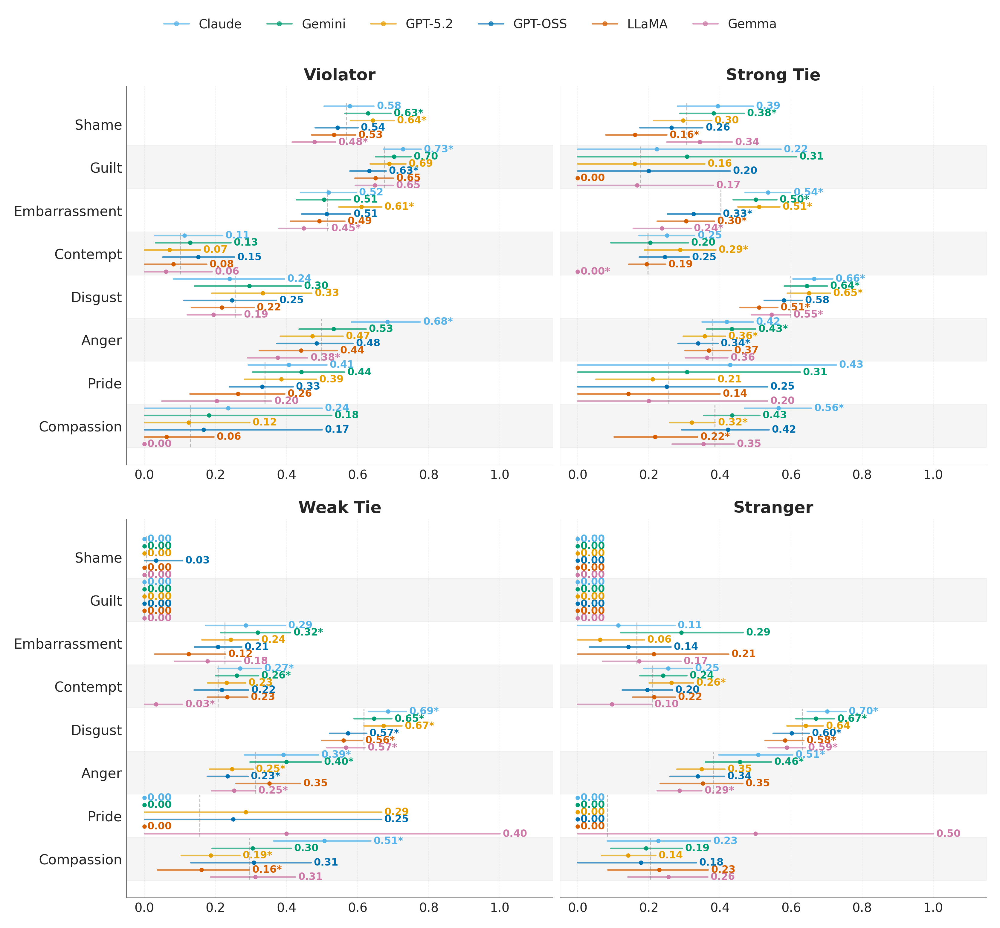

In [176]:
FONT_SIZE = 24
FIG_WIDTH = 22
FIG_HEIGHT = 10

categories = ["self", "friend", "acquaintance", "stranger"]
cat_labels = ["Violator", "Strong Tie", "Weak Tie", "Stranger"]

model_order = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
model_labels = ["Claude", "Gemini", "GPT-5.2", "GPT-OSS", "LLaMA", "Gemma"]

colors = {
    "claude": "#56B4E9",
    "gemini": "#009E73",
    "gpt_5.2": "#E69F00",
    "gpt_oss": "#0072B2",
    "llama": "#D55E00",
    "gemma": "#CC79A7",
    "human": "#000000",
}

all_order = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
all_labels = ["Claude", "Gemini", "GPT-5.2", "GPT-OSS", "LLaMA", "Gemma"]

emotion_names = [
    "Shame", "Guilt", "Embarrassment",
    "Contempt", "Disgust", "Anger",
    "Pride", "Compassion",
]

n_rows_per_emo = len(all_order)
n_emotions = len(emotion_names)

metrics = ["precision", "recall", "f1"]
metric_titles = ["Precision", "Recall", "F1 Score"]

for metric, metric_title in zip(metrics, metric_titles):

    fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 2), sharey=True)
    axes = axes.flatten()

    for ax_idx, (cat, cat_label) in enumerate(zip(categories, cat_labels)):
        ax = axes[ax_idx]

        for emo_idx, emo_name in enumerate(reversed(emotion_names)):
            if emo_idx % 2 == 0:
                ax.axhspan(
                    emo_idx * n_rows_per_emo - 0.5,
                    emo_idx * n_rows_per_emo + n_rows_per_emo - 0.5,
                    color='grey', alpha=0.08
                )

            # LLM average (excluding human)
            cat_vals = []

            for row_idx, (model, model_label) in enumerate(zip(all_order[::-1], all_labels[::-1])):
                row = results_emotion_df[
                    (results_emotion_df["label_type"] == model) &
                    (results_emotion_df["category"] == cat) &
                    (results_emotion_df["emotion"] == emo_name)
                ]

                if len(row) == 0:
                    continue

                val = row[metric].values[0]
                lo = row[f"{metric}_ci_lo"].values[0]
                hi = row[f"{metric}_ci_hi"].values[0]

                # Only LLMs contribute to average
                if model != "human":
                    cat_vals.append(val)

                y_pos = emo_idx * n_rows_per_emo + row_idx

                ax.plot(
                    [lo, hi], [y_pos, y_pos],
                    color=colors[model], linewidth=2.5, alpha=0.7,
                    solid_capstyle='round'
                )
                ax.plot(
                    val, y_pos, 'o',
                    color=colors[model], markersize=6, zorder=5,
                    label=model_label if (ax_idx == 0 and emo_idx == 0) else None
                )

                if model != "human":
                    stars = sig_stars(row[f"{metric}_p"].values[0])
                    label_text = f"{val:.2f}{stars}"
                else:
                    label_text = f"{val:.2f}"

                ax.text(
                    hi + 0.008, y_pos, label_text,
                    va='center', ha='left',
                    fontsize=FONT_SIZE - 8, color=colors[model], fontweight='bold'
                )

            # Average line per emotion group (LLMs only)
            if cat_vals:
                avg_val = np.mean(cat_vals)
                y_top = emo_idx * n_rows_per_emo - 0.4
                y_bot = emo_idx * n_rows_per_emo + n_rows_per_emo - 0.6
                ax.plot(
                    [avg_val, avg_val], [y_top, y_bot],
                    color='grey', linewidth=1.5, linestyle='--', alpha=0.5, zorder=4
                )
                # ax.text(
                #     avg_val, y_top - 0.3, f"{avg_val:.2f}",
                #     va='bottom', ha='center',
                #     fontsize=FONT_SIZE - 8, color='grey', fontstyle='italic'
                # )

        ytick_positions = [emo_idx * n_rows_per_emo + (n_rows_per_emo - 1) / 2 for emo_idx in range(n_emotions)]
        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(list(reversed(emotion_names)), fontsize=FONT_SIZE - 2)

        ax.set_xlim(-0.05, 1.15)
        ax.set_title(cat_label, fontsize=FONT_SIZE + 2, fontweight='bold', pad=10)
        ax.tick_params(axis='x', labelsize=FONT_SIZE - 4)
        ax.grid(axis='x', alpha=0.25, linestyle='--', linewidth=0.8)
        ax.set_axisbelow(True)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(0.5)
        ax.spines['bottom'].set_linewidth(0.5)

    legend_handles = []
    legend_labels = []
    for model, model_label in zip(all_order, all_labels):
        legend_handles.append(
            Line2D([0], [0], color=colors[model], marker='o', markersize=7,
                   linewidth=2.5, alpha=0.7)
        )
        legend_labels.append(model_label)

    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.47, 1.02),
        ncol=len(all_order),
        fontsize=FONT_SIZE - 4,
        frameon=False
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3)
    fig.savefig(os.path.join(figure_output_path, f"emotion_{metric}.png"), bbox_inches='tight', dpi=300)
    plt.show()

#### Emotion Distribution

In [177]:
SELF_EMOTIONS = ['Shame', 'Guilt', 'Embarrassment']
OTHER_EMOTIONS = ['Anger', 'Disgust', 'Contempt']
POSITIVE_EMOTIONS = ['Pride', 'Compassion']
EMOTIONS = major_emotions

def classify_and_count(df, emotions_cols, label):
    """
    df: DataFrame with columns for each emotion (binary 0/1), indexed per stimulus.
    Returns a summary DataFrame with counts and median emotion counts per category.
    """
    results = []

    for _, row in df.iterrows():
        has_self = row[SELF_EMOTIONS].sum() > 0
        has_other = row[OTHER_EMOTIONS].sum() > 0
        has_pos = row[POSITIVE_EMOTIONS].sum() > 0
        has_any = row[SELF_EMOTIONS + OTHER_EMOTIONS + POSITIVE_EMOTIONS].sum() > 0

        self_count = row[SELF_EMOTIONS].sum()
        other_count = row[OTHER_EMOTIONS].sum()
        pos_count = row[POSITIVE_EMOTIONS].sum()

        if not has_any:
            cat = "No Emotion"
        elif has_self and has_other:
            cat = "Both Self + Other"
        elif has_self and not has_other:
            cat = "Self-focused Only"
        elif has_other and not has_self:
            cat = "Other-focused Only"
        elif has_pos and not has_self and not has_other:
            cat = "Positive Only"
        else:
            cat = "Other"

        results.append({
            'category': cat,
            'self_count': self_count,
            'other_count': other_count,
            'pos_count': pos_count,
        })

    res_df = pd.DataFrame(results)

    summary = res_df.groupby('category').agg(
        n_stimuli=('category', 'size'),
        median_self=('self_count', 'median'),
        median_other=('other_count', 'median'),
        median_positive=('pos_count', 'median'),
    ).reset_index()

    summary['proportion'] = (summary['n_stimuli'] / 442).round(3)
    summary['perspective'] = label
    return summary

# Actor (from human_self_count)
human_self_df = pd.DataFrame(human_self_X, columns=EMOTIONS)
actor_summary = classify_and_count(human_self_df, EMOTIONS, 'Actor')

# Friend / Acquaintance / Stranger (from human_other_binary)
friend_df = human_other_binary[human_other_binary['tie_type'] == 'friend'].drop(columns=['ID', 'tie_type'])
acq_df = human_other_binary[human_other_binary['tie_type'] == 'acquaintance'].drop(columns=['ID', 'tie_type'])
stranger_df = human_other_binary[human_other_binary['tie_type'] == 'stranger'].drop(columns=['ID', 'tie_type'])

friend_summary = classify_and_count(friend_df, EMOTIONS, 'Friend')
acq_summary = classify_and_count(acq_df, EMOTIONS, 'Acquaintance')
stranger_summary = classify_and_count(stranger_df, EMOTIONS, 'Stranger')

# Combine
full_summary = pd.concat([actor_summary, friend_summary, acq_summary, stranger_summary], ignore_index=True)
full_summary

,category,n_stimuli,median_self,median_other,median_positive,proportion,perspective
0,Both Self + Other,45,1.0,1.0,1.0,0.102,Actor
1,No Emotion,126,0.0,0.0,0.0,0.285,Actor
2,Other-focused Only,71,0.0,1.0,0.0,0.161,Actor
3,Positive Only,11,0.0,0.0,1.0,0.025,Actor
4,Self-focused Only,189,1.0,0.0,1.0,0.428,Actor
5,Both Self + Other,67,1.0,1.0,0.0,0.152,Friend
6,No Emotion,130,0.0,0.0,0.0,0.294,Friend
7,Other-focused Only,115,0.0,1.0,0.0,0.260,Friend
8,Positive Only,52,0.0,0.0,1.0,0.118,Friend
9,Self-focused Only,78,1.0,0.0,0.0,0.176,Friend


### Minor Agreement (>= 2)

In [178]:
emotion_names = [
    "Shame",
    "Guilt",
    "Embarrassment",
    "Contempt",
    "Disgust",
    "Anger",
    "Pride",
    "Compassion",
]

IDs = sorted(df["ID"].astype(int).unique())

human_self_long = (
    df.loc[df["label_type"] == "human", ["ID", "human_id", "self_emotion_list"]]
    .explode("self_emotion_list")
    .rename(columns={"self_emotion_list": "emotion"})
)

human_self_long = human_self_long.dropna(subset=["emotion"])
human_self_long = human_self_long.drop_duplicates(subset=["ID", "human_id", "emotion"])

# count how many distinct annotators selected each emotion for each ID
human_self_counts = (
    human_self_long
    .groupby(["ID", "emotion"])["human_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=IDs, columns=emotion_names, fill_value=0)
)

# count total annotators per ID
n_annotators_per_id = (
    df.loc[df["label_type"] == "human"]
    .groupby("ID")["human_id"]
    .nunique()
    .reindex(IDs, fill_value=0)
)

# consensus = majority of annotators selected the emotion
human_self_X = (
    human_self_counts.ge(2, axis=0)
    .astype(int)
    .values
)
human_self_X

array([[0, 1, 0, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 1, 0],
       [1, 1, 1, ..., 1, 0, 0],
       [1, 0, 1, ..., 0, 0, 0]])

In [179]:
tie_map = {
    0: "friend",
    1: "acquaintance",
    2: "stranger"
}

def expand_other(row):
    rows = []
    for tie_idx, emotions in enumerate(row["other_emotion_list"]):
        if isinstance(emotions, list):
            for emo in emotions:
                rows.append({
                    "ID": row["ID"],
                    "human_id": row["human_id"],
                    "tie_type": tie_map.get(tie_idx),
                    "emotion": emo
                })
    return rows

human_df = df.loc[df["label_type"] == "human"].copy()
human_other_long = pd.DataFrame(
    [
        item
        for _, row in human_df.iterrows()
        for item in expand_other(row)
    ]
)

# Clean and dedup per (human_id, ID, tie_type, emotion)
human_other_long = human_other_long.dropna(subset=["emotion"])
human_other_long = human_other_long.drop_duplicates(
    subset=["ID", "human_id", "tie_type", "emotion"]
)

# Count distinct annotators per (ID, tie_type, emotion)
human_other_counts = (
    human_other_long
    .groupby(["ID", "tie_type", "emotion"])["human_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=emotion_names, fill_value=0)
)

# Count annotators per (id, tie, emotion)
human_other_counts = (
    human_other_long
    .groupby(["ID", "tie_type", "emotion"])["human_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=emotion_names, fill_value=0)
)

# Count total annotators per (id, tie_type)
n_annotators_per_id_tie = (
    human_other_long
    .groupby(["ID", "tie_type"])["human_id"]
    .nunique()
)

# Align annotator counts to the same index as human_other_counts
n_aligned = n_annotators_per_id_tie.reindex(human_other_counts.index, fill_value=0)

# Apply majority consensus
human_other_binary = (
    human_other_counts.ge(2, axis=0)
    .astype(int)
    .reset_index()
)

def build_matrix(df, tie):
    return (
        df[df["tie_type"] == tie]
        .set_index("ID")[emotion_names]
        .reindex(index=IDs, fill_value=0)
        .values
    )

human_friend_X = build_matrix(human_other_binary, "friend")
human_acquaintance_X = build_matrix(human_other_binary, "acquaintance")
human_stranger_X = build_matrix(human_other_binary, "stranger")
human_other_binary

emotion,ID,tie_type,Shame,Guilt,Embarrassment,Contempt,Disgust,Anger,Pride,Compassion
0,1,acquaintance,0,0,0,0,0,0,0,1
1,1,friend,0,0,0,0,0,1,0,1
2,1,stranger,0,0,0,0,0,0,0,1
3,2,acquaintance,0,0,0,1,1,1,0,0
4,2,friend,1,1,1,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1321,450,friend,1,0,1,1,1,1,0,0
1322,450,stranger,0,0,0,1,1,1,0,0
1323,451,acquaintance,0,0,0,0,1,0,0,0
1324,451,friend,0,0,0,0,1,0,0,0


#### Emotion Distribution

In [180]:
# Actor (from human_self_count)
human_self_df = pd.DataFrame(human_self_X, columns=EMOTIONS)
actor_summary = classify_and_count(human_self_df, EMOTIONS, 'Actor')

# Friend / Acquaintance / Stranger (from human_other_binary)
friend_df = human_other_binary[human_other_binary['tie_type'] == 'friend'].drop(columns=['ID', 'tie_type'])
acq_df = human_other_binary[human_other_binary['tie_type'] == 'acquaintance'].drop(columns=['ID', 'tie_type'])
stranger_df = human_other_binary[human_other_binary['tie_type'] == 'stranger'].drop(columns=['ID', 'tie_type'])

friend_summary = classify_and_count(friend_df, EMOTIONS, 'Friend')
acq_summary = classify_and_count(acq_df, EMOTIONS, 'Acquaintance')
stranger_summary = classify_and_count(stranger_df, EMOTIONS, 'Stranger')

# Combine
full_summary = pd.concat([actor_summary, friend_summary, acq_summary, stranger_summary], ignore_index=True)
full_summary

,category,n_stimuli,median_self,median_other,median_positive,proportion,perspective
0,Both Self + Other,240,2.0,1.0,1.0,0.543,Actor
1,No Emotion,20,0.0,0.0,0.0,0.045,Actor
2,Other-focused Only,43,0.0,1.0,0.0,0.097,Actor
3,Positive Only,4,0.0,0.0,1.0,0.009,Actor
4,Self-focused Only,135,2.0,0.0,1.0,0.305,Actor
5,Both Self + Other,263,2.0,2.0,0.0,0.595,Friend
6,No Emotion,14,0.0,0.0,0.0,0.032,Friend
7,Other-focused Only,70,0.0,1.0,0.0,0.158,Friend
8,Positive Only,31,0.0,0.0,1.0,0.070,Friend
9,Self-focused Only,64,1.0,0.0,0.5,0.145,Friend


### Top-Bottom 25% Agreement

In [181]:
all_results = []

for i in ["actor", "friend", "acq", "stranger"]:
    for name, j in zip(["top_25_agreement", "bottom_25_agreement", "top_25_agreement_mean", "bottom_25_agreement_mean"], [emotion_agree, emotion_disagree, emotion_agree_mean, emotion_disagree_mean]):
        df = binary_emotions(df_benchmark.loc[df_benchmark["ID"].isin(j[i])].copy())
        df_agg, merged = merged_human_llm(df)
        results_df = llm_eval(df_agg, merged, categories=[i])
        results_df["agreement_type"] = name
        all_results.append(results_df)

results_all = pd.concat(all_results, ignore_index=True)

metrics = ["precision", "recall", "f1"]

summary = results_all[results_all["label_type"] != "human"].groupby(["category", "agreement_type"])[metrics].mean().reset_index()
human = results_all[results_all["label_type"] == "human"][["category", "agreement_type"] + metrics].rename(columns={m: f"human_{m}" for m in metrics})

summary = summary.merge(human, on=["category", "agreement_type"], how="left").round(3)
display(summary)

,category,agreement_type,precision,recall,f1,human_precision,human_recall,human_f1
0,acq,bottom_25_agreement,0.337,0.922,0.493,0.022,0.033,0.026
1,acq,bottom_25_agreement_mean,0.358,0.868,0.506,0.113,0.152,0.129
2,acq,top_25_agreement,0.910,0.978,0.943,0.996,0.980,0.988
3,acq,top_25_agreement_mean,0.930,0.969,0.949,0.986,0.940,0.963
4,actor,bottom_25_agreement,0.286,0.637,0.388,0.039,0.056,0.046
5,actor,bottom_25_agreement_mean,0.366,0.617,0.451,0.132,0.162,0.146
6,actor,top_25_agreement,0.959,0.903,0.929,1.000,1.000,1.000
7,actor,top_25_agreement_mean,0.983,0.929,0.955,1.000,0.970,0.985
8,friend,bottom_25_agreement,0.398,0.846,0.539,0.036,0.055,0.043
9,friend,bottom_25_agreement_mean,0.426,0.804,0.553,0.054,0.081,0.065


In [182]:
results_all

,label_type,category,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p,agreement_type
0,claude,actor,1.000000,0.791667,0.883721,0.818182,1.000000,1.000000,0.006497,0.038981,...,0.002999,0.828924,0.931818,0.015992,0.079960,0.745455,0.890909,0.021989,0.109945,top_25_agreement
1,gemini,actor,0.967742,0.937500,0.952381,0.918182,0.927835,1.000000,0.461269,0.922539,...,0.103448,0.918033,0.979803,0.026487,0.105947,0.863636,0.963636,0.038981,0.155922,top_25_agreement
2,gemma,actor,0.948454,0.958333,0.953368,0.918182,0.898964,0.989583,0.525237,0.922539,...,0.012494,0.920635,0.980198,0.060970,0.182909,0.863636,0.963636,0.088956,0.266867,top_25_agreement
3,gpt_5.2,actor,0.978495,0.947917,0.962963,0.936364,0.945652,1.000000,0.067466,0.269865,...,0.012494,0.934066,0.989247,0.000500,0.002999,0.890909,0.981818,0.000500,0.002999,top_25_agreement
4,gpt_oss,actor,0.924731,0.895833,0.910053,0.845455,0.868673,0.977528,0.046977,0.234883,...,0.869565,0.864865,0.952393,0.142929,0.285857,0.772727,0.918182,0.105447,0.266867,top_25_agreement
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,gemma,stranger,0.452381,0.791667,0.575758,0.508772,0.302267,0.609756,0.642179,1.000000,...,0.223888,0.415062,0.705928,0.198901,0.795602,0.385526,0.631579,0.827586,1.000000,bottom_25_agreement_mean
108,gpt_5.2,stranger,0.393939,0.541667,0.456140,0.456140,0.233333,0.562604,0.193403,1.000000,...,0.224888,0.291667,0.607182,0.148926,0.744628,0.333333,0.596491,0.271864,1.000000,bottom_25_agreement_mean
109,gpt_oss,stranger,0.444444,0.666667,0.533333,0.508772,0.282031,0.606061,0.733133,1.000000,...,0.739130,0.360656,0.666667,0.599200,0.850075,0.385965,0.631579,0.787106,1.000000,bottom_25_agreement_mean
110,llama,stranger,0.437500,0.875000,0.583333,0.473684,0.295455,0.581395,0.927536,1.000000,...,0.005997,0.433269,0.710526,0.111944,0.671664,0.350877,0.614035,0.660170,1.000000,bottom_25_agreement_mean


## Action

Does the model think norm enforcement / sanctioning is required?

In [183]:
ACTIONS = {
    1: "Do nothing",
    2: "Stay away",
    3: "Gossip",
    4: "Verbal confrontation",
    5: "Physical confrontation",
    6: "Inform authority",
    7: "Support",
    8: "Praise",
}

ACTION_NORMALIZATION = {
    "Do nothing": 1,

    "Stay away": 2,
    "Stay away or keep a distance from the actor": 2,

    "Gossip": 3,
    "Gossip about / discuss with / complain to others informally": 3,

    "Verbal confrontation": 4,
    "Verbal reprimand / verbal confrontation": 4,

    "Physical confrontation": 5,

    "Inform authority": 6,
    "Inform the authorities, such as the police": 6,

    "Support": 7,
    "Support the actor": 7,

    "Praise": 8,
    "Celebrate / praise": 8,
}

REACTION_COLS = {
    ("friends", "would"): "friends_reaction",
    ("friends", "should"): "friends_reaction_should",
    ("acquaintances", "would"): "acquaintances_reaction",
    ("acquaintances", "should"): "acquaintances_reaction_should",
    ("strangers", "would"): "strangers_reaction",
    ("strangers", "should"): "strangers_reaction_should",
}

In [184]:
def normalize_action_safe(x):
    if pd.isna(x):
        return None
    return ACTION_NORMALIZATION.get(x.strip(), None)

def to_binary(action_code):
    if action_code is None:
        return np.nan

    # Treat Do nothing + positive actions as 0
    if action_code in [1, 7, 8]:  # Do nothing, Support, Praise
        return 0
    return 1

In [185]:
def binarize_actions(df):
  for (_, _), col in REACTION_COLS.items():
      df[col + "_norm"] = df[col].apply(normalize_action_safe)

  for key, col in REACTION_COLS.items():
      df[col + "_bin"] = df[col + "_norm"].apply(to_binary)

  return df

In [186]:
def human_consensus(df, col, consensus=False, IDs=None):
  if IDs is None:
    IDs = sorted(df["ID"].unique())

  if consensus:
    label_counts = df.groupby("ID")[col].sum().reindex(IDs, fill_value=0)
    n_annotators = df.groupby("ID")[col].count().reindex(IDs, fill_value=0)
    return (label_counts > n_annotators / 2).astype(int)
  else:
    return (
        df.groupby("ID")[col]
        .sum()
        .reindex(IDs, fill_value=0)
        .ge(2)
        .astype(int)
    )

def llm_union(df, col):
    return (
        df.groupby(["label_type", "ID"])[col]
        .max()
        .reset_index()
    )

def agg_human_llm_ids(df):
  df_filtered = df.copy()
  df_human = df_filtered[df_filtered["rater_group"] == "human"].copy()
  reaction_bin_cols = [col + "_bin" for (_, _), col in REACTION_COLS.items()]

  df_agg = (
      df_human
      .groupby(["human_id", "ID"])[reaction_bin_cols]
      .max()
      .reset_index()
  )

  IDs = sorted(df_human["ID"].unique())
  df_llm = df_filtered[df_filtered["rater_group"] != "human"].copy()
  return df_agg, df_human, df_llm, IDs

In [187]:
cases_all = {
    "friend_would": "friends_reaction_bin",
    "friend_should": "friends_reaction_should_bin",
    "acq_would": "acquaintances_reaction_bin",
    "acq_should": "acquaintances_reaction_should_bin",
    "stranger_would": "strangers_reaction_bin",
    "stranger_should": "strangers_reaction_should_bin",
}

### LLM Evaluation

In [188]:
def llm_action_eval(
    df_human,
    df_agg,
    df_llm,
    IDs,
    cases=cases_all,
    leave_one_out=True,
    bootstrap_sample=False
):
    results = []

    IDs = np.asarray(IDs)

    # Map gender-specific IDs to underlying scenario IDs.
    # In the original analysis, each ID is its own cluster.
    if "main_ID" in df_agg.columns:
        id_map = (
            df_agg[["ID", "main_ID"]]
            .drop_duplicates()
            .set_index("ID")["main_ID"]
        )

        assert id_map.index.is_unique
        assert id_map.notna().all()

        llm_cluster_ids = id_map.loc[IDs].to_numpy()

    else:
        id_map = None
        llm_cluster_ids = IDs

    for case_name, col in cases.items():

        # LLM evaluation
        y_true_series = human_consensus(
            df_human, col, True, IDs=IDs
        )
        llm_case = llm_union(df_llm, col)

        y_true_dict = {}
        y_pred_dict = {}
        metrics_dict = {}

        for label_type in llm_case["label_type"].unique():
            df_sub = llm_case[
                llm_case["label_type"] == label_type
            ]

            df_eval = pd.DataFrame({
                "ID": IDs,
                "y_true": y_true_series.values
            }).merge(
                df_sub,
                on="ID",
                how="left",
                validate="one_to_one"
            )

            df_eval[col] = df_eval[col].fillna(0)

            y_true_dict[label_type] = pd.Series(
                df_eval["y_true"].values
            )
            y_pred_dict[label_type] = pd.Series(
                df_eval[col].values
            )

            metrics_dict[label_type] = compute_metrics(
                df_eval["y_true"].values,
                df_eval[col].values
            )

        boot_results = bootstrap_ci_with_significance(
            y_true_dict,
            y_pred_dict,
            cluster_ids=llm_cluster_ids
        )

        for label_type in y_true_dict:
            results.append({
                "label_type": label_type,
                "case": case_name,
                **metrics_dict[label_type],
                **boot_results[label_type],
            })

        # Human baseline
        if leave_one_out:
            human_annotators = df_agg["human_id"].unique()

            all_preds = []
            all_truths = []
            all_ids = []

            for annotator in human_annotators:
                ann_df = (
                    df_agg[
                        df_agg["human_id"] == annotator
                    ]
                    .set_index("ID")[col]
                )

                others_df = df_agg[
                    df_agg["human_id"] != annotator
                ]

                label_counts = (
                    others_df.groupby("ID")[col].sum()
                )
                n_others = (
                    others_df.groupby("ID")[col].count()
                )

                loo_consensus = (
                    label_counts > n_others / 2
                ).astype(int)

                shared_ids = sorted(
                    set(ann_df.index)
                    & set(loo_consensus.index)
                )

                all_preds.append(
                    ann_df.loc[shared_ids].values
                )
                all_truths.append(
                    loo_consensus.loc[shared_ids].values
                )
                all_ids.append(
                    np.array(shared_ids)
                )

            y_pred_human = pd.Series(
                np.concatenate(all_preds)
            )
            y_true_human = pd.Series(
                np.concatenate(all_truths)
            )
            scenario_ids = np.concatenate(all_ids)

        else:
            (
                y_true_human,
                y_pred_human,
                scenario_ids
            ) = human_full_consensus(df_agg, col)

        metrics_human = compute_metrics(
            y_true_human,
            y_pred_human
        )

        # Cluster all human comparisons by underlying scenario.
        if id_map is not None:
            human_cluster_ids = (
                id_map.loc[scenario_ids].to_numpy()
            )
        else:
            human_cluster_ids = scenario_ids

        if bootstrap_sample:
            boot_ci_human = bootstrap_ci_only(
                y_true_human,
                y_pred_human
            )
        else:
            boot_ci_human = bootstrap_ci_human_clustered(
                y_true_human,
                y_pred_human,
                human_cluster_ids
            )

        results.append({
            "label_type": "human",
            "case": case_name,
            **metrics_human,
            **boot_ci_human,
        })

    results_df = pd.DataFrame(results)
    results_df = (
        results_df
        .sort_values("label_type", ascending=False)
        .reset_index(drop=True)
    )

    return results_df

In [189]:
df = binarize_actions(df_benchmark)
df_agg, df_human, df_llm, IDs = agg_human_llm_ids(df)
results_df = llm_action_eval(df_human, df_agg, df_llm, IDs, cases=cases_all, leave_one_out=True, bootstrap_sample=False)
results_df

,label_type,case,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,llama,acq_would,0.525672,0.964126,0.680380,0.542986,0.476883,0.573900,0.000500,0.002999,...,0.012994,0.038981,0.637251,0.720969,0.006997,0.034983,0.495475,0.590498,0.000500,0.002999
1,llama,stranger_would,0.254364,0.980769,0.403960,0.319005,0.214833,0.298294,0.000500,0.002999,...,0.000500,0.002999,0.352685,0.457470,0.000500,0.002999,0.276018,0.361991,0.000500,0.002999
2,llama,friend_would,0.653563,0.974359,0.782353,0.665158,0.610702,0.701235,0.000500,0.002999,...,0.000500,0.002999,0.749227,0.815453,0.185407,0.741629,0.622172,0.708201,0.006497,0.032484
3,llama,stranger_should,0.218673,0.988889,0.358149,0.278281,0.179546,0.258541,0.000500,0.002999,...,0.000500,0.002999,0.304157,0.410751,0.000500,0.002999,0.235294,0.319005,0.000500,0.002999
4,llama,acq_should,0.357843,0.986486,0.525180,0.402715,0.311554,0.403906,0.000500,0.002999,...,0.000500,0.002999,0.473176,0.574395,0.000500,0.002999,0.355204,0.447964,0.000500,0.002999
5,llama,friend_should,0.567568,0.982979,0.719626,0.592760,0.518516,0.616346,0.000500,0.002999,...,0.000500,0.002999,0.679289,0.757584,0.010495,0.052474,0.547511,0.638009,0.000500,0.002999
6,human,stranger_should,0.379562,0.570384,0.455807,0.713792,0.304220,0.450343,NaN,NaN,...,NaN,NaN,0.380928,0.520744,NaN,NaN,0.682552,0.743024,NaN,NaN
7,human,stranger_would,0.350840,0.528481,0.421717,0.648098,0.284902,0.416341,NaN,NaN,...,NaN,NaN,0.354659,0.483953,NaN,NaN,0.616621,0.678491,NaN,NaN
8,human,friend_would,0.730024,0.754221,0.741926,0.677680,0.689484,0.769279,NaN,NaN,...,NaN,NaN,0.709355,0.772281,NaN,NaN,0.648161,0.708189,NaN,NaN
9,human,acq_should,0.529837,0.663647,0.589241,0.686131,0.468779,0.584560,NaN,NaN,...,NaN,NaN,0.536169,0.635233,NaN,NaN,0.656724,0.714179,NaN,NaN


In [190]:
tie_counts = {}

for case_name, col in cases_all.items():
    counts = df_agg.groupby("ID")[col].agg(["sum", "count"])
    ties = counts["sum"] * 2 == counts["count"]

    tie_counts[case_name] = {
        "n_scenarios": len(counts),
        "n_ties": ties.sum(),
        "pct_ties": ties.mean() * 100,
    }

pd.DataFrame(tie_counts).T

,n_scenarios,n_ties,pct_ties
friend_would,442.0,41.0,9.276018
friend_should,442.0,37.0,8.371041
acq_would,442.0,50.0,11.312217
acq_should,442.0,32.0,7.239819
stranger_would,442.0,53.0,11.990950
stranger_should,442.0,38.0,8.597285


Would | Stranger | precision: LLM avg = 0.371
Would | Weak Tie | precision: LLM avg = 0.564
Would | Strong Tie | precision: LLM avg = 0.688
Would | Stranger | recall: LLM avg = 0.795
Would | Weak Tie | recall: LLM avg = 0.936
Would | Strong Tie | recall: LLM avg = 0.935
Would | Stranger | f1: LLM avg = 0.482
Would | Weak Tie | f1: LLM avg = 0.700
Would | Strong Tie | f1: LLM avg = 0.792
Should | Stranger | precision: LLM avg = 0.385
Should | Weak Tie | precision: LLM avg = 0.462
Should | Strong Tie | precision: LLM avg = 0.624
Should | Stranger | recall: LLM avg = 0.844
Should | Weak Tie | recall: LLM avg = 0.900
Should | Strong Tie | recall: LLM avg = 0.923
Should | Stranger | f1: LLM avg = 0.504
Should | Weak Tie | f1: LLM avg = 0.596
Should | Strong Tie | f1: LLM avg = 0.743


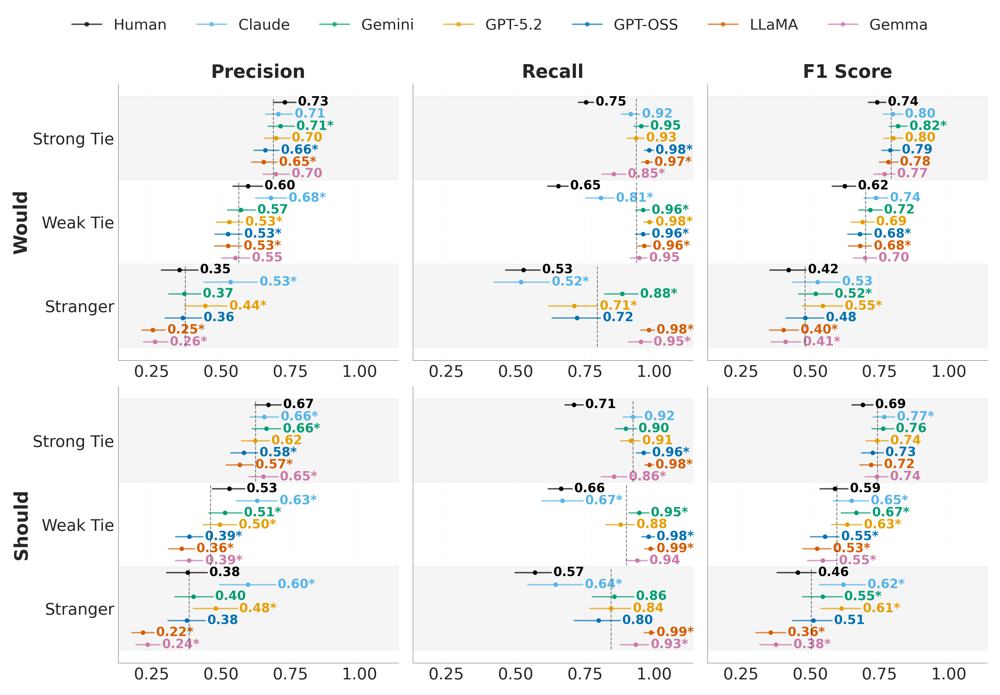

In [191]:
def plot_action_results(results_df, name="model_action_eval.png"):
    FONT_SIZE = 28
    FIG_WIDTH = 36
    FIG_HEIGHT = 16

    metrics = ["precision", "recall", "f1"]
    metric_titles = ["Precision", "Recall", "F1 Score"]

    case_groups = {
        "Would": ["stranger_would", "acq_would", "friend_would"],
        "Should": ["stranger_should", "acq_should", "friend_should"],
    }
    cat_labels = ["Stranger", "Weak Tie", "Strong Tie"]

    model_order = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
    model_labels = ["Claude", "Gemini", "GPT-5.2", "GPT-OSS", "LLaMA", "Gemma"]

    all_order = ["human"] + model_order
    all_labels = ["Human"] + model_labels

    colors = {
        "claude": "#56B4E9",
        "gemini": "#009E73",
        "gpt_5.2": "#E69F00",
        "gpt_oss": "#0072B2",
        "llama": "#D55E00",
        "gemma": "#CC79A7",
        "human": "#000000",
    }

    n_all = len(all_order)
    n_cats = len(cat_labels)

    fig, axes = plt.subplots(
        2, 3,
        figsize=(24, FIG_HEIGHT),
        sharey="row"
    )

    for row_idx, (group_name, case_list) in enumerate(case_groups.items()):
        for col_idx, (metric, title) in enumerate(zip(metrics, metric_titles)):
            ax = axes[row_idx, col_idx]

            for cat_idx, (case_name, cat_label) in enumerate(zip(case_list, cat_labels)):

                if cat_idx % 2 == 0:
                    ax.axhspan(
                        cat_idx * n_all - 0.5,
                        cat_idx * n_all + n_all - 0.5,
                        color="grey",
                        alpha=0.08
                    )

                llm_vals = []

                for model_idx, (model, model_label) in enumerate(
                    zip(all_order[::-1], all_labels[::-1])
                ):
                    row = results_df[
                        (results_df["label_type"] == model) &
                        (results_df["case"] == case_name)
                    ]

                    if len(row) == 0:
                        continue

                    val = row[metric].values[0]
                    lo = row[f"{metric}_ci_lo"].values[0]
                    hi = row[f"{metric}_ci_hi"].values[0]

                    if model != "human":
                        llm_vals.append(val)

                    y_pos = cat_idx * n_all + model_idx

                    ax.plot(
                        [lo, hi], [y_pos, y_pos],
                        color=colors[model],
                        linewidth=2.5,
                        alpha=0.7,
                        solid_capstyle="round"
                    )

                    ax.plot(
                        val, y_pos, "o",
                        color=colors[model],
                        markersize=7,
                        zorder=5,
                        label=(
                            model_label
                            if row_idx == 0 and col_idx == 0 and cat_idx == 0
                            else None
                        )
                    )

                    stars = sig_stars(row[f"{metric}_p"].values[0])
                    label_text = f"{val:.2f}{stars}"

                    ax.text(
                        hi + 0.008,
                        y_pos,
                        label_text,
                        va="center",
                        ha="left",
                        fontsize=FONT_SIZE - 6,
                        color=colors[model],
                        fontweight="bold"
                    )

                # LLM average dashed line (excluding human)
                if llm_vals:
                    avg_val = np.mean(llm_vals)

                    print(
                        f"{group_name} | {cat_label} | {metric}: "
                        f"LLM avg = {avg_val:.3f}"
                    )

                    y_top = cat_idx * n_all - 0.4
                    y_bot = cat_idx * n_all + n_all - 0.6

                    ax.plot(
                        [avg_val, avg_val],
                        [y_top, y_bot],
                        color="black",
                        linewidth=1.5,
                        linestyle="--",
                        alpha=0.5,
                        zorder=4
                    )

            ytick_positions = [
                cat_idx * n_all + (n_all - 1) / 2
                for cat_idx in range(n_cats)
            ]

            ax.set_yticks(ytick_positions)
            ax.set_yticklabels(cat_labels, fontsize=FONT_SIZE)

            ax.set_xlim(0.13, 1.14)
            ax.tick_params(axis="x", labelsize=FONT_SIZE)
            ax.grid(axis="x", alpha=0.25, linestyle="--", linewidth=0.8)
            ax.set_axisbelow(True)

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.spines["left"].set_linewidth(0.5)
            ax.spines["bottom"].set_linewidth(0.5)

            if row_idx == 0:
                ax.set_title(
                    title,
                    fontsize=FONT_SIZE + 4,
                    fontweight="bold",
                    pad=10
                )

        axes[row_idx, 0].set_ylabel(
            group_name,
            fontsize=FONT_SIZE + 4,
            fontweight="bold"
        )

    legend_handles = [
        Line2D(
            [0], [0],
            color=colors[model],
            marker="o",
            markersize=7,
            linewidth=2.5,
            alpha=0.7,
            label=model_label
        )
        for model, model_label in zip(all_order, all_labels)
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=n_all,
        fontsize=FONT_SIZE - 2,
        frameon=False
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(os.path.join(figure_output_path, name), dpi=300, bbox_inches="tight")
    plt.show()

    return fig, axes

fig, axes = plot_action_results(results_df)

##### Stratified Gender Analysis

In [192]:
df_gender_actions = binarize_actions(df_benchmark_gender)

df_agg_gender_actions, df_human_gender_actions, df_llm_gender_actions, IDs_gender_actions = (
    agg_human_llm_ids(df_gender_actions)
)

# Restore main_ID mapping
id_map = df_benchmark_gender[["ID", "main_ID"]].drop_duplicates()

assert id_map["ID"].is_unique
assert id_map["main_ID"].notna().all()

if "main_ID" not in df_agg_gender_actions.columns:
    df_agg_gender_actions = df_agg_gender_actions.merge(
        id_map,
        on="ID",
        how="left",
        validate="many_to_one"
    )

# Verify all gender-specific IDs have an underlying scenario
assert df_agg_gender_actions["main_ID"].notna().all()
assert set(IDs_gender_actions).issubset(set(id_map["ID"]))

# Evaluate
results_df_gender_actions = llm_action_eval(
    df_human_gender_actions,
    df_agg_gender_actions,
    df_llm_gender_actions,
    IDs_gender_actions,
    cases=cases_all,
    leave_one_out=True,
    bootstrap_sample=False
)

results_df_gender_actions

,label_type,case,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,llama,acq_would,0.478544,0.958333,0.638335,0.506509,0.441620,0.516130,0.000500,0.002999,...,0.000500,0.002999,0.603170,0.671618,0.044478,0.177911,0.469121,0.541086,0.000500,0.002999
1,llama,stranger_would,0.283019,0.958904,0.437045,0.359763,0.249333,0.318922,0.000500,0.002999,...,0.000500,0.002999,0.395675,0.478761,0.002999,0.014993,0.325029,0.394408,0.000500,0.002999
2,llama,friend_would,0.624021,0.961771,0.756928,0.636686,0.586251,0.661899,0.000500,0.002999,...,0.000500,0.002999,0.726975,0.786161,0.190405,0.458771,0.600933,0.672942,0.001999,0.009995
3,llama,stranger_should,0.236911,0.967914,0.380652,0.302959,0.202824,0.270594,0.000500,0.002999,...,0.000500,0.002999,0.335448,0.422653,0.000500,0.002999,0.267288,0.336502,0.000500,0.002999
4,llama,acq_should,0.341146,0.970370,0.504817,0.391716,0.302353,0.380267,0.000500,0.002999,...,0.000500,0.002999,0.461688,0.546650,0.000500,0.002999,0.353568,0.429430,0.000500,0.002999
5,llama,friend_should,0.526110,0.971084,0.682472,0.556213,0.486737,0.567640,0.000500,0.002999,...,0.000500,0.002999,0.647666,0.717399,0.007496,0.037481,0.519620,0.595505,0.000500,0.002999
6,human,stranger_should,0.365385,0.524862,0.430839,0.694771,0.303568,0.422884,NaN,NaN,...,NaN,NaN,0.365806,0.485792,NaN,NaN,0.665732,0.721627,NaN,NaN
7,human,stranger_would,0.361019,0.517460,0.425310,0.642886,0.303492,0.420110,NaN,NaN,...,NaN,NaN,0.365506,0.483427,NaN,NaN,0.614636,0.671730,NaN,NaN
8,human,friend_would,0.705845,0.755269,0.729721,0.666396,0.666211,0.743752,NaN,NaN,...,NaN,NaN,0.696521,0.761790,NaN,NaN,0.635641,0.695990,NaN,NaN
9,human,acq_should,0.494307,0.623952,0.551615,0.656668,0.441557,0.546432,NaN,NaN,...,NaN,NaN,0.501323,0.599798,NaN,NaN,0.628390,0.686379,NaN,NaN


Would | Stranger | precision: LLM avg = 0.404
Would | Weak Tie | precision: LLM avg = 0.513
Would | Strong Tie | precision: LLM avg = 0.665
Would | Stranger | recall: LLM avg = 0.699
Would | Weak Tie | recall: LLM avg = 0.906
Would | Strong Tie | recall: LLM avg = 0.907
Would | Stranger | f1: LLM avg = 0.481
Would | Weak Tie | f1: LLM avg = 0.650
Would | Strong Tie | f1: LLM avg = 0.766
Should | Stranger | precision: LLM avg = 0.397
Should | Weak Tie | precision: LLM avg = 0.444
Should | Strong Tie | precision: LLM avg = 0.588
Should | Stranger | recall: LLM avg = 0.730
Should | Weak Tie | recall: LLM avg = 0.840
Should | Strong Tie | recall: LLM avg = 0.888
Should | Stranger | f1: LLM avg = 0.486
Should | Weak Tie | f1: LLM avg = 0.566
Should | Strong Tie | f1: LLM avg = 0.705


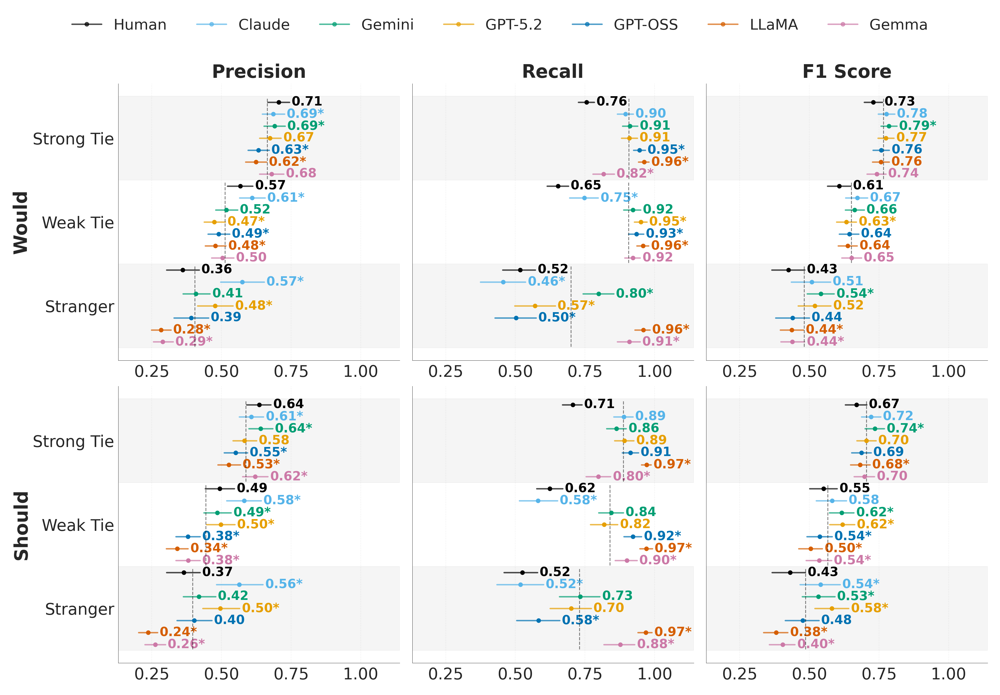

In [193]:
fig, axes = plot_action_results(results_df_gender_actions, name="model_action_eval_gender.png")

### Action Distribution

In [194]:
y_true_series = {}

for case_name, col in cases_all.items():
    y_true_series[case_name] = human_consensus(df_agg, col, True)

In [195]:
y_true_series

{'friend_would': ID
 1      1
 2      1
 3      1
 4      1
 5      1
       ..
 447    1
 448    1
 449    0
 450    1
 451    1
 Name: friends_reaction_bin, Length: 442, dtype: int64,
 'friend_should': ID
 1      1
 2      1
 3      1
 4      1
 5      0
       ..
 447    0
 448    1
 449    0
 450    1
 451    1
 Name: friends_reaction_should_bin, Length: 442, dtype: int64,
 'acq_would': ID
 1      0
 2      1
 3      1
 4      0
 5      0
       ..
 447    1
 448    1
 449    1
 450    1
 451    1
 Name: acquaintances_reaction_bin, Length: 442, dtype: int64,
 'acq_should': ID
 1      0
 2      1
 3      0
 4      0
 5      0
       ..
 447    0
 448    1
 449    0
 450    1
 451    0
 Name: acquaintances_reaction_should_bin, Length: 442, dtype: int64,
 'stranger_would': ID
 1      0
 2      1
 3      0
 4      0
 5      0
       ..
 447    0
 448    1
 449    1
 450    1
 451    0
 Name: strangers_reaction_bin, Length: 442, dtype: int64,
 'stranger_should': ID
 1      0
 2      1
 

In [196]:
props = pd.DataFrame({
    'Friend': [y_true_series['friend_would'].sum() / y_true_series['friend_would'].count(),
               y_true_series['friend_should'].sum() / y_true_series['friend_should'].count(),],
    'Acquaintance': [y_true_series['acq_would'].sum() / y_true_series['acq_would'].count(),
                     y_true_series['acq_should'].sum() / y_true_series['acq_should'].count(),],
    'Stranger': [y_true_series['stranger_would'].sum() / y_true_series['stranger_would'].count(),
                 y_true_series['stranger_should'].sum() / y_true_series['stranger_should'].count()],
}, index=['Would', 'Should'])

props

,Friend,Acquaintance,Stranger
Would,0.617647,0.504525,0.235294
Should,0.531674,0.334842,0.205882


### Individual Actions

In [197]:
ACTIONS = {
    1: "Do nothing",
    2: "Stay away",
    3: "Gossip",
    4: "Verbal confrontation",
    5: "Physical confrontation",
    6: "Inform authority",
    7: "Support",
    8: "Praise",
}

ACTION_NORMALIZATION = {
    "Do nothing": 1,

    "Stay away": 2,
    "Stay away or keep a distance from the actor": 2,

    "Gossip": 3,
    "Gossip about / discuss with / complain to others informally": 3,

    "Verbal confrontation": 4,
    "Verbal reprimand / verbal confrontation": 4,

    "Physical confrontation": 5,

    "Inform authority": 6,
    "Inform the authorities, such as the police": 6,

    "Support": 7,
    "Support the actor": 7,

    "Praise": 8,
    "Celebrate / praise": 8,
}

REACTION_COLS = {
    ("friends", "would"): "friends_reaction",
    ("friends", "should"): "friends_reaction_should",
    ("acquaintances", "would"): "acquaintances_reaction",
    ("acquaintances", "should"): "acquaintances_reaction_should",
    ("strangers", "would"): "strangers_reaction",
    ("strangers", "should"): "strangers_reaction_should",
}

def normalize_action(action):
    if pd.isna(action):
        return None
    return ACTION_NORMALIZATION.get(action.strip(), None)


def build_action_vector_union(actions):
    """Union (used for models)"""
    vec = np.zeros(8, dtype=int)
    for a in actions:
        if a is not None:
            vec[a - 1] = 1
    return vec


def build_action_vector_consensus(actions, n_annotators):
    """Consensus = majority of annotators"""
    counts = pd.Series(actions).value_counts()
    threshold = n_annotators / 2

    vec = np.zeros(8, dtype=int)
    for a, c in counts.items():
        if a is not None and c > threshold:
            vec[a - 1] = 1
    return vec

# Build vectors
rows = []

for (ID, rater), sub in df.groupby(["ID", "label_type"]):
    for (distance, mode), col in REACTION_COLS.items():
        actions = sub[col].apply(normalize_action)

        if rater == "human":
            # Aggregate to one action per annotator per ID
            sub_actions = pd.DataFrame({
                "human_id": sub["human_id"].values,
                "action": actions.values
            }).dropna(subset=["action"])


            # Each annotator contributes at most once per action
            agg_actions = sub_actions.drop_duplicates(
                subset=["human_id", "action"]
            )

            n_annotators = agg_actions["human_id"].nunique()

            vec = build_action_vector_consensus(agg_actions["action"].values, n_annotators)

            # # Take max action per annotator (strongest reaction)
            # agg_actions = sub_actions.groupby("human_id")["action"].max()

            # n_annotators = agg_actions.nunique() if len(agg_actions) > 0 else 0
            # n_annotators = len(agg_actions)  # count of unique annotators who responded
            # vec = build_action_vector_consensus(agg_actions.values, n_annotators)
        else:
            vec = build_action_vector_union(actions)

        rows.append({
            "ID": ID,
            "label_type": rater,
            "distance": distance,
            "mode": mode,
            "vector": vec,
        })

vectors_df = pd.DataFrame(rows)

# Align human + models
pivot = (
    vectors_df
    .pivot(index=["ID", "distance", "mode"], columns="label_type", values="vector")
    .dropna()
)

def extract_matrix(pivot, label, distance, mode):
    return np.vstack(
        pivot.loc[(slice(None), distance, mode), label].values
    )

labels = ["human", "llama", "gemma", "gpt_oss", "claude", "gemini", "gpt_5.2"]
distances = ["friends", "acquaintances", "strangers"]
modes = ["would", "should"]

# Extract matrices
matrices = {}

for label in labels:
    for dist in distances:
        for mode in modes:

            key = f"{label}_{dist}_{mode}"

            matrices[key] = extract_matrix(pivot, label, dist, mode)

# HUMAN
human_friend_would_X = matrices["human_friends_would"]
human_friend_should_X = matrices["human_friends_should"]

human_acq_would_X = matrices["human_acquaintances_would"]
human_acq_should_X = matrices["human_acquaintances_should"]

human_str_would_X = matrices["human_strangers_would"]
human_str_should_X = matrices["human_strangers_should"]

# GPT
gpt_friend_would_X = matrices["gpt_5.2_friends_would"]
gpt_friend_should_X = matrices["gpt_5.2_friends_should"]

gpt_acq_would_X = matrices["gpt_5.2_acquaintances_would"]
gpt_acq_should_X = matrices["gpt_5.2_acquaintances_should"]

gpt_str_would_X = matrices["gpt_5.2_strangers_would"]
gpt_str_should_X = matrices["gpt_5.2_strangers_should"]

# CLAUDE
claude_friend_would_X = matrices["claude_friends_would"]
claude_friend_should_X = matrices["claude_friends_should"]

claude_acq_would_X = matrices["claude_acquaintances_would"]
claude_acq_should_X = matrices["claude_acquaintances_should"]

claude_str_would_X = matrices["claude_strangers_would"]
claude_str_should_X = matrices["claude_strangers_should"]

# GEMINI
gemini_friend_would_X = matrices["gemini_friends_would"]
gemini_friend_should_X = matrices["gemini_friends_should"]

gemini_acq_would_X = matrices["gemini_acquaintances_would"]
gemini_acq_should_X = matrices["gemini_acquaintances_should"]

gemini_str_would_X = matrices["gemini_strangers_would"]
gemini_str_should_X = matrices["gemini_strangers_should"]

# GPT OSS
gpt_oss_friend_would_X = matrices["gpt_oss_friends_would"]
gpt_oss_friend_should_X = matrices["gpt_oss_friends_should"]

gpt_oss_acq_would_X = matrices["gpt_oss_acquaintances_would"]
gpt_oss_acq_should_X = matrices["gpt_oss_acquaintances_should"]

gpt_oss_str_would_X = matrices["gpt_oss_strangers_would"]
gpt_oss_str_should_X = matrices["gpt_oss_strangers_should"]

# LLAMA
llama_friend_would_X = matrices["llama_friends_would"]
llama_friend_should_X = matrices["llama_friends_should"]

llama_acq_would_X = matrices["llama_acquaintances_would"]
llama_acq_should_X = matrices["llama_acquaintances_should"]

llama_str_would_X = matrices["llama_strangers_would"]
llama_str_should_X = matrices["llama_strangers_should"]

# GEMMA
gemma_friend_would_X = matrices["gemma_friends_would"]
gemma_friend_should_X = matrices["gemma_friends_should"]

gemma_acq_would_X = matrices["gemma_acquaintances_would"]
gemma_acq_should_X = matrices["gemma_acquaintances_should"]

gemma_str_would_X = matrices["gemma_strangers_would"]
gemma_str_should_X = matrices["gemma_strangers_should"]

In [198]:
action_names = list(ACTIONS.values())
llm_labels = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
distances = ["friends", "acquaintances", "strangers"]
modes = ["would", "should"]

results = []

for dist in distances:
    for mode in modes:
        for act_idx, act_name in enumerate(action_names):

            y_true_dict = {}
            y_pred_dict = {}
            metrics_dict = {}

            h_key = f"human_{dist}_{mode}"
            h_matrix = matrices[h_key]

            # One cluster per scenario (matrix row)
            cluster_ids = np.arange(h_matrix.shape[0])

            for model in llm_labels:
                m_key = f"{model}_{dist}_{mode}"
                m_matrix = matrices[m_key]

                assert m_matrix.shape[0] == h_matrix.shape[0]

                y_true = pd.Series(h_matrix[:, act_idx])
                y_pred = pd.Series(m_matrix[:, act_idx])

                y_true_dict[model] = y_true
                y_pred_dict[model] = y_pred
                metrics_dict[model] = compute_metrics(
                    y_true.values, y_pred.values
                )

            boot_results = bootstrap_ci_with_significance(
                y_true_dict,
                y_pred_dict,
                cluster_ids=cluster_ids
            )

            for model in llm_labels:
                results.append({
                    "label_type": model,
                    "distance": dist,
                    "mode": mode,
                    "action": act_name,
                    **metrics_dict[model],
                    **boot_results[model],
                })

results_action_df = pd.DataFrame(results)
results_action_df

,label_type,distance,mode,action,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,claude,friends,would,Do nothing,0.181818,0.368421,0.243478,0.803167,0.095719,0.268671,...,0.026987,0.080960,0.137222,0.344840,0.205897,1.0,0.764706,0.839367,0.006497,0.012994
1,gemini,friends,would,Do nothing,0.191489,0.236842,0.211765,0.848416,0.084710,0.306122,...,1.000000,1.000000,0.095210,0.321839,0.629685,1.0,0.816742,0.882353,0.297351,0.297351
2,gpt_5.2,friends,would,Do nothing,0.285714,0.105263,0.153846,0.900452,0.071429,0.538462,...,0.001000,0.004998,0.038462,0.285714,0.365817,1.0,0.871041,0.927602,0.000500,0.002999
3,gpt_oss,friends,would,Do nothing,0.200000,0.184211,0.191781,0.866516,0.081054,0.333333,...,0.273863,0.547726,0.078419,0.311126,0.999500,1.0,0.834842,0.898190,0.002499,0.007496
4,llama,friends,would,Do nothing,0.285714,0.105263,0.153846,0.900452,0.071429,0.545455,...,0.000500,0.002999,0.037736,0.290337,0.381809,1.0,0.871041,0.927602,0.000500,0.002999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,gemini,strangers,should,Praise,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
284,gpt_5.2,strangers,should,Praise,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
285,gpt_oss,strangers,should,Praise,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
286,llama,strangers,should,Praise,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000


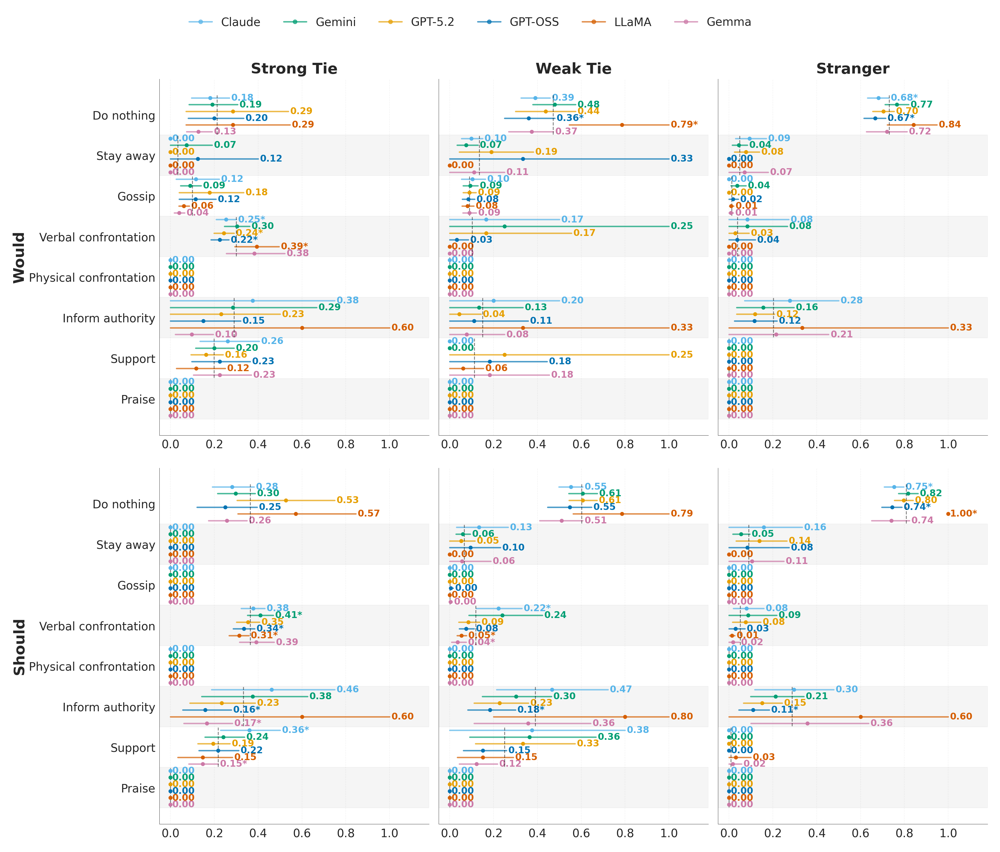

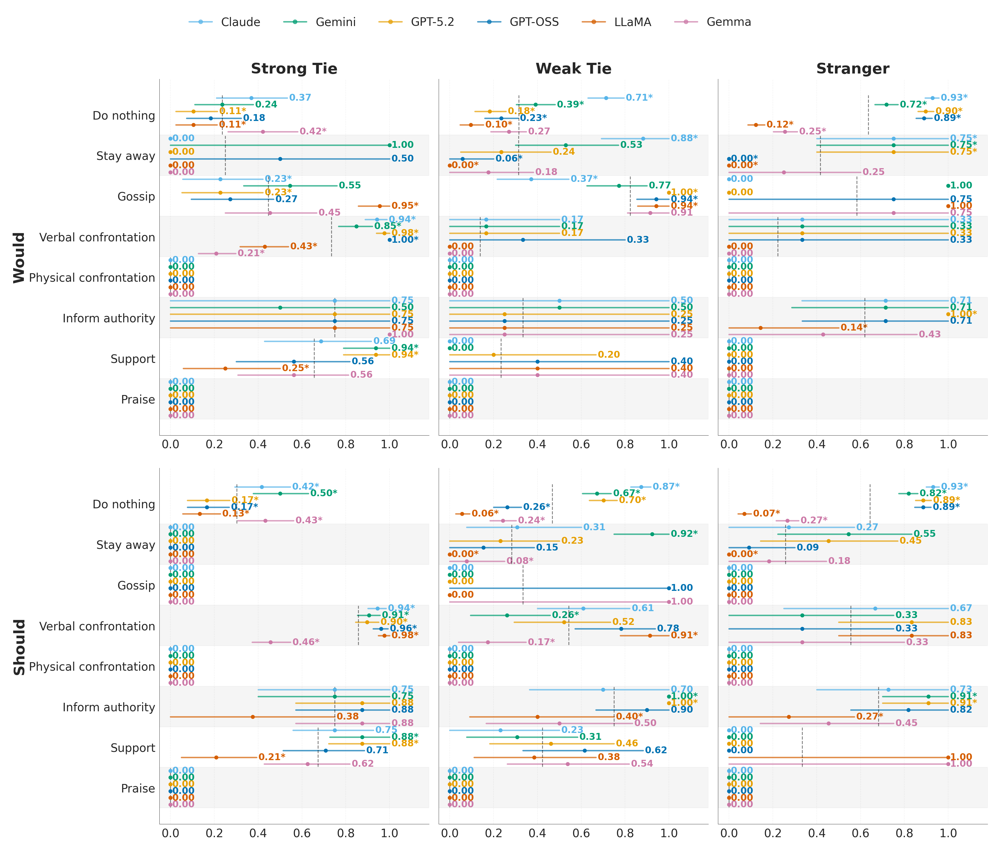

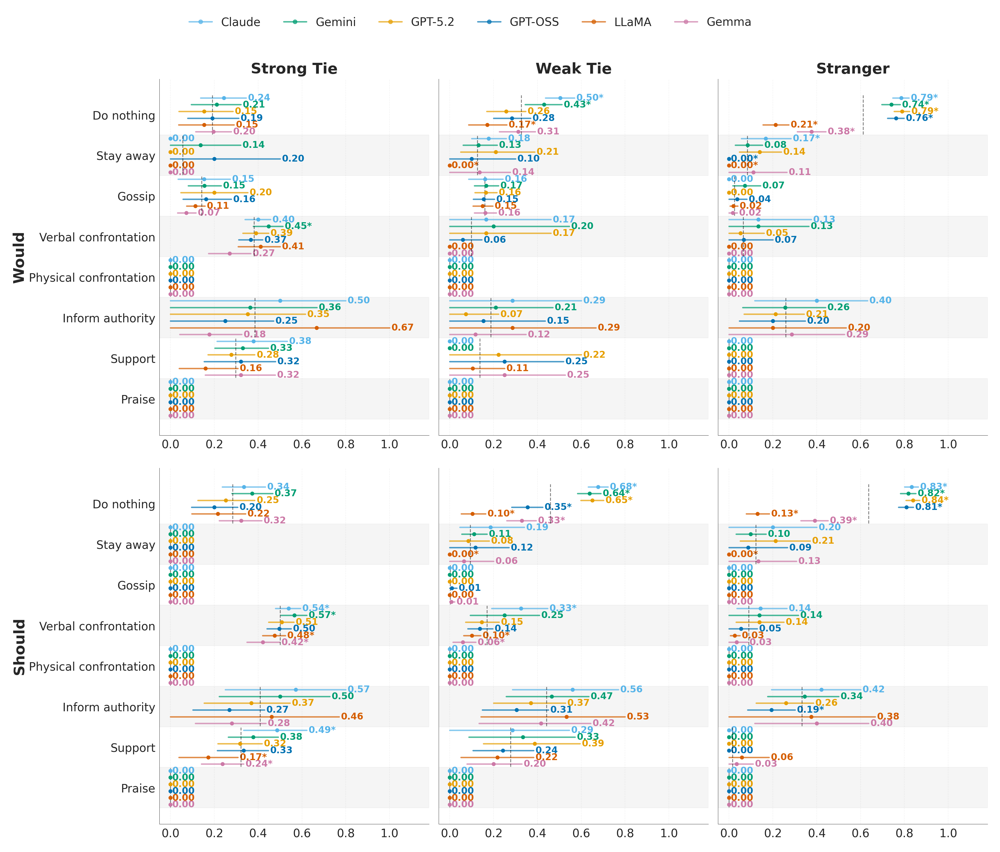

In [199]:
FONT_SIZE = 24
FIG_WIDTH = 24
FIG_HEIGHT = 10

action_names_ordered = [
    "Do nothing", "Stay away", "Gossip",
    "Verbal confrontation", "Physical confrontation",
    "Inform authority", "Support", "Praise",
]

distance_labels = {
    "friends": "Strong Tie",
    "acquaintances": "Weak Tie",
    "strangers": "Stranger",
}

model_order = ["claude", "gemini", "gpt_5.2", "gpt_oss", "llama", "gemma"]
model_labels = ["Claude", "Gemini", "GPT-5.2", "GPT-OSS", "LLaMA", "Gemma"]

colors = {
    "claude": "#56B4E9",
    "gemini": "#009E73",
    "gpt_5.2": "#E69F00",
    "gpt_oss": "#0072B2",
    "llama": "#D55E00",
    "gemma": "#CC79A7",
}

n_models = len(model_order)
n_actions = len(action_names_ordered)

metrics = ["precision", "recall", "f1"]
metric_titles = ["Precision", "Recall", "F1 Score"]

modes = ["would", "should"]
mode_labels = ["Would", "Should"]
distances = ["friends", "acquaintances", "strangers"]

for metric, metric_title in zip(metrics, metric_titles):

    fig, axes = plt.subplots(2, 3, figsize=(FIG_WIDTH, FIG_HEIGHT * 2), sharey=True)

    for row_idx, (mode, mode_label) in enumerate(zip(modes, mode_labels)):
        for col_idx, dist in enumerate(distances):
            ax = axes[row_idx, col_idx]

            for act_idx, act_name in enumerate(reversed(action_names_ordered)):
                if act_idx % 2 == 0:
                    ax.axhspan(
                        act_idx * n_models - 0.5,
                        act_idx * n_models + n_models - 0.5,
                        color='grey', alpha=0.08
                    )

                cat_vals = []

                for model_idx, (model, model_label) in enumerate(zip(model_order[::-1], model_labels[::-1])):
                    row = results_action_df[
                        (results_action_df["label_type"] == model) &
                        (results_action_df["distance"] == dist) &
                        (results_action_df["mode"] == mode) &
                        (results_action_df["action"] == act_name)
                    ]

                    if len(row) == 0:
                        continue

                    val = row[metric].values[0]
                    lo = row[f"{metric}_ci_lo"].values[0]
                    hi = row[f"{metric}_ci_hi"].values[0]
                    cat_vals.append(val)

                    y_pos = act_idx * n_models + model_idx

                    ax.plot(
                        [lo, hi], [y_pos, y_pos],
                        color=colors[model], linewidth=2.5, alpha=0.7,
                        solid_capstyle='round'
                    )
                    ax.plot(
                        val, y_pos, 'o',
                        color=colors[model], markersize=6, zorder=5,
                        label=model_label if (row_idx == 0 and col_idx == 0 and act_idx == 0) else None
                    )
                    stars = sig_stars(row[f"{metric}_p"].values[0])
                    label_text = f"{val:.2f}{stars}"
                    ax.text(
                        hi + 0.008, y_pos, label_text,
                        va='center', ha='left',
                        fontsize=FONT_SIZE - 8, color=colors[model], fontweight='bold'
                    )
                # Average line
                if cat_vals:
                    avg_val = np.mean(cat_vals)
                    y_top = act_idx * n_models - 0.4
                    y_bot = act_idx * n_models + n_models - 0.6
                    ax.plot(
                        [avg_val, avg_val], [y_top, y_bot],
                        color='black', linewidth=1.5, linestyle='--', alpha=0.5, zorder=4
                    )

                    # ax.text(
                    #     avg_val, y_top - 0.3, f"{avg_val:.2f}",
                    #     va='bottom', ha='center',
                    #     fontsize=FONT_SIZE - 10, color='black', fontstyle='italic', alpha=0.6
                    # )

            ytick_positions = [act_idx * n_models + (n_models - 1) / 2 for act_idx in range(n_actions)]
            ax.set_yticks(ytick_positions)
            ax.set_yticklabels(list(reversed(action_names_ordered)), fontsize=FONT_SIZE - 4)

            ax.set_xlim(-0.05, 1.18)
            ax.tick_params(axis='x', labelsize=FONT_SIZE - 4)
            ax.grid(axis='x', alpha=0.25, linestyle='--', linewidth=0.8)
            ax.set_axisbelow(True)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(0.5)
            ax.spines['bottom'].set_linewidth(0.5)

            if row_idx == 0:
                ax.set_title(distance_labels[dist], fontsize=FONT_SIZE + 2, fontweight='bold', pad=10)

        axes[row_idx, 0].set_ylabel(mode_label, fontsize=FONT_SIZE + 2, fontweight='bold')

    legend_handles = []
    legend_labels = []
    for model, model_label in zip(model_order, model_labels):
        legend_handles.append(
            Line2D([0], [0], color=colors[model], marker='o', markersize=7,
                   linewidth=2.5, alpha=0.7)
        )
        legend_labels.append(model_label)

    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.47, 1.02),
        ncol=n_models,
        fontsize=FONT_SIZE - 4,
        frameon=False
    )

    # fig.suptitle(metric_title, fontsize=FONT_SIZE + 4, fontweight='bold', y=1.06)
    plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3)
    fig.savefig(os.path.join(figure_output_path, f"action_{metric}.png"), bbox_inches='tight', dpi=300)
    plt.show()

### Minor Agreement (>= 2)

#### Action Distribution

In [200]:
y_true_series = {}

for case_name, col in cases_all.items():
    y_true_series[case_name] = human_consensus(df_human, col)

In [201]:
props = pd.DataFrame({
    'Friend': [y_true_series['friend_would'].sum() / y_true_series['friend_would'].count(),
               y_true_series['friend_should'].sum() / y_true_series['friend_should'].count(),],
    'Acquaintance': [y_true_series['acq_would'].sum() / y_true_series['acq_would'].count(),
                     y_true_series['acq_should'].sum() / y_true_series['acq_should'].count(),],
    'Stranger': [y_true_series['stranger_would'].sum() / y_true_series['stranger_would'].count(),
                 y_true_series['stranger_should'].sum() / y_true_series['stranger_should'].count()],
}, index=['Would', 'Should'])

props

,Friend,Acquaintance,Stranger
Would,0.825792,0.776018,0.592760
Should,0.739819,0.604072,0.459276


### Top-Bottom 25% Agreement

In [202]:
print(list(action_agree.keys()))

['acq_should', 'acq_would', 'friend_should', 'friend_would', 'stranger_should', 'stranger_would']


In [203]:
all_results = []

for i in list(action_agree.keys()):
    cases = {i: cases_all[i]}

    for name, j in zip(["top_25_agreement", "bottom_25_agreement", "top_25_agreement_mean", "bottom_25_agreement_mean"], [action_agree, action_disagree, action_agree_mean, action_disagree_mean]):
        df = binary_emotions(df_benchmark.loc[df_benchmark["ID"].isin(j[i])].copy())
        df_agg, df_human, df_llm, IDs = agg_human_llm_ids(df)
        results_df = llm_action_eval(df_human, df_agg, df_llm, IDs, cases=cases, leave_one_out=True, bootstrap_sample=False)
        results_df["agreement_type"] = name
        all_results.append(results_df)

results_all = pd.concat(all_results, ignore_index=True)

metrics = ["precision", "recall", "f1"]

summary = results_all[results_all["label_type"] != "human"].groupby(["case", "agreement_type"])[metrics].mean().reset_index()
human = results_all[results_all["label_type"] == "human"][["case", "agreement_type"] + metrics].rename(columns={m: f"human_{m}" for m in metrics})

summary = summary.merge(human, on=["case", "agreement_type"], how="left").round(3)
display(summary)

,case,agreement_type,precision,recall,f1,human_precision,human_recall,human_f1
0,acq_should,bottom_25_agreement,0.316,0.839,0.450,0.135,0.206,0.163
1,acq_should,bottom_25_agreement_mean,0.358,0.816,0.486,0.219,0.280,0.246
2,acq_should,top_25_agreement,0.561,0.962,0.693,0.959,0.995,0.977
3,acq_should,top_25_agreement_mean,0.563,0.976,0.678,0.803,0.966,0.877
4,acq_would,bottom_25_agreement,0.302,0.909,0.451,0.000,0.000,0.000
5,acq_would,bottom_25_agreement_mean,0.391,0.894,0.541,0.000,0.000,0.000
6,acq_would,top_25_agreement,0.751,0.977,0.847,0.972,0.962,0.967
7,acq_would,top_25_agreement_mean,0.781,0.996,0.873,0.960,0.933,0.947
8,friend_should,bottom_25_agreement,0.409,0.898,0.561,0.096,0.139,0.114
9,friend_should,bottom_25_agreement_mean,0.558,0.867,0.677,0.293,0.327,0.309


In [204]:
results_all

,label_type,case,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p,agreement_type
0,llama,acq_should,0.382353,1.000000,0.553191,0.427273,0.288462,0.480778,0.000500,0.002999,...,0.041979,0.447761,0.649359,0.000500,0.002999,0.336364,0.518182,0.000500,0.002999,top_25_agreement
1,human,acq_should,0.958974,0.994681,0.976501,0.983083,0.920511,0.983888,NaN,NaN,...,NaN,0.956244,0.990051,NaN,NaN,0.973783,0.992110,NaN,NaN,top_25_agreement
2,gpt_oss,acq_should,0.438202,1.000000,0.609375,0.545455,0.336954,0.541176,0.000500,0.002999,...,0.041979,0.504062,0.702290,0.000500,0.002999,0.454545,0.636364,0.000500,0.002999,top_25_agreement
3,gpt_5.2,acq_should,0.655172,0.974359,0.783505,0.809091,0.527273,0.775510,0.001999,0.002999,...,1.000000,0.681818,0.865385,0.001000,0.002999,0.727273,0.881818,0.000500,0.002999,top_25_agreement
4,gemma,acq_should,0.436782,0.974359,0.603175,0.545455,0.333333,0.541201,0.000500,0.002999,...,1.000000,0.495329,0.696313,0.000500,0.002999,0.454545,0.636364,0.000500,0.002999,top_25_agreement
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,gpt_oss,stranger_would,0.361111,0.722222,0.481481,0.508772,0.205128,0.515204,0.669165,1.000000,...,0.856572,0.304348,0.631579,0.572214,1.000000,0.385965,0.631579,0.461769,0.923538,bottom_25_agreement_mean
164,gpt_5.2,stranger_would,0.387097,0.666667,0.489796,0.561404,0.218750,0.560000,0.346827,1.000000,...,0.851574,0.304348,0.646279,0.496752,1.000000,0.438596,0.701754,0.108446,0.405797,bottom_25_agreement_mean
165,gemma,stranger_would,0.320755,0.944444,0.478873,0.350877,0.199911,0.446429,0.443278,1.000000,...,0.007996,0.322581,0.613333,0.483258,1.000000,0.228070,0.473684,0.008496,0.050975,bottom_25_agreement_mean
166,gemini,stranger_would,0.363636,0.888889,0.516129,0.473684,0.222222,0.500000,0.454273,1.000000,...,0.044978,0.350835,0.647887,0.051974,0.259870,0.350877,0.596491,1.000000,1.000000,bottom_25_agreement_mean


# Sensitivity Analyses

In [205]:
ALL_ACTIONS = [
    "Do nothing",
    "Stay away",
    "Gossip",
    "Verbal confrontation",
    "Physical confrontation",
    "Inform authority",
    "Support",
    "Praise",
]

ALL_EMOTIONS = [
    "Shame",
    "Pride",
    "Compassion",
    "Guilt",
    "Embarrassment",
    "Anger",
    "Contempt",
    "Disgust",
]

In [206]:
def make_long_counts(df, action_map=None, emotion_map=None, id_col="ID", label_col="label_type"):
    """
    Convert reaction/emotion columns to long format and calculate distributions.

    Both reactions and emotions:
    - Deduplicate humans by ID, human_id, actor_gender.
    - Deduplicate LLMs by ID, label_type, actor_gender.

    Reactions:
    - Apply action mapping and calculate percentages within each condition.
    - Percentages sum to 100% within each condition.

    Emotions:
    - Deduplicate actor emotions within each response.
    - Preserve repeated observer emotion occurrences.
    - Count eight major emotions using exact string matches.
    - Include all emotion occurrences in the denominator.
    - Other is displayed for LLMs only.
    """

    COLUMN_MAP = {
        "friends_reaction": ("reaction", "Strong tie", "Would"),
        "friends_reaction_should": ("reaction", "Strong tie", "Should"),
        "acquaintances_reaction": ("reaction", "Weak tie", "Would"),
        "acquaintances_reaction_should": ("reaction", "Weak tie", "Should"),
        "strangers_reaction": ("reaction", "Stranger", "Would"),
        "strangers_reaction_should": ("reaction", "Stranger", "Should"),
        "actor_emotions": ("emotion", "Actor", "Would"),
        "friends_emotions": ("emotion", "Strong tie", "Would"),
        "acquaintances_emotions": ("emotion", "Weak tie", "Would"),
        "strangers_emotions": ("emotion", "Stranger", "Would"),
    }

    available_cols = [col for col in COLUMN_MAP if col in df.columns]

    if not available_cols:
        raise ValueError("No recognized reaction or emotion columns found.")

    id_vars = [col for col in [id_col, label_col] if col in df.columns]
    condition_cols = ([label_col] if label_col in df.columns else []) + ["outcome_type", "response_type", "distance"]

    # --------------------------------------------------
    # DEDUPLICATE — for both reactions and emotions
    # --------------------------------------------------
    df_human = df[df[label_col] == "human"].drop_duplicates([id_col, "human_id", "actor_gender"])
    df_llm = df[df[label_col] != "human"].drop_duplicates([id_col, label_col, "actor_gender"])
    df_clean = pd.concat([df_human, df_llm], ignore_index=True).copy()

    # --------------------------------------------------
    # REACTIONS
    # --------------------------------------------------
    reaction_cols = [col for col in available_cols if COLUMN_MAP[col][0] == "reaction"]
    reaction_long = pd.DataFrame()
    reaction_counts = pd.DataFrame()

    if reaction_cols:
        df_work = df_clean.copy()
        df_work["_row_id"] = range(len(df_work))

        reaction_long = df_work[id_vars + ["_row_id"] + reaction_cols].melt(
            id_vars=id_vars + ["_row_id"], value_vars=reaction_cols,
            var_name="source_column", value_name="value_raw"
        ).dropna(subset=["value_raw"])

        reaction_long["outcome_type"] = "reaction"
        reaction_long["distance"] = reaction_long["source_column"].map(lambda x: COLUMN_MAP[x][1])
        reaction_long["response_type"] = reaction_long["source_column"].map(lambda x: COLUMN_MAP[x][2])

        reaction_long = reaction_long[reaction_long["value_raw"].notna() & reaction_long["value_raw"].ne("")].copy()
        reaction_long["value"] = reaction_long["value_raw"]

        if action_map is not None:
            reaction_long["value"] = reaction_long["value_raw"].map(action_map)

        reaction_long = reaction_long.dropna(subset=["value"])

        reaction_counts = reaction_long.groupby(condition_cols + ["value"]).size().reset_index(name="count")
        conditions = reaction_long[condition_cols].drop_duplicates().reset_index(drop=True)

        complete_rows = []
        for _, condition in conditions.iterrows():
            for value in ALL_ACTIONS:
                complete_rows.append({**condition.to_dict(), "value": value})

        complete_index = pd.DataFrame(complete_rows)
        reaction_counts = complete_index.merge(reaction_counts, on=condition_cols + ["value"], how="left")
        reaction_counts["count"] = reaction_counts["count"].fillna(0).astype(int)

        reaction_totals = reaction_counts.groupby(condition_cols)["count"].transform("sum")
        reaction_counts["percent"] = reaction_counts["count"].div(reaction_totals).mul(100).where(reaction_totals > 0, 0)

    # --------------------------------------------------
    # EMOTIONS
    # --------------------------------------------------
    emotion_cols = [col for col in available_cols if COLUMN_MAP[col][0] == "emotion"]
    emotion_long = pd.DataFrame()
    emotion_counts = pd.DataFrame()

    if emotion_cols:
        major_emotions = ["Shame", "Guilt", "Embarrassment", "Contempt", "Disgust", "Anger", "Pride", "Compassion"]
        df_emotions = df_clean.copy()

        def split_emotions_dist(x):
            if pd.isna(x):
                return []
            return [e.strip() for e in str(x).split(",") if e.strip()]

        df_emotions["_row_id"] = range(len(df_emotions))

        if "actor_emotions" in emotion_cols:
            df_emotions["self_emotion_list"] = df_emotions["actor_emotions"].apply(split_emotions_dist).apply(lambda lst: sorted(set(lst)))

        for col in emotion_cols:
            if col != "actor_emotions":
                df_emotions[f"{col}_list"] = df_emotions[col].apply(split_emotions_dist)

        emotion_records = []

        for _, row in df_emotions.iterrows():
            for col in emotion_cols:
                values = row["self_emotion_list"] if col == "actor_emotions" else row[f"{col}_list"]

                for raw_value in values:
                    value = raw_value if raw_value in major_emotions else "Other"

                    emotion_records.append({
                        **{c: row[c] for c in id_vars},
                        "_row_id": row["_row_id"],
                        "source_column": col,
                        "value_raw": raw_value,
                        "outcome_type": "emotion",
                        "distance": COLUMN_MAP[col][1],
                        "response_type": COLUMN_MAP[col][2],
                        "value": value,
                    })

        emotion_long = pd.DataFrame(
            emotion_records,
            columns=id_vars + ["_row_id", "source_column", "value_raw", "outcome_type", "distance", "response_type", "value"]
        )

        emotion_totals = emotion_long.groupby(condition_cols).size().rename("emotion_total").reset_index()
        observed_counts = emotion_long.groupby(condition_cols + ["value"]).size().reset_index(name="count")

        condition_records = []
        for model in df_emotions[label_col].dropna().unique():
            for col in emotion_cols:
                condition_records.append({
                    label_col: model,
                    "outcome_type": "emotion",
                    "response_type": COLUMN_MAP[col][2],
                    "distance": COLUMN_MAP[col][1],
                })

        conditions = pd.DataFrame(condition_records).drop_duplicates()

        complete_rows = []
        for _, condition in conditions.iterrows():
            values = major_emotions if condition[label_col] == "human" else major_emotions + ["Other"]
            for value in values:
                complete_rows.append({**condition.to_dict(), "value": value})

        emotion_counts = pd.DataFrame(complete_rows)
        emotion_counts = emotion_counts.merge(observed_counts, on=condition_cols + ["value"], how="left")
        emotion_counts = emotion_counts.merge(emotion_totals, on=condition_cols, how="left")

        emotion_counts["count"] = emotion_counts["count"].fillna(0).astype(int)
        emotion_counts["emotion_total"] = emotion_counts["emotion_total"].fillna(0)
        emotion_counts["percent"] = emotion_counts["count"].div(emotion_counts["emotion_total"]).mul(100).where(emotion_counts["emotion_total"] > 0, 0)
        emotion_counts = emotion_counts.drop(columns=["emotion_total"])

    # --------------------------------------------------
    # COMBINE RESULTS
    # --------------------------------------------------
    long_parts = [x for x in [reaction_long, emotion_long] if not x.empty]
    count_parts = [x for x in [reaction_counts, emotion_counts] if not x.empty]

    long_df = pd.concat(long_parts, ignore_index=True) if long_parts else pd.DataFrame()
    counts = pd.concat(count_parts, ignore_index=True) if count_parts else pd.DataFrame()

    if "_row_id" in long_df.columns:
        long_df = long_df.drop(columns=["_row_id"])

    return long_df, counts

In [207]:
def display_count_tables(counts, outcome_type=None, label_col="label_type", decimals=1):
    """
    Display count (%) tables from long-format counts.

    Uses the precomputed percent column rather than recalculating
    percentages from displayed categories.

    For pooled emotion percentages, preserves the original denominator
    when human Other is not displayed.
    """

    df = counts.copy()

    if outcome_type is not None:
        if "outcome_type" not in df.columns:
            raise ValueError("'outcome_type' column not found in counts.")
        df = df[df["outcome_type"] == outcome_type]

    if df.empty:
        raise ValueError("No data available for the requested condition.")

    outcome_types = df["outcome_type"].dropna().unique() if "outcome_type" in df.columns else [None]
    tables = {}

    for outcome in outcome_types:
        df_outcome = df[df["outcome_type"] == outcome] if outcome is not None else df.copy()
        model_names = df_outcome[label_col].dropna().unique() if label_col in df_outcome.columns else [None]
        response_types = df_outcome["response_type"].dropna().unique() if "response_type" in df_outcome.columns else [None]

        for model_name in model_names:
            for response_type in response_types:
                subset = df_outcome.copy()

                if model_name is not None:
                    subset = subset[subset[label_col] == model_name]

                if response_type is not None:
                    subset = subset[subset["response_type"] == response_type]

                if subset.empty:
                    continue

                distances = subset["distance"].dropna().unique().tolist()
                values = subset["value"].dropna().unique().tolist()
                rows = []

                # Recover original denominators using count / percent
                denominators = {}

                for dist in distances:
                    dist_df = subset[subset["distance"] == dist]
                    nonzero = dist_df[(dist_df["count"] > 0) & (dist_df["percent"] > 0)]

                    if not nonzero.empty:
                        denominators[dist] = round(nonzero.iloc[0]["count"] / (nonzero.iloc[0]["percent"] / 100))
                    else:
                        denominators[dist] = 0

                for value in values:
                    row = {"Value": value}
                    overall_count = 0

                    for dist in distances:
                        r = subset[(subset["distance"] == dist) & (subset["value"] == value)]

                        if not r.empty:
                            c = int(r["count"].sum())
                            p = float(r["percent"].iloc[0])
                        else:
                            c, p = 0, 0.0

                        row[dist] = f"{c:,} ({p:.{decimals}f}%)"
                        overall_count += c

                    overall_total = sum(denominators.values())
                    overall_pct = overall_count / overall_total * 100 if overall_total > 0 else 0
                    row["Overall"] = f"{overall_count:,} ({overall_pct:.{decimals}f}%)"
                    rows.append(row)

                table = pd.DataFrame(rows).set_index("Value")

                key_parts = [str(x) for x in [outcome, model_name, response_type] if x is not None]
                key = " — ".join(key_parts)
                tables[key] = table

                print(f"\n{'=' * 80}")
                print(f"  {key}")
                print(f"{'=' * 80}")
                display(table)

    return table

## Pre- vs Post-training Differences


In [208]:
df_base_exp = pd.read_csv(PROCESSED / 'gemma_llama_base_exp.csv.gz')
df_base_exp = df_base_exp.rename(columns={
    'stimuli_id': 'ID',
    'rater_type': 'label_type',
    'friends_reaction_would': 'friends_reaction',
    'acquaintances_reaction_would': 'acquaintances_reaction',
    'strangers_reaction_would': 'strangers_reaction',
    })
df_base_exp

,ID,stimuli,actor,actor_gender,label_type,friends_reaction,friends_reaction_should,acquaintances_reaction,acquaintances_reaction_should,strangers_reaction,strangers_reaction_should,human_id
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Support,Do nothing,Support,Do nothing,Do nothing,Do nothing,R_7JCKEF65rh5eA8Y
1,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Stay away,Stay away,Stay away,Stay away,Stay away,Stay away,R_7o9lY3vQcqsE4pP
2,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Verbal confrontation,Verbal confrontation,Do nothing,Do nothing,Stay away,Do nothing,R_3R48rDclzghStqN
3,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Verbal confrontation,Gossip,Do nothing,Do nothing,Do nothing,Do nothing,R_1bHJcpADL6ZNNEJ
4,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Support,Support,Support,Support,Support,Support,R_6r37TI1xGGUVeaA
...,...,...,...,...,...,...,...,...,...,...,...,...
7726,449,Richard reads things in a British accent even though he's Canadian.,Richard,male,llama_pt,Praise,Stay away,Stay away,Stay away,Stay away,Do nothing,NaN
7727,449,Jennifer reads things in a British accent even though she's Canadian.,Jennifer,female,llama_pt,Gossip,Gossip,Gossip,Stay away,Stay away,Do nothing,NaN
7728,450,Charles touched a passed-out girl inappropriately.,Charles,male,llama_pt,Inform authority,Inform authority,Inform authority,Inform authority,Inform authority,Inform authority,NaN
7729,450,Elizabeth touched a passed-out guy inappropriately.,Elizabeth,female,llama_pt,Stay away,Stay away,Inform authority,Stay away,Inform authority,Do nothing,NaN


In [209]:
df_base_exp['label_type'].unique()

array(['human', 'gemma_ft', 'gemma_ft_bf16', 'llama_ft', 'llama_ft_bf16',
       'gemma_pt', 'llama_pt'], dtype=object)

In [210]:
reaction_cols = [
    "friends_reaction",
    "friends_reaction_should",
    "acquaintances_reaction",
    "acquaintances_reaction_should",
    "strangers_reaction",
    "strangers_reaction_should",
]

# Identify missing reactions in llama_pt
llama = df_base_exp.loc[df_base_exp["label_type"] == "llama_pt"]

missing = llama.melt(
    id_vars=["ID", "actor_gender"],
    value_vars=reaction_cols,
    var_name="reaction_col",
    value_name="reaction",
)

missing = missing.loc[
    missing["reaction"].isna(),
    ["ID", "actor_gender", "reaction_col"]
]

print("Missing reactions:", len(missing))

# Set the same six observations to NaN for every label_type
for row in missing.itertuples(index=False):
    mask = (
        (df_base_exp["ID"] == row.ID)
        & (df_base_exp["actor_gender"] == row.actor_gender)
    )
    df_base_exp.loc[mask, row.reaction_col] = np.nan

df_base_exp.groupby("label_type")[reaction_cols].apply(
    lambda x: x.isna().sum().sum()
)

Missing reactions: 1


,0
label_type,
gemma_ft,1
gemma_ft_bf16,1
gemma_pt,1
human,2
llama_ft,1
llama_ft_bf16,1
llama_pt,1


In [211]:
df_long, counts = make_long_counts(
    df_base_exp,
    action_map=ACTION_CANONICAL_MAP,
)
counts

,label_type,outcome_type,response_type,distance,value,count,percent
0,human,reaction,Would,Strong tie,Do nothing,580,22.196709
1,human,reaction,Would,Strong tie,Stay away,162,6.199770
2,human,reaction,Would,Strong tie,Gossip,519,19.862227
3,human,reaction,Would,Strong tie,Verbal confrontation,848,32.453119
4,human,reaction,Would,Strong tie,Physical confrontation,70,2.678913
...,...,...,...,...,...,...,...
331,llama_pt,reaction,Should,Stranger,Verbal confrontation,0,0.000000
332,llama_pt,reaction,Should,Stranger,Physical confrontation,0,0.000000
333,llama_pt,reaction,Should,Stranger,Inform authority,198,23.212192
334,llama_pt,reaction,Should,Stranger,Support,6,0.703400


In [212]:
reaction_tables = display_count_tables(
    counts,
    outcome_type="reaction",
)


  reaction — human — Would


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,580 (22.2%),986 (37.8%),"1,576 (60.3%)","3,142 (40.1%)"
Stay away,162 (6.2%),374 (14.3%),407 (15.6%),943 (12.0%)
Gossip,519 (19.9%),644 (24.7%),251 (9.6%),"1,414 (18.0%)"
Verbal confrontation,848 (32.5%),287 (11.0%),175 (6.7%),"1,310 (16.7%)"
Physical confrontation,70 (2.7%),38 (1.5%),35 (1.3%),143 (1.8%)
Inform authority,58 (2.2%),73 (2.8%),86 (3.3%),217 (2.8%)
Support,334 (12.8%),182 (7.0%),65 (2.5%),581 (7.4%)
Praise,42 (1.6%),27 (1.0%),18 (0.7%),87 (1.1%)



  reaction — human — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,734 (28.1%),"1,236 (47.3%)","1,678 (64.2%)","3,648 (46.5%)"
Stay away,154 (5.9%),355 (13.6%),379 (14.5%),888 (11.3%)
Gossip,100 (3.8%),125 (4.8%),68 (2.6%),293 (3.7%)
Verbal confrontation,"1,016 (38.9%)",459 (17.6%),228 (8.7%),"1,703 (21.7%)"
Physical confrontation,74 (2.8%),45 (1.7%),23 (0.9%),142 (1.8%)
Inform authority,101 (3.9%),123 (4.7%),125 (4.8%),349 (4.5%)
Support,394 (15.1%),247 (9.5%),93 (3.6%),734 (9.4%)
Praise,40 (1.5%),23 (0.9%),19 (0.7%),82 (1.0%)



  reaction — gemma_ft — Would


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,188 (22.0%),130 (15.3%),145 (17.0%),463 (18.1%)
Stay away,67 (7.9%),37 (4.3%),37 (4.3%),141 (5.5%)
Gossip,409 (47.9%),650 (76.3%),635 (74.4%),"1,694 (66.2%)"
Verbal confrontation,60 (7.0%),0 (0.0%),0 (0.0%),60 (2.3%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,66 (7.7%),20 (2.3%),21 (2.5%),107 (4.2%)
Support,63 (7.4%),15 (1.8%),15 (1.8%),93 (3.6%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


... (18 outputs left out)


  reaction — llama_pt — Would


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,0 (0.0%),1 (0.1%),268 (31.4%),269 (10.5%)
Stay away,204 (23.9%),333 (39.1%),166 (19.5%),703 (27.5%)
Gossip,34 (4.0%),21 (2.5%),4 (0.5%),59 (2.3%)
Verbal confrontation,18 (2.1%),0 (0.0%),0 (0.0%),18 (0.7%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,300 (35.2%),497 (58.3%),414 (48.5%),"1,211 (47.3%)"
Support,296 (34.7%),0 (0.0%),1 (0.1%),297 (11.6%)
Praise,1 (0.1%),0 (0.0%),0 (0.0%),1 (0.0%)



  reaction — llama_pt — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,6 (0.7%),17 (2.0%),459 (53.8%),482 (18.8%)
Stay away,507 (59.4%),506 (59.3%),190 (22.3%),"1,203 (47.0%)"
Gossip,8 (0.9%),15 (1.8%),0 (0.0%),23 (0.9%)
Verbal confrontation,12 (1.4%),1 (0.1%),0 (0.0%),13 (0.5%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,231 (27.1%),309 (36.2%),198 (23.2%),738 (28.8%)
Support,88 (10.3%),5 (0.6%),6 (0.7%),99 (3.9%)
Praise,1 (0.1%),0 (0.0%),0 (0.0%),1 (0.0%)


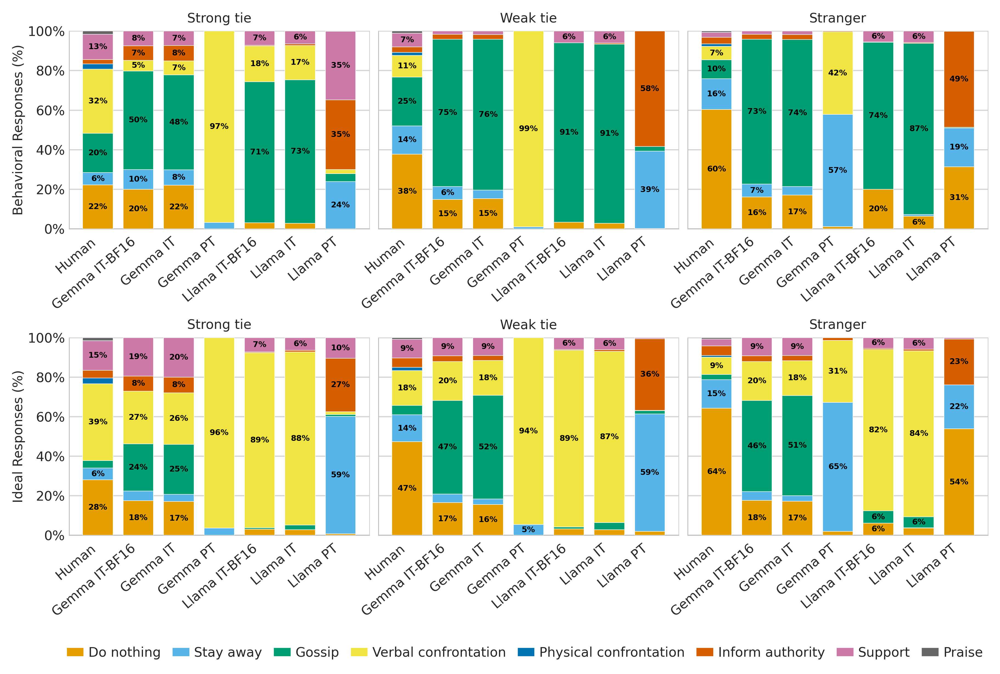

In [213]:
distances = ["Strong tie", "Weak tie", "Stranger"]
response_types = ["Would", "Should"]
model_order = [
    "human",
    "gemma_ft_bf16",
    "gemma_ft",
    "gemma_pt",
    "llama_ft_bf16",
    "llama_ft",
    "llama_pt",
]
all_actions = ["Do nothing", "Stay away", "Gossip", "Verbal confrontation", "Physical confrontation", "Inform authority", "Support", "Praise"]

model_labels = {
    "human": "Human",
    "gemma_ft": "Gemma IT",
    "gemma_ft_bf16": "Gemma IT-BF16",
    "llama_ft": "Llama IT",
    "llama_ft_bf16": "Llama IT-BF16",
    "gemma_pt": "Gemma PT",
    "llama_pt": "Llama PT",
}

fontsize = 23
YLABEL_FONTSIZE = fontsize
TICK_FONTSIZE = fontsize
TITLE_FONTSIZE = fontsize
LEGEND_TITLE_FONTSIZE = fontsize
LEGEND_LABEL_FONTSIZE = fontsize

action_colors = {
    "Do nothing": "#E69F00",
    "Stay away": "#56B4E9",
    "Gossip": "#009E73",
    "Verbal confrontation": "#F0E442",
    "Physical confrontation": "#0072B2",
    "Inform authority": "#D55E00",
    "Support": "#CC79A7",
    "Praise": "#666666",
}

x = np.arange(len(model_order))
bar_width = 0.75
fig, axes = plt.subplots(2, 3, figsize=(24, 16), sharey=True)

for row_idx, response_type in enumerate(response_types):
    counts_response = counts.loc[counts["response_type"] == response_type]

    for col_idx, dist in enumerate(distances):
        ax = axes[row_idx, col_idx]
        bottoms = np.zeros(len(model_order))

        for action in all_actions:
            vals = []
            for m in model_order:
                row = counts_response[(counts_response["label_type"] == m) & (counts_response["distance"] == dist) & (counts_response["value"] == action)]
                vals.append(row["percent"].values[0] / 100 if len(row) > 0 else 0)
            vals = np.array(vals)

            ax.bar(x, vals, bottom=bottoms, width=bar_width, color=action_colors[action], edgecolor="white", linewidth=0.8, label=action, zorder=3)

            # Annotate percentages >= 5%
            for i, (v, b) in enumerate(zip(vals, bottoms)):
                if v >= 0.05:
                    ax.text(x[i], b + v / 2, f"{v * 100:.0f}%", ha="center", va="center", fontsize=14, fontweight="bold", color="black", zorder=4)

            bottoms += vals

        ax.set_title(dist, fontsize=TITLE_FONTSIZE, pad=15)

        if col_idx == 0:
            ylabel = "Behavioral Responses (%)" if response_type == "Would" else "Ideal Responses (%)"
            ax.set_ylabel(ylabel, fontsize=YLABEL_FONTSIZE)

        ax.set_xticks(x)
        ax.set_xticklabels([model_labels.get(m, m) for m in model_order], rotation=40, ha="right", fontsize=TICK_FONTSIZE)
        ax.tick_params(axis="x", pad=8)

        ax.set_ylim(0, 1)
        ax.set_yticks(np.arange(0, 1.01, 0.2))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)

        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color("#bfbfbf")
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_color("#bfbfbf")
        ax.spines["bottom"].set_linewidth(1.5)
        ax.spines["top"].set_visible(True)
        ax.spines["top"].set_color("#cfcfcf")
        ax.spines["top"].set_linewidth(1.2)
        ax.spines["right"].set_visible(True)
        ax.spines["right"].set_color("#cfcfcf")
        ax.spines["right"].set_linewidth(1.2)

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
legend = fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.525, 0.0), ncol=len(all_actions), frameon=False, handlelength=3, handleheight=2)

# Vertically align color boxes with text
for handle in legend.legend_handles:
    handle.set_y(handle.get_y() + 5)

legend.get_title().set_fontsize(LEGEND_TITLE_FONTSIZE)
for text in legend.get_texts():
    text.set_fontsize(LEGEND_LABEL_FONTSIZE)

fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.subplots_adjust(wspace=0.03, hspace=0.55)
fig.savefig(os.path.join(figure_output_path, "base_it_comp.png"), dpi=300, bbox_inches="tight")
plt.show()

## Neutral Prompt Differences

In [214]:
df_neutral_exp = pd.read_csv(PROCESSED / 'neutral_prompt_exp.csv.gz')
df_neutral_exp = df_neutral_exp.rename(columns={
    'stimuli_id': 'ID',
    'rater_type': 'label_type',
    'friends_reaction_would': 'friends_reaction',
    'acquaintances_reaction_would': 'acquaintances_reaction',
    'strangers_reaction_would': 'strangers_reaction',
    })
df_neutral_exp

/tmp/ipykernel_936/3044970364.py:1: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  df_neutral_exp = pd.read_csv(folder_path+'neutral_prompt_exp.csv.gz')


,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,emotion,strength_value,moral_foundation,rot_agree,action_agree,human_id,gender,age,race,education
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Pride,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Shame,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
2,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Anger,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
3,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Embarrassment,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
4,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Anger,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192795,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_neutral,"Disgust, Embarrassment, Shame","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Anger,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
192796,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_neutral,"Disgust, Embarrassment, Shame","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Contempt,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
192797,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_neutral,"Disgust, Embarrassment, Shame","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Disgust,2,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
192798,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_neutral,"Disgust, Embarrassment, Shame","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Pride,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN


In [215]:
df_long, counts = make_long_counts(
    df_neutral_exp,
    action_map=ACTION_CANONICAL_MAP,
)
counts

,label_type,outcome_type,response_type,distance,value,count,percent
0,human,reaction,Would,Strong tie,Do nothing,580,22.196709
1,human,reaction,Would,Strong tie,Stay away,162,6.199770
2,human,reaction,Would,Strong tie,Gossip,519,19.862227
3,human,reaction,Would,Strong tie,Verbal confrontation,848,32.453119
4,human,reaction,Would,Strong tie,Physical confrontation,70,2.678913
...,...,...,...,...,...,...,...
411,gemma_neutral,emotion,Would,Stranger,Disgust,675,48.561151
412,gemma_neutral,emotion,Would,Stranger,Anger,543,39.064748
413,gemma_neutral,emotion,Would,Stranger,Pride,4,0.287770
414,gemma_neutral,emotion,Would,Stranger,Compassion,63,4.532374


In [216]:
emotion_tables = display_count_tables(
    counts,
    outcome_type="emotion",
)


  emotion — human — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,"1,069 (19.5%)",757 (14.1%),432 (9.9%),265 (6.8%),"2,523 (13.2%)"
Guilt,"1,191 (21.7%)",269 (5.0%),159 (3.6%),100 (2.6%),"1,719 (9.0%)"
Embarrassment,"1,086 (19.8%)","1,062 (19.7%)",716 (16.3%),465 (11.9%),"3,329 (17.4%)"
Contempt,411 (7.5%),640 (11.9%),750 (17.1%),740 (19.0%),"2,541 (13.3%)"
Disgust,518 (9.4%),"1,070 (19.9%)","1,111 (25.3%)","1,156 (29.7%)","3,855 (20.1%)"
Anger,532 (9.7%),827 (15.4%),624 (14.2%),627 (16.1%),"2,610 (13.6%)"
Pride,524 (9.5%),149 (2.8%),113 (2.6%),86 (2.2%),872 (4.6%)
Compassion,163 (3.0%),604 (11.2%),479 (10.9%),458 (11.8%),"1,704 (8.9%)"



  emotion — gpt_5.2 — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,340 (15.0%),216 (7.9%),0 (0.0%),0 (0.0%),556 (6.2%)
Guilt,517 (22.8%),20 (0.7%),0 (0.0%),0 (0.0%),537 (6.0%)
Embarrassment,332 (14.6%),519 (18.9%),187 (8.3%),16 (1.0%),"1,054 (11.8%)"
Contempt,106 (4.7%),122 (4.5%),648 (28.7%),493 (29.7%),"1,369 (15.3%)"
Disgust,50 (2.2%),332 (12.1%),449 (19.9%),467 (28.2%),"1,298 (14.5%)"
Anger,230 (10.1%),657 (24.0%),557 (24.7%),418 (25.2%),"1,862 (20.9%)"
Pride,147 (6.5%),53 (1.9%),6 (0.3%),2 (0.1%),208 (2.3%)
Compassion,49 (2.2%),455 (16.6%),178 (7.9%),163 (9.8%),845 (9.5%)
Other,499 (22.0%),367 (13.4%),232 (10.3%),99 (6.0%),"1,197 (13.4%)"



  emotion — gemma — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,448 (24.4%),166 (9.5%),5 (0.4%),5 (0.4%),624 (9.9%)
Guilt,506 (27.6%),26 (1.5%),2 (0.1%),2 (0.1%),536 (8.5%)
Embarrassment,297 (16.2%),99 (5.7%),114 (8.1%),103 (7.7%),613 (9.7%)
Contempt,19 (1.0%),3 (0.2%),7 (0.5%),10 (0.7%),39 (0.6%)
Disgust,268 (14.6%),571 (32.7%),596 (42.2%),610 (45.4%),"2,045 (32.3%)"
Anger,238 (13.0%),619 (35.5%),572 (40.5%),502 (37.4%),"1,931 (30.5%)"
Pride,9 (0.5%),8 (0.5%),3 (0.2%),3 (0.2%),23 (0.4%)
Compassion,50 (2.7%),234 (13.4%),97 (6.9%),94 (7.0%),475 (7.5%)
Other,0 (0.0%),18 (1.0%),15 (1.1%),15 (1.1%),48 (0.8%)



  emotion — gpt_5.2_neutral — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,341 (14.9%),318 (10.9%),1 (0.0%),0 (0.0%),660 (7.0%)
Guilt,477 (20.8%),41 (1.4%),0 (0.0%),0 (0.0%),518 (5.5%)
Embarrassment,291 (12.7%),539 (18.4%),250 (10.4%),31 (1.7%),"1,111 (11.7%)"
Contempt,131 (5.7%),131 (4.5%),694 (28.7%),557 (30.4%),"1,513 (16.0%)"
Disgust,70 (3.1%),391 (13.4%),523 (21.7%),538 (29.3%),"1,522 (16.1%)"
Anger,246 (10.7%),677 (23.1%),532 (22.0%),431 (23.5%),"1,886 (19.9%)"
Pride,129 (5.6%),41 (1.4%),7 (0.3%),3 (0.2%),180 (1.9%)
Compassion,40 (1.7%),406 (13.9%),165 (6.8%),164 (8.9%),775 (8.2%)
Other,567 (24.7%),381 (13.0%),243 (10.1%),111 (6.0%),"1,302 (13.8%)"



  emotion — gemma_neutral — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,607 (31.6%),198 (10.9%),16 (1.1%),16 (1.2%),837 (12.8%)
Guilt,637 (33.2%),37 (2.0%),1 (0.1%),1 (0.1%),676 (10.3%)
Embarrassment,204 (10.6%),62 (3.4%),63 (4.5%),46 (3.3%),375 (5.7%)
Contempt,40 (2.1%),9 (0.5%),9 (0.6%),11 (0.8%),69 (1.1%)
Disgust,233 (12.1%),634 (34.9%),631 (44.6%),675 (48.6%),"2,173 (33.2%)"
Anger,160 (8.3%),631 (34.7%),592 (41.9%),543 (39.1%),"1,926 (29.4%)"
Pride,18 (0.9%),8 (0.4%),4 (0.3%),4 (0.3%),34 (0.5%)
Compassion,20 (1.0%),192 (10.6%),65 (4.6%),63 (4.5%),340 (5.2%)
Other,1 (0.1%),48 (2.6%),33 (2.3%),31 (2.2%),113 (1.7%)


In [217]:
reaction_tables = display_count_tables(
    counts,
    outcome_type="reaction",
)


  reaction — human — Would


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,580 (22.2%),986 (37.7%),"1,576 (60.3%)","3,142 (40.1%)"
Stay away,162 (6.2%),374 (14.3%),407 (15.6%),943 (12.0%)
Gossip,519 (19.9%),646 (24.7%),251 (9.6%),"1,416 (18.1%)"
Verbal confrontation,848 (32.5%),287 (11.0%),175 (6.7%),"1,310 (16.7%)"
Physical confrontation,70 (2.7%),38 (1.5%),35 (1.3%),143 (1.8%)
Inform authority,58 (2.2%),73 (2.8%),86 (3.3%),217 (2.8%)
Support,334 (12.8%),182 (7.0%),65 (2.5%),581 (7.4%)
Praise,42 (1.6%),27 (1.0%),18 (0.7%),87 (1.1%)



  reaction — human — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,734 (28.1%),"1,236 (47.3%)","1,678 (64.2%)","3,648 (46.5%)"
Stay away,154 (5.9%),355 (13.6%),379 (14.5%),888 (11.3%)
Gossip,100 (3.8%),125 (4.8%),68 (2.6%),293 (3.7%)
Verbal confrontation,"1,016 (38.9%)",459 (17.6%),228 (8.7%),"1,703 (21.7%)"
Physical confrontation,74 (2.8%),45 (1.7%),23 (0.9%),142 (1.8%)
Inform authority,101 (3.9%),123 (4.7%),125 (4.8%),349 (4.5%)
Support,394 (15.1%),247 (9.5%),93 (3.6%),734 (9.4%)
Praise,40 (1.5%),23 (0.9%),19 (0.7%),82 (1.0%)



  reaction — gpt_5.2 — Would


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,20 (2.3%),72 (8.4%),589 (69.1%),681 (26.6%)
Stay away,0 (0.0%),28 (3.3%),115 (13.5%),143 (5.6%)
Gossip,34 (4.0%),707 (82.9%),4 (0.5%),745 (29.1%)
Verbal confrontation,626 (73.4%),7 (0.8%),45 (5.3%),678 (26.5%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,17 (2.0%),34 (4.0%),100 (11.7%),151 (5.9%)
Support,152 (17.8%),5 (0.6%),0 (0.0%),157 (6.1%)
Praise,4 (0.5%),0 (0.0%),0 (0.0%),4 (0.2%)


... (10 outputs left out)


  reaction — gemma_neutral — Would


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,170 (19.9%),61 (7.2%),68 (8.0%),299 (11.7%)
Stay away,49 (5.7%),15 (1.8%),16 (1.9%),80 (3.1%)
Gossip,312 (36.6%),734 (86.0%),726 (85.1%),"1,772 (69.2%)"
Verbal confrontation,196 (23.0%),1 (0.1%),1 (0.1%),198 (7.7%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,78 (9.1%),26 (3.0%),27 (3.2%),131 (5.1%)
Support,48 (5.6%),16 (1.9%),15 (1.8%),79 (3.1%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)



  reaction — gemma_neutral — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,80 (9.4%),79 (9.3%),84 (9.8%),243 (9.5%)
Stay away,19 (2.2%),13 (1.5%),14 (1.6%),46 (1.8%)
Gossip,136 (15.9%),490 (57.4%),486 (57.0%),"1,112 (43.5%)"
Verbal confrontation,293 (34.3%),111 (13.0%),111 (13.0%),515 (20.1%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,79 (9.3%),27 (3.2%),28 (3.3%),134 (5.2%)
Support,246 (28.8%),133 (15.6%),130 (15.2%),509 (19.9%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


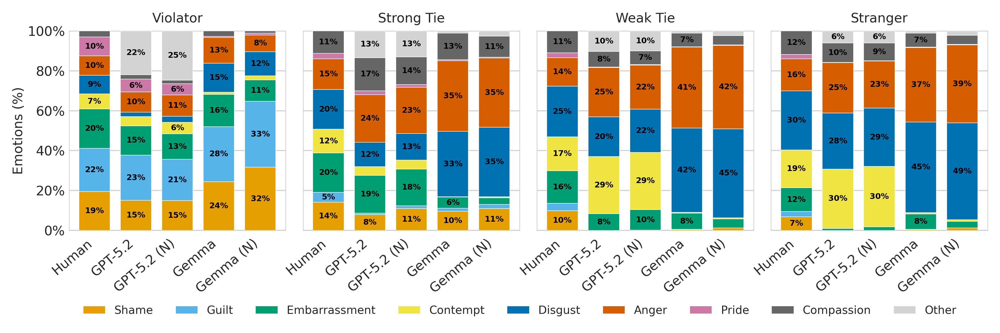

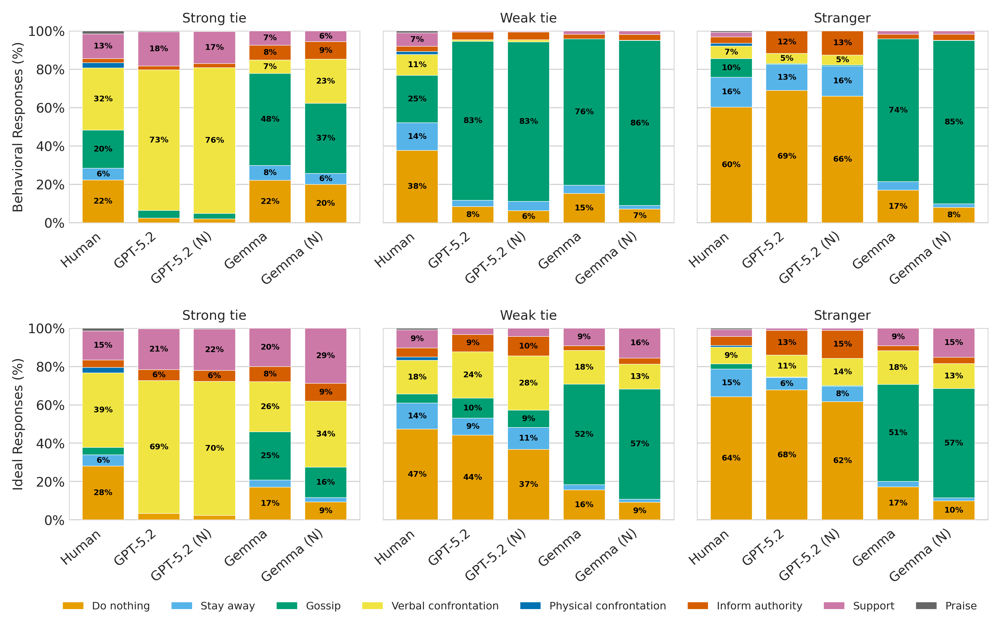

In [218]:
distances = ["Strong tie", "Weak tie", "Stranger"]
emotion_distances = ["Actor"] + distances
model_order = ["human", "gpt_5.2", "gpt_5.2_neutral", "gemma", "gemma_neutral"]

model_labels = {
    "human": "Human", "gpt_5.2": "GPT-5.2", "gpt_5.2_neutral": "GPT-5.2 (N)",
    "gemma": "Gemma", "gemma_neutral": "Gemma (N)",
}

all_actions = ["Do nothing", "Stay away", "Gossip", "Verbal confrontation", "Physical confrontation", "Inform authority", "Support", "Praise"]
all_emotions = ["Shame", "Guilt", "Embarrassment", "Contempt", "Disgust", "Anger", "Pride", "Compassion", "Other"]

action_colors = {
    "Do nothing": "#E69F00", "Stay away": "#56B4E9", "Gossip": "#009E73",
    "Verbal confrontation": "#F0E442", "Physical confrontation": "#0072B2",
    "Inform authority": "#D55E00", "Support": "#CC79A7", "Praise": "#666666",
}
emotion_colors = {
    "Shame": "#E69F00", "Guilt": "#56B4E9", "Embarrassment": "#009E73",
    "Contempt": "#F0E442", "Disgust": "#0072B2", "Anger": "#D55E00",
    "Pride": "#CC79A7", "Compassion": "#666666", "Other": "#D3D3D3",
}

fontsize = 23
YLABEL_FONTSIZE = fontsize
TICK_FONTSIZE = fontsize
TITLE_FONTSIZE = fontsize
LEGEND_LABEL_FONTSIZE = fontsize

x = np.arange(len(model_order))
bar_width = 0.75

# Helpers
def get_percentages(subset, category):
    vals = []
    for model in model_order:
        row = subset[(subset["label_type"] == model) & (subset["value"] == category)]
        vals.append(row["percent"].iloc[0] / 100 if not row.empty else 0)
    return np.array(vals, dtype=float)


def format_axis(ax, title, ylabel=None):
    ax.set_title(title, fontsize=TITLE_FONTSIZE, pad=15)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=YLABEL_FONTSIZE)

    ax.set_xticks(x)
    ax.set_xticklabels([model_labels.get(m, m) for m in model_order], rotation=40, ha="right", fontsize=TICK_FONTSIZE)
    ax.tick_params(axis="x", pad=8)
    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#cfcfcf")
        spine.set_linewidth(1.2)


def plot_stacked_bars(ax, subset, categories, colors):
    bottoms = np.zeros(len(model_order))

    for category in categories:
        vals = get_percentages(subset, category)
        ax.bar(x, vals, bottom=bottoms, width=bar_width, color=colors[category], edgecolor="white", linewidth=0.8, label=category, zorder=3)

        for i, (v, b) in enumerate(zip(vals, bottoms)):
            if v >= 0.05:
                ax.text(x[i], b + v / 2, f"{v * 100:.0f}%", ha="center", va="center", fontsize=14, fontweight="bold", color="black", zorder=4)

        bottoms += vals

# Emotion Plot
fig_emotions, axes_emotions = plt.subplots(1, 4, figsize=(24, 8), sharey=True)
emotion_counts = counts[(counts["outcome_type"] == "emotion") & (counts["response_type"] == "Would")]
emotion_titles = {"Actor": "Violator", "Strong tie": "Strong Tie", "Weak tie": "Weak Tie", "Stranger": "Stranger"}

for col_idx, dist in enumerate(emotion_distances):
    ax = axes_emotions[col_idx]
    subset = emotion_counts[emotion_counts["distance"] == dist]
    plot_stacked_bars(ax, subset, all_emotions, emotion_colors)
    format_axis(ax, title=emotion_titles[dist], ylabel="Emotions (%)" if col_idx == 0 else None)

emotion_handles = [Patch(facecolor=emotion_colors[e], label=e) for e in all_emotions]
fig_emotions.legend(handles=emotion_handles, loc="lower center", bbox_to_anchor=(0.52, 0.025), ncol=len(all_emotions), frameon=False, fontsize=LEGEND_LABEL_FONTSIZE*0.85)

fig_emotions.tight_layout(rect=[0, 0.10, 1, 1])
fig_emotions.subplots_adjust(wspace=0.08)
fig_emotions.savefig(os.path.join(figure_output_path, "emotion_neutral.png"), dpi=300, bbox_inches="tight")
plt.show()

# Action Plot
fig_actions, axes_actions = plt.subplots(2, 3, figsize=(24, 16), sharey=True)
panel_types = [("reaction", "Would"), ("reaction", "Should")]
row_labels = ["Behavioral Responses (%)", "Ideal Responses (%)"]

for row_idx, (outcome_type, response_type) in enumerate(panel_types):
    counts_response = counts[(counts["outcome_type"] == outcome_type) & (counts["response_type"] == response_type)]

    for col_idx, dist in enumerate(distances):
        ax = axes_actions[row_idx, col_idx]
        subset = counts_response[counts_response["distance"] == dist]
        plot_stacked_bars(ax, subset, all_actions, action_colors)
        format_axis(ax, title=dist, ylabel=row_labels[row_idx] if col_idx == 0 else None)

action_handles = [Patch(facecolor=action_colors[a], label=a) for a in all_actions]
fig_actions.legend(handles=action_handles, loc="lower center", bbox_to_anchor=(0.52, 0.065), ncol=len(all_actions), frameon=False, fontsize=LEGEND_LABEL_FONTSIZE*0.8)
fig_actions.tight_layout(rect=[0, 0.11, 1, 1])
fig_actions.subplots_adjust(wspace=0.08, hspace=0.55)
fig_actions.savefig(os.path.join(figure_output_path, "actions_neutral.png"), dpi=300, bbox_inches="tight")
plt.show()

## LLM as an Advisor

In [219]:
df_gpt_advice = pd.read_csv(PROCESSED / 'gpt_advice_neutral_exp.csv.gz')
df_gpt_advice = df_gpt_advice.rename(columns={
    'stimuli_id': 'ID',
    'rater_type': 'label_type',
    'friends_reaction_would': 'friends_reaction',
    'acquaintances_reaction_would': 'acquaintances_reaction',
    'strangers_reaction_would': 'strangers_reaction',
    })
df_gpt_advice

,ID,stimuli,actor,actor_gender,label_type,friends_reaction_should,acquaintances_reaction_should,strangers_reaction_should,human_id
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Do nothing,Do nothing,Do nothing,R_7JCKEF65rh5eA8Y
1,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Stay away,Stay away,Stay away,R_7o9lY3vQcqsE4pP
2,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Verbal confrontation,Do nothing,Do nothing,R_3R48rDclzghStqN
3,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Gossip,Do nothing,Do nothing,R_1bHJcpADL6ZNNEJ
4,1,William did not tell someone's girlfriend that he cheated on her.,William,male,human,Support,Support,Support,R_6r37TI1xGGUVeaA
...,...,...,...,...,...,...,...,...,...
5167,449,Jennifer reads things in a British accent even though she's Canadian.,NaN,female,gpt_5.2_advice,Verbal confrontation,Do nothing,Do nothing,NaN
5168,449,Jennifer reads things in a British accent even though she's Canadian.,NaN,male,gpt_5.2_advice,Verbal confrontation,Do nothing,Do nothing,NaN
5169,450,Elizabeth touched a passed-out guy inappropriately.,NaN,male,gpt_5.2_advice,Inform authority,Inform authority,Inform authority,NaN
5170,450,Elizabeth touched a passed-out guy inappropriately.,NaN,female,gpt_5.2_advice,Inform authority,Inform authority,Inform authority,NaN


In [220]:
df_long, counts = make_long_counts(
    df_gpt_advice,
    action_map=ACTION_CANONICAL_MAP,
)
counts

,label_type,outcome_type,response_type,distance,value,count,percent
0,human,reaction,Should,Strong tie,Do nothing,734,28.090318
1,human,reaction,Should,Strong tie,Stay away,154,5.893609
2,human,reaction,Should,Strong tie,Gossip,100,3.827019
3,human,reaction,Should,Strong tie,Verbal confrontation,1016,38.882511
4,human,reaction,Should,Strong tie,Physical confrontation,74,2.831994
...,...,...,...,...,...,...,...
91,gpt_5.2_advice,reaction,Should,Stranger,Verbal confrontation,195,22.860492
92,gpt_5.2_advice,reaction,Should,Stranger,Physical confrontation,0,0.000000
93,gpt_5.2_advice,reaction,Should,Stranger,Inform authority,126,14.771395
94,gpt_5.2_advice,reaction,Should,Stranger,Support,124,14.536928


In [221]:
reaction_tables = display_count_tables(
    counts,
    outcome_type="reaction",
)


  reaction — human — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,734 (28.1%),"1,236 (47.3%)","1,678 (64.2%)","3,648 (46.5%)"
Stay away,154 (5.9%),355 (13.6%),379 (14.5%),888 (11.3%)
Gossip,100 (3.8%),125 (4.8%),68 (2.6%),293 (3.7%)
Verbal confrontation,"1,016 (38.9%)",459 (17.6%),228 (8.7%),"1,703 (21.7%)"
Physical confrontation,74 (2.8%),45 (1.7%),23 (0.9%),142 (1.8%)
Inform authority,101 (3.9%),123 (4.7%),125 (4.8%),349 (4.5%)
Support,394 (15.1%),247 (9.5%),93 (3.6%),734 (9.4%)
Praise,40 (1.5%),23 (0.9%),19 (0.7%),82 (1.0%)



  reaction — gpt_5.2 — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,28 (3.3%),377 (44.2%),578 (67.8%),983 (38.4%)
Stay away,0 (0.0%),76 (8.9%),55 (6.4%),131 (5.1%)
Gossip,0 (0.0%),89 (10.4%),2 (0.2%),91 (3.6%)
Verbal confrontation,592 (69.4%),206 (24.2%),98 (11.5%),896 (35.0%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,49 (5.7%),77 (9.0%),110 (12.9%),236 (9.2%)
Support,181 (21.2%),27 (3.2%),10 (1.2%),218 (8.5%)
Praise,3 (0.4%),1 (0.1%),0 (0.0%),4 (0.2%)



  reaction — gpt_5.2_neutral — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,20 (2.3%),314 (36.8%),526 (61.7%),860 (33.6%)
Stay away,0 (0.0%),97 (11.4%),68 (8.0%),165 (6.4%)
Gossip,0 (0.0%),77 (9.0%),4 (0.5%),81 (3.2%)
Verbal confrontation,596 (69.9%),241 (28.3%),121 (14.2%),958 (37.4%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,49 (5.7%),87 (10.2%),124 (14.5%),260 (10.2%)
Support,184 (21.6%),36 (4.2%),10 (1.2%),230 (9.0%)
Praise,4 (0.5%),1 (0.1%),0 (0.0%),5 (0.2%)



  reaction — gpt_5.2_advice — Should


,Strong tie,Weak tie,Stranger,Overall
Value,,,,
Do nothing,45 (5.3%),208 (24.4%),183 (21.5%),436 (17.0%)
Stay away,22 (2.6%),71 (8.3%),198 (23.2%),291 (11.4%)
Gossip,6 (0.7%),10 (1.2%),27 (3.2%),43 (1.7%)
Verbal confrontation,465 (54.5%),285 (33.4%),195 (22.9%),945 (36.9%)
Physical confrontation,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Inform authority,42 (4.9%),89 (10.4%),126 (14.8%),257 (10.0%)
Support,273 (32.0%),190 (22.3%),124 (14.5%),587 (22.9%)
Praise,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


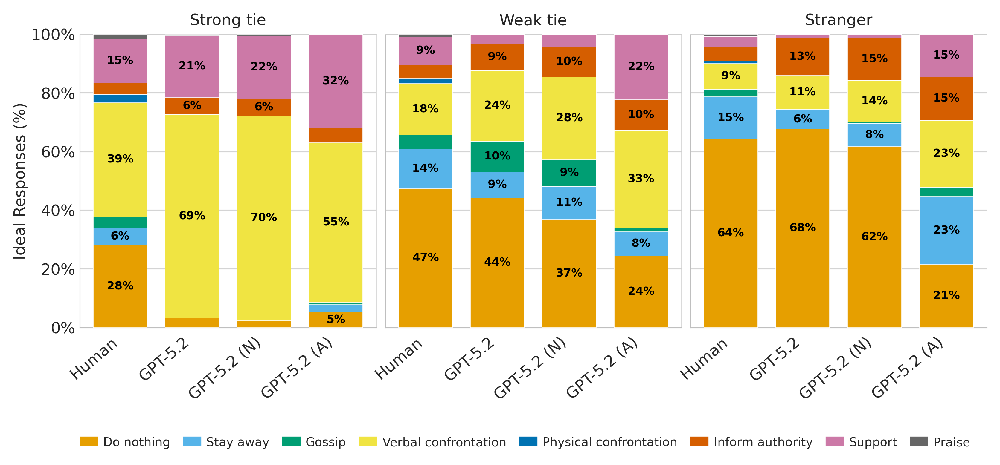

In [222]:
distances = ["Strong tie", "Weak tie", "Stranger"]
preferred_response_order = ["Would", "Should"]
preferred_model_order = ["human", "gpt_5.2", "gpt_5.2_neutral", "gpt_5.2_advice"]
all_actions = ["Do nothing", "Stay away", "Gossip", "Verbal confrontation", "Physical confrontation", "Inform authority", "Support", "Praise"]

model_labels = {
    "human": "Human", "gpt_5.2": "GPT-5.2", "gpt_5.2_neutral": "GPT-5.2 (N)",
    "gpt_5.2_advice": "GPT-5.2 (A)"
}

action_colors = {
    "Do nothing": "#E69F00", "Stay away": "#56B4E9", "Gossip": "#009E73",
    "Verbal confrontation": "#F0E442", "Physical confrontation": "#0072B2",
    "Inform authority": "#D55E00", "Support": "#CC79A7", "Praise": "#666666",
}

fontsize = 25
YLABEL_FONTSIZE = fontsize
TICK_FONTSIZE = fontsize
TITLE_FONTSIZE = fontsize
LEGEND_TITLE_FONTSIZE = fontsize
LEGEND_LABEL_FONTSIZE = fontsize

# Automatically detect available response types and models
plot_counts = counts[counts["outcome_type"] == "reaction"].copy() if "outcome_type" in counts.columns else counts.copy()
response_types = [r for r in preferred_response_order if r in plot_counts["response_type"].unique()]
response_types += [r for r in plot_counts["response_type"].dropna().unique() if r not in response_types]

model_order = [m for m in preferred_model_order if m in plot_counts["label_type"].unique()]
model_order += [m for m in plot_counts["label_type"].dropna().unique() if m not in model_order]

x = np.arange(len(model_order))
bar_width = 0.75

fig, axes = plt.subplots(len(response_types), len(distances), figsize=(22, 10), sharey=True, squeeze=False)

for row_idx, response_type in enumerate(response_types):
    counts_response = plot_counts[plot_counts["response_type"] == response_type]

    for col_idx, dist in enumerate(distances):
        ax = axes[row_idx, col_idx]
        bottoms = np.zeros(len(model_order))

        for action in all_actions:
            vals = []
            for m in model_order:
                row = counts_response[(counts_response["label_type"] == m) & (counts_response["distance"] == dist) & (counts_response["value"] == action)]
                vals.append(row["percent"].values[0] / 100 if len(row) > 0 else 0)
            vals = np.array(vals)

            ax.bar(x, vals, bottom=bottoms, width=bar_width, color=action_colors[action], edgecolor="white", linewidth=0.8, label=action, zorder=3)

            for i, (v, b) in enumerate(zip(vals, bottoms)):
                if v >= 0.05:
                    ax.text(x[i], b + v / 2, f"{v * 100:.0f}%", ha="center", va="center", fontsize=18, fontweight="bold", color="black", zorder=4)

            bottoms += vals

        ax.set_title(dist, fontsize=TITLE_FONTSIZE, pad=15)

        if col_idx == 0:
            ylabel = "Behavioral Responses (%)" if response_type == "Would" else "Ideal Responses (%)" if response_type == "Should" else f"{response_type} Responses (%)"
            ax.set_ylabel(ylabel, fontsize=YLABEL_FONTSIZE)

        ax.set_xticks(x)
        ax.set_xticklabels([model_labels.get(m, m) for m in model_order], rotation=40, ha="right", fontsize=TICK_FONTSIZE)
        ax.tick_params(axis="x", pad=8)
        ax.set_ylim(0, 1)
        ax.set_yticks(np.arange(0, 1.01, 0.2))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)
        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color("#bfbfbf")
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_color("#bfbfbf")
        ax.spines["bottom"].set_linewidth(1.5)
        ax.spines["top"].set_visible(True)
        ax.spines["top"].set_color("#cfcfcf")
        ax.spines["top"].set_linewidth(1.2)
        ax.spines["right"].set_visible(True)
        ax.spines["right"].set_color("#cfcfcf")
        ax.spines["right"].set_linewidth(1.2)

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
legend = fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.525, 0.0), ncol=len(all_actions), frameon=False, handlelength=3, handleheight=2)

for handle in legend.legend_handles:
    handle.set_y(handle.get_y() + 5)

legend.get_title().set_fontsize(LEGEND_TITLE_FONTSIZE)
for text in legend.get_texts():
    text.set_fontsize(LEGEND_LABEL_FONTSIZE*0.78)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.subplots_adjust(wspace=0.03, hspace=0.55)
fig.savefig(os.path.join(figure_output_path, "action_advise.png"), dpi=300, bbox_inches="tight")
plt.show()


## Quantization Experiment

In [223]:
df_quant = pd.read_csv(PROCESSED / 'NormReact_quantization.csv.gz')
df_quant = df_quant.rename(columns={
    'stimuli_id': 'ID',
    'rater_type': 'label_type',
    'friends_reaction_would': 'friends_reaction',
    'acquaintances_reaction_would': 'acquaintances_reaction',
    'strangers_reaction_would': 'strangers_reaction',
    })
df_quant

/tmp/ipykernel_936/2145826225.py:1: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  df_quant = pd.read_csv(folder_path+'NormReact_quantization.csv.gz')


,ID,stimuli,actor,actor_gender,label_type,actor_emotions,friends_emotions,friends_reaction,friends_reaction_should,acquaintances_emotions,...,emotion,strength_value,moral_foundation,rot_agree,action_agree,human_id,gender,age,race,education
0,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Pride,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
1,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Shame,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
2,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Anger,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
3,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Embarrassment,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
4,1,Maria did not tell someone's girlfriend that he cheated on her.,Maria,female,human,Guilt,Compassion,Support,Do nothing,Compassion,...,Anger,0,care-harm,4,4,R_7JCKEF65rh5eA8Y,Male,62.0,White or Caucasian,"Some college, but no degree"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192795,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_bf16,"Disgust, Embarrassment","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Anger,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
192796,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_bf16,"Disgust, Embarrassment","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Contempt,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
192797,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_bf16,"Disgust, Embarrassment","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Disgust,2,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN
192798,451,David smells his socks and underwear every time he takes them off and finds it extremely satisfying.,David,male,gemma_bf16,"Disgust, Embarrassment","Disgust, Embarrassment",Do nothing,Do nothing,"Disgust, Embarrassment",...,Pride,0,sancticity-degradation,2,2,NaN,NaN,NaN,NaN,NaN


### Emotion & Action Distribution

In [224]:
df_long, counts = make_long_counts(
    df_quant,
    action_map=ACTION_CANONICAL_MAP,
)
counts

,label_type,outcome_type,response_type,distance,value,count,percent
0,human,reaction,Would,Strong tie,Do nothing,580,22.196709
1,human,reaction,Would,Strong tie,Stay away,162,6.199770
2,human,reaction,Would,Strong tie,Gossip,519,19.862227
3,human,reaction,Would,Strong tie,Verbal confrontation,848,32.453119
4,human,reaction,Would,Strong tie,Physical confrontation,70,2.678913
...,...,...,...,...,...,...,...
411,gemma_bf16,emotion,Would,Stranger,Disgust,608,45.204461
412,gemma_bf16,emotion,Would,Stranger,Anger,499,37.100372
413,gemma_bf16,emotion,Would,Stranger,Pride,3,0.223048
414,gemma_bf16,emotion,Would,Stranger,Compassion,98,7.286245


In [225]:
emotion_tables = display_count_tables(
    counts,
    outcome_type="emotion",
)
emotion_tables


  emotion — human — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,"1,069 (19.5%)",757 (14.1%),432 (9.9%),265 (6.8%),"2,523 (13.2%)"
Guilt,"1,191 (21.7%)",269 (5.0%),159 (3.6%),100 (2.6%),"1,719 (9.0%)"
Embarrassment,"1,086 (19.8%)","1,062 (19.7%)",716 (16.3%),465 (11.9%),"3,329 (17.4%)"
Contempt,411 (7.5%),640 (11.9%),750 (17.1%),740 (19.0%),"2,541 (13.3%)"
Disgust,518 (9.4%),"1,070 (19.9%)","1,111 (25.3%)","1,156 (29.7%)","3,855 (20.1%)"
Anger,532 (9.7%),827 (15.4%),624 (14.2%),627 (16.1%),"2,610 (13.6%)"
Pride,524 (9.5%),149 (2.8%),113 (2.6%),86 (2.2%),872 (4.6%)
Compassion,163 (3.0%),604 (11.2%),479 (10.9%),458 (11.8%),"1,704 (8.9%)"



  emotion — llama — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,446 (27.8%),99 (4.5%),25 (1.7%),16 (1.4%),586 (9.2%)
Guilt,492 (30.7%),26 (1.2%),4 (0.3%),1 (0.1%),523 (8.2%)
Embarrassment,177 (11.0%),128 (5.9%),37 (2.6%),13 (1.1%),355 (5.6%)
Contempt,82 (5.1%),681 (31.2%),586 (40.7%),480 (42.0%),"1,829 (28.7%)"
Disgust,191 (11.9%),725 (33.3%),520 (36.1%),503 (44.0%),"1,939 (30.4%)"
Anger,119 (7.4%),443 (20.3%),212 (14.7%),80 (7.0%),854 (13.4%)
Pride,50 (3.1%),14 (0.6%),13 (0.9%),11 (1.0%),88 (1.4%)
Compassion,47 (2.9%),55 (2.5%),42 (2.9%),40 (3.5%),184 (2.9%)
Other,1 (0.1%),9 (0.4%),0 (0.0%),0 (0.0%),10 (0.2%)



  emotion — llama_bf16 — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,422 (27.0%),8 (0.4%),3 (0.2%),1 (0.1%),434 (7.2%)
Guilt,448 (28.7%),2 (0.1%),1 (0.1%),0 (0.0%),451 (7.5%)
Embarrassment,140 (9.0%),56 (2.8%),23 (1.7%),3 (0.3%),222 (3.7%)
Contempt,92 (5.9%),707 (35.5%),525 (38.9%),394 (35.1%),"1,718 (28.5%)"
Disgust,222 (14.2%),724 (36.3%),583 (43.2%),588 (52.4%),"2,117 (35.1%)"
Anger,119 (7.6%),401 (20.1%),149 (11.0%),85 (7.6%),754 (12.5%)
Pride,68 (4.4%),15 (0.8%),14 (1.0%),10 (0.9%),107 (1.8%)
Compassion,43 (2.8%),55 (2.8%),41 (3.0%),39 (3.5%),178 (3.0%)
Other,7 (0.4%),24 (1.2%),10 (0.7%),2 (0.2%),43 (0.7%)



  emotion — gemma — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,448 (24.4%),166 (9.5%),5 (0.4%),5 (0.4%),624 (9.9%)
Guilt,506 (27.6%),26 (1.5%),2 (0.1%),2 (0.1%),536 (8.5%)
Embarrassment,297 (16.2%),99 (5.7%),114 (8.1%),103 (7.7%),613 (9.7%)
Contempt,19 (1.0%),3 (0.2%),7 (0.5%),10 (0.7%),39 (0.6%)
Disgust,268 (14.6%),571 (32.7%),596 (42.2%),610 (45.4%),"2,045 (32.3%)"
Anger,238 (13.0%),619 (35.5%),572 (40.5%),502 (37.4%),"1,931 (30.5%)"
Pride,9 (0.5%),8 (0.5%),3 (0.2%),3 (0.2%),23 (0.4%)
Compassion,50 (2.7%),234 (13.4%),97 (6.9%),94 (7.0%),475 (7.5%)
Other,0 (0.0%),18 (1.0%),15 (1.1%),15 (1.1%),48 (0.8%)



  emotion — gemma_bf16 — Would


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,453 (24.5%),176 (9.9%),6 (0.4%),5 (0.4%),640 (10.0%)
Guilt,511 (27.7%),30 (1.7%),2 (0.1%),2 (0.1%),545 (8.5%)
Embarrassment,298 (16.1%),110 (6.2%),120 (8.5%),108 (8.0%),636 (10.0%)
Contempt,19 (1.0%),4 (0.2%),7 (0.5%),12 (0.9%),42 (0.7%)
Disgust,268 (14.5%),575 (32.3%),592 (41.8%),608 (45.2%),"2,043 (32.0%)"
Anger,240 (13.0%),617 (34.7%),572 (40.4%),499 (37.1%),"1,928 (30.2%)"
Pride,9 (0.5%),7 (0.4%),3 (0.2%),3 (0.2%),22 (0.3%)
Compassion,50 (2.7%),242 (13.6%),103 (7.3%),98 (7.3%),493 (7.7%)
Other,0 (0.0%),17 (1.0%),10 (0.7%),10 (0.7%),37 (0.6%)


,Actor,Strong tie,Weak tie,Stranger,Overall
Value,,,,,
Shame,453 (24.5%),176 (9.9%),6 (0.4%),5 (0.4%),640 (10.0%)
Guilt,511 (27.7%),30 (1.7%),2 (0.1%),2 (0.1%),545 (8.5%)
Embarrassment,298 (16.1%),110 (6.2%),120 (8.5%),108 (8.0%),636 (10.0%)
Contempt,19 (1.0%),4 (0.2%),7 (0.5%),12 (0.9%),42 (0.7%)
Disgust,268 (14.5%),575 (32.3%),592 (41.8%),608 (45.2%),"2,043 (32.0%)"
Anger,240 (13.0%),617 (34.7%),572 (40.4%),499 (37.1%),"1,928 (30.2%)"
Pride,9 (0.5%),7 (0.4%),3 (0.2%),3 (0.2%),22 (0.3%)
Compassion,50 (2.7%),242 (13.6%),103 (7.3%),98 (7.3%),493 (7.7%)
Other,0 (0.0%),17 (1.0%),10 (0.7%),10 (0.7%),37 (0.6%)


In [226]:
counts['label_type'].unique()

array(['human', 'llama', 'llama_bf16', 'gemma', 'gemma_bf16'],
      dtype=object)

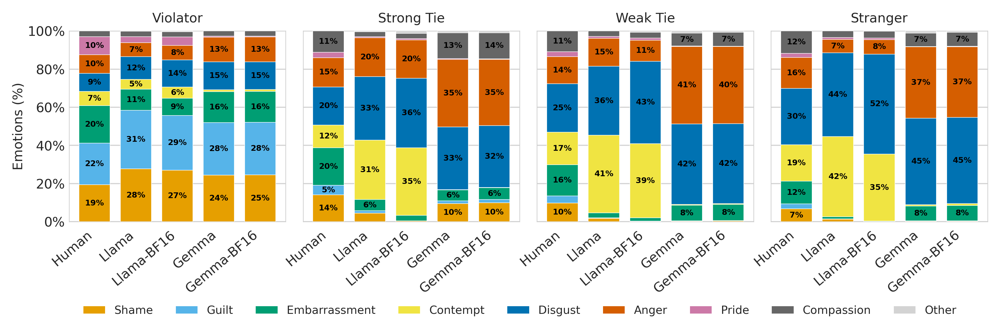

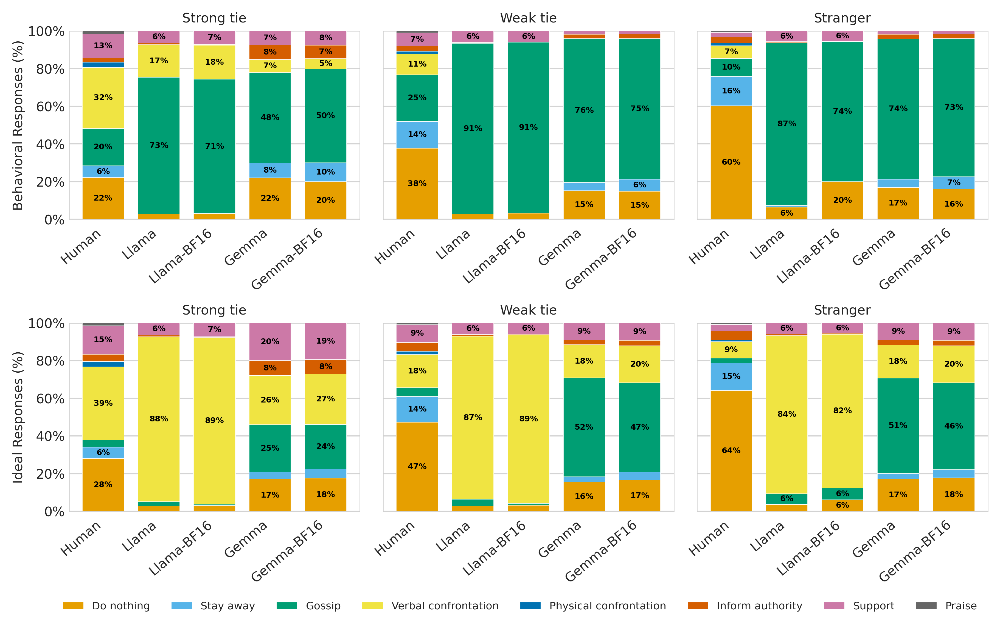

In [227]:
distances = ["Strong tie", "Weak tie", "Stranger"]
emotion_distances = ["Actor"] + distances
model_order = ["human", "llama", "llama_bf16", "gemma", "gemma_bf16"]

model_labels = {
    "human": "Human",
    "gemma": "Gemma",
    "gemma_bf16": "Gemma-BF16",
    "llama": "Llama",
    "llama_bf16": "Llama-BF16",
}

all_actions = ["Do nothing", "Stay away", "Gossip", "Verbal confrontation", "Physical confrontation", "Inform authority", "Support", "Praise"]
all_emotions = ["Shame", "Guilt", "Embarrassment", "Contempt", "Disgust", "Anger", "Pride", "Compassion", "Other"]

action_colors = {
    "Do nothing": "#E69F00", "Stay away": "#56B4E9", "Gossip": "#009E73",
    "Verbal confrontation": "#F0E442", "Physical confrontation": "#0072B2",
    "Inform authority": "#D55E00", "Support": "#CC79A7", "Praise": "#666666",
}
emotion_colors = {
    "Shame": "#E69F00", "Guilt": "#56B4E9", "Embarrassment": "#009E73",
    "Contempt": "#F0E442", "Disgust": "#0072B2", "Anger": "#D55E00",
    "Pride": "#CC79A7", "Compassion": "#666666", "Other": "#D3D3D3",
}

fontsize = 23
YLABEL_FONTSIZE = fontsize
TICK_FONTSIZE = fontsize
TITLE_FONTSIZE = fontsize
LEGEND_LABEL_FONTSIZE = fontsize

x = np.arange(len(model_order))
bar_width = 0.75

# Helpers
def get_percentages(subset, category):
    vals = []
    for model in model_order:
        row = subset[(subset["label_type"] == model) & (subset["value"] == category)]
        vals.append(row["percent"].iloc[0] / 100 if not row.empty else 0)
    return np.array(vals, dtype=float)


def format_axis(ax, title, ylabel=None):
    ax.set_title(title, fontsize=TITLE_FONTSIZE, pad=15)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=YLABEL_FONTSIZE)

    ax.set_xticks(x)
    ax.set_xticklabels([model_labels.get(m, m) for m in model_order], rotation=40, ha="right", fontsize=TICK_FONTSIZE)
    ax.tick_params(axis="x", pad=8)
    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=TICK_FONTSIZE)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="-", linewidth=2, alpha=0.9, color="#d0d0d0")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#cfcfcf")
        spine.set_linewidth(1.2)


def plot_stacked_bars(ax, subset, categories, colors):
    bottoms = np.zeros(len(model_order))

    for category in categories:
        vals = get_percentages(subset, category)
        ax.bar(x, vals, bottom=bottoms, width=bar_width, color=colors[category], edgecolor="white", linewidth=0.8, label=category, zorder=3)

        for i, (v, b) in enumerate(zip(vals, bottoms)):
            if v >= 0.05:
                ax.text(x[i], b + v / 2, f"{v * 100:.0f}%", ha="center", va="center", fontsize=14, fontweight="bold", color="black", zorder=4)

        bottoms += vals

# Emotion Plot
fig_emotions, axes_emotions = plt.subplots(1, 4, figsize=(24, 8), sharey=True)
emotion_counts = counts[(counts["outcome_type"] == "emotion") & (counts["response_type"] == "Would")]
emotion_titles = {"Actor": "Violator", "Strong tie": "Strong Tie", "Weak tie": "Weak Tie", "Stranger": "Stranger"}

for col_idx, dist in enumerate(emotion_distances):
    ax = axes_emotions[col_idx]
    subset = emotion_counts[emotion_counts["distance"] == dist]
    plot_stacked_bars(ax, subset, all_emotions, emotion_colors)
    format_axis(ax, title=emotion_titles[dist], ylabel="Emotions (%)" if col_idx == 0 else None)

emotion_handles = [Patch(facecolor=emotion_colors[e], label=e) for e in all_emotions]
fig_emotions.legend(handles=emotion_handles, loc="lower center", bbox_to_anchor=(0.52, 0.025), ncol=len(all_emotions), frameon=False, fontsize=LEGEND_LABEL_FONTSIZE*0.85)

fig_emotions.tight_layout(rect=[0, 0.10, 1, 1])
fig_emotions.subplots_adjust(wspace=0.08)
fig_emotions.savefig(os.path.join(figure_output_path, "quant_emotions.png"), dpi=300, bbox_inches="tight")
plt.show()

# Action Plot
fig_actions, axes_actions = plt.subplots(2, 3, figsize=(24, 16), sharey=True)
panel_types = [("reaction", "Would"), ("reaction", "Should")]
row_labels = ["Behavioral Responses (%)", "Ideal Responses (%)"]

for row_idx, (outcome_type, response_type) in enumerate(panel_types):
    counts_response = counts[(counts["outcome_type"] == outcome_type) & (counts["response_type"] == response_type)]

    for col_idx, dist in enumerate(distances):
        ax = axes_actions[row_idx, col_idx]
        subset = counts_response[counts_response["distance"] == dist]
        plot_stacked_bars(ax, subset, all_actions, action_colors)
        format_axis(ax, title=dist, ylabel=row_labels[row_idx] if col_idx == 0 else None)

action_handles = [Patch(facecolor=action_colors[a], label=a) for a in all_actions]
fig_actions.legend(handles=action_handles, loc="lower center", bbox_to_anchor=(0.52, 0.065), ncol=len(all_actions), frameon=False, fontsize=LEGEND_LABEL_FONTSIZE*0.8)
fig_actions.tight_layout(rect=[0, 0.11, 1, 1])
fig_actions.subplots_adjust(wspace=0.08, hspace=0.55)
fig_actions.savefig(os.path.join(figure_output_path, "quant_actions.png"), dpi=300, bbox_inches="tight")
plt.show()

### LLM Evaluation

In [228]:
df_quant["rater_group"] = np.select(
    [
        df_quant["label_type"] == "human",
        df_quant["label_type"].isin(["gpt_5.2", "claude", "gemini"]),
        df_quant["label_type"].isin(["gpt_oss", "llama", "gemma"]),
    ],
    [
        "human",
        "closed-source",
        "open-source",
    ],
    default="unknown"
)

df = df_quant.copy()

# 1. Humans: one response per human_id × ID
df_human_quant = df[df["label_type"] == "human"].drop_duplicates(["ID", "human_id", "actor_gender"])

# 2. LLMs: one response per model × ID
df_llm_quant = df[df["label_type"] != "human"].drop_duplicates(["ID", "label_type", "actor_gender"])

# 3. Combine
df_clean_quant = pd.concat([df_human_quant, df_llm_quant], ignore_index=True)

df_clean_quant["self_emotion_list"] = (
    df_clean_quant["actor_emotions"]
    .apply(split_emotions)
    .apply(lambda lst: sorted(set(lst)))
)

df_clean_quant["other_emotion_list"] = df_clean_quant.apply(
    lambda row: [
        split_emotions(row[col]) for col in emotion_cols_other
    ],
    axis=1
)

df_benchmark = df_clean_quant.loc[(~df_clean_quant['ID'].isin(ids_one_raters))].copy()

#### Actions

In [229]:
df = binarize_actions(df_benchmark)
df_agg, df_human, df_llm, IDs = agg_human_llm_ids(df)
results_df = llm_action_eval(df_human, df_agg, df_llm, IDs, cases=cases_all, leave_one_out=True, bootstrap_sample=False)
results_df

,label_type,case,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,llama_bf16,friend_would,0.657568,0.970696,0.784024,0.669683,0.615370,0.704445,0.013993,0.016492,...,0.000500,0.001999,0.750378,0.817545,0.301349,0.957521,0.626697,0.714932,0.653673,1.000000
1,llama_bf16,stranger_would,0.278090,0.951923,0.430435,0.407240,0.235124,0.325967,0.008496,0.025487,...,0.415792,1.000000,0.375869,0.486489,0.032984,0.131934,0.361991,0.452489,0.000500,0.001999
2,llama_bf16,stranger_should,0.221945,0.988889,0.362525,0.291855,0.182045,0.262021,0.033983,0.067966,...,0.034983,0.139930,0.307684,0.414073,0.119940,0.239880,0.251131,0.334842,0.000500,0.001999
3,llama_bf16,friend_should,0.570720,0.978723,0.721003,0.597285,0.522990,0.619650,0.000500,0.001999,...,0.000500,0.001999,0.681508,0.759763,0.307346,0.913543,0.552036,0.642534,0.001499,0.003998
4,llama_bf16,acq_should,0.358722,0.986486,0.526126,0.404977,0.311751,0.404940,0.001499,0.004498,...,0.065967,0.197901,0.474057,0.573914,0.041479,0.082959,0.359729,0.452489,0.000500,0.001999
5,llama_bf16,acq_would,0.528256,0.964126,0.682540,0.547511,0.479988,0.577396,0.001999,0.005997,...,0.549725,1.000000,0.639186,0.723085,0.054473,0.116942,0.500000,0.592760,0.003998,0.010495
6,llama,acq_would,0.525672,0.964126,0.680380,0.542986,0.476883,0.573900,0.002999,0.005997,...,0.624188,1.000000,0.637251,0.720969,0.038981,0.116942,0.495475,0.590498,0.003498,0.010495
7,llama,friend_would,0.653563,0.974359,0.782353,0.665158,0.610702,0.701235,0.002999,0.011994,...,0.000500,0.001999,0.749227,0.815453,0.442779,0.957521,0.622172,0.708201,0.398801,1.000000
8,llama,stranger_would,0.254364,0.980769,0.403960,0.319005,0.214833,0.298294,0.003998,0.015992,...,0.172914,0.691654,0.352685,0.457470,0.037981,0.131934,0.276018,0.361991,0.000500,0.001999
9,llama,friend_should,0.567568,0.982979,0.719626,0.592760,0.518516,0.616346,0.000500,0.001999,...,0.000500,0.001999,0.679289,0.757584,0.228386,0.913543,0.547511,0.638009,0.001000,0.003998


Would | Stranger | precision: LLM avg = 0.265
Would | Weak Tie | precision: LLM avg = 0.541
Would | Strong Tie | precision: LLM avg = 0.676
Would | Stranger | recall: LLM avg = 0.964
Would | Weak Tie | recall: LLM avg = 0.960
Would | Strong Tie | recall: LLM avg = 0.918
Would | Stranger | f1: LLM avg = 0.415
Would | Weak Tie | f1: LLM avg = 0.692
Would | Strong Tie | f1: LLM avg = 0.777
Should | Stranger | precision: LLM avg = 0.229
Should | Weak Tie | precision: LLM avg = 0.373
Should | Strong Tie | precision: LLM avg = 0.609
Should | Stranger | recall: LLM avg = 0.967
Should | Weak Tie | recall: LLM avg = 0.968
Should | Strong Tie | recall: LLM avg = 0.919
Should | Stranger | f1: LLM avg = 0.370
Should | Weak Tie | f1: LLM avg = 0.538
Should | Strong Tie | f1: LLM avg = 0.730


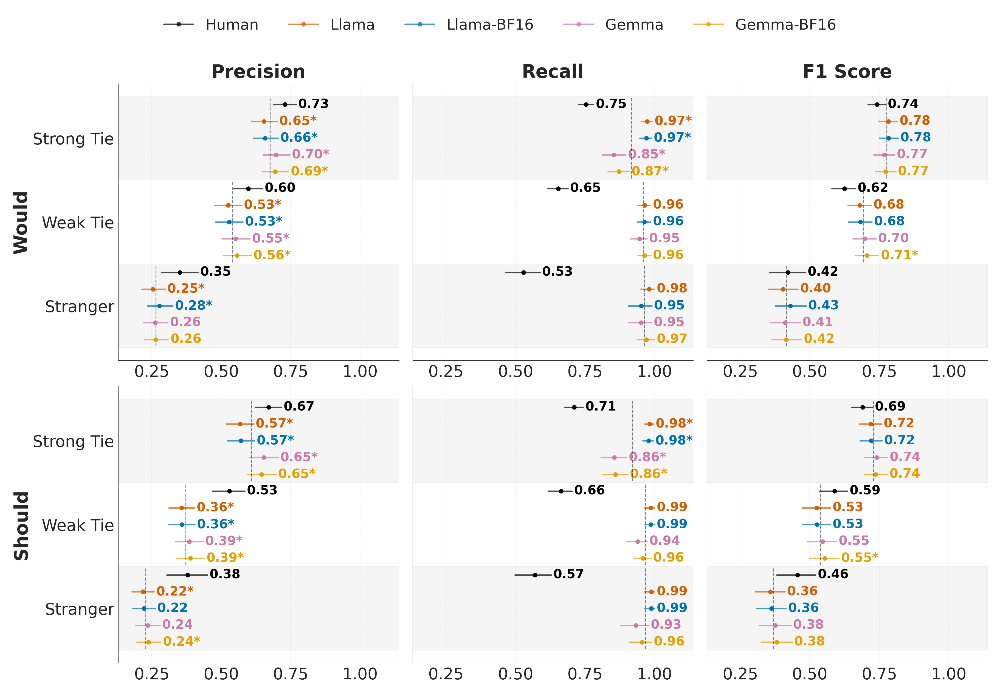

In [230]:
FONT_SIZE = 28
FIG_WIDTH = 36
FIG_HEIGHT = 16

metrics = ["precision", "recall", "f1"]
metric_titles = ["Precision", "Recall", "F1 Score"]

case_groups = {
    "Would": ["stranger_would", "acq_would", "friend_would"],
    "Should": ["stranger_should", "acq_should", "friend_should"],
}
cat_labels = ["Stranger", "Weak Tie", "Strong Tie"]

model_order = ["human", "llama", "llama_bf16", "gemma", "gemma_bf16"]
model_labels = ["Human", "Llama", "Llama-BF16", "Gemma", "Gemma-BF16"]

all_order = ["human", "llama", "llama_bf16", "gemma", "gemma_bf16"]
all_labels = ["Human", "Llama", "Llama-BF16", "Gemma", "Gemma-BF16"]

colors = {
    "gemma_bf16": "#E69F00",
    "llama_bf16": "#0072B2",
    "llama": "#D55E00",
    "gemma": "#CC79A7",
    "human": "#000000",
}

n_all = len(all_order)
n_cats = len(cat_labels)

fig, axes = plt.subplots(2, 3, figsize=(24, FIG_HEIGHT), sharey='row')

for row_idx, (group_name, case_list) in enumerate(case_groups.items()):
    for col_idx, (metric, title) in enumerate(zip(metrics, metric_titles)):
        ax = axes[row_idx, col_idx]

        for cat_idx, (case_name, cat_label) in enumerate(zip(case_list, cat_labels)):
            if cat_idx % 2 == 0:
                ax.axhspan(
                    cat_idx * n_all - 0.5,
                    cat_idx * n_all + n_all - 0.5,
                    color='grey', alpha=0.08
                )

            llm_vals = []

            for model_idx, (model, model_label) in enumerate(zip(all_order[::-1], all_labels[::-1])):
                row = results_df[
                    (results_df["label_type"] == model) &
                    (results_df["case"] == case_name)
                ]

                if len(row) == 0:
                    continue

                val = row[metric].values[0]
                lo = row[f"{metric}_ci_lo"].values[0]
                hi = row[f"{metric}_ci_hi"].values[0]

                if model != "human":
                    llm_vals.append(val)

                y_pos = cat_idx * n_all + model_idx

                ax.plot(
                    [lo, hi], [y_pos, y_pos],
                    color=colors[model], linewidth=2.5, alpha=0.7,
                    solid_capstyle='round'
                )
                ax.plot(
                    val, y_pos, 'o',
                    color=colors[model], markersize=7, zorder=5,
                    label=model_label if (row_idx == 0 and col_idx == 0 and cat_idx == 0) else None
                )

                stars = sig_stars(row[f"{metric}_p"].values[0])
                label_text = f"{val:.2f}{stars}"
                ax.text(
                    hi + 0.008, y_pos, label_text,
                    va='center', ha='left',
                    fontsize=FONT_SIZE - 6, color=colors[model], fontweight='bold'
                )

            # LLM average line (excluding human)
            if llm_vals:
                avg_val = np.mean(llm_vals)
                print(f"{group_name} | {cat_label} | {metric}: LLM avg = {avg_val:.3f}")
                y_top = cat_idx * n_all - 0.4
                y_bot = cat_idx * n_all + n_all - 0.6
                ax.plot(
                    [avg_val, avg_val], [y_top, y_bot],
                    color='black', linewidth=1.5, linestyle='--', alpha=0.5, zorder=4
                )

        ytick_positions = [cat_idx * n_all + (n_all - 1) / 2 for cat_idx in range(n_cats)]
        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(cat_labels, fontsize=FONT_SIZE)

        ax.set_xlim(0.13, 1.14)
        ax.tick_params(axis='x', labelsize=FONT_SIZE)
        ax.grid(axis='x', alpha=0.25, linestyle='--', linewidth=0.8)
        ax.set_axisbelow(True)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(0.5)
        ax.spines['bottom'].set_linewidth(0.5)

        if row_idx == 0:
            ax.set_title(title, fontsize=FONT_SIZE+4, fontweight='bold', pad=10)

    axes[row_idx, 0].set_ylabel(group_name, fontsize=FONT_SIZE+4, fontweight='bold')

legend_handles = []
for model, model_label in zip(all_order, all_labels):
    legend_handles.append(
        Line2D([0], [0], color=colors[model], marker='o', markersize=7,
               linewidth=2.5, alpha=0.7, label=model_label)
    )

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=n_all,
    fontsize=FONT_SIZE-2,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(os.path.join(figure_output_path, "quant_action_model_perf.png"), dpi=300, bbox_inches="tight")
plt.show()

#### Emotions

In [231]:
df = binary_emotions(df_benchmark)
df_agg, merged = merged_human_llm(df)
results_df = llm_eval(df_agg, merged, leave_one_out=True, bootstrap_sample=False)
results_df

,label_type,category,precision,recall,f1,accuracy,precision_ci_lo,precision_ci_hi,precision_p_raw,precision_p,...,recall_p_raw,recall_p,f1_ci_lo,f1_ci_hi,f1_p_raw,f1_p,accuracy_ci_lo,accuracy_ci_hi,accuracy_p_raw,accuracy_p
0,gemma,actor,0.715877,0.908127,0.800623,0.710407,0.667582,0.763085,0.003498,0.006997,...,0.000500,0.001999,0.766296,0.833596,0.145427,0.581709,0.667421,0.753394,0.922539,1.000000
1,gemma_bf16,actor,0.706371,0.901060,0.791925,0.696833,0.656753,0.752113,0.000500,0.001999,...,0.000500,0.001999,0.755480,0.825117,0.745627,1.000000,0.651584,0.739819,0.234883,0.939530
2,llama,actor,0.749196,0.823322,0.784512,0.710407,0.698356,0.796979,0.208396,0.208396,...,0.016992,0.016992,0.745222,0.820604,0.560720,1.000000,0.667364,0.753394,0.934033,1.000000
3,llama_bf16,actor,0.780919,0.780919,0.780919,0.719457,0.729924,0.828674,0.000500,0.001999,...,0.000500,0.001999,0.740072,0.817570,0.392804,1.000000,0.676471,0.760181,0.452774,1.000000
4,gemma,friend,0.680672,0.916981,0.781350,0.692308,0.632470,0.727273,0.001000,0.001999,...,0.010995,0.032984,0.744106,0.815504,0.271864,0.543728,0.651584,0.735294,0.024488,0.048976
5,gemma_bf16,friend,0.681564,0.920755,0.783307,0.694570,0.633053,0.728304,0.000500,0.001999,...,0.020490,0.040980,0.747508,0.817076,0.144428,0.433283,0.653846,0.737557,0.009995,0.039980
6,llama,friend,0.632754,0.962264,0.763473,0.642534,0.583960,0.680003,0.000500,0.001999,...,0.050475,0.050475,0.725269,0.798221,0.094453,0.377811,0.597285,0.685520,0.011494,0.039980
7,llama_bf16,friend,0.637717,0.969811,0.769461,0.651584,0.589670,0.684729,0.001499,0.001999,...,0.005497,0.021989,0.731406,0.803481,0.466767,0.543728,0.606335,0.694570,0.070965,0.070965
8,gemma,acq,0.681690,0.902985,0.776886,0.685520,0.632764,0.729345,0.000500,0.001999,...,0.003498,0.006997,0.740123,0.812800,0.362819,1.000000,0.642534,0.728507,0.032984,0.083958
9,gemma_bf16,acq,0.684659,0.899254,0.777419,0.687783,0.636090,0.733138,0.000500,0.001999,...,0.001999,0.005997,0.738913,0.812202,0.338831,1.000000,0.644796,0.730769,0.020990,0.083958


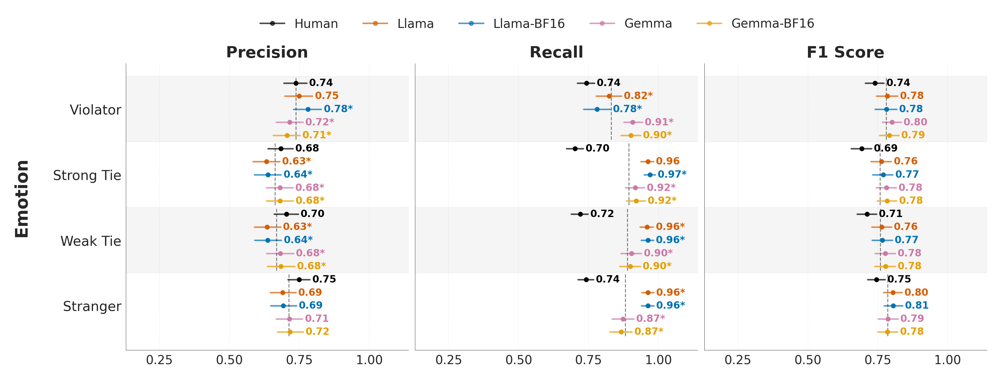

In [232]:
FONT_SIZE = 24
FIG_WIDTH = 22
FIG_HEIGHT = 8

metrics = ["precision", "recall", "f1"]
metric_titles = ["Precision", "Recall", "F1 Score"]
categories = ["actor", "friend", "acq", "stranger"]
cat_labels = ["Violator", "Strong Tie", "Weak Tie", "Stranger"]

model_order = ["human", "llama", "llama_bf16", "gemma", "gemma_bf16"]
model_labels = ["Human", "Llama", "Llama-BF16", "Gemma", "Gemma-BF16"]

all_order = ["human", "llama", "llama_bf16", "gemma", "gemma_bf16"]
model_labels = ["Human", "Llama", "Llama-BF16", "Gemma", "Gemma-BF16"]

colors = {
    "gemma_bf16": "#E69F00",
    "llama_bf16": "#0072B2",
    "llama": "#D55E00",
    "gemma": "#CC79A7",
    "human": "#000000",
}

fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, FIG_HEIGHT), sharey=True)

n_all = len(all_order)
n_cats = len(categories)

for ax_idx, (metric, title) in enumerate(zip(metrics, metric_titles)):
    ax = axes[ax_idx]

    for cat_idx, (cat, cat_label) in enumerate(zip(categories, cat_labels)):
        if cat_idx % 2 == 0:
            ax.axhspan(
                cat_idx * n_all - 0.5,
                cat_idx * n_all + n_all - 0.5,
                color='grey', alpha=0.08
            )

        for model_idx, (model, model_label) in enumerate(zip(all_order, model_labels)):
            row = results_df[
                (results_df["label_type"] == model) &
                (results_df["category"] == cat)
            ]

            val = row[metric].values[0]
            lo = row[f"{metric}_ci_lo"].values[0]
            hi = row[f"{metric}_ci_hi"].values[0]

            y_pos = cat_idx * n_all + model_idx

            ax.plot(
                [lo, hi], [y_pos, y_pos],
                color=colors[model], linewidth=2.5, alpha=0.7,
                solid_capstyle='round'
            )
            ax.plot(
                val, y_pos, 'o',
                color=colors[model], markersize=7, zorder=5,
                label=model_label if (ax_idx == 0 and cat_idx == 0) else None
            )
            stars = sig_stars(row[f"{metric}_p"].values[0])
            label_text = f"{val:.2f}{stars}"
            ax.text(
                hi + 0.008, y_pos, label_text,
                va='center', ha='left',
                fontsize=FONT_SIZE - 8, color=colors[model], fontweight='bold'
            )

        # LLM average dashed line (excluding human)
        cat_vals = []
        for model in model_order:
            row = results_df[
                (results_df["label_type"] == model) &
                (results_df["category"] == cat)
            ]
            cat_vals.append(row[metric].values[0])

        avg_val = np.mean(cat_vals)
        y_top = cat_idx * n_all - 0.4
        y_bot = cat_idx * n_all + n_all - 0.6

        ax.plot(
            [avg_val, avg_val], [y_top, y_bot],
            color='black', linewidth=1.5, linestyle='--', alpha=0.5, zorder=4
        )

    ytick_positions = [cat_idx * n_all + (n_all - 1) / 2 for cat_idx in range(n_cats)]
    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(cat_labels, fontsize=FONT_SIZE - 2)
    ax.invert_yaxis()

    ax.set_xlim(0.13, 1.14)
    ax.set_xticks(np.arange(0.25, 1.01, 0.25))
    ax.set_title(title, fontsize=FONT_SIZE + 2, fontweight='bold', pad=10)
    ax.tick_params(axis='x', labelsize=FONT_SIZE - 4)
    ax.grid(axis='x', alpha=0.25, linestyle='--', linewidth=0.8)
    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)

legend_handles = []
for model, model_label in zip(all_order, model_labels):
    legend_handles.append(
        Line2D([0], [0], color=colors[model], marker='o', markersize=7,
               linewidth=2.5, alpha=0.7, label=model_label)
    )

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.53, 1.04),
    ncol=n_all,
    fontsize=FONT_SIZE - 4,
    frameon=False
)

fig.supylabel("Emotion", fontsize=FONT_SIZE+4, fontweight='bold', x=-0.01)

plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(os.path.join(figure_output_path, "quant_em_model_perf.png"), dpi=300, bbox_inches="tight")
plt.show()

### Emotion Intensity

In [233]:
df_human_int = df_quant.loc[df_quant['label_type'] == 'human']
df_gemma_llama = {}

for label in df_quant.loc[df_quant['label_type'] != 'human']['label_type'].unique():
    df_gemma_llama[label] = df_quant[df_quant["label_type"] == label].copy()

In [234]:
datasets = {
    "Human": df_human_int,
    "Llama": df_gemma_llama["llama"],
    "Llama-BF16": df_gemma_llama["llama_bf16"],
    "Gemma": df_gemma_llama["gemma"],
    "Gemma-BF16": df_gemma_llama["gemma_bf16"]
}

ordered_emotions = [
    "Shame", "Guilt", "Embarrassment",
    "Contempt", "Disgust", "Anger",
    "Pride", "Compassion"
]

emotion_types = ["emotion_actor", "emotion_friend", "emotion_acquaintance", "emotion_stranger"]

bins_no_zero = [0.5, 1.5, 2.5, 3.5, 4.5]

# -----------------------------
rows = []

for emotion in ordered_emotions:
    for emotion_type in emotion_types:
        row = {"Emotion": emotion, "Level": emotion_type}

        for label, df in datasets.items():
            subset = df.loc[
                (df["emotion"] == emotion) &
                (df["emotion_type"] == emotion_type),
                "strength_value"
            ]

            subset_nz = subset[subset > 0]
            if len(subset_nz) > 0:
                counts_nz, _ = np.histogram(subset_nz, bins=bins_no_zero)
                probs_nz = counts_nz / counts_nz.sum()
                H = entropy(probs_nz, base=2)
            else:
                H = np.nan

            row[label] = round(H, 3)

        rows.append(row)

df_entropy = pd.DataFrame(rows)

# Clean up level names
level_map = {
    "emotion_actor": "Violator",
    "emotion_friend": "Strong Tie",
    "emotion_acquaintance": "Weak Tie",
    "emotion_stranger": "Stranger"
}
df_entropy["Level"] = df_entropy["Level"].map(level_map)
df_entropy

,Emotion,Level,Human,Llama,Llama-BF16,Gemma,Gemma-BF16
0,Shame,Violator,1.947,0.639,0.729,1.019,1.020
1,Shame,Strong Tie,1.953,0.903,1.406,0.964,0.959
2,Shame,Weak Tie,1.967,1.535,0.918,0.000,0.000
3,Shame,Stranger,1.875,1.406,0.000,0.000,0.000
4,Guilt,Violator,1.963,0.770,0.814,0.889,0.878
5,Guilt,Strong Tie,1.960,0.773,0.000,0.961,0.987
6,Guilt,Weak Tie,1.955,0.000,0.000,0.000,0.000
7,Guilt,Stranger,1.955,0.000,NaN,0.000,0.000
8,Embarrassment,Violator,1.952,0.989,1.002,0.622,0.595
9,Embarrassment,Strong Tie,1.971,1.110,0.863,0.783,0.805


In [235]:
models = ["Llama", "Llama-BF16", "Gemma", "Gemma-BF16"]

# Compute absolute distance from human entropy
for model in models:
    df_entropy[f"dist_{model}"] = (df_entropy[model] - df_entropy["Human"]).abs()

# Summary: mean absolute distance from human entropy
print("Mean |H_model - H_human| by model:")
for model in models:
    mean_dist = df_entropy[f"dist_{model}"].mean()
    se_dist = df_entropy[f"dist_{model}"].sem()
    print(f"  {model}: {mean_dist:.4f} ± {se_dist:.4f}")

# Paired Wilcoxon tests: Human entropy > Model entropy
print("\nWilcoxon signed-rank tests (Human > Model):")
for model in models:
    mask = df_entropy[["Human", model]].notna().all(axis=1)
    h = df_entropy.loc[mask, "Human"]
    m = df_entropy.loc[mask, model]

    stat, p = wilcoxon(h, m, alternative="greater")

    print(f"  {model}: stat={stat:.2f}, p={p:.6f}, N={mask.sum()}")
    print(f"    Mean entropy — Human: {h.mean():.3f}, {model}: {m.mean():.3f}")

Mean |H_model - H_human| by model:
  Llama: 1.0398 ± 0.0736
  Llama-BF16: 1.1133 ± 0.0706
  Gemma: 1.1289 ± 0.0781
  Gemma-BF16: 1.1086 ± 0.0788

Wilcoxon signed-rank tests (Human > Model):
  Llama: stat=528.00, p=0.000000, N=32
    Mean entropy — Human: 1.916, Llama: 0.876
  Llama-BF16: stat=496.00, p=0.000000, N=31
    Mean entropy — Human: 1.914, Llama-BF16: 0.801
  Gemma: stat=528.00, p=0.000000, N=32
    Mean entropy — Human: 1.916, Gemma: 0.787
  Gemma-BF16: stat=528.00, p=0.000000, N=32
    Mean entropy — Human: 1.916, Gemma-BF16: 0.807


In [236]:
pairs = [("Llama", "Llama-BF16"), ("Gemma", "Gemma-BF16")]

for model1, model2 in pairs:
    col1, col2 = f"dist_{model1}", f"dist_{model2}"
    mask = df_entropy[[col1, col2]].notna().all(axis=1)

    d1 = df_entropy.loc[mask, col1]
    d2 = df_entropy.loc[mask, col2]
    diff = d1 - d2

    stat, p_val = wilcoxon(d1, d2, alternative="two-sided")

    print(f"Wilcoxon ({model1} vs {model2}, two-sided): stat={stat:.2f}, "
          f"p={p_val:.4f}, N={mask.sum()}, non-zero diffs={(diff != 0).sum()}, "
          f"median diff={diff.median():.3f}")

Wilcoxon (Llama vs Llama-BF16, two-sided): stat=179.00, p=0.2711, N=31, non-zero diffs=30, median diff=-0.038
Wilcoxon (Gemma vs Gemma-BF16, two-sided): stat=122.00, p=0.4237, N=32, non-zero diffs=24, median diff=0.000


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)
